# 1. Importing Necessary Libraries

In [312]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')


# ============================================================
# 1.1 CONFIGURING THE ENVIRONMENT
# ============================================================

# 1.1.1 Pandas Display Settings

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)


# 1.1.2 Matplotlib Configuration

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 12


# 1.1.3 Seaborn Configuration

sns.set_theme(style='whitegrid', palette='Set2')


# ============================================================
# 1.2 VERIFYING LIBRARY IMPORTS
# ============================================================

print("=" * 55)
print("SUPPLY CHAIN ANALYTICS PROJECT")
print("=" * 55)

print("\nAll necessary libraries imported successfully!")

print("\nLIBRARY VERSIONS:")
print("-" * 35)

print("Pandas Version     :", pd.__version__)
print("NumPy Version      :", np.__version__)
print("Matplotlib Version :", plt.matplotlib.__version__)
print("Seaborn Version    :", sns.__version__)

print("\n" + "=" * 55)
print("ENVIRONMENT CONFIGURED SUCCESSFULLY!")
print("=" * 55)

SUPPLY CHAIN ANALYTICS PROJECT

All necessary libraries imported successfully!

LIBRARY VERSIONS:
-----------------------------------
Pandas Version     : 2.2.3
NumPy Version      : 2.4.6
Matplotlib Version : 3.10.0
Seaborn Version    : 0.13.2

ENVIRONMENT CONFIGURED SUCCESSFULLY!


# 2. Uploading the Dataset Zip File

In [228]:
from google.colab import files

uploaded = files.upload()

import zipfile
import os

ZIP_FILE = '/content/Supply_Chain_Datasets.zip'

with zipfile.ZipFile(ZIP_FILE, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("All datasets extracted successfully!")

Saving Supply_Chain_Datasets.zip to Supply_Chain_Datasets (5).zip
All datasets extracted successfully!


## 2.1. Importing Necessary Datasets

In [229]:
# ============================================================
# 2.1 IMPORTING NECESSARY DATASETS
# ============================================================

# 2.1.1 Importing the required library

import os
import pandas as pd
import numpy as np

# 2.1.2 Defining the dataset directory

DATASET_PATH = '/content/Supply_Chain_Datasets/'

# Checking whether the dataset folder exists

if os.path.exists(DATASET_PATH):
    print("Dataset folder found successfully!\n")
else:
    raise FileNotFoundError("Dataset folder not found. Please upload and extract the ZIP file.")

# Loading datasets from the dataset directory

def _load_dataset(base_names):
    files = os.listdir(DATASET_PATH)
    for base in base_names:
        for ext in ('.csv', '.xlsx', '.xls', '.parquet'):
            target = f"{base}{ext}".lower()
            for fname in files:
                if fname.lower() == target:
                    fpath = os.path.join(DATASET_PATH, fname)
                    if ext == '.csv':
                        return pd.read_csv(fpath)
                    if ext in ('.xlsx', '.xls'):
                        return pd.read_excel(fpath)
                    if ext == '.parquet':
                        return pd.read_parquet(fpath)
        for fname in files:
            stem, ext = os.path.splitext(fname)
            if base.lower() in stem.lower() and ext.lower() in ('.csv', '.xlsx', '.xls', '.parquet'):
                fpath = os.path.join(DATASET_PATH, fname)
                if ext.lower() == '.csv':
                    return pd.read_csv(fpath)
                if ext.lower() in ('.xlsx', '.xls'):
                    return pd.read_excel(fpath)
                if ext.lower() == '.parquet':
                    return pd.read_parquet(fpath)
    raise FileNotFoundError(f"Could not find dataset matching {base_names} in {DATASET_PATH}. Available files: {files}")

customer_df = _load_dataset(['customer_master', 'customers', 'customer'])
product_df = _load_dataset(['product_master', 'products', 'product'])
supplier_df = _load_dataset(['supplier_master', 'suppliers', 'supplier'])
sales_df = _load_dataset(['sales_orders', 'sales', 'sales_order'])
procurement_df = _load_dataset(['procurement_orders', 'procurement', 'purchase_orders', 'procurement_order'])
dictionary_df = _load_dataset(['data_dictionary', 'dictionary', 'data dictionary'])


# ============================================================
# 2.1.9 CREATING A STRUCTURED DATASET SUMMARY TABLE
# ============================================================

# Creating a dictionary of all datasets

datasets = {
    'Customer Master': customer_df,
    'Product Master': product_df,
    'Supplier Master': supplier_df,
    'Sales Orders': sales_df,
    'Procurement Orders': procurement_df,
    'Data Dictionary': dictionary_df
}


# Creating the dataset summary

dataset_summary = pd.DataFrame({
    'Dataset Name': list(datasets.keys()),

    'Number of Rows': [
        df.shape[0] for df in datasets.values()
    ],

    'Number of Columns': [
        df.shape[1] for df in datasets.values()
    ],

    'Total Missing Values': [
        df.isnull().sum().sum() for df in datasets.values()
    ]
})


# Adding Serial Number

dataset_summary.insert(
    0, 'SL.NO', range(1, len(dataset_summary) + 1)
)


# ============================================================
# 2.1.10 STYLING THE DATASET SUMMARY TABLE
# ============================================================

styled_table = (
    dataset_summary.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format numerical values
    .format({
        'SL.NO': '{:.0f}',
        'Number of Rows': '{:,}',
        'Number of Columns': '{:,}',
        'Total Missing Values': '{:,}'
    })

    # Table styling
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 25px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })

    # Header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1F4E78'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 25px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('text-align', 'center'),
                ('padding', '12px 25px')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1F4E78'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('SUPPLY CHAIN ANALYTICS - DATASET SUMMARY')
)

# Display the final structured table
display(styled_table)

Dataset folder found successfully!



SL.NO,Dataset Name,Number of Rows,Number of Columns,Total Missing Values
1,Customer Master,500,8,0
2,Product Master,200,10,200
3,Supplier Master,100,7,21
4,Sales Orders,"20,000",20,0
5,Procurement Orders,"2,000",9,0
6,Data Dictionary,54,4,0


# 3. Visualising the Dataset

## 3.1. Dataset Overview

DATASET OVERVIEW


SL.NO,Dataset,Total Records,Total Columns
1,Customer Master,500,8
2,Product Master,200,10
3,Supplier Master,100,7
4,Sales Orders,"20,000",20
5,Procurement Orders,"2,000",9
6,Data Dictionary,54,4


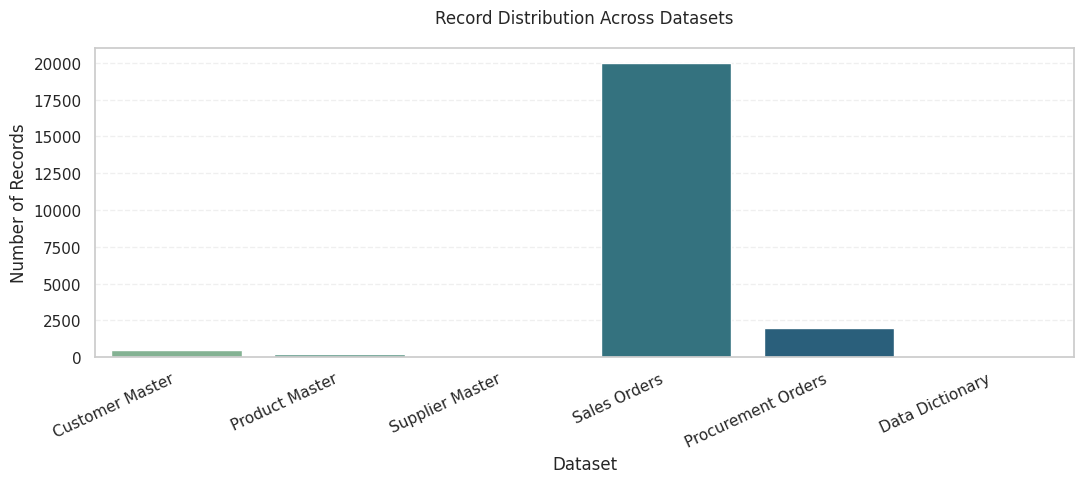

In [230]:
# ============================================================
# 3.1 DATASET OVERVIEW
# ============================================================

dataset_overview = pd.DataFrame({
    'Dataset': list(datasets.keys()),
    'Total Records': [df.shape[0] for df in datasets.values()],
    'Total Columns': [df.shape[1] for df in datasets.values()]
})

print("DATASET OVERVIEW")

# Format dataset overview table professionally
dataset_overview_display = dataset_overview.copy()
dataset_overview_display.insert(0, 'SL.NO', range(1, len(dataset_overview_display) + 1))

styled_dataset_overview = (
    dataset_overview_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total Records': '{:,}',
        'Total Columns': '{:,}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Dataset'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Dataset Record and Column Overview')
)

display(styled_dataset_overview)


# Visualize dataset record counts

plt.figure(figsize=(11, 5))

sns.barplot(
    data=dataset_overview,
    x='Dataset',
    y='Total Records',
    hue='Dataset',
    palette='crest',
    legend=False
)

plt.title('Record Distribution Across Datasets', pad=18)
plt.xlabel('Dataset')
plt.ylabel('Number of Records')
plt.xticks(rotation=25, ha='right')

plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

## 3.2. Missing Value Analysis

MISSING VALUES BY DATASET


SL.NO,Dataset,Missing Values
1,Customer Master,0
2,Product Master,200
3,Supplier Master,21
4,Sales Orders,0
5,Procurement Orders,0
6,Data Dictionary,0


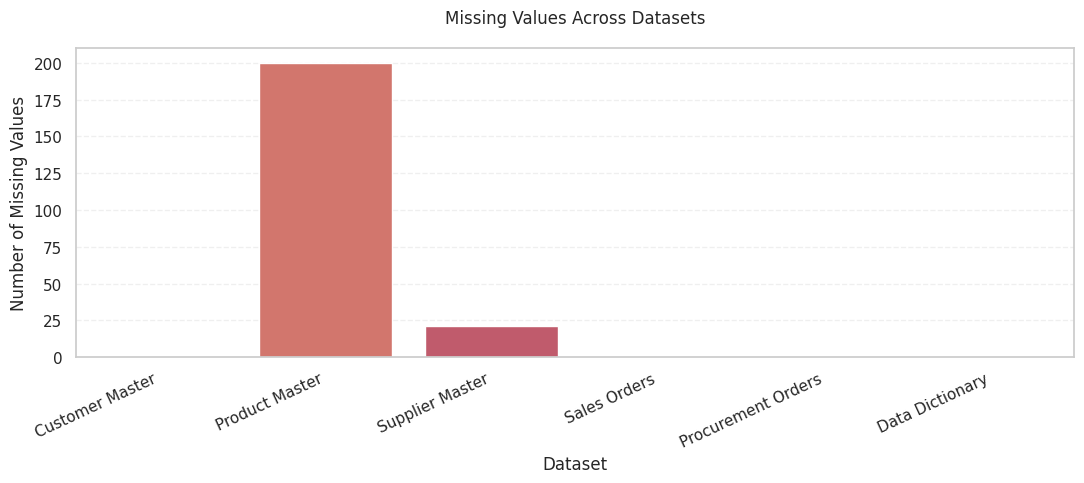

In [231]:
# ============================================================
# 3.2 MISSING VALUES BY DATASET
# ============================================================

missing_summary = pd.DataFrame({
    'Dataset': list(datasets.keys()),
    'Missing Values': [
        df.isnull().sum().sum()
        for df in datasets.values()
    ]
})

print("MISSING VALUES BY DATASET")

# Format missing values summary table professionally
missing_summary_display = missing_summary.copy()
missing_summary_display.insert(0, 'SL.NO', range(1, len(missing_summary_display) + 1))

styled_missing_summary = (
    missing_summary_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Missing Values': '{:,}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Dataset'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Missing Values Across Datasets')
)

display(styled_missing_summary)


# Visualization

plt.figure(figsize=(11, 5))

sns.barplot(
    data=missing_summary,
    x='Dataset',
    y='Missing Values',
    hue='Dataset',
    palette='flare',
    legend=False
)

plt.title('Missing Values Across Datasets', pad=18)
plt.xlabel('Dataset')
plt.ylabel('Number of Missing Values')

plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

## 3.3. Column-Wise Missing Value Analysis


Product Master


SL.NO,Column,Missing Values
1,Discontinuation_Date,200


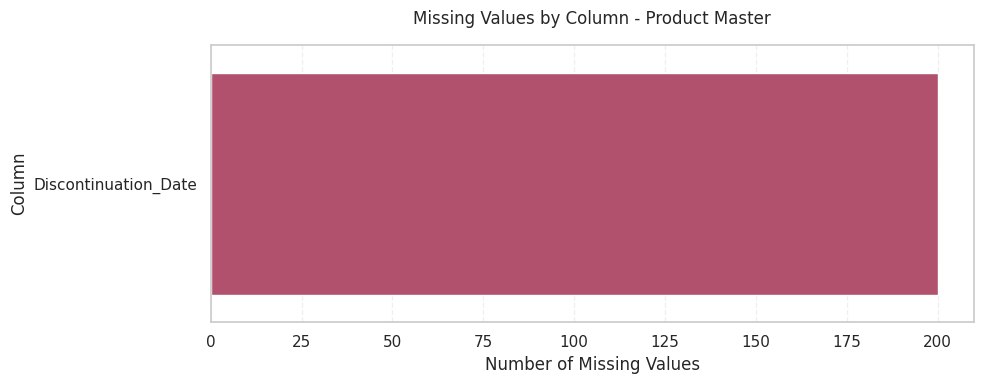


Supplier Master


SL.NO,Column,Missing Values
1,Certification_Level,21


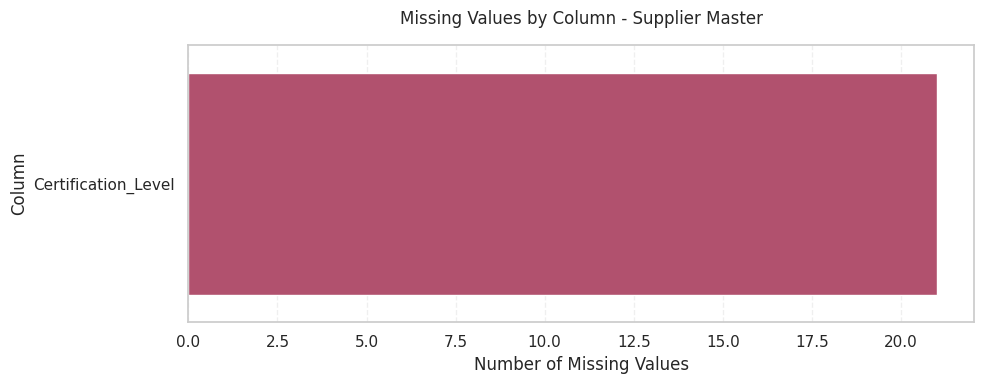

In [232]:
# ============================================================
# 3.3 COLUMN-WISE MISSING VALUE ANALYSIS
# ============================================================

for name, df in datasets.items():

    missing_columns = df.isnull().sum()

    missing_columns = missing_columns[
        missing_columns > 0
    ].sort_values(ascending=False)

    if not missing_columns.empty:

        missing_df = missing_columns.reset_index()

        missing_df.columns = [
            'Column',
            'Missing Values'
        ]

        print(f"\n{name}")

        # Format column-wise missing value table professionally
        missing_df_display = missing_df.copy()
        missing_df_display.insert(0, 'SL.NO', range(1, len(missing_df_display) + 1))

        styled_missing_df = (
            missing_df_display.style

            # Hide default Pandas index
            .hide(axis='index')

            # Format values
            .format({
                'SL.NO': '{:.0f}',
                'Missing Values': '{:,}'
            }, na_rep='N/A')

            # Cell alignment and spacing
            .set_properties(**{
                'text-align': 'center',
                'padding': '12px 20px',
                'font-size': '14px',
                'border': '1px solid #D6D6D6'
            })
            .set_properties(
                subset=['Column'],
                **{'text-align': 'left', 'font-weight': 'bold'}
            )

            # Table and header styling
            .set_table_styles([
                {
                    'selector': 'th',
                    'props': [
                        ('background-color', '#1B365D'),
                        ('color', 'white'),
                        ('font-weight', 'bold'),
                        ('text-align', 'center'),
                        ('padding', '14px 20px'),
                        ('font-size', '14px'),
                        ('border', '1px solid white')
                    ]
                },
                {
                    'selector': 'caption',
                    'props': [
                        ('caption-side', 'top'),
                        ('font-size', '18px'),
                        ('font-weight', 'bold'),
                        ('color', '#1B365D'),
                        ('padding', '12px')
                    ]
                },
                {
                    'selector': 'table',
                    'props': [
                        ('border-collapse', 'collapse'),
                        ('width', '100%'),
                        ('margin', 'auto')
                    ]
                }
            ])

            # Add table caption
            .set_caption(f'Supply Chain Analytics - Missing Values by Column ({name})')
        )

        display(styled_missing_df)

        plt.figure(figsize=(10, 4))

        sns.barplot(
            data=missing_df,
            x='Missing Values',
            y='Column',
            hue='Column',
            palette='flare',
            legend=False
        )

        plt.title(
            f'Missing Values by Column - {name}',
            pad=15
        )

        plt.xlabel('Number of Missing Values')
        plt.ylabel('Column')

        plt.grid(axis='x', alpha=0.3, linestyle='--')
        plt.tight_layout()
        plt.show()

## 3.4. Data Type Distribution

DATA TYPE DISTRIBUTION


SL.NO,Dataset,Numerical Columns,Categorical Columns,Datetime Columns
1,Customer Master,2,6,0
2,Product Master,3,7,0
3,Supplier Master,2,5,0
4,Sales Orders,10,10,0
5,Procurement Orders,3,6,0
6,Data Dictionary,0,4,0


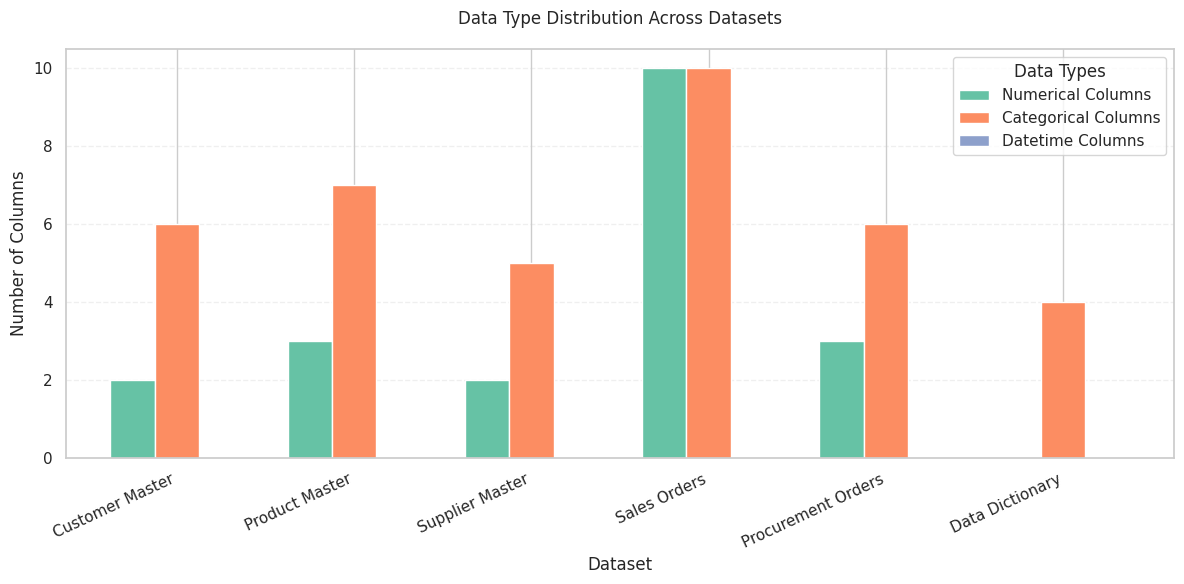

In [233]:
# ============================================================
# 3.4 DATA TYPE DISTRIBUTION
# ============================================================

dtype_summary = []

for name, df in datasets.items():

    numeric_columns = df.select_dtypes(
        include=np.number
    ).shape[1]

    categorical_columns = df.select_dtypes(
        include=['object', 'category']
    ).shape[1]

    datetime_columns = df.select_dtypes(
        include=['datetime']
    ).shape[1]

    dtype_summary.append({
        'Dataset': name,
        'Numerical Columns': numeric_columns,
        'Categorical Columns': categorical_columns,
        'Datetime Columns': datetime_columns
    })


dtype_df = pd.DataFrame(dtype_summary)

print("DATA TYPE DISTRIBUTION")

# Format data type distribution table professionally
dtype_df_display = dtype_df.copy()
dtype_df_display.insert(0, 'SL.NO', range(1, len(dtype_df_display) + 1))

styled_dtype_df = (
    dtype_df_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Numerical Columns': '{:,}',
        'Categorical Columns': '{:,}',
        'Datetime Columns': '{:,}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Dataset'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Column Data Type Distribution by Dataset')
)

display(styled_dtype_df)


# Visualization

dtype_plot = dtype_df.set_index('Dataset')

dtype_plot.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.75
)

plt.title('Data Type Distribution Across Datasets', pad=18)
plt.xlabel('Dataset')
plt.ylabel('Number of Columns')

plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.legend(title='Data Types')
plt.tight_layout()
plt.show()

## 3.5. Dataset Completeness Analysis

DATA COMPLETENESS REPORT


SL.NO,Dataset,Completeness (%),Missing (%)
1,Customer Master,100.00%,0.00%
2,Product Master,90.00%,10.00%
3,Supplier Master,97.00%,3.00%
4,Sales Orders,100.00%,0.00%
5,Procurement Orders,100.00%,0.00%
6,Data Dictionary,100.00%,0.00%


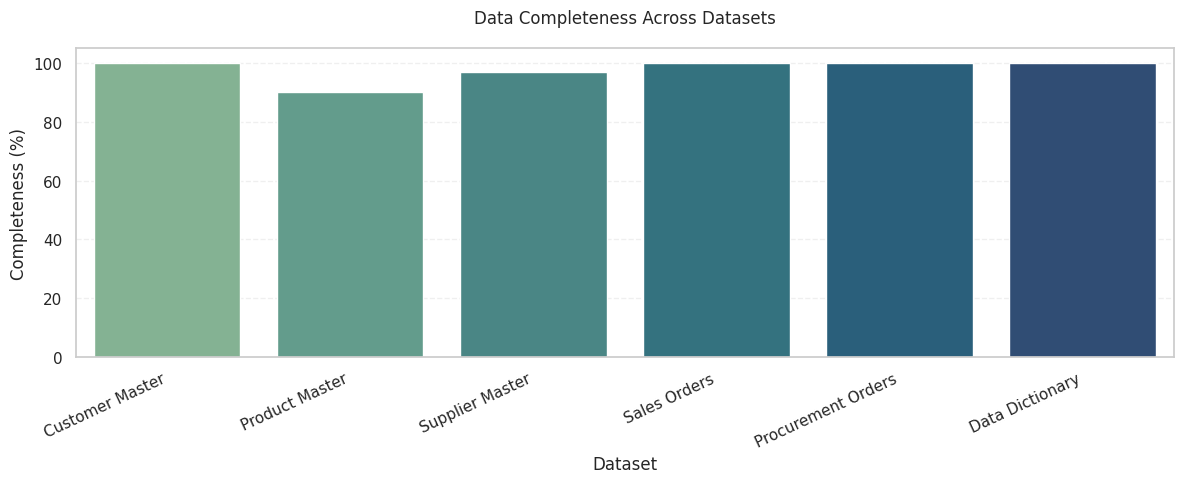

In [234]:
# ============================================================
# 3.5 DATASET COMPLETENESS ANALYSIS
# ============================================================

completeness_data = []

for name, df in datasets.items():

    total_values = df.size
    missing_values = df.isnull().sum().sum()

    complete_values = total_values - missing_values

    completeness = (
        complete_values / total_values * 100
        if total_values > 0 else 0
    )

    missing_percentage = (
        missing_values / total_values * 100
        if total_values > 0 else 0
    )

    completeness_data.append({
        'Dataset': name,
        'Completeness (%)': completeness,
        'Missing (%)': missing_percentage
    })


completeness_df = pd.DataFrame(completeness_data)

print("DATA COMPLETENESS REPORT")

# Format dataset completeness table professionally
completeness_df_display = completeness_df.copy()
completeness_df_display.insert(0, 'SL.NO', range(1, len(completeness_df_display) + 1))

styled_completeness_df = (
    completeness_df_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Completeness (%)': '{:,.2f}%',
        'Missing (%)': '{:,.2f}%'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Dataset'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Dataset Completeness and Missing Percentage Report')
)

display(styled_completeness_df)


# Visualization

plt.figure(figsize=(12, 5))

sns.barplot(
    data=completeness_df,
    x='Dataset',
    y='Completeness (%)',
    hue='Dataset',
    palette='crest',
    legend=False
)

plt.title('Data Completeness Across Datasets', pad=18)
plt.xlabel('Dataset')
plt.ylabel('Completeness (%)')

plt.ylim(0, 105)
plt.xticks(rotation=25, ha='right')

plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

## 3.6. Missing Value Heatmap

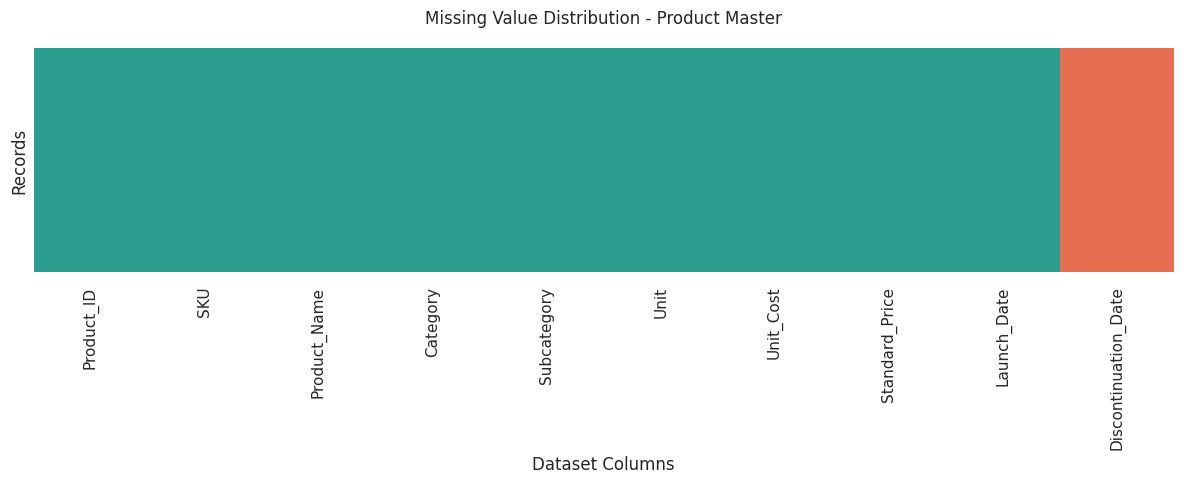

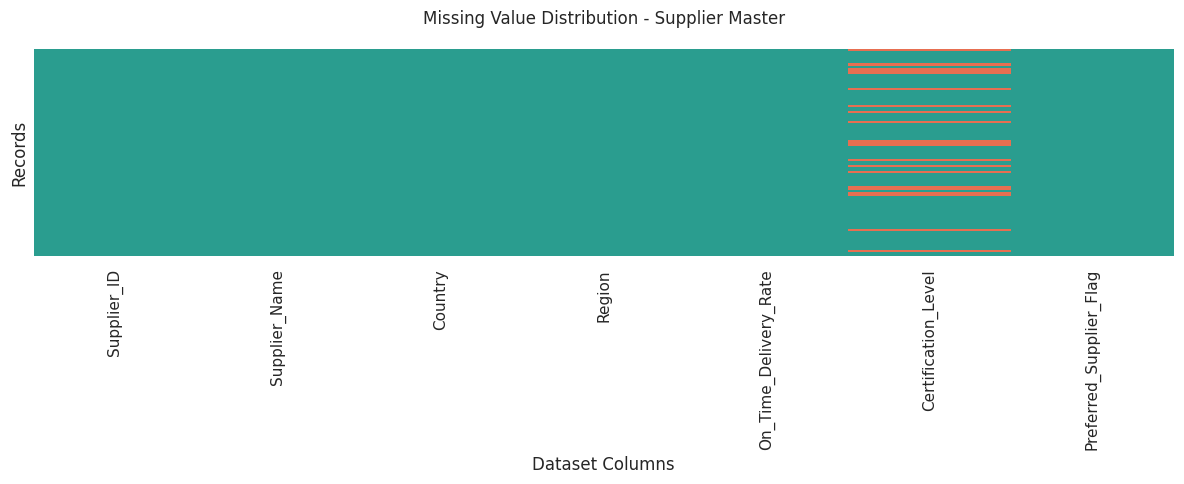

In [235]:
# ============================================================
# 3.6 MISSING VALUE HEATMAP
# ============================================================

for name, df in datasets.items():

    if df.isnull().sum().sum() > 0:

        plt.figure(figsize=(12, 5))

        sns.heatmap(
            df.isnull(),
            cbar=False,
            cmap=['#2A9D8F', '#E76F51'],
            yticklabels=False
        )

        plt.title(
            f'Missing Value Distribution - {name}',
            pad=18
        )

        plt.xlabel('Dataset Columns')
        plt.ylabel('Records')

        plt.tight_layout()
        plt.show()

## 3.7. Dataset Record Composition

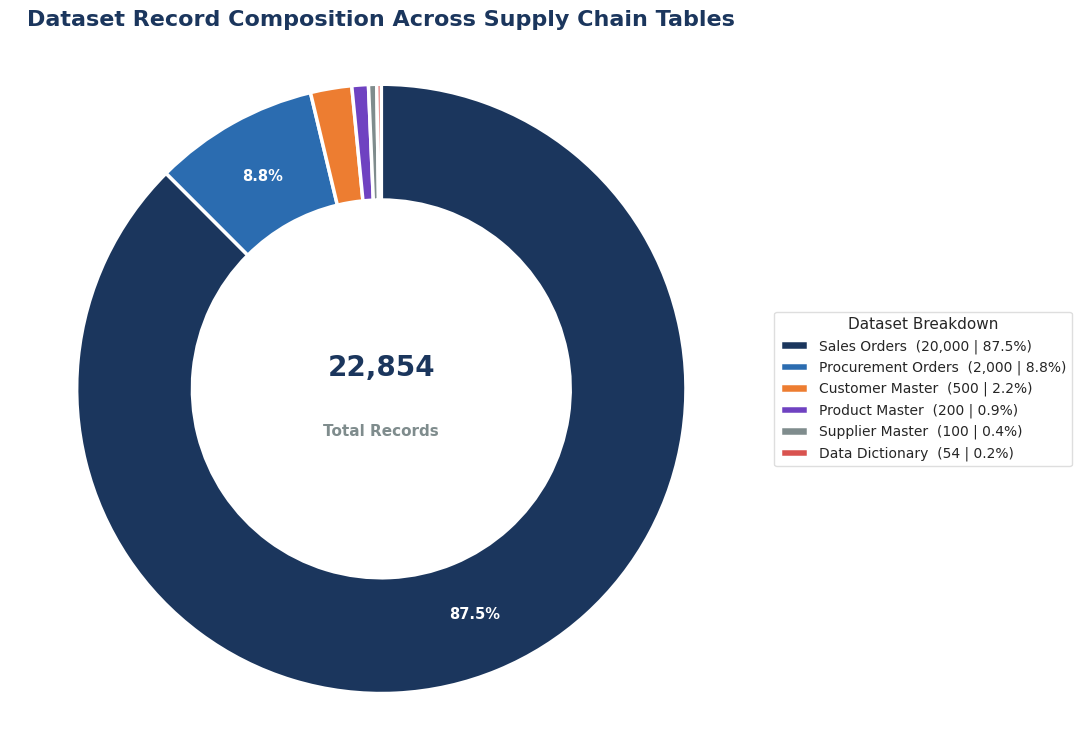

In [236]:
# ============================================================
# 3.7 DATASET RECORD COMPOSITION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('warning', '#ED7D31')
COLORS.setdefault('danger', '#C00000')
COLORS.setdefault('grey', '#6C757D')
COLORS.setdefault('purple', '#6F42C1')

record_composition = pd.DataFrame({
    'Dataset': list(datasets.keys()),
    'Records': [
        len(df) for df in datasets.values()
    ]
}).sort_values('Records', ascending=False).reset_index(drop=True)

total_records_donut = record_composition['Records'].sum()

donut_palette = [
    COLORS['primary'],
    COLORS['secondary'],
    COLORS['warning'],
    COLORS['purple'],
    COLORS['grey'],
    COLORS['danger']
]
colors = [donut_palette[i % len(donut_palette)] for i in range(len(record_composition))]

fig, ax = plt.subplots(figsize=(11, 7.5))

wedges, texts, autotexts = ax.pie(
    record_composition['Records'],
    labels=None,
    autopct=lambda pct: f'{pct:.1f}%' if pct >= 3.5 else '',
    startangle=90,
    counterclock=False,
    pctdistance=0.80,
    colors=colors,
    wedgeprops={
        'width': 0.38,
        'edgecolor': 'white',
        'linewidth': 2.5
    }
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(10.5)
    autotext.set_fontweight('bold')

# Center KPI callout inside donut hole
ax.text(
    0,
    0.07,
    f"{total_records_donut:,}",
    ha='center',
    va='center',
    fontsize=20,
    fontweight='bold',
    color=COLORS['primary']
)
ax.text(
    0,
    -0.14,
    "Total Records",
    ha='center',
    va='center',
    fontsize=11,
    fontweight='bold',
    color=COLORS['grey']
)

legend_labels = [
    f"{row['Dataset']}  ({row['Records']:,} | {row['Records'] / total_records_donut * 100:.1f}%)"
    for _, row in record_composition.iterrows()
]

ax.legend(
    wedges,
    legend_labels,
    title='Dataset Breakdown',
    title_fontsize=11,
    fontsize=10,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    facecolor='white',
    edgecolor='#D6D6D6'
)

ax.set_title(
    'Dataset Record Composition Across Supply Chain Tables',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

ax.axis('equal')
plt.tight_layout()
plt.show()

## 3.8. Final Summary of Dataset Visualization

In [237]:
# ============================================================
# 3.8 FINAL DATASET VISUALIZATION SUMMARY
# ============================================================

total_records = sum(
    len(df) for df in datasets.values()
)

total_missing = sum(
    df.isnull().sum().sum()
    for df in datasets.values()
)

total_cells = sum(
    df.size for df in datasets.values()
)

overall_completeness = (
    (total_cells - total_missing) / total_cells * 100
)

print("\n" + "=" * 65)
print("       DATASET VISUALIZATION - FINAL SUMMARY")
print("=" * 65)

print(f"\n1. Total Datasets       : {len(datasets)}")
print(f"2. Total Records        : {total_records:,}")
print(f"3. Total Missing Values : {total_missing:,}")
print(f"4. Data Completeness    : {overall_completeness:.2f}%")

print("\n5. KEY OBSERVATIONS")

print(
    "\n   - Sales Orders is the largest dataset "
    "with 20,000 records."
)

print(
    "\n   - Product Master contains missing "
    "Discontinuation_Date values."
)

print(
    "\n   - Supplier Master contains missing "
    "Certification_Level values."
)

print(
    "\n   - Customer Master, Sales Orders and "
    "Procurement Orders have no missing values."
)

print(
    "\n   - Overall data completeness is approximately "
    f"{overall_completeness:.2f}%."
)

print("\n6. FINAL CONCLUSION")

print("""
   The dataset visualization provides an overview of the
   structure, volume, data types and completeness of the
   available supply chain datasets.

   The data is largely complete, with missing information
   concentrated in two specific columns.

   These missing values should be investigated according
   to their business meaning before further analysis.

   The datasets are now ready for the next stage:
   DATA PREPARATION AND FEATURE ENGINEERING.
""")

print("=" * 65)


       DATASET VISUALIZATION - FINAL SUMMARY

1. Total Datasets       : 6
2. Total Records        : 22,854
3. Total Missing Values : 221
4. Data Completeness    : 99.95%

5. KEY OBSERVATIONS

   - Sales Orders is the largest dataset with 20,000 records.

   - Product Master contains missing Discontinuation_Date values.

   - Supplier Master contains missing Certification_Level values.

   - Customer Master, Sales Orders and Procurement Orders have no missing values.

   - Overall data completeness is approximately 99.95%.

6. FINAL CONCLUSION

   The dataset visualization provides an overview of the
   structure, volume, data types and completeness of the
   available supply chain datasets.

   The data is largely complete, with missing information
   concentrated in two specific columns.

   These missing values should be investigated according
   to their business meaning before further analysis.

   The datasets are now ready for the next stage:
   DATA PREPARATION AND FEATURE ENGI

# 4. Data Cleaning

In [238]:
# ============================================================
# 4. DATA CLEANING
# ============================================================

# 4.1 Create copies of original datasets

clean_datasets = {
    'Customer Master': customer_df.copy(),
    'Product Master': product_df.copy(),
    'Supplier Master': supplier_df.copy(),
    'Sales Orders': sales_df.copy(),
    'Procurement Orders': procurement_df.copy(),
    'Data Dictionary': dictionary_df.copy()
}

# Store original missing values
original_missing = {
    name: df.isnull().sum().sum()
    for name, df in clean_datasets.items()
}


# 4.2 Remove exact duplicate records

for df in clean_datasets.values():
    df.drop_duplicates(inplace=True)


# 4.3 Handle missing values

# Unknown supplier certification
clean_datasets['Supplier Master'][
    'Certification_Level'
] = (
    clean_datasets['Supplier Master']['Certification_Level']
    .fillna('Unknown')
)

# Preserve missing Discontinuation_Date values
# They may represent active products or unavailable information.


# 4.4 Standardize text columns

for df in clean_datasets.values():

    for col in df.select_dtypes(include=['object']).columns:

        df[col] = df[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

        df[col] = df[col].replace('', np.nan)


# Restore unknown certification labels after text cleaning
clean_datasets['Supplier Master'][
    'Certification_Level'
] = (
    clean_datasets['Supplier Master']['Certification_Level']
    .fillna('Unknown')
)


# 4.5 Convert date columns

date_columns = {
    'Product Master': [
        'Launch_Date', 'Discontinuation_Date'
    ],
    'Sales Orders': [
        'Order_Date',
        'Shipping_Date_Scheduled',
        'Shipping_Date_Actual'
    ],
    'Procurement Orders': [
        'Order_Date',
        'Delivery_Date_Planned',
        'Delivery_Date_Actual'
    ]
}

for name, columns in date_columns.items():

    for col in columns:
        clean_datasets[name][col] = pd.to_datetime(
            clean_datasets[name][col],
            errors='coerce'
        )


# 4.6 Convert numerical columns

numeric_columns = {
    'Customer Master': ['Latitude', 'Longitude'],
    'Product Master': ['Unit_Cost', 'Standard_Price'],
    'Supplier Master': ['On_Time_Delivery_Rate'],

    'Sales Orders': [
        'Order_Quantity', 'Unit_Price', 'Discount',
        'VAT_Rate', 'COGS', 'Unit_Price_Effective',
        'Order_Total', 'VAT_Amount', 'Profit_Per_Order'
    ],

    'Procurement Orders': [
        'Order_Quantity', 'Unit_Cost', 'Total_Cost'
    ]
}

for name, columns in numeric_columns.items():

    for col in columns:
        clean_datasets[name][col] = pd.to_numeric(
            clean_datasets[name][col],
            errors='coerce'
        )


# 4.7 Generate final cleaning report

cleaning_report = pd.DataFrame([
    {
        'Dataset': name,
        'Original Records': len(
            {
                'Customer Master': customer_df,
                'Product Master': product_df,
                'Supplier Master': supplier_df,
                'Sales Orders': sales_df,
                'Procurement Orders': procurement_df,
                'Data Dictionary': dictionary_df
            }[name]
        ),
        'Cleaned Records': len(df),
        'Duplicates Removed': len(
            {
                'Customer Master': customer_df,
                'Product Master': product_df,
                'Supplier Master': supplier_df,
                'Sales Orders': sales_df,
                'Procurement Orders': procurement_df,
                'Data Dictionary': dictionary_df
            }[name]
        ) - len(df),
        'Missing Before': original_missing[name],
        'Missing After': df.isnull().sum().sum()
    }
    for name, df in clean_datasets.items()
])

print("FINAL DATA CLEANING REPORT")

cleaning_report_display = cleaning_report.copy()
cleaning_report_display.insert(0, 'SL.NO', range(1, len(cleaning_report_display) + 1))

styled_cleaning_report = (
    cleaning_report_display.style
    .hide(axis='index')
    .format({
        'SL.NO': '{:.0f}',
        'Original Records': '{:,}',
        'Cleaned Records': '{:,}',
        'Duplicates Removed': '{:,}',
        'Missing Before': '{:,}',
        'Missing After': '{:,}'
    }, na_rep='N/A')
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Dataset'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])
    .set_caption('Supply Chain Analytics - Data Cleaning Audit Summary')
)

display(styled_cleaning_report)


# 4.8 Update dataset references

customer_df = clean_datasets['Customer Master']
product_df = clean_datasets['Product Master']
supplier_df = clean_datasets['Supplier Master']
sales_df = clean_datasets['Sales Orders']
procurement_df = clean_datasets['Procurement Orders']
dictionary_df = clean_datasets['Data Dictionary']


# Final summary

print("\n" + "=" * 55)
print("          DATA CLEANING SUMMARY")
print("=" * 55)

print(
    "Total Missing Before:",
    sum(original_missing.values())
)

print(
    "Total Missing After:",
    sum(df.isnull().sum().sum()
        for df in clean_datasets.values())
)

print(
    "Total Records After Cleaning:",
    sum(len(df) for df in clean_datasets.values())
)

print("\nData cleaning completed successfully.")
print("=" * 55)

FINAL DATA CLEANING REPORT


SL.NO,Dataset,Original Records,Cleaned Records,Duplicates Removed,Missing Before,Missing After
1,Customer Master,500,500,0,0,0
2,Product Master,200,200,0,200,200
3,Supplier Master,100,100,0,21,0
4,Sales Orders,"20,000","20,000",0,0,0
5,Procurement Orders,"2,000","2,000",0,0,0
6,Data Dictionary,54,54,0,0,0



          DATA CLEANING SUMMARY
Total Missing Before: 221
Total Missing After: 200
Total Records After Cleaning: 22854

Data cleaning completed successfully.


# 5. Activate Cleaned Dataset

In [239]:
# ============================================================
# ACTIVATE CLEANED DATASETS FOR FURTHER ANALYSIS
# ============================================================

# Replace original dataset references with cleaned datasets

customer_df = clean_datasets['Customer Master']
product_df = clean_datasets['Product Master']
supplier_df = clean_datasets['Supplier Master']
sales_df = clean_datasets['Sales Orders']
procurement_df = clean_datasets['Procurement Orders']
dictionary_df = clean_datasets['Data Dictionary']


# Update dataset dictionary

datasets = {
    'Customer Master': customer_df,
    'Product Master': product_df,
    'Supplier Master': supplier_df,
    'Sales Orders': sales_df,
    'Procurement Orders': procurement_df,
    'Data Dictionary': dictionary_df
}


# Recreate merged analysis datasets

sales_analysis = (
    sales_df
    .merge(customer_df, on='Customer_ID', how='left')
    .merge(product_df, on='Product_ID', how='left')
)

procurement_analysis = (
    procurement_df
    .merge(supplier_df, on='Supplier_ID', how='left')
)


# Recalculate delivery variance

sales_analysis['Shipping_Variance_Days'] = (
    sales_analysis['Shipping_Date_Actual'] -
    sales_analysis['Shipping_Date_Scheduled']
).dt.days

procurement_analysis['Delivery_Variance_Days'] = (
    procurement_analysis['Delivery_Date_Actual'] -
    procurement_analysis['Delivery_Date_Planned']
).dt.days


# Recalculate profit margin

sales_analysis['Profit_Margin_Percent'] = np.where(
    sales_analysis['Order_Total'] != 0,
    sales_analysis['Profit_Per_Order']
    / sales_analysis['Order_Total'] * 100,
    np.nan
)


# Confirmation

print("CLEANED DATASETS ACTIVATED SUCCESSFULLY!")

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

print("\nAll further analysis will now use cleaned datasets.")

CLEANED DATASETS ACTIVATED SUCCESSFULLY!
Customer Master: (500, 8)
Product Master: (200, 10)
Supplier Master: (100, 7)
Sales Orders: (20000, 20)
Procurement Orders: (2000, 9)
Data Dictionary: (54, 4)

All further analysis will now use cleaned datasets.


# 6. Data Summarisation

In [240]:
# ============================================================
# DATASET SUMMARIZATION
# ============================================================

# All cleaned datasets
datasets = {
    'Customer Master': customer_df,
    'Product Master': product_df,
    'Supplier Master': supplier_df,
    'Sales Orders': sales_df,
    'Procurement Orders': procurement_df,
    'Data Dictionary': dictionary_df
}


def style_summary_table(df, caption_text, left_cols, fmt_overrides=None):
    df_display = df.copy()
    df_display.insert(0, 'SL.NO', range(1, len(df_display) + 1))

    format_map = {'SL.NO': '{:.0f}'}
    for col in df_display.columns:
        if col == 'SL.NO' or col in left_cols:
            continue
        if fmt_overrides and col in fmt_overrides:
            format_map[col] = fmt_overrides[col]
        elif pd.api.types.is_integer_dtype(df_display[col]):
            format_map[col] = '{:,}'
        elif pd.api.types.is_float_dtype(df_display[col]):
            format_map[col] = '{:,.2f}'

    return (
        df_display.style
        .hide(axis='index')
        .format(format_map, na_rep='N/A')
        .set_properties(**{
            'text-align': 'center',
            'padding': '12px 20px',
            'font-size': '14px',
            'border': '1px solid #D6D6D6'
        })
        .set_properties(
            subset=left_cols,
            **{'text-align': 'left', 'font-weight': 'bold'}
        )
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#1B365D'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '14px 20px'),
                    ('font-size', '14px'),
                    ('border', '1px solid white')
                ]
            },
            {
                'selector': 'caption',
                'props': [
                    ('caption-side', 'top'),
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#1B365D'),
                    ('padding', '12px')
                ]
            },
            {
                'selector': 'table',
                'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', 'auto')
                ]
            }
        ])
        .set_caption(caption_text)
    )


# ------------------------------------------------------------
# 1. OVERALL DATASET SUMMARY
# ------------------------------------------------------------

summary = []

for name, df in datasets.items():

    summary.append({
        'Dataset': name,
        'Rows': df.shape[0],
        'Columns': df.shape[1],
        'Total Values': df.size,
        'Missing Values': df.isnull().sum().sum(),
        'Duplicate Rows': df.duplicated().sum(),
        'Numerical Columns': df.select_dtypes(include=np.number).shape[1],
        'Categorical Columns': df.select_dtypes(include='object').shape[1],
        'Completeness (%)': round(
            (1 - df.isnull().sum().sum() / df.size) * 100, 2
        ) if df.size else 0.0
    })

summary_df = pd.DataFrame(summary)

print("=" * 75)
print("                 OVERALL DATASET SUMMARY")
print("=" * 75)

display(
    style_summary_table(
        summary_df,
        'Supply Chain Analytics - Overall Dataset Summary',
        ['Dataset'],
        {'Completeness (%)': '{:,.2f}%'}
    )
)


# ------------------------------------------------------------
# 2. NUMERICAL DATA SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("                 NUMERICAL DATA SUMMARY")
print("=" * 75)

for name, df in datasets.items():

    numerical_df = df.select_dtypes(include=np.number)

    if not numerical_df.empty:

        print(f"\n{name}")
        print("-" * 60)

        num_summary = numerical_df.describe().T.round(2).reset_index()
        num_summary.rename(columns={'index': 'Column'}, inplace=True)
        if 'count' in num_summary.columns:
            num_summary['count'] = num_summary['count'].astype(int)

        display(
            style_summary_table(
                num_summary,
                f'Supply Chain Analytics - Numerical Summary ({name})',
                ['Column']
            )
        )


# ------------------------------------------------------------
# 3. CATEGORICAL DATA SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("                CATEGORICAL DATA SUMMARY")
print("=" * 75)

for name, df in datasets.items():

    categorical_df = df.select_dtypes(include=['object', 'category'])

    if not categorical_df.empty:

        print(f"\n{name}")
        print("-" * 60)

        mode_row = categorical_df.mode()
        most_freq = mode_row.iloc[0] if not mode_row.empty else pd.Series(index=categorical_df.columns, dtype=object)

        cat_summary = pd.DataFrame({
            'Column': categorical_df.columns,
            'Unique Values': categorical_df.nunique().values,
            'Most Frequent Value': most_freq.reindex(categorical_df.columns).fillna('N/A').values,
            'Frequency': categorical_df.apply(
                lambda col: col.value_counts().iloc[0]
                if not col.value_counts().empty else 0
            ).values
        })

        display(
            style_summary_table(
                cat_summary,
                f'Supply Chain Analytics - Categorical Summary ({name})',
                ['Column', 'Most Frequent Value']
            )
        )


# ------------------------------------------------------------
# 4. COLUMN-WISE DATASET PROFILE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("                 COLUMN-WISE DATA PROFILE")
print("=" * 75)

for name, df in datasets.items():

    print(f"\n{name}")
    print("-" * 60)

    column_profile = pd.DataFrame({
        'Column': df.columns,
        'Data Type': df.dtypes.astype(str).values,
        'Non-Null Count': df.notnull().sum().values,
        'Missing Count': df.isnull().sum().values,
        'Unique Values': df.nunique().values
    })

    display(
        style_summary_table(
            column_profile,
            f'Supply Chain Analytics - Column-Wise Data Profile ({name})',
            ['Column', 'Data Type']
        )
    )


# ------------------------------------------------------------
# 5. FINAL DATASET SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("                 FINAL PROJECT SUMMARY")
print("=" * 75)

print(f"Total Datasets       : {len(datasets)}")
print(f"Total Records        : {sum(df.shape[0] for df in datasets.values()):,}")
print(f"Total Columns        : {sum(df.shape[1] for df in datasets.values()):,}")
print(f"Total Missing Values : {sum(df.isnull().sum().sum() for df in datasets.values()):,}")
print(f"Total Duplicate Rows : {sum(df.duplicated().sum() for df in datasets.values()):,}")

print("\nDataset summarization completed successfully.")

                 OVERALL DATASET SUMMARY


SL.NO,Dataset,Rows,Columns,Total Values,Missing Values,Duplicate Rows,Numerical Columns,Categorical Columns,Completeness (%)
1,Customer Master,500,8,"4,000",0,0,2,6,100.00%
2,Product Master,200,10,"2,000",200,0,2,6,90.00%
3,Supplier Master,100,7,700,0,0,2,5,100.00%
4,Sales Orders,"20,000",20,"400,000",0,0,10,7,100.00%
5,Procurement Orders,"2,000",9,"18,000",0,0,3,3,100.00%
6,Data Dictionary,54,4,216,0,0,0,4,100.00%



                 NUMERICAL DATA SUMMARY

Customer Master
------------------------------------------------------------


SL.NO,Column,count,mean,std,min,25%,50%,75%,max
1,Latitude,500,1.14,51.91,-89.72,-39.63,1.23,46.37,89.61
2,Longitude,500,-0.85,104.89,-180.00,-84.58,-1.04,89.72,178.13



Product Master
------------------------------------------------------------


SL.NO,Column,count,mean,std,min,25%,50%,75%,max
1,Unit_Cost,200,100.13,59.45,7.11,42.28,102.26,151.76,198.63
2,Standard_Price,200,175.93,98.55,14.95,89.93,172.94,253.59,349.90


... (27 outputs left out)

SL.NO,Column,Data Type,Non-Null Count,Missing Count,Unique Values
1,PO_ID,object,"2,000",0,"2,000"
2,Supplier_ID,object,"2,000",0,100
3,Raw_Material_ID,object,"2,000",0,200
4,Order_Date,datetime64[ns],"2,000",0,987
5,Order_Quantity,int64,"2,000",0,21
6,Unit_Cost,float64,"2,000",0,"2,000"
7,Delivery_Date_Planned,datetime64[ns],"2,000",0,975
8,Delivery_Date_Actual,datetime64[ns],"2,000",0,965
9,Total_Cost,float64,"2,000",0,"2,000"



Data Dictionary
------------------------------------------------------------


SL.NO,Column,Data Type,Non-Null Count,Missing Count,Unique Values
1,Table_Name,object,54,0,5
2,Column_Name,object,54,0,47
3,Description,object,54,0,54
4,Data_Type,object,54,0,4



                 FINAL PROJECT SUMMARY
Total Datasets       : 6
Total Records        : 22,854
Total Columns        : 58
Total Missing Values : 200
Total Duplicate Rows : 0

Dataset summarization completed successfully.


# 7. Univariate Analysis

## 7.1. How are profits distributed? What is the median profitability?

### 7.1.1. Profit Data Preparation

In [241]:
# ============================================================
#PROFITABILITY DATA PREPARATION
# ============================================================

# Merge sales orders with product information
profit_analysis = sales_df.merge(
    product_df[['Product_ID', 'SKU', 'Product_Name', 'Category']],
    on='Product_ID',
    how='left'
)

# Remove missing profitability values
profit_data = profit_analysis.dropna(
    subset=['Profit_Per_Order']
).copy()

# Calculate descriptive statistics
median_profit = profit_data['Profit_Per_Order'].median()
mean_profit = profit_data['Profit_Per_Order'].mean()
total_profit = profit_data['Profit_Per_Order'].sum()

print("PROFITABILITY SUMMARY")
print("-" * 45)

print(f"Total Sales Transactions : {len(profit_data):,}")
print(f"Total Profit             : {total_profit:,.2f}")
print(f"Average Profit per Order : {mean_profit:,.2f}")
print(f"Median Profit per Order  : {median_profit:,.2f}")
print(f"Minimum Profit           : {profit_data['Profit_Per_Order'].min():,.2f}")
print(f"Maximum Profit           : {profit_data['Profit_Per_Order'].max():,.2f}")

PROFITABILITY SUMMARY
---------------------------------------------
Total Sales Transactions : 20,000
Total Profit             : 5,606,605.76
Average Profit per Order : 280.33
Median Profit per Order  : 240.47
Minimum Profit           : -346.97
Maximum Profit           : 2,005.80


### 7.1.2. Histogram with KDE — Profit Distribution

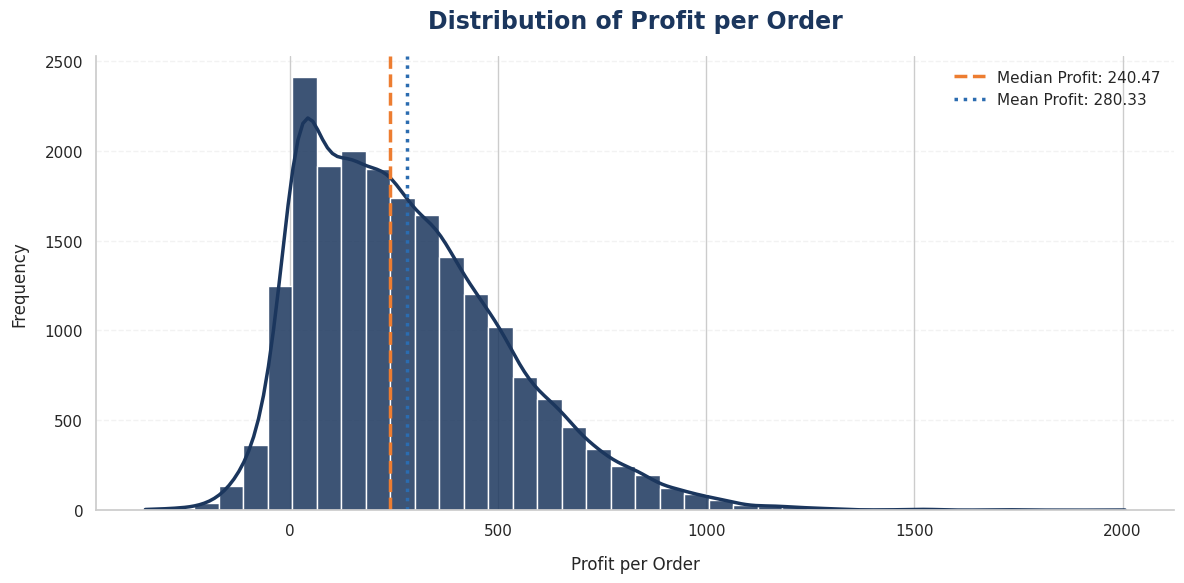

In [242]:
# ============================================================
# PROFIT DISTRIBUTION - HISTOGRAM WITH KDE
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {
        'primary': '#1F4E78',
        'secondary': '#2E7D32',
        'warning': '#ED7D31',
        'danger': '#C00000'
    }

plt.figure(figsize=(12, 6))

sns.histplot(
    data=profit_data,
    x='Profit_Per_Order',
    bins=40,
    kde=True,
    color=COLORS['primary'],
    edgecolor='white',
    alpha=0.85,
    line_kws={
        'color': COLORS['danger'],
        'linewidth': 2.5
    }
)

# Median reference line
plt.axvline(
    median_profit,
    color=COLORS['warning'],
    linestyle='--',
    linewidth=2.5,
    label=f'Median Profit: {median_profit:,.2f}'
)

# Mean reference line
plt.axvline(
    mean_profit,
    color=COLORS['secondary'],
    linestyle=':',
    linewidth=2.5,
    label=f'Mean Profit: {mean_profit:,.2f}'
)

plt.title(
    'Distribution of Profit per Order',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Profit per Order', labelpad=12)
plt.ylabel('Frequency', labelpad=12)

plt.legend(frameon=False)

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 7.1.3. Box Plot — Profitability Spread and Outliers

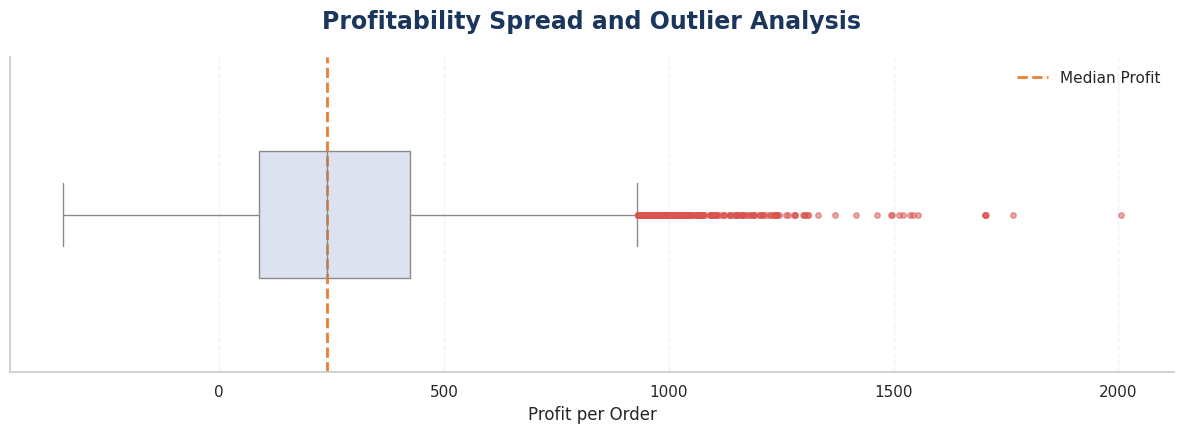

In [243]:
# ============================================================
# PROFITABILITY SPREAD - BOX PLOT
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {
        'primary': '#1F4E78',
        'secondary': '#2E7D32',
        'warning': '#ED7D31',
        'danger': '#C00000',
        'light': '#D9E1F2'
    }
else:
    COLORS.setdefault('light', '#D9E1F2')

plt.figure(figsize=(12, 4.5))

sns.boxplot(
    data=profit_data,
    x='Profit_Per_Order',
    color=COLORS['light'],
    width=0.4,
    flierprops={
        'marker': 'o',
        'markerfacecolor': COLORS['danger'],
        'markeredgecolor': COLORS['danger'],
        'markersize': 4,
        'alpha': 0.5
    }
)

plt.axvline(
    median_profit,
    color=COLORS['warning'],
    linestyle='--',
    linewidth=2,
    label='Median Profit'
)

plt.title(
    'Profitability Spread and Outlier Analysis',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Profit per Order')
plt.legend(frameon=False)

plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 7.1.4. SKU-wise Profit Concentration — Horizontal Bar Chart

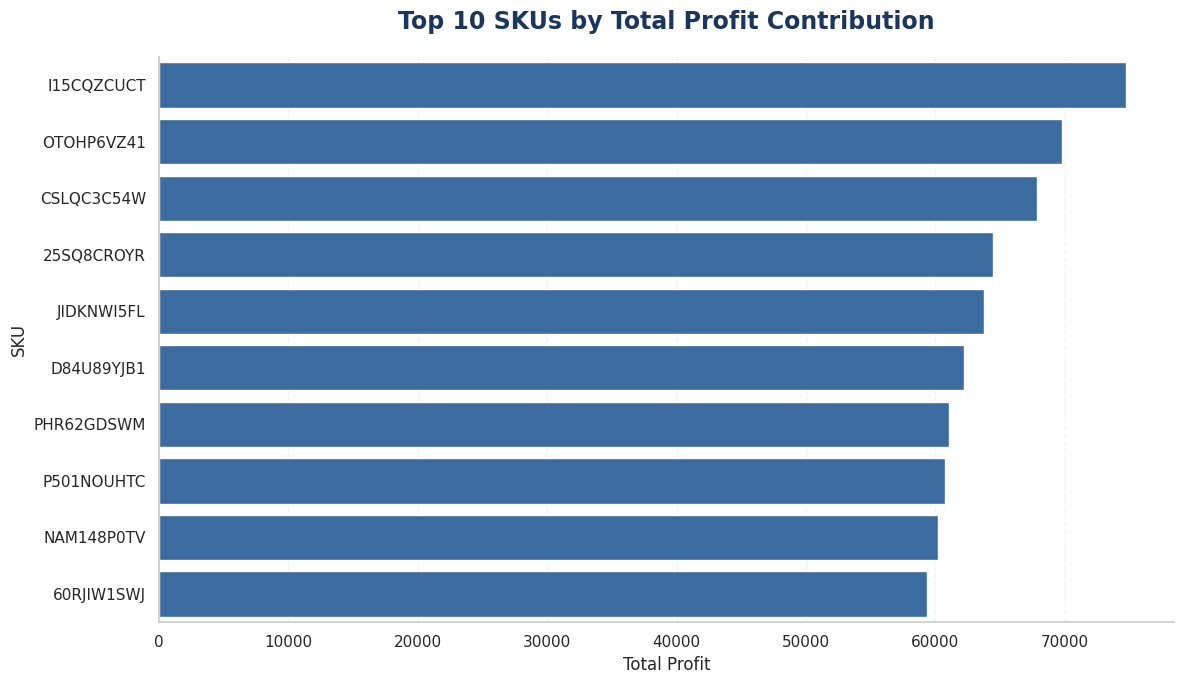



Top 10 SKUs Contribution to Total Profit: 11.49%


In [244]:
# ============================================================
# SKU-WISE PROFIT CONCENTRATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

if 'COLORS' not in globals():
    COLORS = {}

COLORS.update({
    'primary': '#1B365D',    # Deep executive navy for titles/accents
    'secondary': '#2B6CB0'   # Refined slate-blue for bars
})

# Calculate total profit generated by each SKU
sku_profit = (
    profit_data
    .groupby('SKU', as_index=False)
    .agg(
        Total_Profit=('Profit_Per_Order', 'sum'),
        Average_Profit=('Profit_Per_Order', 'mean'),
        Number_of_Orders=('Order_ID', 'count')
    )
    .sort_values('Total_Profit', ascending=False)
)

# Calculate contribution to total profit
total_sku_profit = sku_profit['Total_Profit'].sum()

if total_sku_profit != 0:

    sku_profit['Profit_Contribution_Percent'] = (
        sku_profit['Total_Profit'] / total_sku_profit
    ) * 100

    sku_profit['Cumulative_Profit_Percent'] = (
        sku_profit['Profit_Contribution_Percent'].cumsum()
    )

    top_10_profit_share = (
        sku_profit.head(10)['Total_Profit'].sum()
        / total_sku_profit
    ) * 100

else:
    top_10_profit_share = np.nan

# Select top 10 SKUs
top_10_skus = sku_profit.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_skus,
    x='Total_Profit',
    y='SKU',
    color=COLORS['secondary'],
    edgecolor='white'
)

plt.title(
    'Top 10 SKUs by Total Profit Contribution',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Total Profit')
plt.ylabel('SKU')

plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()
print("\n")
print(f"Top 10 SKUs Contribution to Total Profit: {top_10_profit_share:.2f}%")

## 7.2. Are discounts reducing product margins?

### 7.2.1. Discount Data Preparation

In [245]:
# ============================================================
#  DISCOUNT DATA PREPARATION
# ============================================================

discount_analysis = sales_df.merge(
    product_df[
        ['Product_ID', 'SKU', 'Unit_Cost', 'Standard_Price']
    ],
    on='Product_ID',
    how='left'
)

discount_analysis = discount_analysis.dropna(
    subset=['Discount', 'Unit_Cost', 'Standard_Price']
).copy()

# Calculate standard gross margin percentage
discount_analysis['Standard_Gross_Margin_Percent'] = np.where(
    discount_analysis['Standard_Price'] > 0,
    (
        (
            discount_analysis['Standard_Price']
            - discount_analysis['Unit_Cost']
        )
        / discount_analysis['Standard_Price']
    ) * 100,
    np.nan
)

# Convert discount fraction into percentage
discount_analysis['Discount_Percent'] = (
    discount_analysis['Discount'] * 100
)

# Identify discounts exceeding standard gross margin
discount_analysis['Margin_Risk'] = (
    discount_analysis['Discount_Percent']
    >
    discount_analysis['Standard_Gross_Margin_Percent']
)

# Calculate summary statistics
heavy_discount_count = discount_analysis['Margin_Risk'].sum()

total_discount_orders = len(discount_analysis)

heavy_discount_percentage = (
    heavy_discount_count / total_discount_orders * 100
    if total_discount_orders > 0 else np.nan
)

print("DISCOUNT VULNERABILITY SUMMARY")
print("-" * 45)

print(f"Total Analyzed Orders       : {total_discount_orders:,}")
print(f"Average Discount           : {discount_analysis['Discount_Percent'].mean():.2f}%")
print(f"Median Discount            : {discount_analysis['Discount_Percent'].median():.2f}%")
print(f"Maximum Discount           : {discount_analysis['Discount_Percent'].max():.2f}%")
print(f"Orders Exceeding Margin    : {heavy_discount_count:,}")
print(f"Heavy Discount Percentage  : {heavy_discount_percentage:.2f}%")

DISCOUNT VULNERABILITY SUMMARY
---------------------------------------------
Total Analyzed Orders       : 20,000
Average Discount           : 12.52%
Median Discount            : 13.00%
Maximum Discount           : 25.00%
Orders Exceeding Margin    : 6,616
Heavy Discount Percentage  : 33.08%


### 7.2.2. Histogram with KDE — Discount Distribution

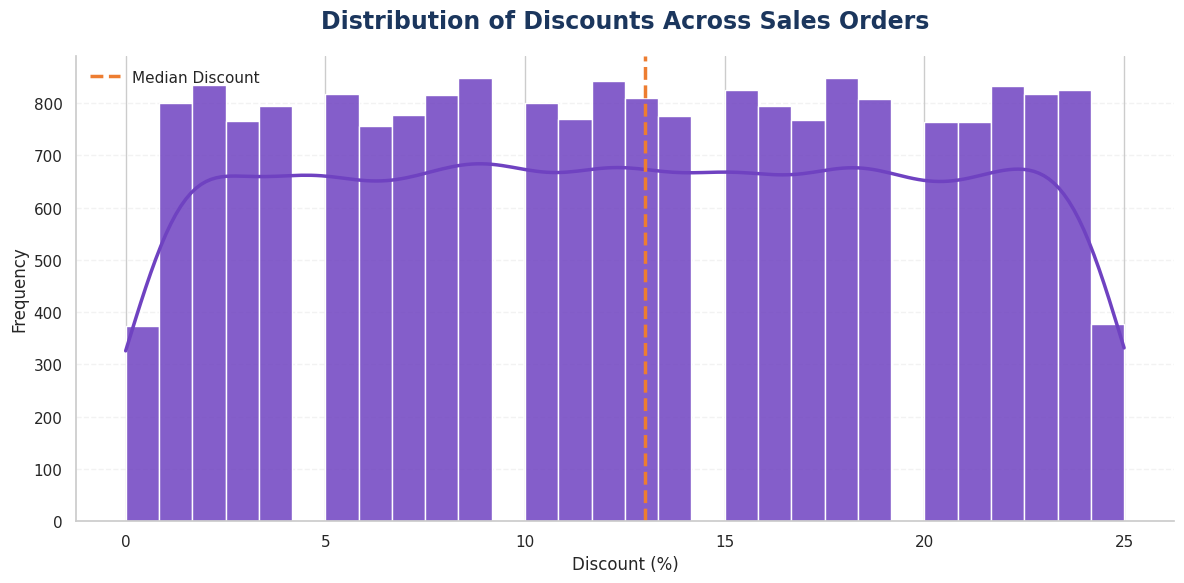

In [246]:
# ============================================================
# DISCOUNT DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('purple', '#6A4C93')
COLORS.setdefault('danger', '#C00000')
COLORS.setdefault('warning', '#ED7D31')
COLORS.setdefault('primary', '#1B365D')

plt.figure(figsize=(12, 6))

sns.histplot(
    data=discount_analysis,
    x='Discount_Percent',
    bins=30,
    kde=True,
    color=COLORS['purple'],
    edgecolor='white',
    alpha=0.85,
    line_kws={
        'color': COLORS['danger'],
        'linewidth': 2.5
    }
)

plt.axvline(
    discount_analysis['Discount_Percent'].median(),
    color=COLORS['warning'],
    linestyle='--',
    linewidth=2.5,
    label='Median Discount'
)

plt.title(
    'Distribution of Discounts Across Sales Orders',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Discount (%)')
plt.ylabel('Frequency')

plt.legend(frameon=False)

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 7.2.3. Discount vs Standard Gross Margin

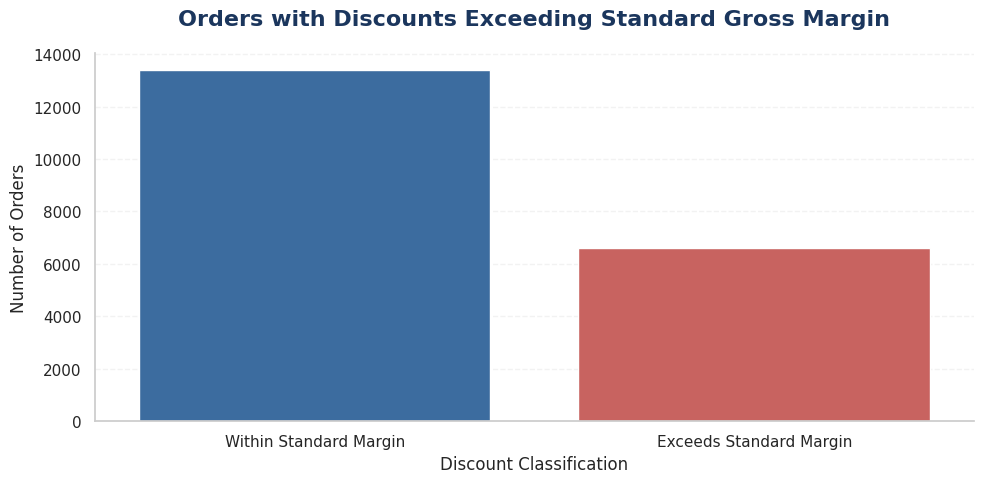

In [247]:
# ============================================================
# DISCOUNT VS STANDARD GROSS MARGIN
# ============================================================

margin_risk_summary = pd.DataFrame({
    'Discount Category': [
        'Within Standard Margin',
        'Exceeds Standard Margin'
    ],
    'Number of Orders': [
        (~discount_analysis['Margin_Risk']).sum(),
        discount_analysis['Margin_Risk'].sum()
    ]
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=margin_risk_summary,
    x='Discount Category',
    y='Number of Orders',
    hue='Discount Category',
    palette=[
        COLORS['secondary'],
        COLORS['danger']
    ],
    legend=False
)

plt.title(
    'Orders with Discounts Exceeding Standard Gross Margin',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Discount Classification')
plt.ylabel('Number of Orders')

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

## 7.3. What proportion of orders are flagged as delivery risks or delivered late?

### 7.3.1. Delivery Data Preparation

In [248]:
# ============================================================
# DELIVERY DATA PREPARATION
# ============================================================

delivery_analysis = sales_df.copy()

# Standardize categorical delivery status
delivery_analysis['Delivery_Status_Clean'] = (
    delivery_analysis['Delivery_Status']
    .astype('string')
    .str.strip()
    .str.lower()
)

# Standardize risk flag
delivery_analysis['Risk_Flag_Clean'] = (
    delivery_analysis['Late_Delivery_Risk_Flag']
    .astype('string')
    .str.strip()
    .str.lower()
)

# Identify risk-flagged orders
risk_flagged = delivery_analysis[
    'Risk_Flag_Clean'
].isin(['1', '1.0', 'true', 'yes', 'y'])

# Identify orders with a late delivery status
late_status = delivery_analysis[
    'Delivery_Status_Clean'
].eq('late')

# Calculate proportions using non-missing observations
risk_valid = delivery_analysis[
    'Late_Delivery_Risk_Flag'
].notna()

status_valid = delivery_analysis[
    'Delivery_Status'
].notna()

risk_percentage = (
    risk_flagged.sum() / risk_valid.sum() * 100
    if risk_valid.sum() > 0 else np.nan
)

late_percentage = (
    late_status.sum() / status_valid.sum() * 100
    if status_valid.sum() > 0 else np.nan
)

print("DELIVERY PERFORMANCE SUMMARY")
print("-" * 45)

print(f"Total Sales Orders          : {len(delivery_analysis):,}")
print(f"Risk-Flagged Orders         : {risk_flagged.sum():,}")
print(f"Risk Flag Percentage       : {risk_percentage:.2f}%")
print(f"Orders with Late Status     : {late_status.sum():,}")
print(f"Late Delivery Percentage   : {late_percentage:.2f}%")

DELIVERY PERFORMANCE SUMMARY
---------------------------------------------
Total Sales Orders          : 20,000
Risk-Flagged Orders         : 15,915
Risk Flag Percentage       : 79.57%
Orders with Late Status     : 15,915
Late Delivery Percentage   : 79.57%


### 7.3.2. Count Plot — Delivery Status Distribution

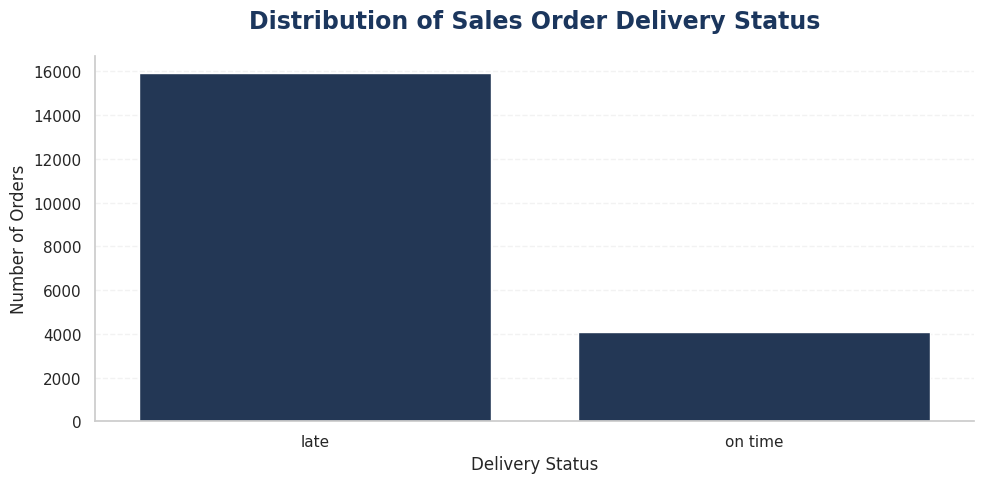

In [249]:
# ============================================================
# DELIVERY STATUS DISTRIBUTION
# ============================================================

status_data = delivery_analysis.dropna(
    subset=['Delivery_Status_Clean']
)

plt.figure(figsize=(10, 5))

status_order = (
    status_data['Delivery_Status_Clean']
    .value_counts()
    .index
)

sns.countplot(
    data=status_data,
    x='Delivery_Status_Clean',
    order=status_order,
    color=COLORS['primary'],
    edgecolor='white'
)

plt.title(
    'Distribution of Sales Order Delivery Status',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Delivery Status')
plt.ylabel('Number of Orders')

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 7.3.3. Donut Chart — Late vs Non-Late Delivery Status

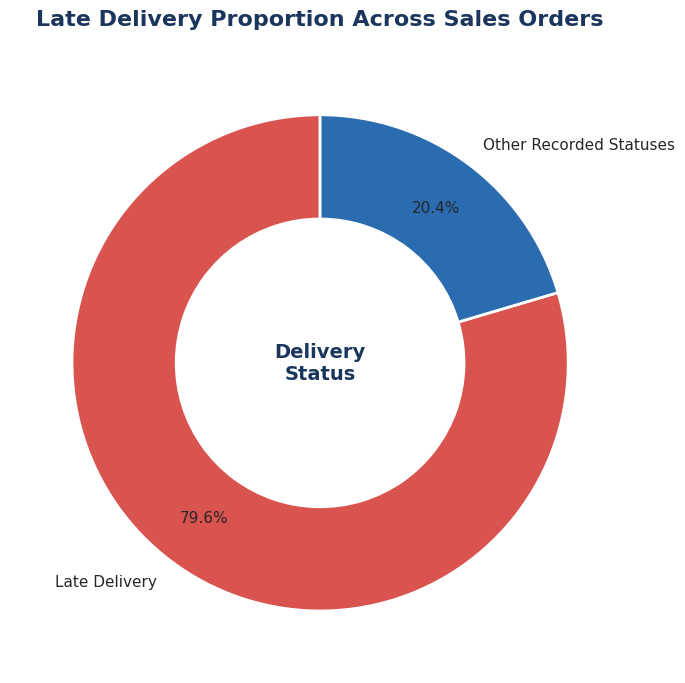

In [250]:
# ============================================================
# LATE DELIVERY PROPORTION
# ============================================================

delivery_counts = [
    late_status.sum(),
    (status_valid & ~late_status).sum()
]

delivery_labels = [
    'Late Delivery',
    'Other Recorded Statuses'
]

plt.figure(figsize=(8, 7))

plt.pie(
    delivery_counts,
    labels=delivery_labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=[
        COLORS['danger'],
        COLORS['secondary']
    ],
    wedgeprops={
        'width': 0.42,
        'edgecolor': 'white',
        'linewidth': 2
    },
    pctdistance=0.78,
    textprops={
        'fontsize': 11
    }
)

plt.text(
    0,
    0,
    'Delivery\nStatus',
    ha='center',
    va='center',
    fontsize=14,
    fontweight='bold',
    color=COLORS['primary']
)

plt.title(
    'Late Delivery Proportion Across Sales Orders',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.tight_layout()
plt.show()

### 7.3.4. Risk Flag vs Actual Delivery Status

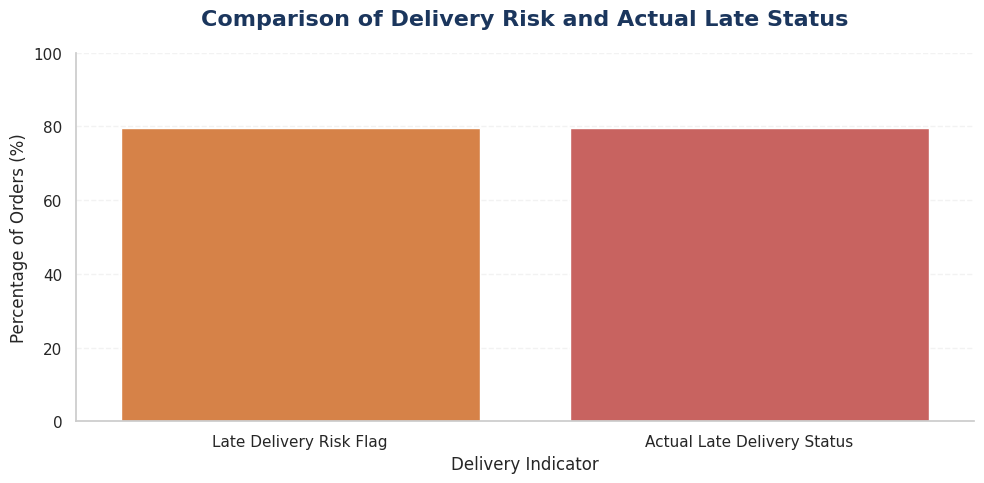

In [251]:
# ============================================================
# RISK FLAG VS ACTUAL DELIVERY STATUS
# ============================================================

risk_comparison = pd.DataFrame({
    'Delivery Indicator': [
        'Late Delivery Risk Flag',
        'Actual Late Delivery Status'
    ],
    'Percentage': [
        risk_percentage,
        late_percentage
    ]
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=risk_comparison,
    x='Delivery Indicator',
    y='Percentage',
    hue='Delivery Indicator',
    palette=[
        COLORS['warning'],
        COLORS['danger']
    ],
    legend=False
)

plt.title(
    'Comparison of Delivery Risk and Actual Late Status',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Delivery Indicator')
plt.ylabel('Percentage of Orders (%)')

plt.ylim(0, 100)

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

## 7.4. How are procurement costs distributed, and where are costs concentrated?

### 7.4.1. Procurement Cost Data Preparation

In [252]:
# ============================================================
# 7.4.1 PROCUREMENT COST DATA PREPARATION
# ============================================================

procurement_cost_data = procurement_df.dropna(
    subset=['Total_Cost']
).copy()

# Calculate descriptive statistics
median_procurement_cost = (
    procurement_cost_data['Total_Cost'].median()
)

mean_procurement_cost = (
    procurement_cost_data['Total_Cost'].mean()
)

total_procurement_cost = (
    procurement_cost_data['Total_Cost'].sum()
)

print("PROCUREMENT COST SUMMARY")
print("-" * 45)

print(f"Total Purchase Orders  : {len(procurement_cost_data):,}")
print(f"Total Procurement Cost : {total_procurement_cost:,.2f}")
print(f"Average Order Cost     : {mean_procurement_cost:,.2f}")
print(f"Median Order Cost      : {median_procurement_cost:,.2f}")
print(f"Minimum Order Cost     : {procurement_cost_data['Total_Cost'].min():,.2f}")
print(f"Maximum Order Cost     : {procurement_cost_data['Total_Cost'].max():,.2f}")

PROCUREMENT COST SUMMARY
---------------------------------------------
Total Purchase Orders  : 2,000
Total Procurement Cost : 915,533.47
Average Order Cost     : 457.77
Median Order Cost      : 413.31
Minimum Order Cost     : 16.11
Maximum Order Cost     : 1,608.99


### 7.4.2. Histogram with KDE — Procurement Cost Distribution

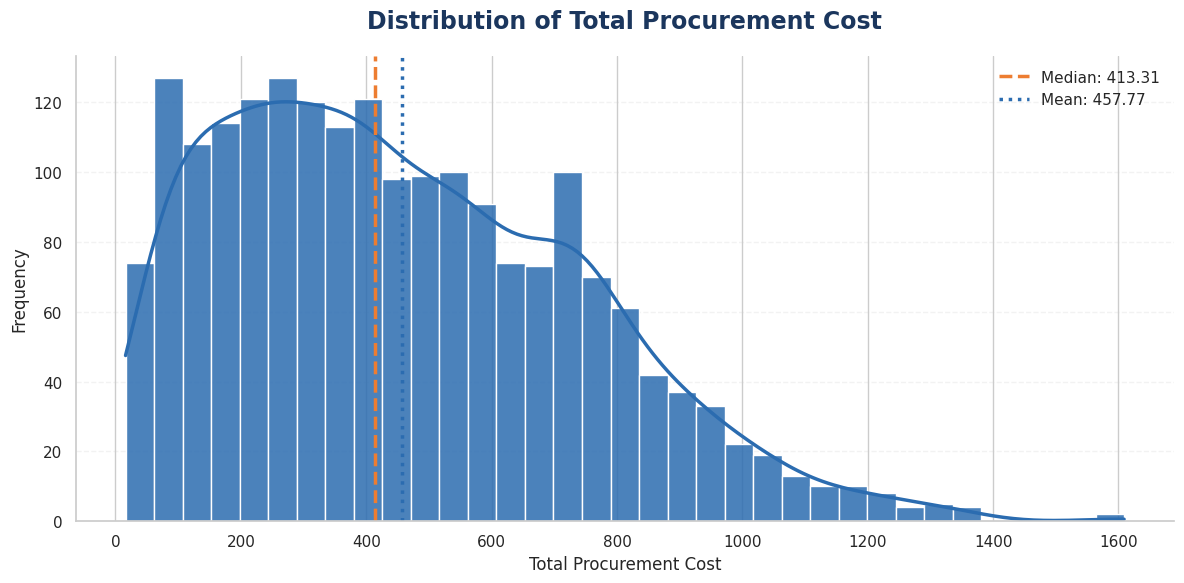

In [253]:
# ============================================================
# 7.4.2 PROCUREMENT COST DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('blue', '#2B6CB0')
COLORS.setdefault('danger', '#C00000')
COLORS.setdefault('warning', '#ED7D31')
COLORS.setdefault('secondary', '#2E7D32')
COLORS.setdefault('primary', '#1B365D')

plt.figure(figsize=(12, 6))

sns.histplot(
    data=procurement_cost_data,
    x='Total_Cost',
    bins=35,
    kde=True,
    color=COLORS['blue'],
    edgecolor='white',
    alpha=0.85,
    line_kws={
        'color': COLORS['danger'],
        'linewidth': 2.5
    }
)

plt.axvline(
    median_procurement_cost,
    color=COLORS['warning'],
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {median_procurement_cost:,.2f}'
)

plt.axvline(
    mean_procurement_cost,
    color=COLORS['secondary'],
    linestyle=':',
    linewidth=2.5,
    label=f'Mean: {mean_procurement_cost:,.2f}'
)

plt.title(
    'Distribution of Total Procurement Cost',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Total Procurement Cost')
plt.ylabel('Frequency')

plt.legend(frameon=False)

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 7.4.3. Box Plot — Procurement Cost Outliers

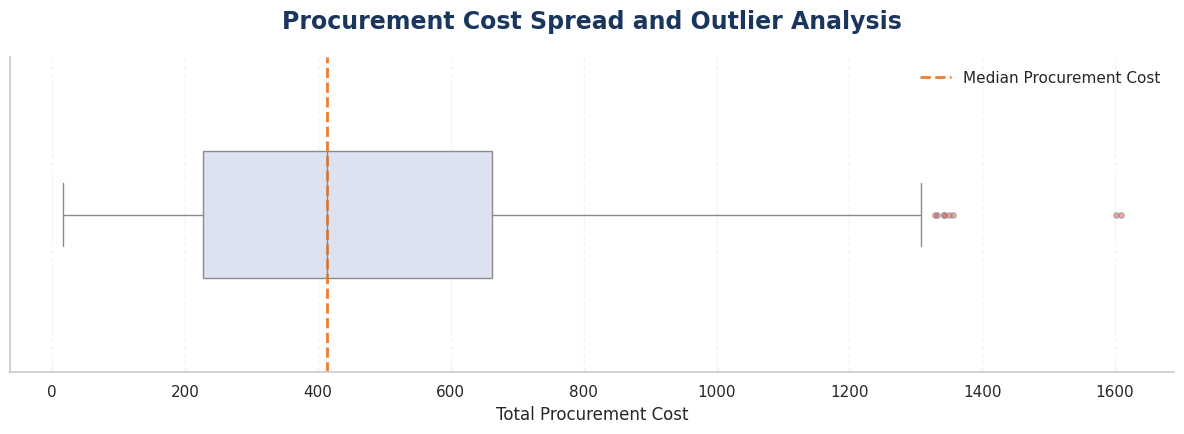

In [254]:
# ============================================================
# PROCUREMENT COST OUTLIER ANALYSIS
# ============================================================

plt.figure(figsize=(12, 4.5))

sns.boxplot(
    data=procurement_cost_data,
    x='Total_Cost',
    color=COLORS['light'],
    width=0.4,
    flierprops={
        'marker': 'o',
        'markerfacecolor': COLORS['danger'],
        'markersize': 4,
        'alpha': 0.5
    }
)

plt.axvline(
    median_procurement_cost,
    color=COLORS['warning'],
    linestyle='--',
    linewidth=2,
    label='Median Procurement Cost'
)

plt.title(
    'Procurement Cost Spread and Outlier Analysis',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Total Procurement Cost')
plt.legend(frameon=False)

plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 7.4.4. Raw Material Cost Concentration — Horizontal Bar Chart

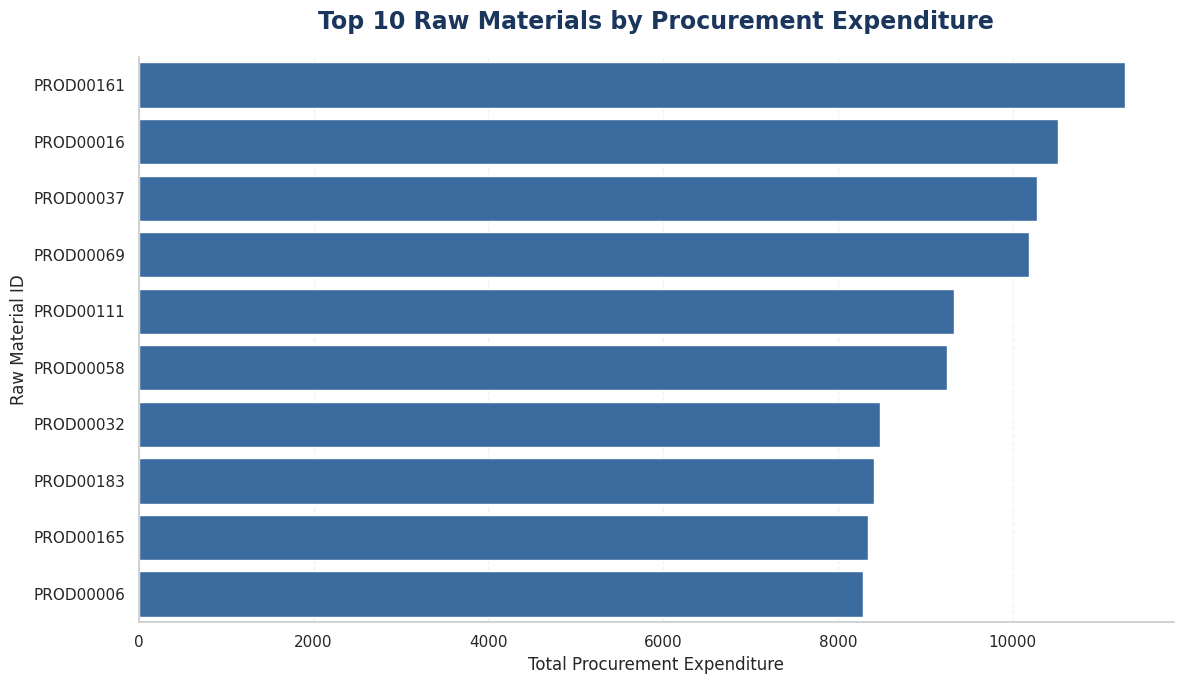

Top 10 Raw Materials Cost Contribution: 10.31%


In [255]:
# ============================================================
# RAW MATERIAL PROCUREMENT COST CONCENTRATION
# ============================================================

raw_material_cost = (
    procurement_cost_data
    .groupby('Raw_Material_ID', as_index=False)
    .agg(
        Total_Expenditure=('Total_Cost', 'sum'),
        Number_of_Orders=('PO_ID', 'count')
    )
    .sort_values(
        'Total_Expenditure',
        ascending=False
    )
)

# Select top 10 raw materials
top_raw_materials = raw_material_cost.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_raw_materials,
    x='Total_Expenditure',
    y='Raw_Material_ID',
    color=COLORS['secondary'],
    edgecolor='white'
)

plt.title(
    'Top 10 Raw Materials by Procurement Expenditure',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Total Procurement Expenditure')
plt.ylabel('Raw Material ID')

plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

# Calculate top 10 cost contribution
top_10_material_share = (
    top_raw_materials['Total_Expenditure'].sum()
    / total_procurement_cost
) * 100

print(
    f"Top 10 Raw Materials Cost Contribution: "
    f"{top_10_material_share:.2f}%"
)

## 7.5. How do supplier delivery rates vary, and what proportion are preferred suppliers?

### 7.5.1. Supplier Performance Data Preparation

In [256]:
# ============================================================
# SUPPLIER PERFORMANCE DATA PREPARATION
# ============================================================

supplier_performance_data = supplier_df.dropna(
    subset=['On_Time_Delivery_Rate']
).copy()

# Calculate delivery performance statistics
supplier_delivery_mean = (
    supplier_performance_data['On_Time_Delivery_Rate'].mean()
)

supplier_delivery_median = (
    supplier_performance_data['On_Time_Delivery_Rate'].median()
)

supplier_delivery_std = (
    supplier_performance_data['On_Time_Delivery_Rate'].std()
)

# Preferred supplier count
preferred_count = (
    supplier_df['Preferred_Supplier_Flag']
    .eq(1)
    .sum()
)

valid_preferred_count = (
    supplier_df['Preferred_Supplier_Flag']
    .notna()
    .sum()
)

preferred_percentage = (
    preferred_count / valid_preferred_count * 100
    if valid_preferred_count > 0 else np.nan
)

print("SUPPLIER PERFORMANCE SUMMARY")
print("-" * 45)

print(f"Total Suppliers          : {len(supplier_df):,}")
print(f"Average On-Time Rate     : {supplier_delivery_mean:.2f}")
print(f"Median On-Time Rate      : {supplier_delivery_median:.2f}")
print(f"Standard Deviation       : {supplier_delivery_std:.2f}")
print(f"Preferred Suppliers      : {preferred_count:,}")
print(f"Preferred Supplier Share : {preferred_percentage:.2f}%")

SUPPLIER PERFORMANCE SUMMARY
---------------------------------------------
Total Suppliers          : 100
Average On-Time Rate     : 0.80
Median On-Time Rate      : 0.81
Standard Deviation       : 0.12
Preferred Suppliers      : 46
Preferred Supplier Share : 46.00%


### 7.5.2. Histogram with KDE — Supplier Delivery Rate

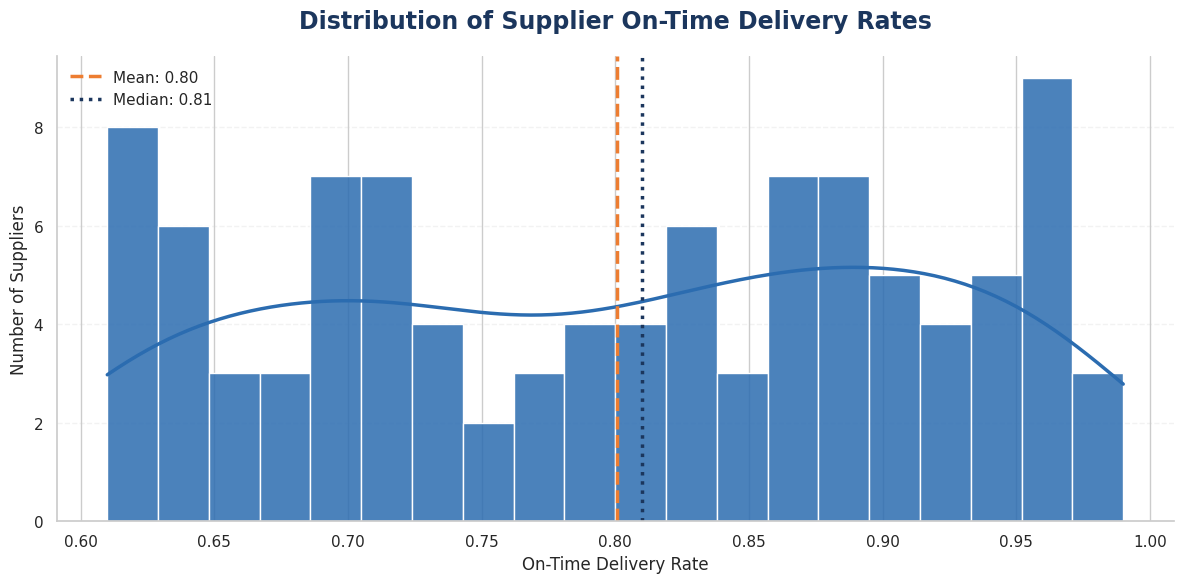

In [257]:
# ============================================================
# SUPPLIER ON-TIME DELIVERY RATE DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    data=supplier_performance_data,
    x='On_Time_Delivery_Rate',
    bins=20,
    kde=True,
    color=COLORS['secondary'],
    edgecolor='white',
    alpha=0.85,
    line_kws={
        'color': COLORS['danger'],
        'linewidth': 2.5
    }
)

plt.axvline(
    supplier_delivery_mean,
    color=COLORS['warning'],
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {supplier_delivery_mean:.2f}'
)

plt.axvline(
    supplier_delivery_median,
    color=COLORS['primary'],
    linestyle=':',
    linewidth=2.5,
    label=f'Median: {supplier_delivery_median:.2f}'
)

plt.title(
    'Distribution of Supplier On-Time Delivery Rates',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('On-Time Delivery Rate')
plt.ylabel('Number of Suppliers')

plt.legend(frameon=False)

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 7.5.3. Box Plot — Supplier Delivery Performance Spread

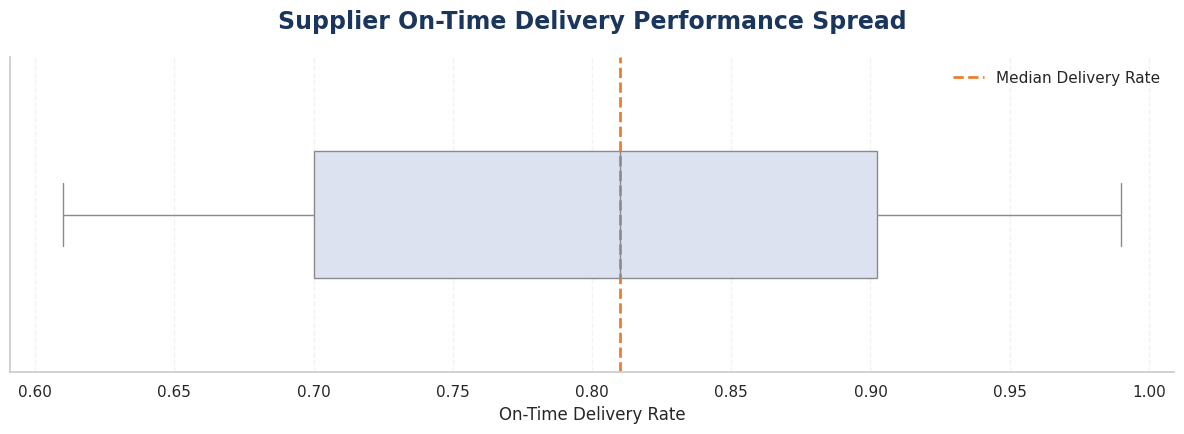

In [258]:
# ============================================================
# SUPPLIER DELIVERY PERFORMANCE SPREAD
# ============================================================

plt.figure(figsize=(12, 4.5))

sns.boxplot(
    data=supplier_performance_data,
    x='On_Time_Delivery_Rate',
    color=COLORS['light'],
    width=0.4
)

plt.axvline(
    supplier_delivery_median,
    color=COLORS['warning'],
    linestyle='--',
    linewidth=2,
    label='Median Delivery Rate'
)

plt.title(
    'Supplier On-Time Delivery Performance Spread',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('On-Time Delivery Rate')

plt.legend(frameon=False)

plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 7.5.4. Donut Chart — Preferred vs Non-Preferred Suppliers

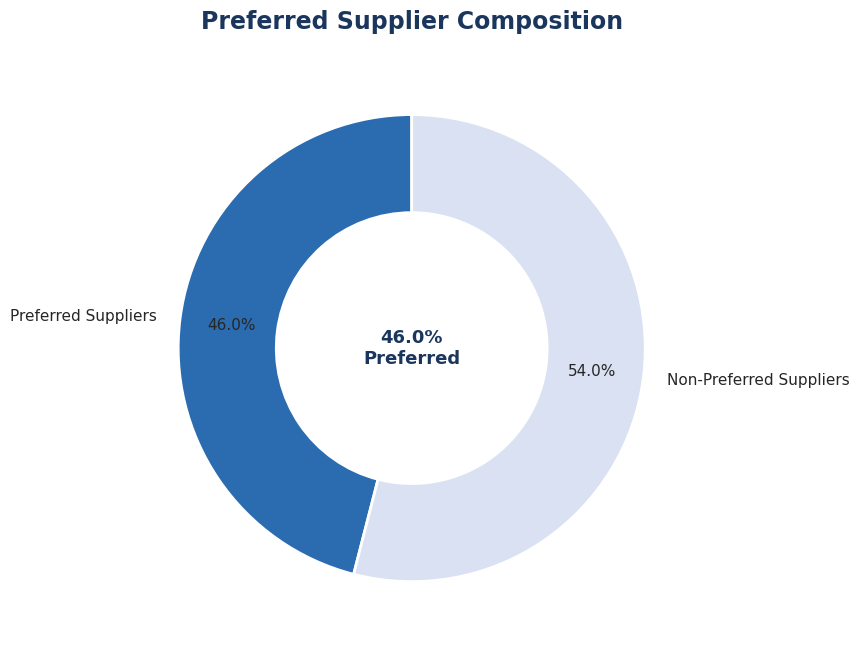

In [259]:
# ============================================================
# PREFERRED SUPPLIER PROPORTION
# ============================================================

preferred_values = [
    preferred_count,
    valid_preferred_count - preferred_count
]

preferred_labels = [
    'Preferred Suppliers',
    'Non-Preferred Suppliers'
]

plt.figure(figsize=(8, 7))

plt.pie(
    preferred_values,
    labels=preferred_labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=[
        COLORS['secondary'],
        COLORS['light']
    ],
    wedgeprops={
        'width': 0.42,
        'edgecolor': 'white',
        'linewidth': 2
    },
    pctdistance=0.78,
    textprops={
        'fontsize': 11
    }
)

plt.text(
    0,
    0,
    f'{preferred_percentage:.1f}%\nPreferred',
    ha='center',
    va='center',
    fontsize=13,
    fontweight='bold',
    color=COLORS['primary']
)

plt.title(
    'Preferred Supplier Composition',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.tight_layout()
plt.show()

## 7.6. Final Univariate Analysis Summary

In [260]:
# ============================================================
# UNIVARIATE ANALYSIS - FINAL SUMMARY
# ============================================================

univariate_summary = pd.DataFrame({

    'Analysis Area': [
        'Profitability',
        'Discount Vulnerability',
        'Delivery Risk',
        'Late Delivery Status',
        'Procurement Cost',
        'Supplier Delivery Performance',
        'Preferred Suppliers'
    ],

    'Metric': [
        'Median Profit per Order',
        'Orders Exceeding Standard Gross Margin',
        'Risk-Flagged Orders',
        'Orders with Late Status',
        'Median Procurement Cost',
        'Average Supplier On-Time Rate',
        'Preferred Supplier Percentage'
    ],

    'Value': [
        round(median_profit, 2),
        round(heavy_discount_percentage, 2),
        round(risk_percentage, 2),
        round(late_percentage, 2),
        round(median_procurement_cost, 2),
        round(supplier_delivery_mean, 2),
        round(preferred_percentage, 2)
    ],

    'Unit': [
        'Currency',
        '%',
        '%',
        '%',
        'Currency',
        'Original Rate Scale',
        '%'
    ]
})

univariate_summary.insert(
    0, 'SL.NO', range(1, len(univariate_summary) + 1)
)

styled_univariate_summary = (
    univariate_summary.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Value': '{:,.2f}'
    })

    # Subtle value shading
    .background_gradient(
        subset=['Value'],
        cmap='Blues'
    )

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 22px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Analysis Area', 'Metric'],
        **{'text-align': 'left'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 22px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Univariate Analysis Summary')
)

display(styled_univariate_summary)

SL.NO,Analysis Area,Metric,Value,Unit
1,Profitability,Median Profit per Order,240.47,Currency
2,Discount Vulnerability,Orders Exceeding Standard Gross Margin,33.08,%
3,Delivery Risk,Risk-Flagged Orders,79.57,%
4,Late Delivery Status,Orders with Late Status,79.57,%
5,Procurement Cost,Median Procurement Cost,413.31,Currency
6,Supplier Delivery Performance,Average Supplier On-Time Rate,0.80,Original Rate Scale
7,Preferred Suppliers,Preferred Supplier Percentage,46.00,%


# 8. Bivariate Analysis

## 8.1. Does supplier reliability correlate with procurement delivery delays?

### 8.1.1. Prepare Supplier Reliability Dataset

In [261]:
# ============================================================
# SUPPLIER RELIABILITY DATA PREPARATION
# ============================================================

# Convert procurement dates into datetime format
procurement_bivariate = procurement_df.copy()

procurement_bivariate['Delivery_Date_Planned'] = pd.to_datetime(
    procurement_bivariate['Delivery_Date_Planned'],
    errors='coerce'
)

procurement_bivariate['Delivery_Date_Actual'] = pd.to_datetime(
    procurement_bivariate['Delivery_Date_Actual'],
    errors='coerce'
)

# Calculate delivery variance in days
procurement_bivariate['Delivery_Variance_Days'] = (
    procurement_bivariate['Delivery_Date_Actual']
- procurement_bivariate['Delivery_Date_Planned']
).dt.days

# Calculate supplier-wise average procurement delivery variance
supplier_delay_analysis = (
    procurement_bivariate
    .groupby('Supplier_ID')
    .agg(
        Average_Delivery_Variance=(
            'Delivery_Variance_Days', 'mean'
        ),
        Total_Procurement_Orders=(
            'PO_ID', 'count'
        )
    )
    .reset_index()
)

# Merge supplier reliability information
supplier_delay_analysis = supplier_delay_analysis.merge(
    supplier_df[
        [
            'Supplier_ID',
            'Supplier_Name',
            'On_Time_Delivery_Rate'
        ]
    ],
    on='Supplier_ID',
    how='left'
)

# Remove incomplete observations
supplier_delay_analysis = supplier_delay_analysis.dropna(
    subset=[
        'On_Time_Delivery_Rate',
        'Average_Delivery_Variance'
    ]
)

print("SUPPLIER RELIABILITY ANALYSIS")
print("-" * 50)

print("Suppliers Analyzed:", len(supplier_delay_analysis))

# Format preview table professionally
supplier_preview = supplier_delay_analysis.head().copy()
supplier_preview.insert(0, 'SL.NO', range(1, len(supplier_preview) + 1))

styled_supplier_preview = (
    supplier_preview.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Average_Delivery_Variance': '{:,.2f}',
        'Total_Procurement_Orders': '{:,}',
        'On_Time_Delivery_Rate': '{:,.2f}'
    })

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Supplier_ID', 'Supplier_Name'],
        **{'text-align': 'left'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Supplier Reliability Preview (Top 5)')
)

display(styled_supplier_preview)

SUPPLIER RELIABILITY ANALYSIS
--------------------------------------------------
Suppliers Analyzed: 100


SL.NO,Supplier_ID,Average_Delivery_Variance,Total_Procurement_Orders,Supplier_Name,On_Time_Delivery_Rate
1,SUP00001,1.62,16,Beta Gamma Corp,0.75
2,SUP00002,1.00,12,Eco Gamma GmbH,0.80
3,SUP00003,2.79,24,Ultra Ultra GmbH,0.62
4,SUP00004,2.45,11,Gamma Nova LLC,0.66
5,SUP00005,1.65,26,Ultra Gamma LLC,0.89


### 8.1.2. Correlation Analysis

In [262]:
# ============================================================
# SUPPLIER RELIABILITY CORRELATION
# ============================================================

pearson_corr = supplier_delay_analysis[
    'On_Time_Delivery_Rate'
].corr(
    supplier_delay_analysis['Average_Delivery_Variance'],
    method='pearson'
)

spearman_corr = supplier_delay_analysis[
    'On_Time_Delivery_Rate'
].corr(
    supplier_delay_analysis['Average_Delivery_Variance'],
    method='spearman'
)

print("SUPPLIER CORRELATION RESULTS")
print("-" * 50)

print(f"Pearson Correlation  : {pearson_corr:.4f}")
print(f"Spearman Correlation : {spearman_corr:.4f}")

if pearson_corr < -0.5:
    print("Observation: Strong negative linear association.")

elif pearson_corr < -0.3:
    print("Observation: Moderate negative linear association.")

elif pearson_corr > 0.5:
    print("Observation: Strong positive linear association.")

elif pearson_corr > 0.3:
    print("Observation: Moderate positive linear association.")

else:
    print("Observation: Weak linear association.")

SUPPLIER CORRELATION RESULTS
--------------------------------------------------
Pearson Correlation  : 0.0526
Spearman Correlation : 0.0500
Observation: Weak linear association.


### 8.1.3. Scatter Plot — Supplier Reliability vs Delivery Variance

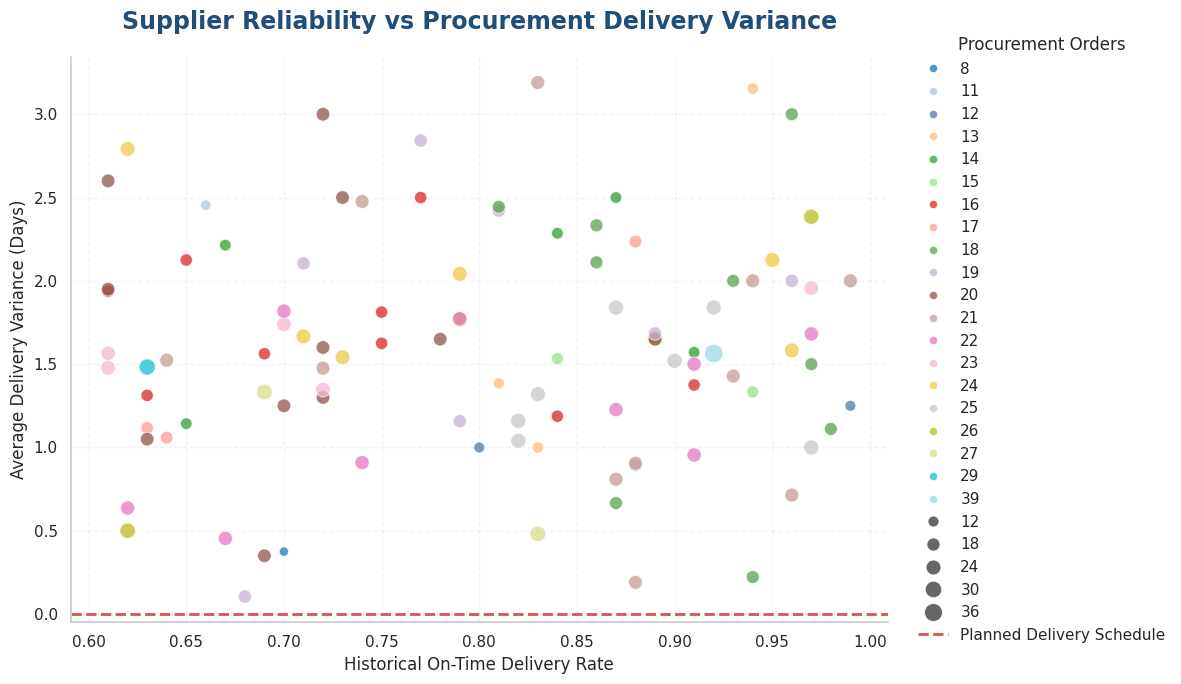

In [263]:
# ============================================================
# SUPPLIER RELIABILITY VS DELIVERY VARIANCE
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.update({
    'primary': '#1F4E78',   # Chart title
    'danger': '#D9534F'     # Planned delivery schedule reference line
})

order_palette = {
    12: '#4E79A7',
    18: '#59A14F',
    24: '#EDC948',
    30: '#F28E2B',
    36: '#B07AA1'
}

unique_orders = sorted(supplier_delay_analysis['Total_Procurement_Orders'].dropna().unique())
fallback_palette = sns.color_palette('tab20', n_colors=max(len(unique_orders), 1)).as_hex()
full_order_palette = {
    val: order_palette.get(int(val), fallback_palette[i % len(fallback_palette)])
    for i, val in enumerate(unique_orders)
}

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=supplier_delay_analysis,
    x='On_Time_Delivery_Rate',
    y='Average_Delivery_Variance',
    hue='Total_Procurement_Orders',
    palette=full_order_palette,
    size='Total_Procurement_Orders',
    sizes=(45, 180),
    alpha=0.75,
    edgecolor='white',
    linewidth=0.7
)

plt.axhline(
    0,
    color=COLORS['danger'],
    linestyle='--',
    linewidth=2,
    label='Planned Delivery Schedule'
)

plt.title(
    'Supplier Reliability vs Procurement Delivery Variance',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Historical On-Time Delivery Rate')
plt.ylabel('Average Delivery Variance (Days)')

plt.legend(
    title='Procurement Orders',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

plt.grid(linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.1.4. Regression Plot — Relationship Trend

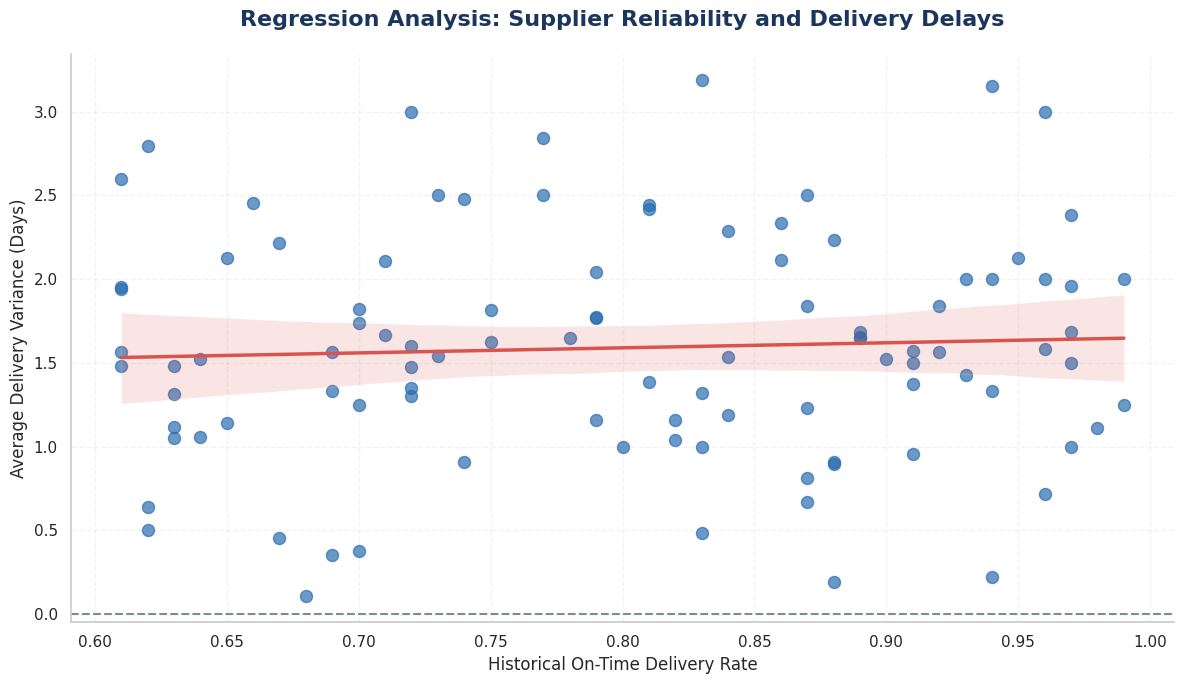

In [264]:
# ============================================================
# SUPPLIER RELIABILITY REGRESSION ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.update({
    'blue': '#2B6CB0',      # Scatter points
    'danger': '#D9534F',    # Regression trend line
    'grey': '#7F8C8D',      # Zero-variance horizontal reference line
    'primary': '#1B365D'    # Chart title
})

plt.figure(figsize=(12, 7))

sns.regplot(
    data=supplier_delay_analysis,
    x='On_Time_Delivery_Rate',
    y='Average_Delivery_Variance',
    scatter_kws={
        'color': COLORS['blue'],
        's': 75,
        'alpha': 0.7
    },
    line_kws={
        'color': COLORS['danger'],
        'linewidth': 2.5
    },
    ci=95
)

plt.axhline(
    0,
    color=COLORS['grey'],
    linestyle='--',
    linewidth=1.5
)

plt.title(
    'Regression Analysis: Supplier Reliability and Delivery Delays',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Historical On-Time Delivery Rate')
plt.ylabel('Average Delivery Variance (Days)')

plt.grid(linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.1.5. Identify Suppliers with Highest Average Delays

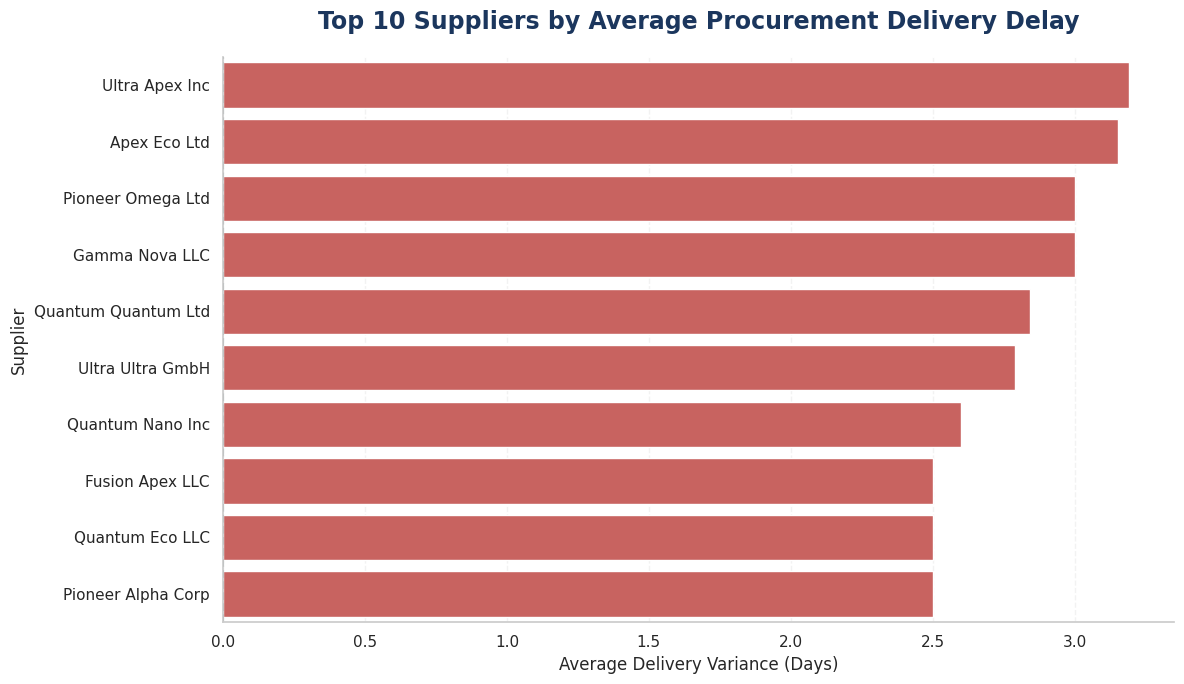

In [265]:
# ============================================================
# SUPPLIERS WITH HIGHEST DELIVERY DELAYS
# ============================================================

delayed_suppliers = (
    supplier_delay_analysis
    .sort_values(
        'Average_Delivery_Variance',
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=delayed_suppliers,
    x='Average_Delivery_Variance',
    y='Supplier_Name',
    color=COLORS['danger'],
    edgecolor='white'
)

plt.axvline(
    0,
    color=COLORS['grey'],
    linestyle='--',
    linewidth=1.5
)

plt.title(
    'Top 10 Suppliers by Average Procurement Delivery Delay',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Average Delivery Variance (Days)')
plt.ylabel('Supplier')

plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

## 8.2. Do higher discounts reduce profitability or increase cancellations?

### 8.2.1. Prepare Discount Analysis Dataset

In [266]:
# ============================================================
#  DISCOUNT IMPACT DATA PREPARATION
# ============================================================

discount_bivariate = sales_df.copy()

# Convert discount fraction to percentage
discount_bivariate['Discount_Percent'] = (
    discount_bivariate['Discount'] * 100
)

# Calculate Pearson correlation
discount_profit_pearson = (
    discount_bivariate['Discount']
    .corr(
        discount_bivariate['Profit_Per_Order'],
        method='pearson'
    )
)

# Calculate Spearman correlation
discount_profit_spearman = (
    discount_bivariate['Discount']
    .corr(
        discount_bivariate['Profit_Per_Order'],
        method='spearman'
    )
)

print("DISCOUNT AND PROFITABILITY CORRELATION")
print("-" * 50)

print(f"Pearson Correlation  : {discount_profit_pearson:.4f}")
print(f"Spearman Correlation : {discount_profit_spearman:.4f}")

DISCOUNT AND PROFITABILITY CORRELATION
--------------------------------------------------
Pearson Correlation  : -0.2539
Spearman Correlation : -0.2420


### 8.2.2. Scatter Plot — Discount vs Profitability

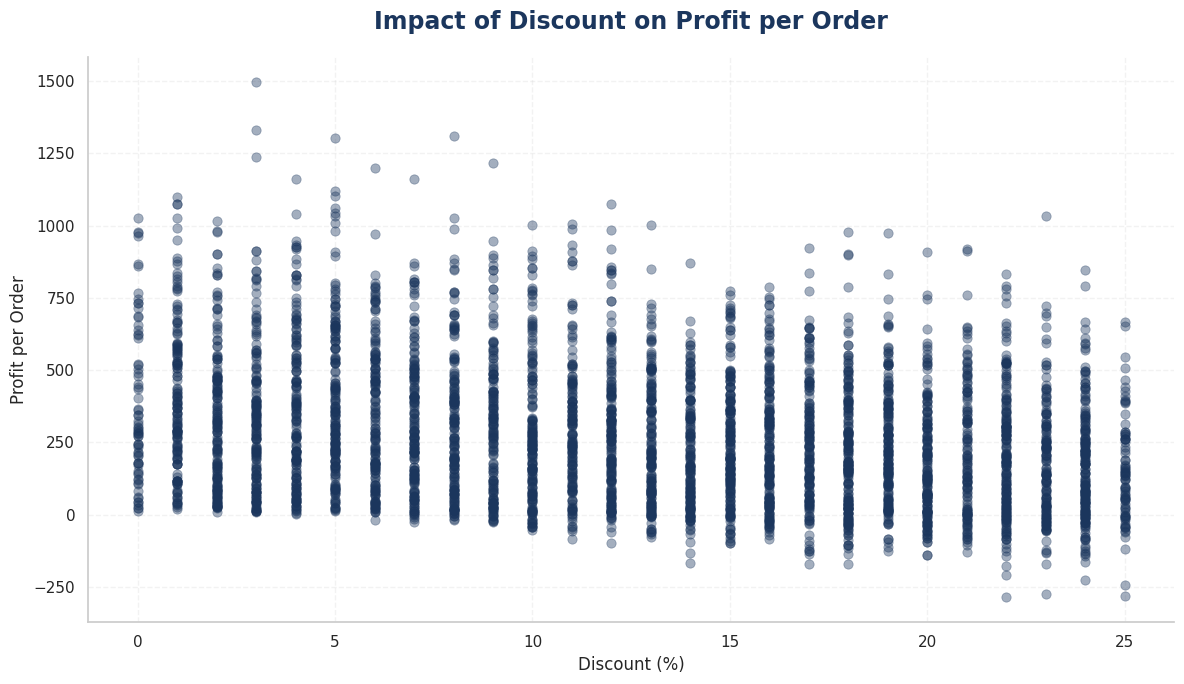

In [267]:
# ============================================================
# DISCOUNT VS PROFITABILITY
# ============================================================

scatter_data = discount_bivariate.dropna(
    subset=['Discount_Percent', 'Profit_Per_Order']
)

# Sample for better visual readability
scatter_sample = scatter_data.sample(
    min(4000, len(scatter_data)),
    random_state=42
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=scatter_sample,
    x='Discount_Percent',
    y='Profit_Per_Order',
    color=COLORS['primary'],
    alpha=0.4,
    s=45,
    edgecolor=None
)

plt.title(
    'Impact of Discount on Profit per Order',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Discount (%)')
plt.ylabel('Profit per Order')

plt.grid(linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.2.3. Regression Plot — Discount vs Profitability

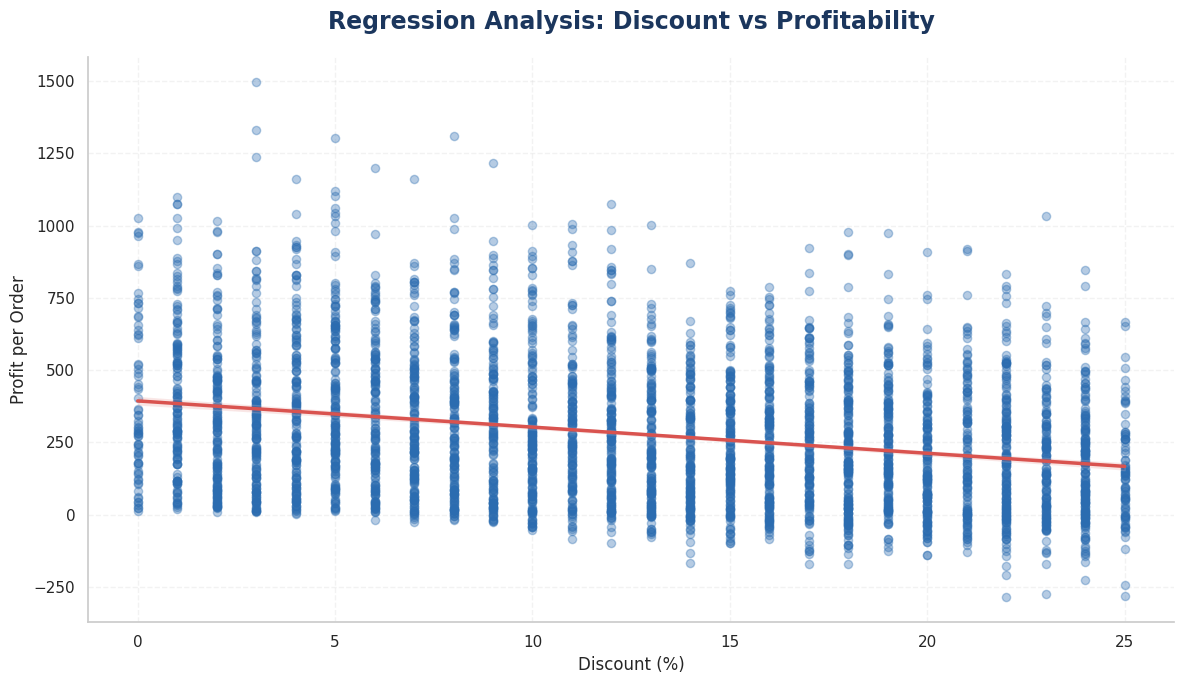

In [268]:
# ============================================================
# DISCOUNT AND PROFITABILITY REGRESSION
# ============================================================

plt.figure(figsize=(12, 7))

sns.regplot(
    data=scatter_sample,
    x='Discount_Percent',
    y='Profit_Per_Order',
    scatter_kws={
        'color': COLORS['blue'],
        'alpha': 0.35,
        's': 35
    },
    line_kws={
        'color': COLORS['danger'],
        'linewidth': 2.5
    },
    ci=95
)

plt.title(
    'Regression Analysis: Discount vs Profitability',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Discount (%)')
plt.ylabel('Profit per Order')

plt.grid(linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.2.4. Discount Categories — Prepare Groups

In [269]:
# ============================================================
# DISCOUNT CATEGORY PREPARATION
# ============================================================

discount_bivariate['Discount_Category'] = pd.cut(
    discount_bivariate['Discount'],
    bins=[
        -np.inf,
        0.05,
        0.10,
        0.20,
        0.30,
        np.inf
    ],
    labels=[
        '0–5%',
        '5–10%',
        '10–20%',
        '20–30%',
        'Above 30%'
    ],
    right=True
)

discount_summary = (
    discount_bivariate
    .groupby(
        'Discount_Category',
        observed=False
    )
    .agg(
        Total_Orders=('Order_ID', 'count'),
        Average_Profit=('Profit_Per_Order', 'mean'),
        Total_Profit=('Profit_Per_Order', 'sum'),
        Average_Order_Value=('Order_Total', 'mean'),
        Cancelled_Orders=(
            'Order_Status',
            lambda x: x.astype('string')
            .str.strip()
            .str.lower()
            .eq('cancelled')
            .sum()
        )
    )
    .reset_index()
)

discount_summary['Cancellation_Rate'] = np.where(
    discount_summary['Total_Orders'] > 0,
    (
        discount_summary['Cancelled_Orders']
        / discount_summary['Total_Orders']
    ) * 100,
    np.nan
)

# Format summary table professionally
discount_summary_display = discount_summary.copy()
discount_summary_display.insert(0, 'SL.NO', range(1, len(discount_summary_display) + 1))

styled_discount_summary = (
    discount_summary_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total_Orders': '{:,}',
        'Average_Profit': '{:,.2f}',
        'Total_Profit': '{:,.2f}',
        'Average_Order_Value': '{:,.2f}',
        'Cancelled_Orders': '{:,}',
        'Cancellation_Rate': '{:,.2f}%'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Discount_Category'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Discount Category Performance Summary')
)

display(styled_discount_summary)

SL.NO,Discount_Category,Total_Orders,Average_Profit,Total_Profit,Average_Order_Value,Cancelled_Orders,Cancellation_Rate
1,0–5%,"4,386",366.89,"1,609,186.52",862.12,224,5.11%
2,5–10%,"3,998",317.21,"1,268,220.52",804.73,195,4.88%
3,10–20%,"8,001",252.06,"2,016,769.59",750.21,425,5.31%
4,20–30%,"3,615",197.08,"712,429.13",694.94,178,4.92%
5,Above 30%,0,N/A,0.00,N/A,0,N/A


### 8.2.5. Bar Plot — Average Profit by Discount Category

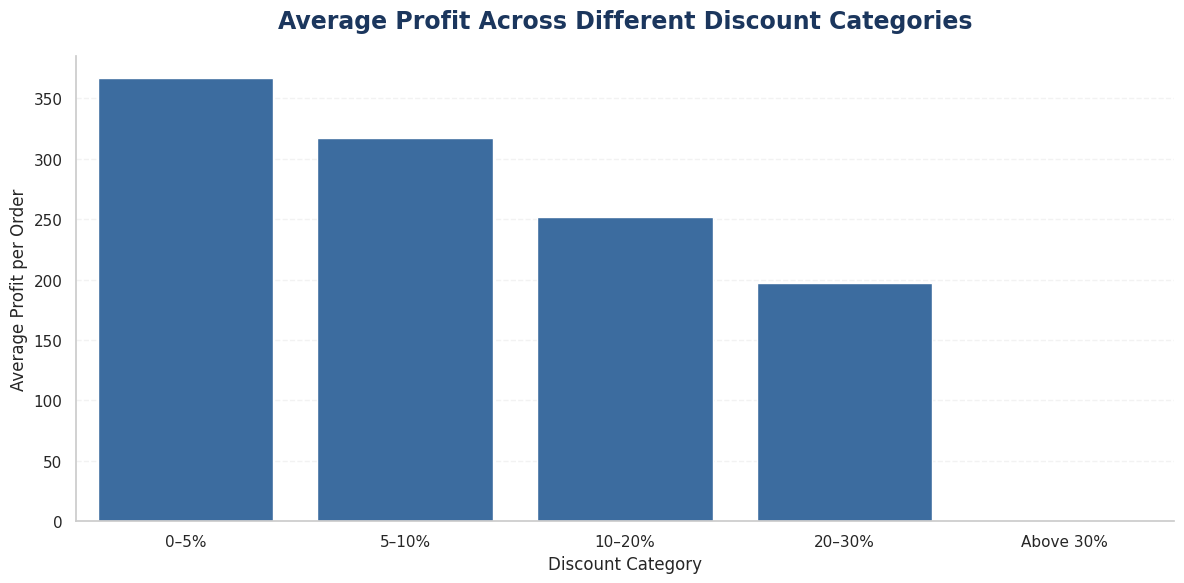

In [270]:
# ============================================================
# AVERAGE PROFIT BY DISCOUNT CATEGORY
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=discount_summary,
    x='Discount_Category',
    y='Average_Profit',
    color=COLORS['secondary'],
    edgecolor='white'
)

plt.title(
    'Average Profit Across Different Discount Categories',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Discount Category')
plt.ylabel('Average Profit per Order')

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.2.6. Bar Plot — Cancellation Rate by Discount Category

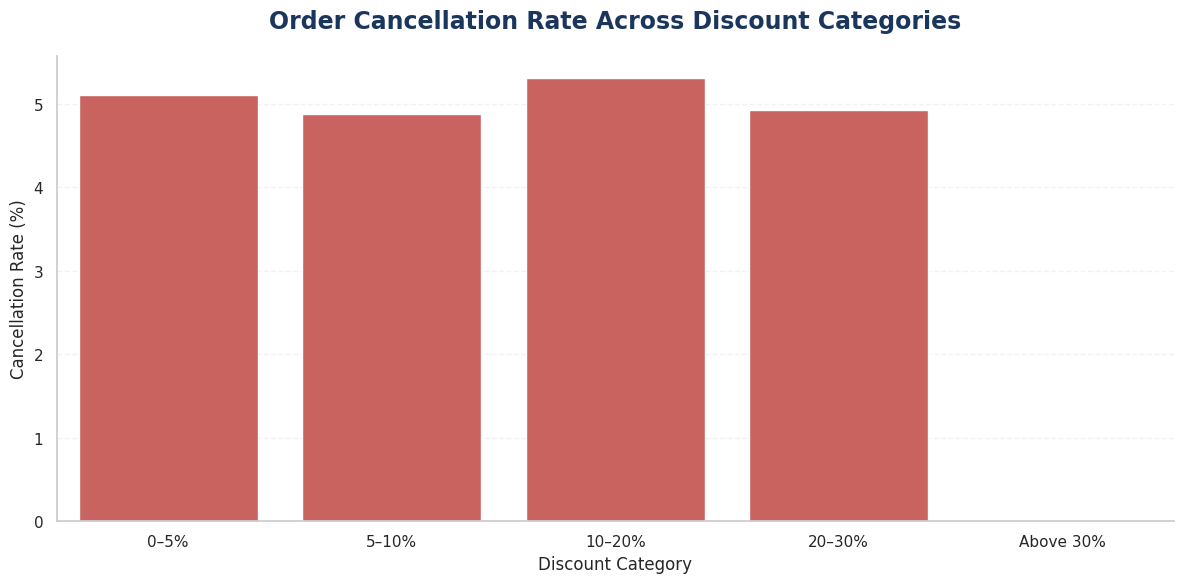

In [271]:
# ============================================================
# CANCELLATION RATE BY DISCOUNT CATEGORY
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=discount_summary,
    x='Discount_Category',
    y='Cancellation_Rate',
    color=COLORS['danger'],
    edgecolor='white'
)

plt.title(
    'Order Cancellation Rate Across Discount Categories',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Discount Category')
plt.ylabel('Cancellation Rate (%)')

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.2.7. Bar Plot — Order Volume by Discount Category

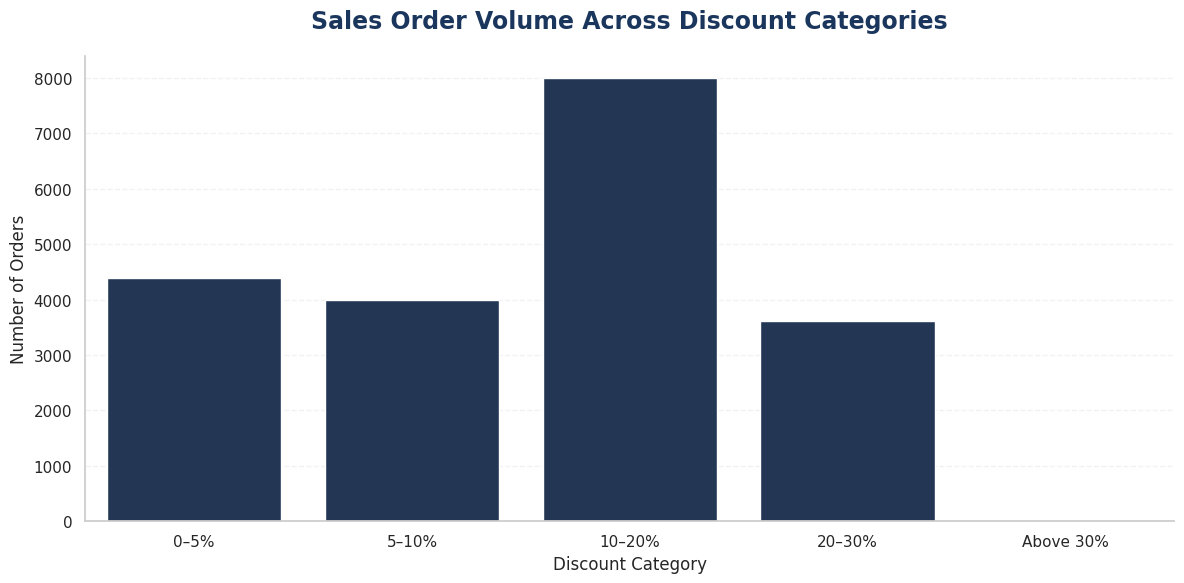

In [272]:
# ============================================================
# ORDER VOLUME BY DISCOUNT CATEGORY
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=discount_summary,
    x='Discount_Category',
    y='Total_Orders',
    color=COLORS['primary'],
    edgecolor='white'
)

plt.title(
    'Sales Order Volume Across Discount Categories',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Discount Category')
plt.ylabel('Number of Orders')

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

## 8.3. Which shipping modes and carriers experience more delivery risks?

### 8.3.1. Prepare Shipping Analysis Dataset

In [273]:
# ============================================================
# SHIPPING DATA PREPARATION
# ============================================================

shipping_analysis = sales_df.copy()

# Standardize risk flag
shipping_analysis['Risk_Flag_Clean'] = (
    shipping_analysis['Late_Delivery_Risk_Flag']
    .astype('string')
    .str.strip()
    .str.lower()
)

shipping_analysis['Risk_Flag_Binary'] = (
    shipping_analysis['Risk_Flag_Clean']
    .isin(['1', '1.0', 'true', 'yes', 'y'])
    .astype(int)
)

# Standardize delivery status
shipping_analysis['Delivery_Status_Clean'] = (
    shipping_analysis['Delivery_Status']
    .astype('string')
    .str.strip()
    .str.lower()
)

shipping_analysis['Actual_Late_Binary'] = (
    shipping_analysis['Delivery_Status_Clean']
    .eq('late')
    .astype(int)
)

# Group by shipping mode
shipping_mode_summary = (
    shipping_analysis
    .groupby('Shipping_Mode')
    .agg(
        Total_Orders=('Order_ID', 'count'),
        Risk_Flagged_Orders=('Risk_Flag_Binary', 'sum'),
        Actual_Late_Orders=('Actual_Late_Binary', 'sum')
    )
    .reset_index()
)

shipping_mode_summary['Risk_Rate'] = (
    shipping_mode_summary['Risk_Flagged_Orders']
    / shipping_mode_summary['Total_Orders']
) * 100

shipping_mode_summary['Actual_Late_Rate'] = (
    shipping_mode_summary['Actual_Late_Orders']
    / shipping_mode_summary['Total_Orders']
) * 100

# Format shipping mode summary table professionally
shipping_summary_display = shipping_mode_summary.copy()
shipping_summary_display.insert(0, 'SL.NO', range(1, len(shipping_summary_display) + 1))

styled_shipping_summary = (
    shipping_summary_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total_Orders': '{:,}',
        'Risk_Flagged_Orders': '{:,}',
        'Actual_Late_Orders': '{:,}',
        'Risk_Rate': '{:,.2f}%',
        'Actual_Late_Rate': '{:,.2f}%'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Shipping_Mode'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Shipping Mode Performance Summary')
)

display(styled_shipping_summary)

SL.NO,Shipping_Mode,Total_Orders,Risk_Flagged_Orders,Actual_Late_Orders,Risk_Rate,Actual_Late_Rate
1,Economy,"4,972","3,977","3,977",79.99%,79.99%
2,Express,"4,979","3,965","3,965",79.63%,79.63%
3,Same Day,"5,033","3,994","3,994",79.36%,79.36%
4,Standard,"5,016","3,979","3,979",79.33%,79.33%


### 8.3.2. Grouped Bar Chart — Risk by Shipping Mode

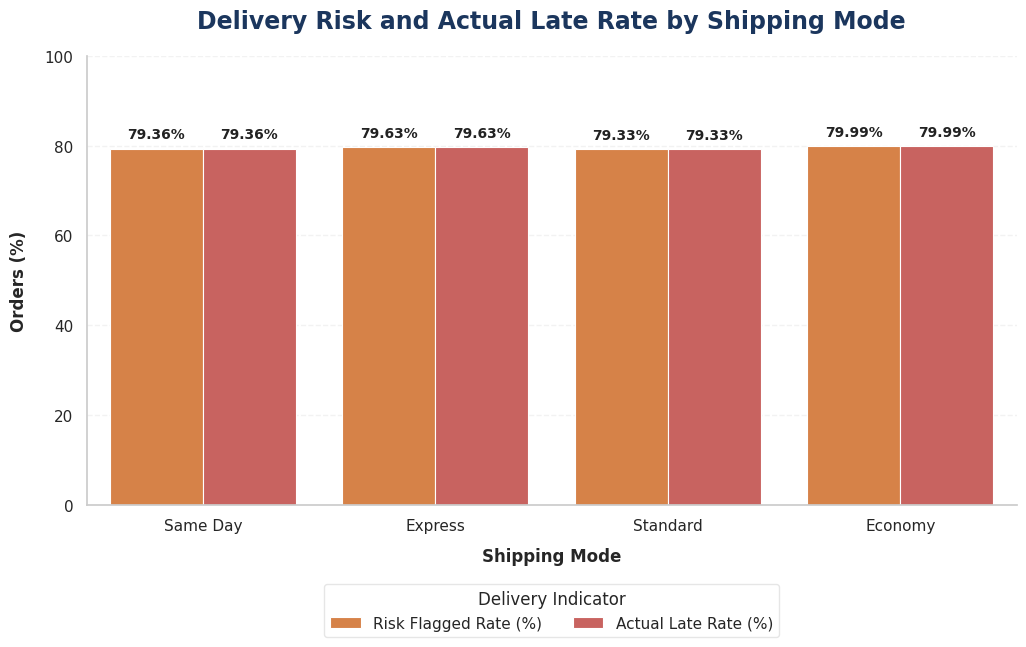

In [274]:
# ============================================================
# SHIPPING MODE VS DELIVERY RISK
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('warning', '#ED7D31')
COLORS.setdefault('danger', '#C00000')
COLORS.setdefault('primary', '#1B365D')

# Order shipping modes logically and reshape for grouped plotting
mode_order = ['Same Day', 'Express', 'Standard', 'Economy']
present_modes = [m for m in mode_order if m in shipping_mode_summary['Shipping_Mode'].values]
remaining_modes = [m for m in shipping_mode_summary['Shipping_Mode'].unique() if m not in present_modes]
ordered_modes = present_modes + remaining_modes

shipping_mode_plot = (
    shipping_mode_summary
    .set_index('Shipping_Mode')
    .loc[ordered_modes]
    .reset_index()
    .melt(
        id_vars='Shipping_Mode',
        value_vars=['Risk_Rate', 'Actual_Late_Rate'],
        var_name='Delivery Indicator',
        value_name='Percentage'
    )
)

label_map = {
    'Risk_Rate': 'Risk Flagged Rate (%)',
    'Actual_Late_Rate': 'Actual Late Rate (%)'
}
shipping_mode_plot['Delivery Indicator'] = shipping_mode_plot['Delivery Indicator'].replace(label_map)

fig, ax = plt.subplots(figsize=(12, 6.8))

sns.barplot(
    data=shipping_mode_plot,
    x='Shipping_Mode',
    y='Percentage',
    hue='Delivery Indicator',
    palette=[
        COLORS['warning'],
        COLORS['danger']
    ],
    edgecolor='white',
    linewidth=0.8,
    ax=ax
)

# Add exact percentage labels cleanly above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=5,
        fontsize=10,
        fontweight='bold',
        color='#222222'
    )

max_val = shipping_mode_plot['Percentage'].max()
ax.set_ylim(0, max(100, max_val * 1.12))

ax.set_title(
    'Delivery Risk and Actual Late Rate by Shipping Mode',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

ax.set_xlabel('Shipping Mode', labelpad=10, fontweight='bold')
ax.set_ylabel('Orders (%)', labelpad=12, fontweight='bold')

# Place legend cleanly below the chart so it never touches the title or bar labels
ax.legend(
    title='Delivery Indicator',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=True,
    facecolor='white',
    edgecolor='#E0E0E0'
)

ax.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

fig.subplots_adjust(bottom=0.22)
plt.show()

### 8.3.3. Carrier Performance Analysis

In [275]:
# ============================================================
# SHIPPING CARRIER PERFORMANCE
# ============================================================

carrier_summary = (
    shipping_analysis
    .groupby('Shipping_Carrier')
    .agg(
        Total_Orders=('Order_ID', 'count'),
        Risk_Flagged_Orders=('Risk_Flag_Binary', 'sum'),
        Actual_Late_Orders=('Actual_Late_Binary', 'sum')
    )
    .reset_index()
)

carrier_summary['Risk_Rate'] = (
    carrier_summary['Risk_Flagged_Orders']
    / carrier_summary['Total_Orders']
) * 100

carrier_summary['Actual_Late_Rate'] = (
    carrier_summary['Actual_Late_Orders']
    / carrier_summary['Total_Orders']
) * 100

carrier_summary = carrier_summary.sort_values(
    'Risk_Rate',
    ascending=False
)

# Format shipping carrier summary table professionally
carrier_summary_display = carrier_summary.copy()
carrier_summary_display.insert(0, 'SL.NO', range(1, len(carrier_summary_display) + 1))

styled_carrier_summary = (
    carrier_summary_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total_Orders': '{:,}',
        'Risk_Flagged_Orders': '{:,}',
        'Actual_Late_Orders': '{:,}',
        'Risk_Rate': '{:,.2f}%',
        'Actual_Late_Rate': '{:,.2f}%'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Shipping_Carrier'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Shipping Carrier Performance Summary')
)

display(styled_carrier_summary)

SL.NO,Shipping_Carrier,Total_Orders,Risk_Flagged_Orders,Actual_Late_Orders,Risk_Rate,Actual_Late_Rate
1,CarrierE,"3,939","3,177","3,177",80.65%,80.65%
2,CarrierD,"4,014","3,223","3,223",80.29%,80.29%
3,CarrierA,"4,074","3,252","3,252",79.82%,79.82%
4,CarrierC,"4,057","3,196","3,196",78.78%,78.78%
5,CarrierB,"3,916","3,067","3,067",78.32%,78.32%


### 8.3.4. Horizontal Bar Chart — Carrier Risk Rate

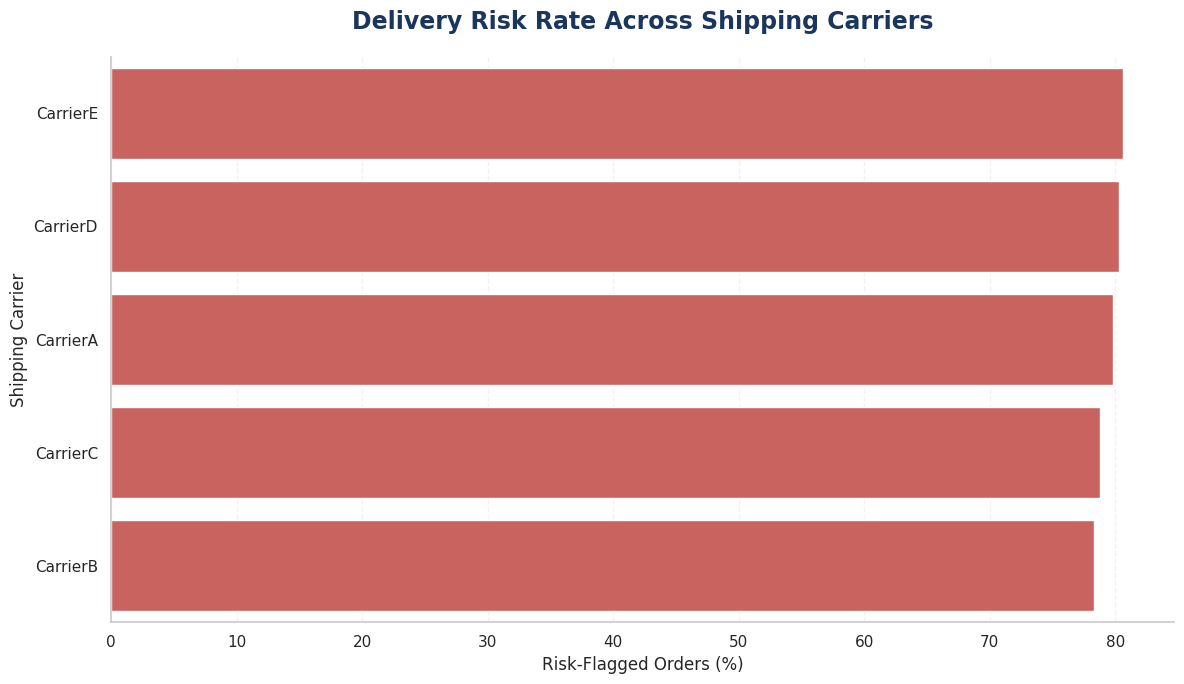

In [276]:
# ============================================================
# DELIVERY RISK BY SHIPPING CARRIER
# ============================================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=carrier_summary,
    x='Risk_Rate',
    y='Shipping_Carrier',
    color=COLORS['danger'],
    edgecolor='white'
)

plt.title(
    'Delivery Risk Rate Across Shipping Carriers',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Risk-Flagged Orders (%)')
plt.ylabel('Shipping Carrier')

plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.3.5. Heatmap — Shipping Mode vs Carrier Risk

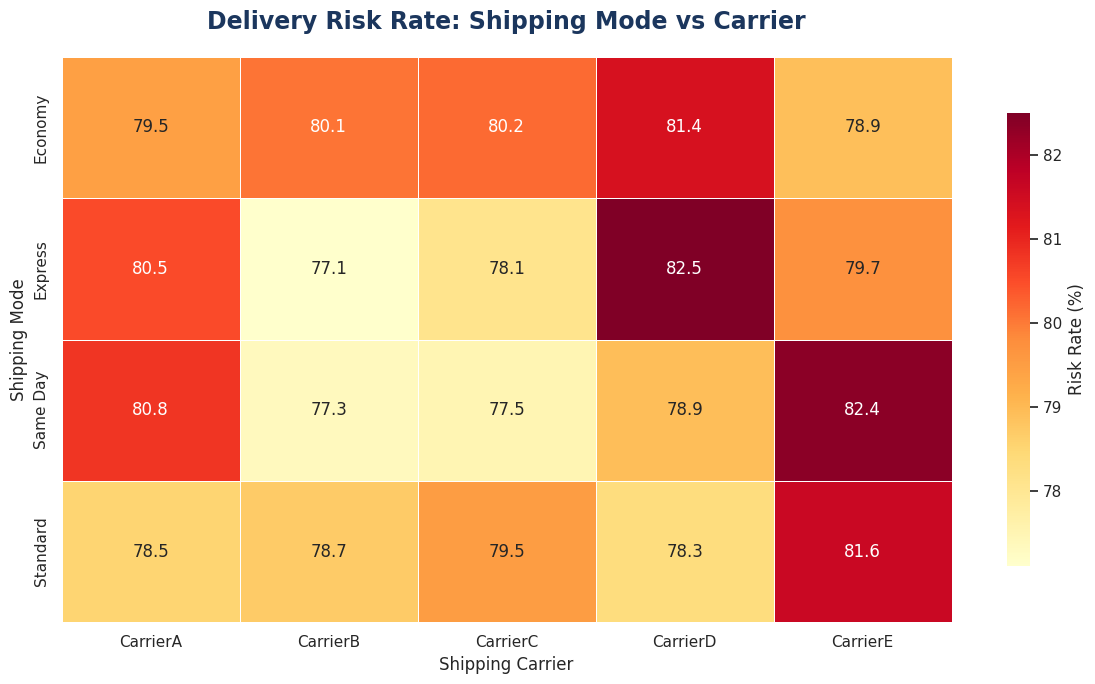

In [277]:
# ============================================================
# SHIPPING MODE VS CARRIER RISK HEATMAP
# ============================================================

shipping_heatmap = (
    shipping_analysis
    .pivot_table(
        index='Shipping_Mode',
        columns='Shipping_Carrier',
        values='Risk_Flag_Binary',
        aggfunc='mean',
        observed=False
    ) * 100
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    shipping_heatmap,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.7,
    cbar_kws={
        'label': 'Risk Rate (%)',
        'shrink': 0.8
    }
)

plt.title(
    'Delivery Risk Rate: Shipping Mode vs Carrier',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Shipping Carrier')
plt.ylabel('Shipping Mode')

plt.tight_layout()
plt.show()

## 8.4. Which market segments and industries generate more revenue and profit margin?

### 8.4.1. Prepare Customer Analysis Dataset

In [278]:
# ============================================================
# CUSTOMER SEGMENT DATA PREPARATION
# ============================================================

customer_analysis = sales_df.merge(
    customer_df[
        [
            'Customer_ID',
            'Industry',
            'Market_Segment'
        ]
    ],
    on='Customer_ID',
    how='left'
)

# Keep completed orders for realized financial analysis
customer_analysis['Order_Status_Clean'] = (
    customer_analysis['Order_Status']
    .astype('string')
    .str.strip()
    .str.lower()
)

completed_customer_analysis = customer_analysis[
    customer_analysis['Order_Status_Clean'] == 'completed'
].copy()

# Calculate order-level profit margin
completed_customer_analysis['Profit_Margin_Percent'] = np.where(
    completed_customer_analysis['Order_Total'] > 0,
    (
        completed_customer_analysis['Profit_Per_Order']
        / completed_customer_analysis['Order_Total']
    ) * 100,
    np.nan
)

print("CUSTOMER ANALYSIS")
print("-" * 45)

print(
    "Completed Sales Orders:",
    len(completed_customer_analysis)
)

print(
    "Unique Customers:",
    completed_customer_analysis['Customer_ID'].nunique()
)

CUSTOMER ANALYSIS
---------------------------------------------
Completed Sales Orders: 16980
Unique Customers: 500


### 8.4.2. Market Segment Performance

In [279]:
# ============================================================
# MARKET SEGMENT PERFORMANCE
# ============================================================

segment_summary = (
    completed_customer_analysis
    .groupby('Market_Segment')
    .agg(
        Total_Revenue=('Order_Total', 'sum'),
        Average_Order_Revenue=('Order_Total', 'mean'),
        Total_Profit=('Profit_Per_Order', 'sum'),
        Average_Profit=('Profit_Per_Order', 'mean'),
        Average_Profit_Margin=('Profit_Margin_Percent', 'mean'),
        Total_Orders=('Order_ID', 'count')
    )
    .reset_index()
)

# Format market segment summary table professionally
segment_summary_display = segment_summary.copy()
segment_summary_display.insert(0, 'SL.NO', range(1, len(segment_summary_display) + 1))

styled_segment_summary = (
    segment_summary_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total_Revenue': '{:,.2f}',
        'Average_Order_Revenue': '{:,.2f}',
        'Total_Profit': '{:,.2f}',
        'Average_Profit': '{:,.2f}',
        'Average_Profit_Margin': '{:,.2f}%',
        'Total_Orders': '{:,}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Market_Segment'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Market Segment Performance Summary')
)

display(styled_segment_summary)

SL.NO,Market_Segment,Total_Revenue,Average_Order_Revenue,Total_Profit,Average_Profit,Average_Profit_Margin,Total_Orders
1,B2B,"6,332,939.92",776.76,"2,309,631.42",283.29,37.43%,"8,153"
2,B2C,"6,870,435.13",778.34,"2,464,594.41",279.21,36.95%,"8,827"


### 8.4.3. Bar Chart — Revenue by Market Segment

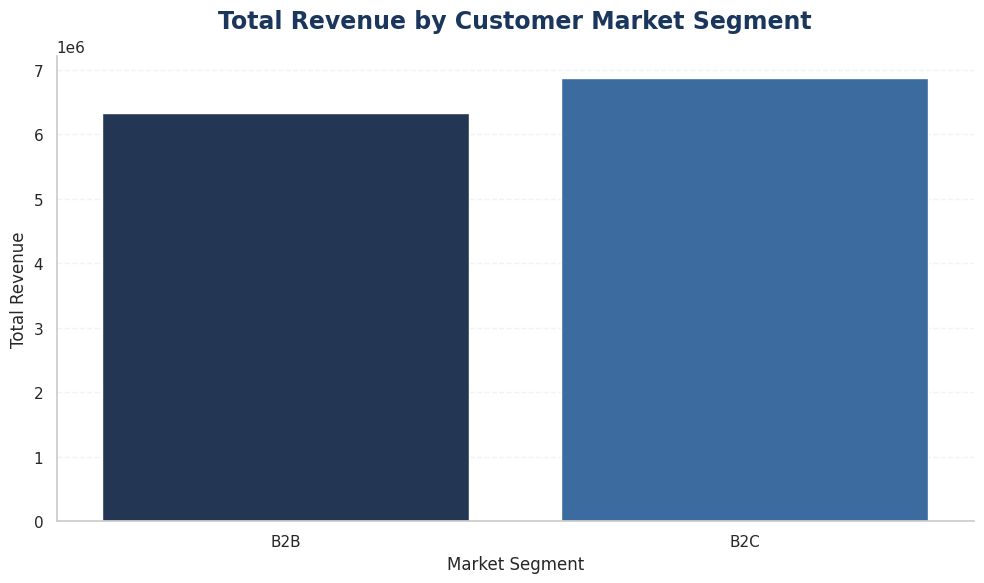

In [280]:
# ============================================================
# REVENUE BY MARKET SEGMENT
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary,
    x='Market_Segment',
    y='Total_Revenue',
    hue='Market_Segment',
    palette=[
        COLORS['primary'],
        COLORS['secondary']
    ],
    legend=False
)

plt.title(
    'Total Revenue by Customer Market Segment',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Market Segment')
plt.ylabel('Total Revenue')

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.4.4. Bar Chart — Average Profit Margin by Market Segment

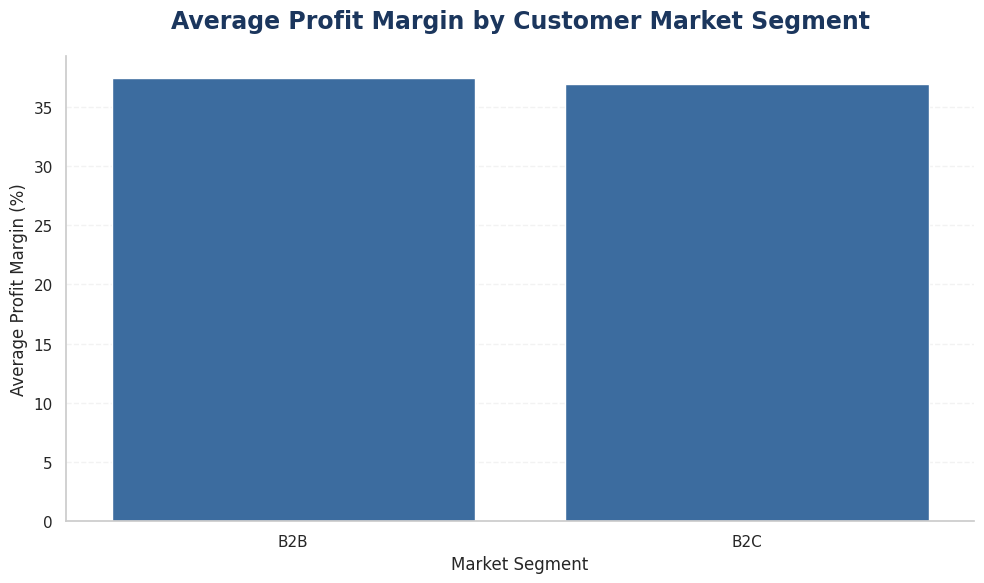

In [281]:
# ============================================================
# AVERAGE PROFIT MARGIN BY MARKET SEGMENT
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary,
    x='Market_Segment',
    y='Average_Profit_Margin',
    color=COLORS['secondary'],
    edgecolor='white'
)

plt.title(
    'Average Profit Margin by Customer Market Segment',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Market Segment')
plt.ylabel('Average Profit Margin (%)')

plt.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.4.5. Industry-Wise Revenue Analysis

In [282]:
# ============================================================
# INDUSTRY-WISE REVENUE ANALYSIS
# ============================================================

industry_summary = (
    completed_customer_analysis
    .groupby('Industry')
    .agg(
        Total_Revenue=('Order_Total', 'sum'),
        Average_Revenue=('Order_Total', 'mean'),
        Total_Profit=('Profit_Per_Order', 'sum'),
        Average_Profit_Margin=('Profit_Margin_Percent', 'mean'),
        Total_Orders=('Order_ID', 'count')
    )
    .reset_index()
    .sort_values('Total_Revenue', ascending=False)
)

# Format industry-wise revenue summary table professionally
industry_summary_display = industry_summary.copy()
industry_summary_display.insert(0, 'SL.NO', range(1, len(industry_summary_display) + 1))

styled_industry_summary = (
    industry_summary_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total_Revenue': '{:,.2f}',
        'Average_Revenue': '{:,.2f}',
        'Total_Profit': '{:,.2f}',
        'Average_Profit_Margin': '{:,.2f}%',
        'Total_Orders': '{:,}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Industry'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Industry-Wise Revenue Summary')
)

display(styled_industry_summary)

SL.NO,Industry,Total_Revenue,Average_Revenue,Total_Profit,Average_Profit_Margin,Total_Orders
1,Healthcare,"2,195,514.02",777.45,"803,642.07",37.36%,"2,824"
2,Education,"2,015,470.95",777.27,"724,666.05",36.93%,"2,593"
3,Manufacturing,"1,907,408.92",778.85,"709,739.65",38.59%,"2,449"
4,Telecom,"1,850,706.65",768.89,"663,451.63",36.90%,"2,407"
5,Finance,"1,767,811.98",779.12,"649,115.51",37.80%,"2,269"
6,IT,"1,743,602.90",791.83,"609,901.24",36.08%,"2,202"
7,Retail,"1,722,859.65",770.51,"613,709.70",36.44%,"2,236"


### 8.4.6. Horizontal Bar Chart — Top Industries by Revenue

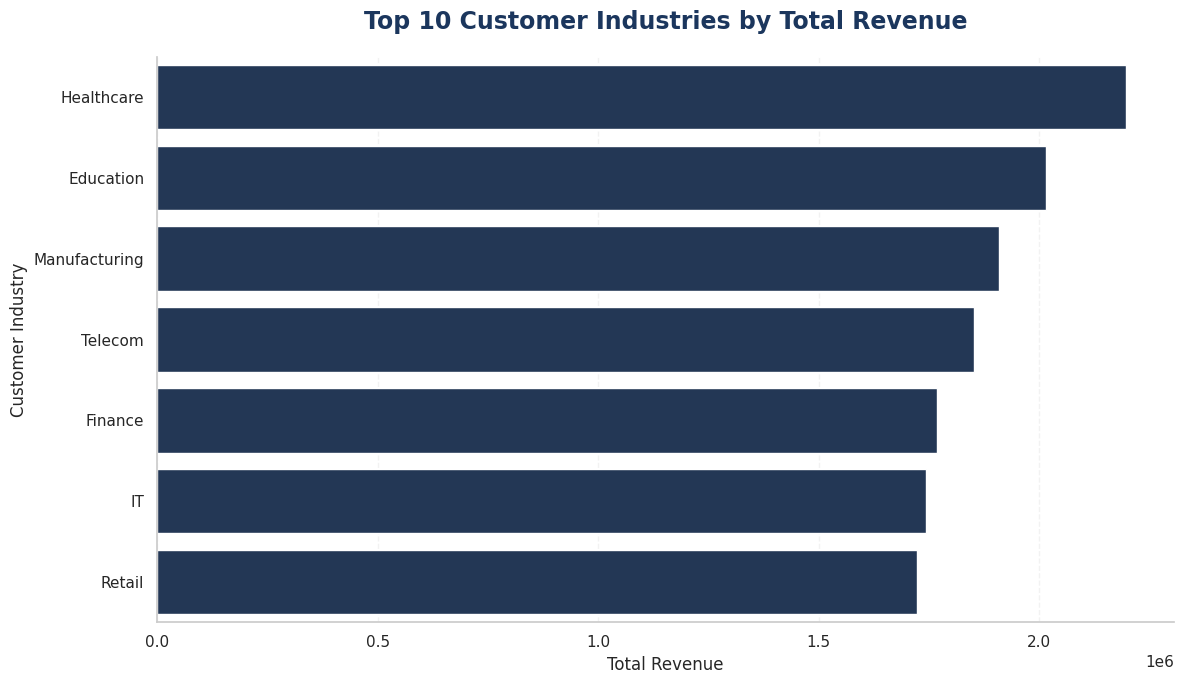

In [283]:
# ============================================================
# TOP INDUSTRIES BY REVENUE
# ============================================================

top_industries = industry_summary.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_industries,
    x='Total_Revenue',
    y='Industry',
    color=COLORS['primary'],
    edgecolor='white'
)

plt.title(
    'Top 10 Customer Industries by Total Revenue',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Total Revenue')
plt.ylabel('Customer Industry')

plt.grid(axis='x', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.4.7. Heatmap — Industry vs Market Segment Profit Margin

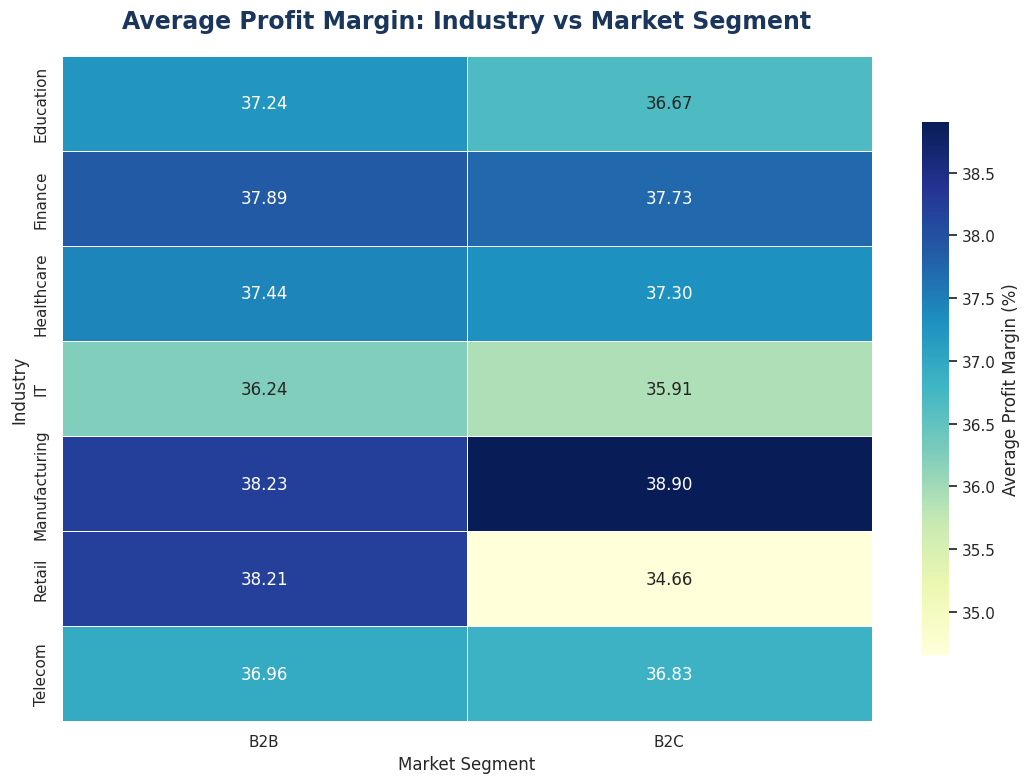

In [284]:
# ============================================================
# INDUSTRY VS MARKET SEGMENT PROFIT MARGIN
# ============================================================

industry_segment_heatmap = (
    completed_customer_analysis
    .pivot_table(
        index='Industry',
        columns='Market_Segment',
        values='Profit_Margin_Percent',
        aggfunc='mean'
    )
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    industry_segment_heatmap,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.7,
    cbar_kws={
        'label': 'Average Profit Margin (%)',
        'shrink': 0.8
    }
)

plt.title(
    'Average Profit Margin: Industry vs Market Segment',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Market Segment')
plt.ylabel('Industry')

plt.tight_layout()
plt.show()

## 8.5. How do standard selling prices scale against unit costs across product categories?

### 8.5.1. Prepare Product Pricing Dataset

In [285]:
# ============================================================
# PRODUCT PRICING DATA PREPARATION
# ============================================================

product_pricing = product_df.dropna(
    subset=[
        'Unit_Cost',
        'Standard_Price',
        'Category'
    ]
).copy()

# Calculate standard gross profit per unit
product_pricing['Standard_Gross_Profit'] = (
    product_pricing['Standard_Price']
- product_pricing['Unit_Cost']
)

# Calculate standard gross margin percentage
product_pricing['Standard_Gross_Margin_Percent'] = np.where(
    product_pricing['Standard_Price'] > 0,
    (
        product_pricing['Standard_Gross_Profit']
        / product_pricing['Standard_Price']
    ) * 100,
    np.nan
)

# Calculate correlation
price_cost_correlation = (
    product_pricing['Unit_Cost']
    .corr(
        product_pricing['Standard_Price'],
        method='pearson'
    )
)

print("PRODUCT PRICING ANALYSIS")
print("-" * 45)

print(f"Products Analyzed       : {len(product_pricing)}")
print(f"Price-Cost Correlation  : {price_cost_correlation:.4f}")
print(
    "Average Standard Margin:",
    f"{product_pricing['Standard_Gross_Margin_Percent'].mean():.2f}%"
)

# Format product pricing preview table professionally
pricing_preview_display = (
    product_pricing[
        [
            'Product_ID',
            'Category',
            'Unit_Cost',
            'Standard_Price',
            'Standard_Gross_Margin_Percent'
        ]
    ]
    .head()
    .copy()
)
pricing_preview_display.insert(0, 'SL.NO', range(1, len(pricing_preview_display) + 1))

styled_pricing_preview = (
    pricing_preview_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Unit_Cost': '{:,.2f}',
        'Standard_Price': '{:,.2f}',
        'Standard_Gross_Margin_Percent': '{:,.2f}%'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Product_ID', 'Category'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Product Pricing Preview (Top 5)')
)

display(styled_pricing_preview)

PRODUCT PRICING ANALYSIS
---------------------------------------------
Products Analyzed       : 200
Price-Cost Correlation  : -0.0183
Average Standard Margin: 0.35%


SL.NO,Product_ID,Category,Unit_Cost,Standard_Price,Standard_Gross_Margin_Percent
1,PROD00001,Food,131.74,198.31,33.57%
2,PROD00002,Beauty,141.88,339.56,58.22%
3,PROD00003,Sport,160.18,187.85,14.73%
4,PROD00004,Food,178.55,224.00,20.29%
5,PROD00005,Home,70.91,246.55,71.24%


### 8.5.2. Scatter Plot — Unit Cost vs Standard Selling Price

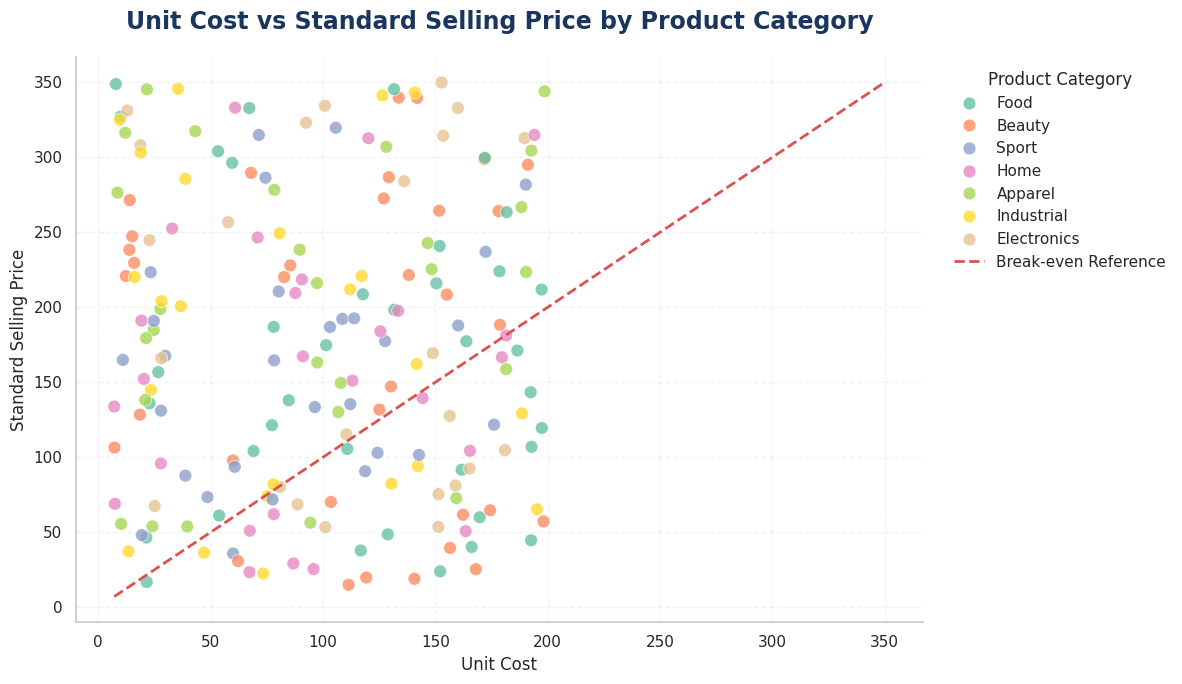

In [286]:
# ============================================================
# UNIT COST VS STANDARD SELLING PRICE
# ============================================================

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=product_pricing,
    x='Unit_Cost',
    y='Standard_Price',
    hue='Category',
    palette='Set2',
    s=85,
    alpha=0.8,
    edgecolor='white',
    linewidth=0.5
)

# Reference line: Selling price equals unit cost
axis_min = min(
    product_pricing['Unit_Cost'].min(),
    product_pricing['Standard_Price'].min()
)

axis_max = max(
    product_pricing['Unit_Cost'].max(),
    product_pricing['Standard_Price'].max()
)

plt.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    color=COLORS['danger'],
    linestyle='--',
    linewidth=2,
    label='Break-even Reference'
)

plt.title(
    'Unit Cost vs Standard Selling Price by Product Category',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Unit Cost')
plt.ylabel('Standard Selling Price')

plt.legend(
    title='Product Category',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=False
)

plt.grid(linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.5.3. Regression Plot — Overall Price-Cost Relationship

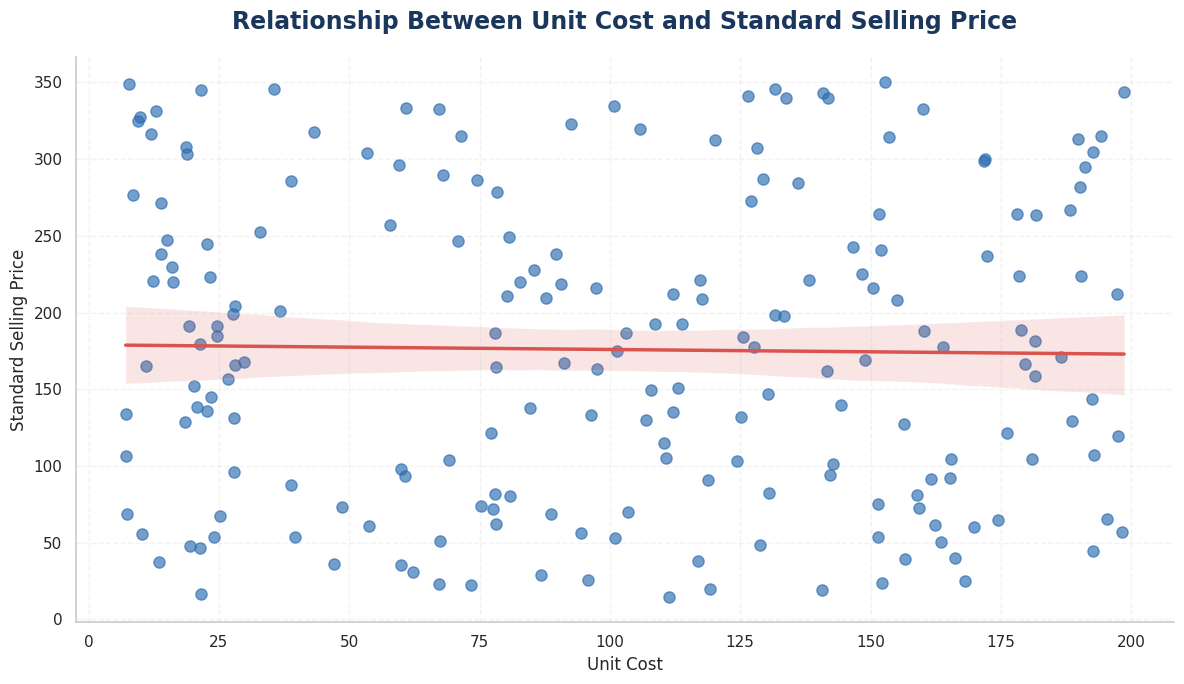

In [287]:
# ============================================================
# PRICE-COST REGRESSION ANALYSIS
# ============================================================

plt.figure(figsize=(12, 7))

sns.regplot(
    data=product_pricing,
    x='Unit_Cost',
    y='Standard_Price',
    scatter_kws={
        'color': COLORS['blue'],
        's': 65,
        'alpha': 0.65
    },
    line_kws={
        'color': COLORS['danger'],
        'linewidth': 2.5
    },
    ci=95
)

plt.title(
    'Relationship Between Unit Cost and Standard Selling Price',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xlabel('Unit Cost')
plt.ylabel('Standard Selling Price')

plt.grid(linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

### 8.5.4. Bar Chart — Average Gross Margin by Product Category

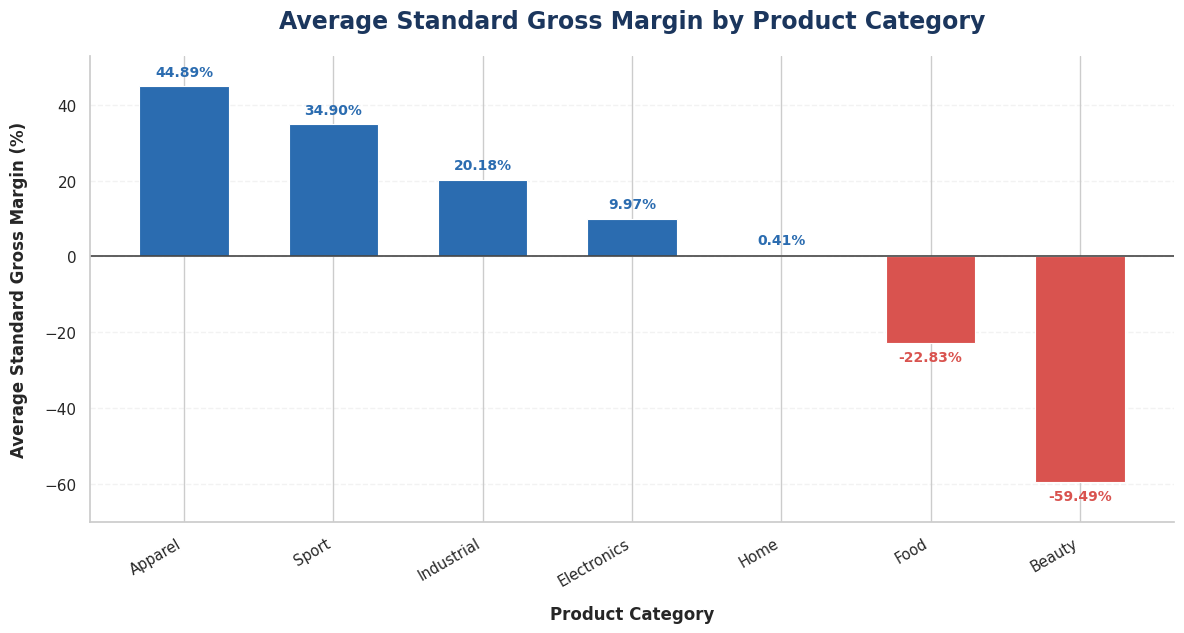

In [288]:
# ============================================================
# PRODUCT CATEGORY-WISE GROSS MARGIN
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('danger', '#C00000')

category_margin = (
    product_pricing
    .groupby('Category')
    .agg(
        Average_Unit_Cost=('Unit_Cost', 'mean'),
        Average_Standard_Price=('Standard_Price', 'mean'),
        Average_Gross_Margin=(
            'Standard_Gross_Margin_Percent', 'mean'
        )
    )
    .reset_index()
    .sort_values(
        'Average_Gross_Margin',
        ascending=False
    )
)

# Color positive margins in secondary/slate-blue and negative margins in danger/crimson
bar_colors = [
    COLORS['secondary'] if val >= 0 else COLORS['danger']
    for val in category_margin['Average_Gross_Margin']
]

fig, ax = plt.subplots(figsize=(12, 6.5))

bars = ax.bar(
    category_margin['Category'],
    category_margin['Average_Gross_Margin'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.8,
    width=0.6
)

# Zero baseline for positive vs negative gross margins
ax.axhline(
    0,
    color='#444444',
    linestyle='-',
    linewidth=1.2
)

# Add value labels above positive bars and below negative bars
for bar, val in zip(bars, category_margin['Average_Gross_Margin']):
    if val >= 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + 2.0,
            f'{val:.2f}%',
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold',
            color=COLORS['secondary']
        )
    else:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val - 2.0,
            f'{val:.2f}%',
            ha='center',
            va='top',
            fontsize=10,
            fontweight='bold',
            color=COLORS['danger']
        )

min_val = category_margin['Average_Gross_Margin'].min()
max_val = category_margin['Average_Gross_Margin'].max()
ax.set_ylim(min(0, min_val) * 1.18, max(0, max_val) * 1.18)

ax.set_title(
    'Average Standard Gross Margin by Product Category',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

ax.set_xlabel('Product Category', labelpad=12, fontweight='bold')
ax.set_ylabel('Average Standard Gross Margin (%)', labelpad=12, fontweight='bold')

plt.xticks(rotation=30, ha='right', fontsize=10.5)
ax.grid(axis='y', linestyle='--', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

## 8.6. Final Bivariate Analysis Summary

In [289]:
# ============================================================
# BIVARIATE ANALYSIS - FINAL SUMMARY
# ============================================================

# Identify highest revenue segment
best_revenue_segment = (
    segment_summary
    .sort_values('Total_Revenue', ascending=False)
    .iloc[0]
)

# Identify highest average margin segment
best_margin_segment = (
    segment_summary
    .sort_values('Average_Profit_Margin', ascending=False)
    .iloc[0]
)

# Identify highest revenue industry
best_revenue_industry = (
    industry_summary
    .sort_values('Total_Revenue', ascending=False)
    .iloc[0]
)

# Identify highest margin category
best_margin_category = (
    category_margin
    .sort_values('Average_Gross_Margin', ascending=False)
    .iloc[0]
)

# Identify highest delivery risk shipping mode
highest_risk_mode = (
    shipping_mode_summary
    .sort_values('Risk_Rate', ascending=False)
    .iloc[0]
)

bivariate_summary = pd.DataFrame({

    'Analysis Area': [
        'Supplier Reliability vs Procurement Delays',
        'Discount vs Profitability',
        'Shipping Mode vs Delivery Risk',
        'Customer Segment Revenue',
        'Customer Segment Profit Margin',
        'Industry Revenue',
        'Product Pricing'
    ],

    'Key Metric': [
        'Pearson Correlation',
        'Pearson Correlation',
        'Highest Risk Shipping Mode',
        'Highest Revenue Segment',
        'Highest Average Margin Segment',
        'Highest Revenue Industry',
        'Highest Average Margin Category'
    ],

    'Result': [
        round(pearson_corr, 4),
        round(discount_profit_pearson, 4),
        highest_risk_mode['Shipping_Mode'],
        best_revenue_segment['Market_Segment'],
        best_margin_segment['Market_Segment'],
        best_revenue_industry['Industry'],
        best_margin_category['Category']
    ]
})

bivariate_summary_display = bivariate_summary.copy()
bivariate_summary_display.insert(0, 'SL.NO', range(1, len(bivariate_summary_display) + 1))

styled_bivariate_summary = (
    bivariate_summary_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Result': lambda x: f'{x:.4f}' if isinstance(x, (int, float, np.floating)) else str(x)
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 22px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Analysis Area', 'Key Metric'],
        **{'text-align': 'left'}
    )
    .set_properties(
        subset=['Result'],
        **{'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 22px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Bivariate Analysis Summary')
)

display(styled_bivariate_summary)

SL.NO,Analysis Area,Key Metric,Result
1,Supplier Reliability vs Procurement Delays,Pearson Correlation,0.0526
2,Discount vs Profitability,Pearson Correlation,-0.2539
3,Shipping Mode vs Delivery Risk,Highest Risk Shipping Mode,Economy
4,Customer Segment Revenue,Highest Revenue Segment,B2C
5,Customer Segment Profit Margin,Highest Average Margin Segment,B2B
6,Industry Revenue,Highest Revenue Industry,Healthcare
7,Product Pricing,Highest Average Margin Category,Apparel


# 9. Multivariate Data Analysis

## 9.1. Analytical Questions

**Q1. Supplier, Category, and Procurement Cost Interactions:** How do Supplier_Name, product Category, and raw material Unit_Cost combine to dictate overall procurement expenditure and margin health ?

**Q2. Customer Location, Shipping Mode, and Delivery Risk:** Across different geographic regions (Country, City) and Shipping_Mode options, how do order quantities and shipping carrier choices jointly drive late delivery risks ?

**Q3. Product Margin and Discount Matrix:** How do product Category, Unit_Cost, and sales Discount levels interact to determine net profitability across different B2B and B2C market segments ?

**Q4. Procurement Fulfillment Bottlenecks:** How do procurement order quantities, supplier Certification_Level, and planned lead times interact to cause supply chain fulfillment variances ?


## 9.2. Data Preparation

In [290]:
# ============================================================
# MULTIVARIATE ANALYSIS - DATA PREPARATION
# ============================================================

# ------------------------------------------------------------
# A. Prepare Sales Analysis Dataset
# ------------------------------------------------------------

# Check any available sales DataFrame in globals, or load from CSV if needed
candidate_sales_vars = [
    'sales_multi',
    'sales_analysis',
    'shipping_analysis',
    'discount_bivariate',
    'completed_customer_analysis',
    'sales_df',
    'orders_df'
]

found_sales_var = next((v for v in candidate_sales_vars if v in globals()), None)

if found_sales_var is not None:
    sales_multi = globals()[found_sales_var].copy()
else:
    import glob
    import os

    sales_files = [
        f for f in glob.glob('*.csv')
        if 'sale' in os.path.basename(f).lower() or 'order' in os.path.basename(f).lower()
    ]
    if sales_files:
        sales_multi = pd.read_csv(sales_files[0])
    else:
        raise NameError(
            "No sales DataFrame found in memory (checked: "
            + ", ".join(candidate_sales_vars)
            + "). Please run your data loading cell first."
        )

# Ensure date columns are datetime
if 'Order_Date' in sales_multi.columns:
    sales_multi['Order_Date'] = pd.to_datetime(
        sales_multi['Order_Date'],
        errors='coerce'
    )

# Convert discount fraction into percentage
if 'Discount_Percent' not in sales_multi.columns and 'Discount' in sales_multi.columns:
    sales_multi['Discount_Percent'] = sales_multi['Discount'] * 100

# Calculate profit margin safely
if 'Profit_Margin_Percent' not in sales_multi.columns and {'Order_Total', 'Profit_Per_Order'}.issubset(sales_multi.columns):
    sales_multi['Profit_Margin_Percent'] = np.where(
        sales_multi['Order_Total'] > 0,
        (sales_multi['Profit_Per_Order'] / sales_multi['Order_Total']) * 100,
        np.nan
    )

# Standardize delivery risk flag
if 'Late_Delivery_Risk_Flag' in sales_multi.columns:
    risk_values = (
        sales_multi['Late_Delivery_Risk_Flag']
        .astype(str)
        .str.strip()
        .str.lower()
    )
    sales_multi['Late_Risk_Binary'] = risk_values.isin(
        ['1', '1.0', 'true', 'yes', 'y']
    ).astype(int)

# Standardize delivery status
if 'Delivery_Status' in sales_multi.columns:
    delivery_values = (
        sales_multi['Delivery_Status']
        .astype(str)
        .str.strip()
        .str.lower()
    )
    sales_multi['Actual_Late_Binary'] = (
        delivery_values == 'late'
    ).astype(int)


# ------------------------------------------------------------
# B. Prepare Procurement Analysis Dataset
# ------------------------------------------------------------

if 'procurement_df' in globals() and 'supplier_df' in globals():
    procurement_multi = procurement_df.merge(
        supplier_df,
        on='Supplier_ID',
        how='left'
    )
elif 'procurement_df' in globals():
    procurement_multi = procurement_df.copy()
else:
    raise NameError("`procurement_df` is not defined. Please run your data loading cell first.")

# Convert procurement dates
procurement_date_columns = [
    'Order_Date',
    'Delivery_Date_Planned',
    'Delivery_Date_Actual'
]

for column in procurement_date_columns:
    if column in procurement_multi.columns:
        procurement_multi[column] = pd.to_datetime(
            procurement_multi[column],
            errors='coerce'
        )

# Calculate planned lead time
if {'Delivery_Date_Planned', 'Order_Date'}.issubset(procurement_multi.columns):
    procurement_multi['Planned_Lead_Time_Days'] = (
        procurement_multi['Delivery_Date_Planned'] -
        procurement_multi['Order_Date']
    ).dt.days

# Calculate actual lead time
if {'Delivery_Date_Actual', 'Order_Date'}.issubset(procurement_multi.columns):
    procurement_multi['Actual_Lead_Time_Days'] = (
        procurement_multi['Delivery_Date_Actual'] -
        procurement_multi['Order_Date']
    ).dt.days

# Calculate delivery variance
if {'Delivery_Date_Actual', 'Delivery_Date_Planned'}.issubset(procurement_multi.columns):
    procurement_multi['Delivery_Variance_Days'] = (
        procurement_multi['Delivery_Date_Actual'] -
        procurement_multi['Delivery_Date_Planned']
    ).dt.days

# Positive variance = late delivery
# Negative variance = early delivery


print("Multivariate analysis datasets prepared successfully.")
print("Sales records:", len(sales_multi))
print("Procurement records:", len(procurement_multi))

Multivariate analysis datasets prepared successfully.
Sales records: 20000
Procurement records: 2000


## 9.3. Correlation Heatmap

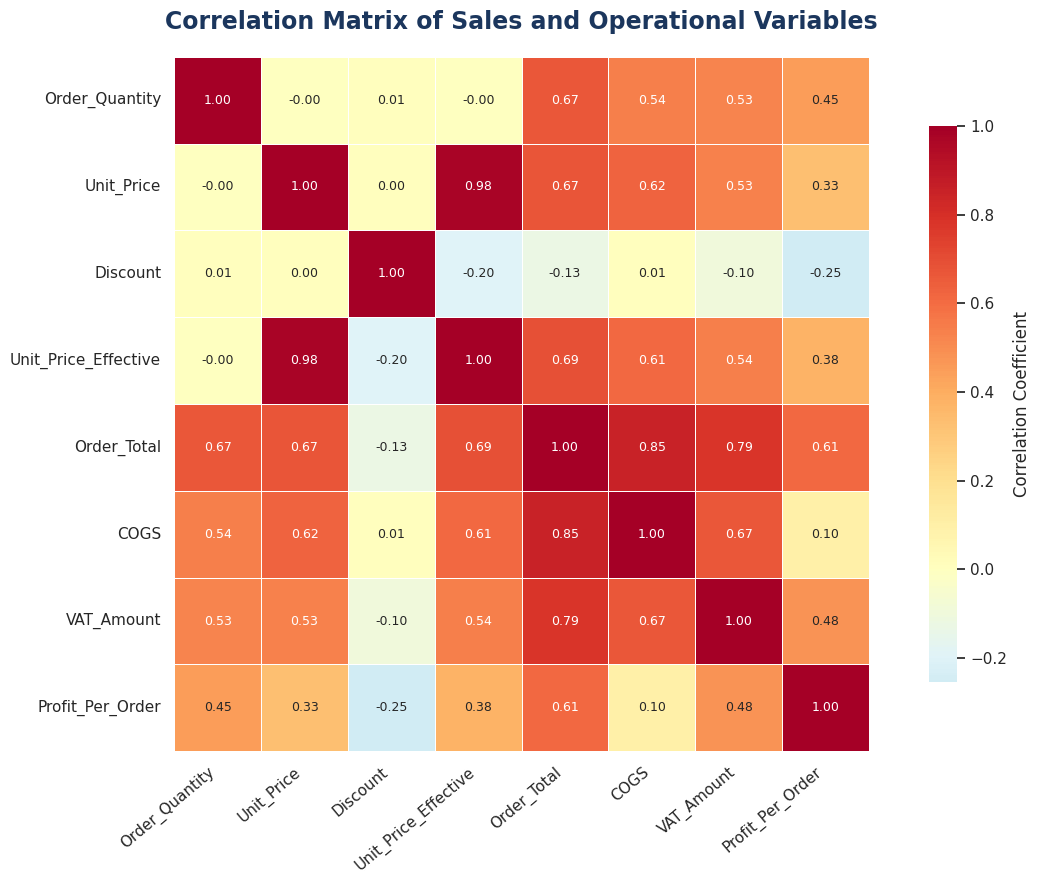

In [291]:
# ============================================================
# CORRELATION HEATMAP
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')

correlation_columns = [
    'Order_Quantity',
    'Unit_Price',
    'Discount',
    'Unit_Price_Effective',
    'Order_Total',
    'COGS',
    'VAT_Amount',
    'Profit_Per_Order',
    'Shipping_Variance_Days'
]

# Retain only available columns
correlation_columns = [
    col for col in correlation_columns
    if col in sales_multi.columns
]

correlation_matrix = (
    sales_multi[correlation_columns]
    .corr(method='pearson')
)

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu_r',
    center=0,
    linewidths=0.7,
    square=True,
    cbar_kws={
        'shrink': 0.8,
        'label': 'Correlation Coefficient'
    },
    annot_kws={'size': 9}
)

plt.title(
    'Correlation Matrix of Sales and Operational Variables',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=20
)

plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## 9.4. Pair Plot — Multiple Numerical Relationships

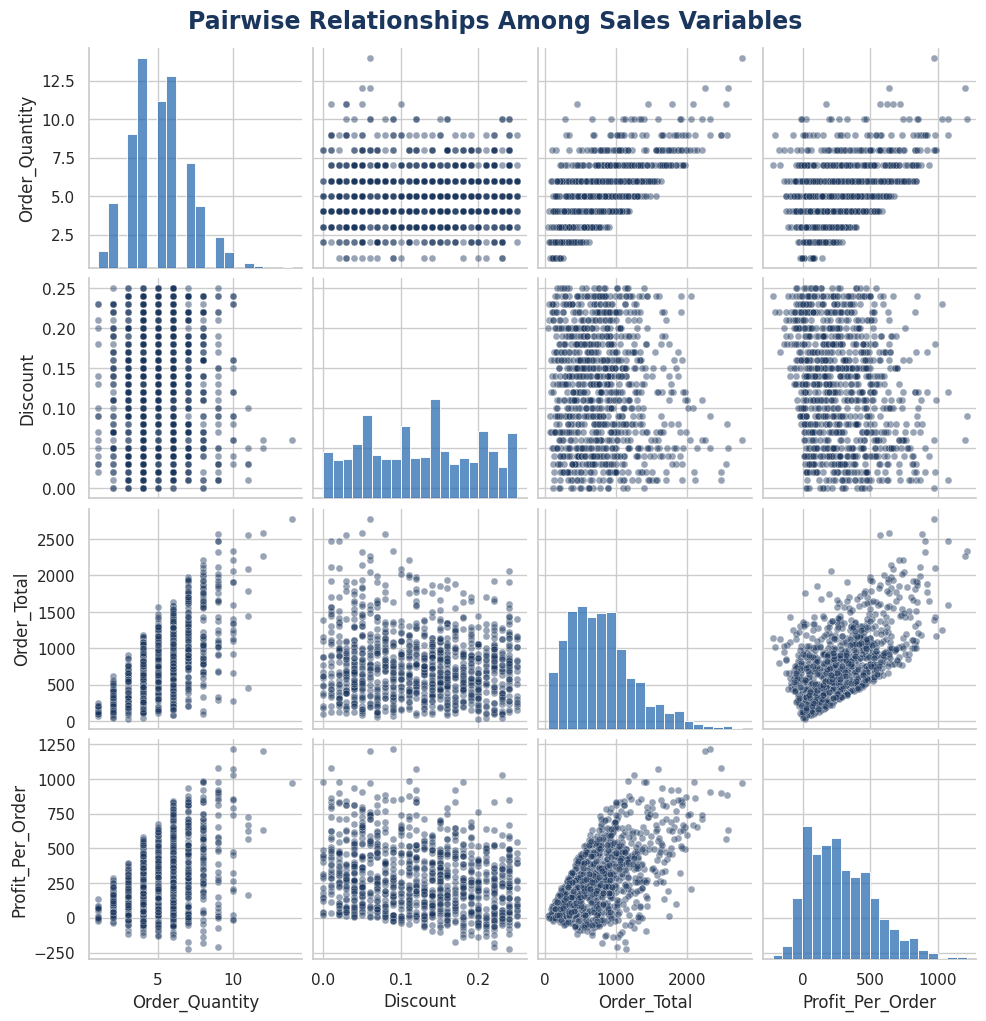

In [292]:
# ============================================================
# PAIR PLOT
# ============================================================

pair_columns = [
    'Order_Quantity',
    'Discount',
    'Order_Total',
    'Profit_Per_Order'
]

pair_data = (
    sales_multi[pair_columns]
    .dropna()
)

# Random sample for readability and performance
pair_data = pair_data.sample(
    n=min(1000, len(pair_data)),
    random_state=42
)

sns.pairplot(
    pair_data,
    diag_kind='hist',
    plot_kws={
        'alpha': 0.45,
        'color': COLORS['primary'],
        's': 25
    },
    diag_kws={
        'color': COLORS['secondary'],
        'bins': 20
    }
)

plt.suptitle(
    'Pairwise Relationships Among Sales Variables',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    y=1.02
)

plt.show()

## 9.5. Supplier, Category and Procurement Cost Interactions

Raw material to product match rate: 100.00%


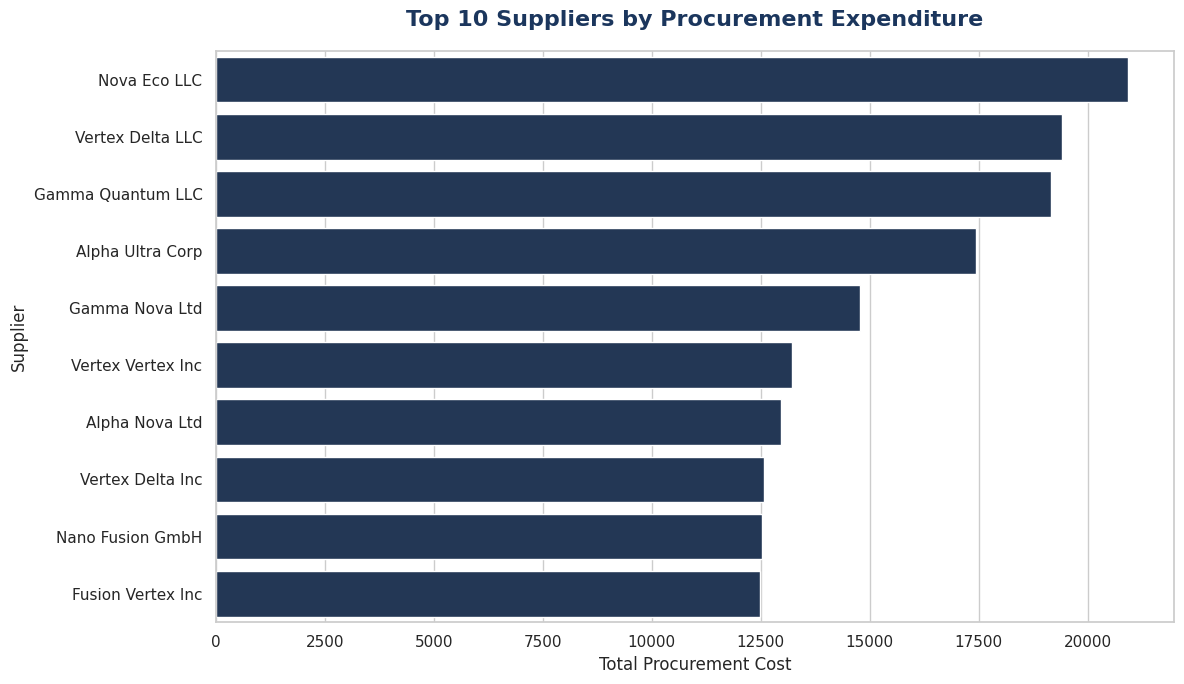

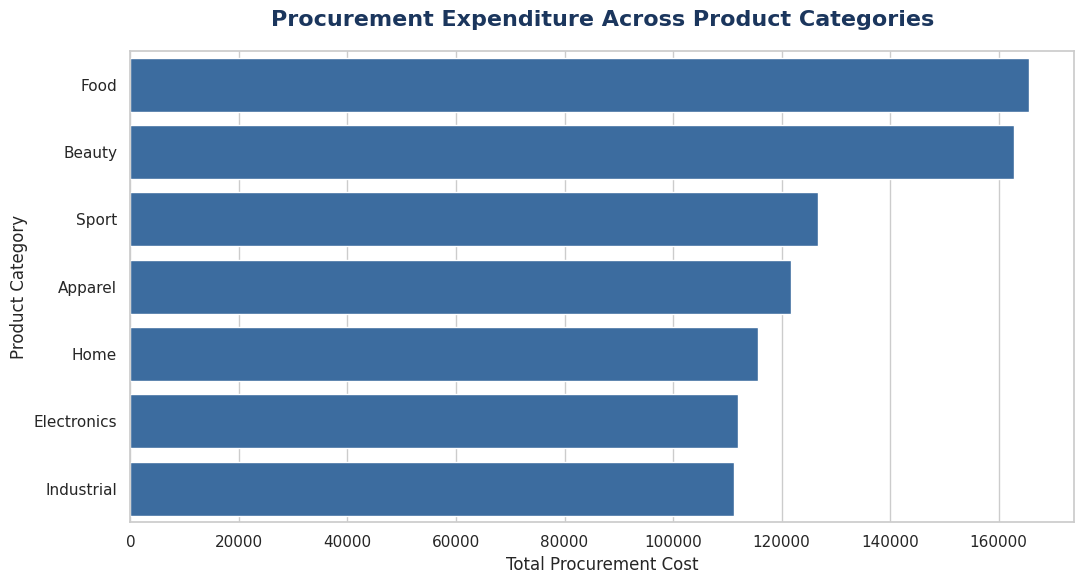

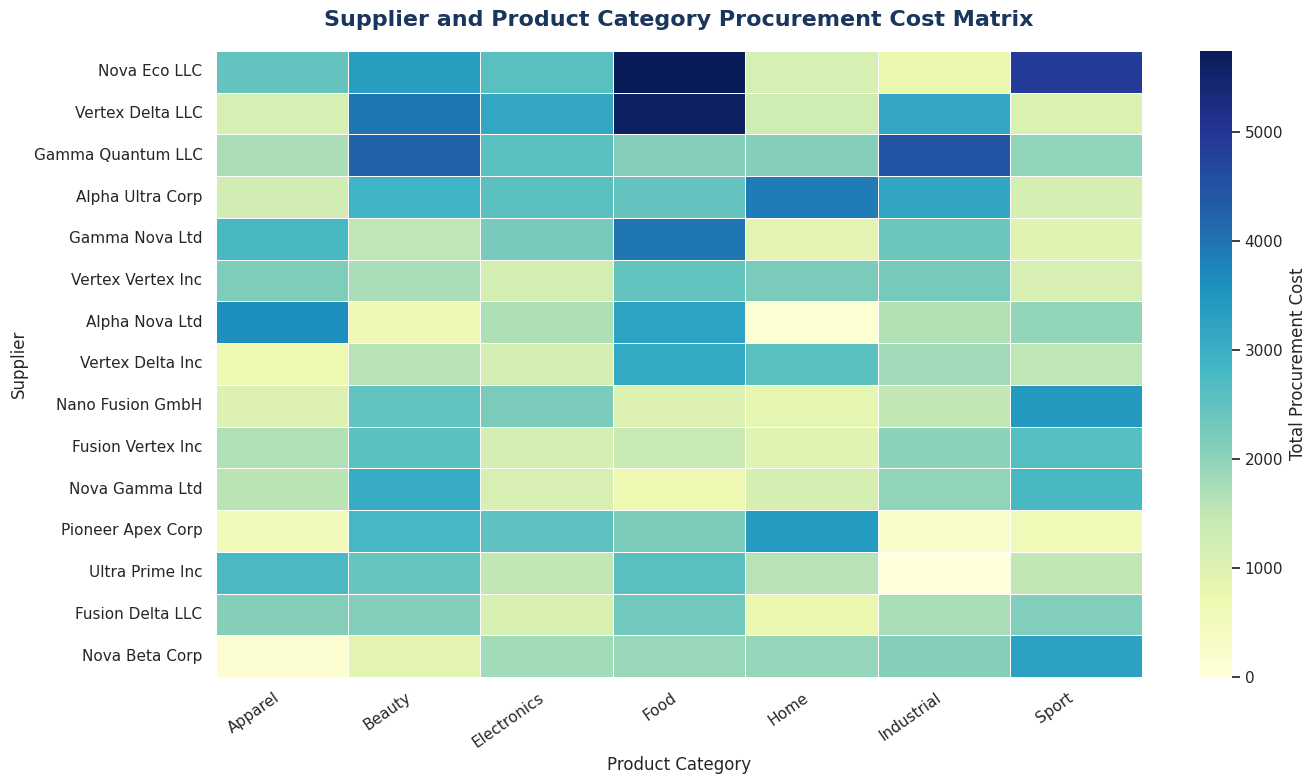

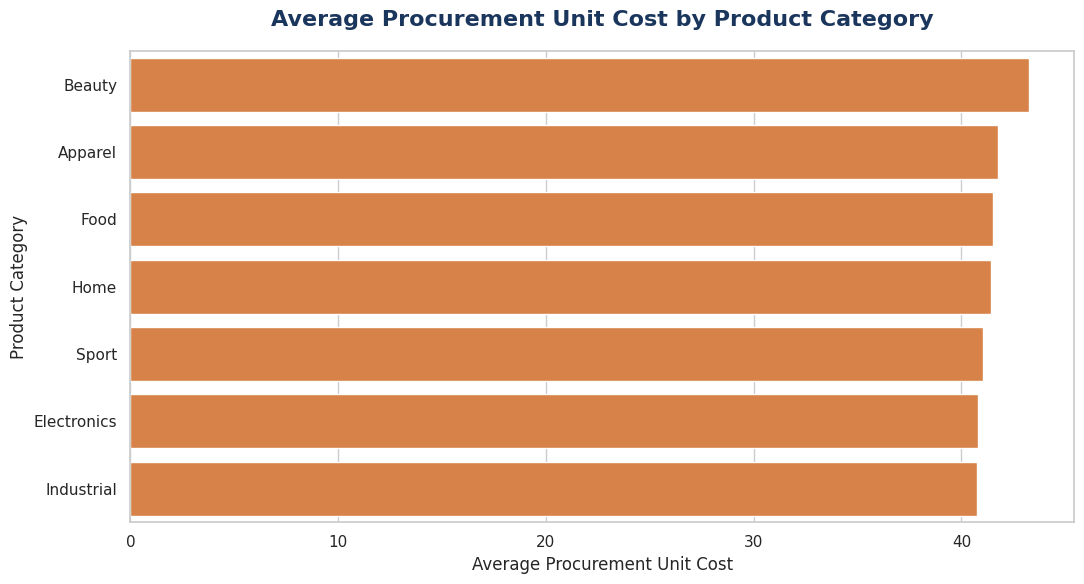


TOP SUPPLIERS BY PROCUREMENT EXPENDITURE


SL.NO,Supplier_Name,Total_Procurement_Cost,Average_Unit_Cost,Total_Quantity,Total_Orders
1,Nova Eco LLC,"20,930.13",41.67,492,45
2,Vertex Delta LLC,"19,403.67",40.57,473,43
3,Gamma Quantum LLC,"19,152.81",38.60,485,41
4,Alpha Ultra Corp,"17,441.01",42.23,408,39
5,Gamma Nova Ltd,"14,784.49",45.66,317,29
6,Vertex Vertex Inc,"13,219.17",49.98,261,24
7,Alpha Nova Ltd,"12,959.48",43.02,299,27
8,Vertex Delta Inc,"12,563.98",45.25,279,24
9,Nano Fusion GmbH,"12,523.86",40.69,311,25
10,Fusion Vertex Inc,"12,481.80",39.95,317,27



CATEGORY-WISE PROCUREMENT SUMMARY


SL.NO,Category,Total_Cost,Average_Unit_Cost,Total_Quantity,Total_Orders
1,Food,"165,592.94",41.53,"3,948",366
2,Beauty,"162,799.09",43.26,"3,761",340
3,Sport,"126,620.28",41.06,"3,115",282
4,Apparel,"121,703.98",41.78,"2,933",267
5,Home,"115,620.09",41.43,"2,775",254
6,Electronics,"112,017.79",40.81,"2,763",249
7,Industrial,"111,179.31",40.77,"2,749",242


In [293]:
# ============================================================
#  SUPPLIER, CATEGORY AND PROCUREMENT COST INTERACTIONS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('warning', '#ED7D31')

# ------------------------------------------------------------
# A. Validate Raw Material to Product Mapping
# ------------------------------------------------------------

product_lookup = product_df[
    ['Product_ID', 'Product_Name', 'Category', 'Unit_Cost']
].copy()

procurement_category = procurement_multi.merge(
    product_lookup,
    left_on='Raw_Material_ID',
    right_on='Product_ID',
    how='left',
    suffixes=('_PO', '_Product')
)

matched_records = procurement_category['Category'].notna().sum()

match_percentage = (
    matched_records / len(procurement_category) * 100
)

print(f"Raw material to product match rate: {match_percentage:.2f}%")

# Use the procurement Unit_Cost for procurement cost analysis.
# Product-master Unit_Cost is retained for comparison where available.


# ------------------------------------------------------------
# B. Supplier-wise Procurement Expenditure
# ------------------------------------------------------------

supplier_cost = (
    procurement_category
    .groupby('Supplier_Name', as_index=False)
    .agg(
        Total_Procurement_Cost=('Total_Cost', 'sum'),
        Average_Unit_Cost=('Unit_Cost_PO', 'mean'),
        Total_Quantity=('Order_Quantity', 'sum'),
        Total_Orders=('PO_ID', 'nunique')
    )
    .sort_values(
        'Total_Procurement_Cost',
        ascending=False
    )
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=supplier_cost.head(10),
    x='Total_Procurement_Cost',
    y='Supplier_Name',
    color=COLORS['primary']
)

plt.title(
    'Top 10 Suppliers by Procurement Expenditure',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Total Procurement Cost')
plt.ylabel('Supplier')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# C. Category-wise Procurement Expenditure
# ------------------------------------------------------------

category_cost = (
    procurement_category
    .dropna(subset=['Category'])
    .groupby('Category', as_index=False)
    .agg(
        Total_Cost=('Total_Cost', 'sum'),
        Average_Unit_Cost=('Unit_Cost_PO', 'mean'),
        Total_Quantity=('Order_Quantity', 'sum'),
        Total_Orders=('PO_ID', 'nunique')
    )
    .sort_values('Total_Cost', ascending=False)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=category_cost,
    x='Total_Cost',
    y='Category',
    color=COLORS['secondary']
)

plt.title(
    'Procurement Expenditure Across Product Categories',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Total Procurement Cost')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# D. Supplier vs Category Cost Heatmap
# ------------------------------------------------------------

supplier_category_cost = (
    procurement_category
    .dropna(subset=['Supplier_Name', 'Category'])
    .pivot_table(
        index='Supplier_Name',
        columns='Category',
        values='Total_Cost',
        aggfunc='sum',
        fill_value=0
    )
)

# Select top 15 suppliers by total expenditure
top_suppliers = (
    supplier_cost
    .head(15)['Supplier_Name']
)

supplier_category_cost = (
    supplier_category_cost
    .reindex(top_suppliers)
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    supplier_category_cost,
    cmap='YlGnBu',
    linewidths=0.4,
    cbar_kws={
        'label': 'Total Procurement Cost'
    }
)

plt.title(
    'Supplier and Product Category Procurement Cost Matrix',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Product Category')
plt.ylabel('Supplier')

plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# E. Category-wise Average Unit Cost
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

sns.barplot(
    data=category_cost.sort_values(
        'Average_Unit_Cost',
        ascending=False
    ),
    x='Average_Unit_Cost',
    y='Category',
    color=COLORS['warning']
)

plt.title(
    'Average Procurement Unit Cost by Product Category',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Average Procurement Unit Cost')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# F. Supplier and Category Summary
# ------------------------------------------------------------

def style_procurement_table(df, caption_text, left_cols):
    df_display = df.copy()
    df_display.insert(0, 'SL.NO', range(1, len(df_display) + 1))

    format_map = {'SL.NO': '{:.0f}'}
    for col in df_display.columns:
        if col == 'SL.NO' or col in left_cols:
            continue
        if pd.api.types.is_integer_dtype(df_display[col]):
            format_map[col] = '{:,}'
        elif pd.api.types.is_float_dtype(df_display[col]):
            format_map[col] = '{:,.2f}'

    styler = (
        df_display.style
        .hide(axis='index')
        .format(format_map, na_rep='N/A')
        .set_properties(**{
            'text-align': 'center',
            'padding': '12px 20px',
            'font-size': '14px',
            'border': '1px solid #D6D6D6'
        })
        .set_properties(
            subset=left_cols,
            **{'text-align': 'left', 'font-weight': 'bold'}
        )
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#1B365D'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '14px 20px'),
                    ('font-size', '14px'),
                    ('border', '1px solid white')
                ]
            },
            {
                'selector': 'caption',
                'props': [
                    ('caption-side', 'top'),
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#1B365D'),
                    ('padding', '12px')
                ]
            },
            {
                'selector': 'table',
                'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', 'auto')
                ]
            }
        ])
        .set_caption(caption_text)
    )
    return styler


print("\nTOP SUPPLIERS BY PROCUREMENT EXPENDITURE")
display(
    style_procurement_table(
        supplier_cost.head(10),
        'Supply Chain Analytics - Top 10 Suppliers by Procurement Expenditure',
        ['Supplier_Name']
    )
)

print("\nCATEGORY-WISE PROCUREMENT SUMMARY")
display(
    style_procurement_table(
        category_cost,
        'Supply Chain Analytics - Category-Wise Procurement Summary',
        ['Category']
    )
)

## 9.6. Customer Location, Shipping Mode and Delivery Risk

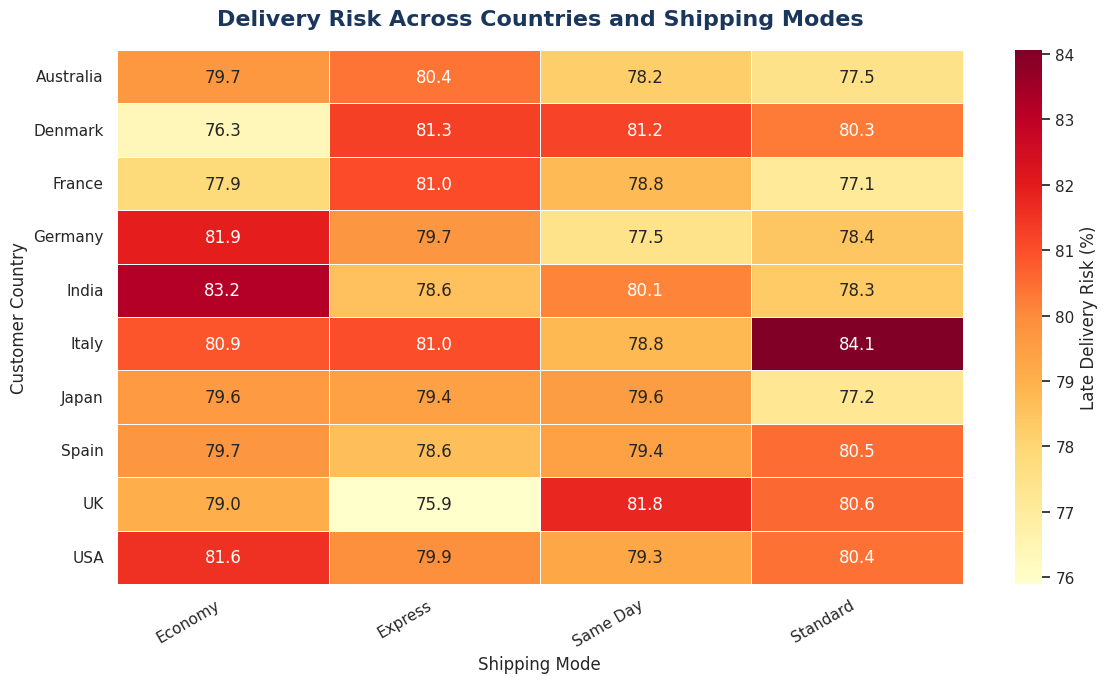

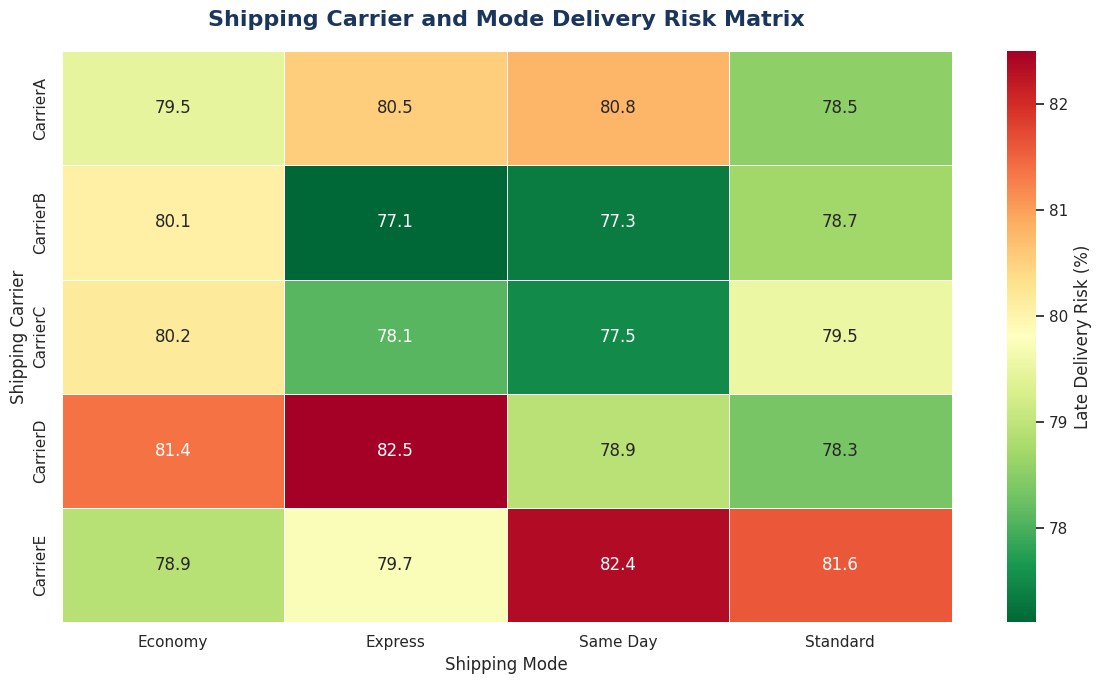

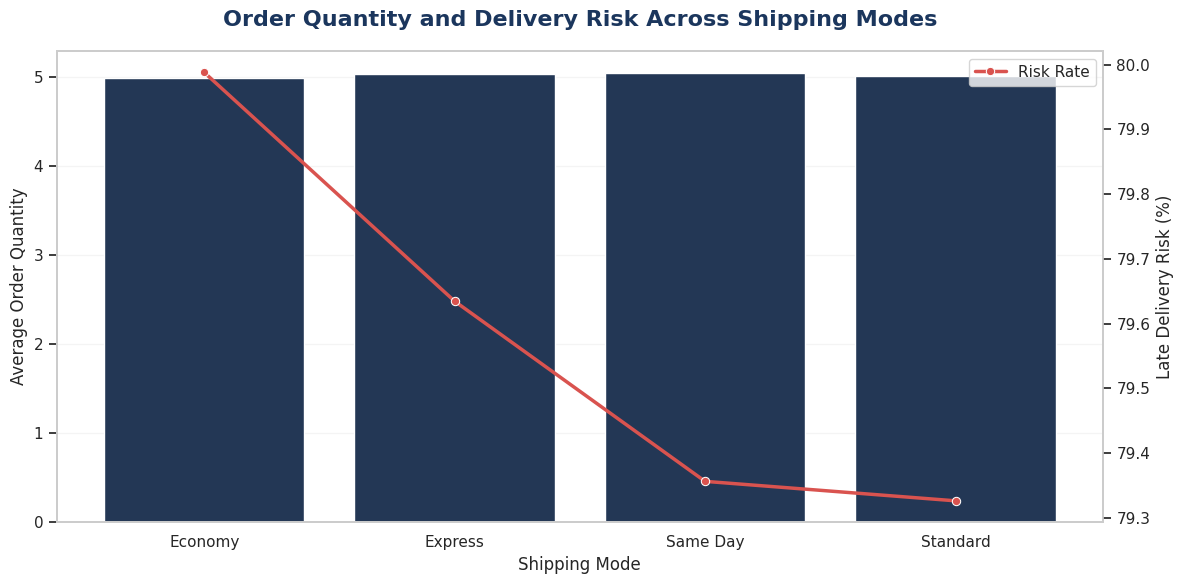

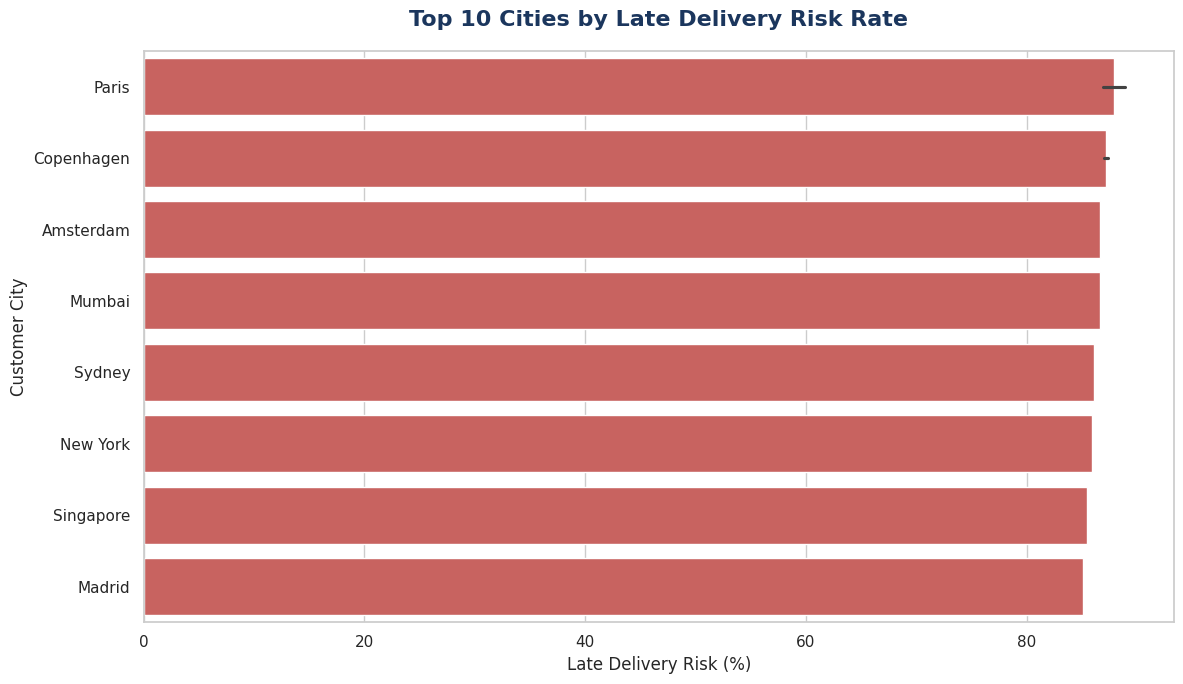


COUNTRY AND SHIPPING MODE SUMMARY


SL.NO,Country,Shipping_Mode,Total_Orders,Total_Quantity,Average_Quantity,Risk_Orders,Late_Orders,Risk_Rate_Percent,Actual_Late_Rate_Percent
1,Italy,Standard,458,"2,325",5.08,385,385,84.06%,84.06%
2,India,Economy,511,"2,493",4.88,425,425,83.17%,83.17%
3,Germany,Economy,570,"2,817",4.94,467,467,81.93%,81.93%
4,UK,Same Day,466,"2,348",5.04,381,381,81.76%,81.76%
5,USA,Economy,477,"2,378",4.99,389,389,81.55%,81.55%
6,Denmark,Express,427,"2,120",4.96,347,347,81.26%,81.26%
7,Denmark,Same Day,436,"2,272",5.21,354,354,81.19%,81.19%
8,France,Express,633,"3,247",5.13,513,513,81.04%,81.04%
9,Italy,Express,474,"2,424",5.11,384,384,81.01%,81.01%
10,Italy,Economy,476,"2,378",5.00,385,385,80.88%,80.88%



CARRIER AND SHIPPING MODE SUMMARY


SL.NO,Shipping_Carrier,Shipping_Mode,Total_Orders,Total_Quantity,Risk_Orders,Late_Orders,Risk_Rate_Percent,Actual_Late_Rate_Percent
1,CarrierD,Express,"1,023","5,045",844,844,82.50%,82.50%
2,CarrierE,Same Day,981,"4,943",808,808,82.36%,82.36%
3,CarrierE,Standard,984,"4,859",803,803,81.61%,81.61%
4,CarrierD,Economy,983,"4,872",800,800,81.38%,81.38%
5,CarrierA,Same Day,"1,000","5,056",808,808,80.80%,80.80%
6,CarrierA,Express,"1,017","5,054",819,819,80.53%,80.53%
7,CarrierC,Economy,963,"4,800",772,772,80.17%,80.17%
8,CarrierB,Economy,993,"4,993",795,795,80.06%,80.06%
9,CarrierE,Express,997,"5,057",795,795,79.74%,79.74%
10,CarrierC,Standard,"1,020","5,087",811,811,79.51%,79.51%



TOP CITIES BY DELIVERY RISK


SL.NO,Country,City,Total_Orders,Total_Quantity,Risk_Orders,Late_Orders,Risk_Rate_Percent
1,USA,Paris,27,122,24,24,88.89%
2,UK,Copenhagen,87,434,76,76,87.36%
3,Denmark,Copenhagen,115,525,100,100,86.96%
4,Italy,Paris,122,593,106,106,86.89%
5,France,Amsterdam,165,827,143,143,86.67%
6,India,Mumbai,75,397,65,65,86.67%
7,UK,Sydney,36,175,31,31,86.11%
8,UK,New York,142,681,122,122,85.92%
9,Spain,Singapore,124,641,106,106,85.48%
10,Germany,Madrid,87,418,74,74,85.06%


In [294]:
# ============================================================
# CUSTOMER LOCATION, SHIPPING MODE AND DELIVERY RISK
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('danger', '#C00000')

# Ensure sales_multi has Country and City if they live in customer_df
sales_loc = sales_multi.copy()

location_cols_needed = [c for c in ['Country', 'City'] if c not in sales_loc.columns]
if location_cols_needed and 'customer_df' in globals() and 'Customer_ID' in sales_loc.columns and 'Customer_ID' in customer_df.columns:
    merge_cols = ['Customer_ID'] + [c for c in ['Country', 'City'] if c in customer_df.columns and c not in sales_loc.columns]
    sales_loc = sales_loc.merge(
        customer_df[merge_cols].drop_duplicates(subset=['Customer_ID']),
        on='Customer_ID',
        how='left'
    )

# Handle case-insensitive location column names if needed
col_lookup = {c.lower(): c for c in sales_loc.columns}
if 'Country' not in sales_loc.columns and 'country' in col_lookup:
    sales_loc['Country'] = sales_loc[col_lookup['country']]
if 'City' not in sales_loc.columns and 'city' in col_lookup:
    sales_loc['City'] = sales_loc[col_lookup['city']]

# ------------------------------------------------------------
# A. Country and Shipping Mode Analysis
# ------------------------------------------------------------

if 'Country' in sales_loc.columns and 'Shipping_Mode' in sales_loc.columns:
    location_shipping = (
        sales_loc
        .groupby(
            ['Country', 'Shipping_Mode'],
            as_index=False
        )
        .agg(
            Total_Orders=('Order_ID', 'nunique'),
            Total_Quantity=('Order_Quantity', 'sum'),
            Average_Quantity=('Order_Quantity', 'mean'),
            Risk_Orders=('Late_Risk_Binary', 'sum'),
            Late_Orders=('Actual_Late_Binary', 'sum')
        )
    )

    location_shipping['Risk_Rate_Percent'] = np.where(
        location_shipping['Total_Orders'] > 0,
        location_shipping['Risk_Orders'] / location_shipping['Total_Orders'] * 100,
        np.nan
    )

    location_shipping['Actual_Late_Rate_Percent'] = np.where(
        location_shipping['Total_Orders'] > 0,
        location_shipping['Late_Orders'] / location_shipping['Total_Orders'] * 100,
        np.nan
    )

    # ------------------------------------------------------------
    # B. Country vs Shipping Mode Risk Heatmap
    # ------------------------------------------------------------

    risk_heatmap = location_shipping.pivot(
        index='Country',
        columns='Shipping_Mode',
        values='Risk_Rate_Percent'
    )

    plt.figure(figsize=(12, 7))

    sns.heatmap(
        risk_heatmap,
        annot=True,
        fmt='.1f',
        cmap='YlOrRd',
        linewidths=0.5,
        cbar_kws={
            'label': 'Late Delivery Risk (%)'
        }
    )

    plt.title(
        'Delivery Risk Across Countries and Shipping Modes',
        fontsize=16,
        fontweight='bold',
        color=COLORS['primary'],
        pad=18
    )

    plt.xlabel('Shipping Mode')
    plt.ylabel('Customer Country')

    plt.xticks(rotation=30, ha='right')
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()
else:
    location_shipping = pd.DataFrame()
    print("Skipping Country vs Shipping Mode analysis: 'Country' column not found in sales_multi or customer_df.")


# ------------------------------------------------------------
# C. Shipping Carrier and Shipping Mode Interaction
# ------------------------------------------------------------

carrier_mode = (
    sales_loc
    .groupby(
        ['Shipping_Carrier', 'Shipping_Mode'],
        as_index=False
    )
    .agg(
        Total_Orders=('Order_ID', 'nunique'),
        Total_Quantity=('Order_Quantity', 'sum'),
        Risk_Orders=('Late_Risk_Binary', 'sum'),
        Late_Orders=('Actual_Late_Binary', 'sum')
    )
)

carrier_mode['Risk_Rate_Percent'] = np.where(
    carrier_mode['Total_Orders'] > 0,
    carrier_mode['Risk_Orders'] / carrier_mode['Total_Orders'] * 100,
    np.nan
)

carrier_mode['Actual_Late_Rate_Percent'] = np.where(
    carrier_mode['Total_Orders'] > 0,
    carrier_mode['Late_Orders'] / carrier_mode['Total_Orders'] * 100,
    np.nan
)

# Heatmap: Carrier vs Shipping Mode
carrier_heatmap = carrier_mode.pivot(
    index='Shipping_Carrier',
    columns='Shipping_Mode',
    values='Risk_Rate_Percent'
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    carrier_heatmap,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn_r',
    linewidths=0.5,
    cbar_kws={
        'label': 'Late Delivery Risk (%)'
    }
)

plt.title(
    'Shipping Carrier and Mode Delivery Risk Matrix',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Shipping Mode')
plt.ylabel('Shipping Carrier')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# D. Order Quantity vs Delivery Risk
# ------------------------------------------------------------

quantity_risk = (
    sales_loc
    .groupby('Shipping_Mode', as_index=False)
    .agg(
        Average_Order_Quantity=('Order_Quantity', 'mean'),
        Average_Order_Value=('Order_Total', 'mean'),
        Risk_Rate=('Late_Risk_Binary', 'mean'),
        Actual_Late_Rate=('Actual_Late_Binary', 'mean')
    )
)

quantity_risk['Risk_Rate'] *= 100
quantity_risk['Actual_Late_Rate'] *= 100

fig, ax1 = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=quantity_risk,
    x='Shipping_Mode',
    y='Average_Order_Quantity',
    color=COLORS['primary'],
    ax=ax1
)

ax1.set_ylabel('Average Order Quantity')
ax1.set_xlabel('Shipping Mode')

ax1.set_title(
    'Order Quantity and Delivery Risk Across Shipping Modes',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

ax2 = ax1.twinx()

sns.lineplot(
    data=quantity_risk,
    x='Shipping_Mode',
    y='Risk_Rate',
    marker='o',
    linewidth=2.5,
    color=COLORS['danger'],
    ax=ax2,
    label='Risk Rate'
)

ax2.set_ylabel('Late Delivery Risk (%)')

ax1.grid(axis='y', alpha=0.2)
ax2.grid(False)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# E. City-level Delivery Risk
# ------------------------------------------------------------

city_group_cols = ['Country', 'City'] if 'Country' in sales_loc.columns and 'City' in sales_loc.columns else (['City'] if 'City' in sales_loc.columns else [])

if city_group_cols:
    city_risk = (
        sales_loc
        .groupby(city_group_cols, as_index=False)
        .agg(
            Total_Orders=('Order_ID', 'nunique'),
            Total_Quantity=('Order_Quantity', 'sum'),
            Risk_Orders=('Late_Risk_Binary', 'sum'),
            Late_Orders=('Actual_Late_Binary', 'sum')
        )
    )

    city_risk['Risk_Rate_Percent'] = np.where(
        city_risk['Total_Orders'] > 0,
        city_risk['Risk_Orders'] / city_risk['Total_Orders'] * 100,
        np.nan
    )

    city_risk_filtered = city_risk[
        city_risk['Total_Orders'] >= 20
    ]

    top_risk_cities = (
        city_risk_filtered
        .sort_values(
            'Risk_Rate_Percent',
            ascending=False
        )
        .head(10)
    )

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=top_risk_cities,
        x='Risk_Rate_Percent',
        y='City',
        color=COLORS['danger']
    )

    plt.title(
        'Top 10 Cities by Late Delivery Risk Rate',
        fontsize=16,
        fontweight='bold',
        color=COLORS['primary'],
        pad=18
    )

    plt.xlabel('Late Delivery Risk (%)')
    plt.ylabel('Customer City')

    plt.tight_layout()
    plt.show()
else:
    top_risk_cities = pd.DataFrame()
    print("Skipping City-level delivery risk: 'City' column not found.")


# ------------------------------------------------------------
# F. Display Summary Tables
# ------------------------------------------------------------

def style_location_table(df, caption_text, left_cols):
    df_display = df.copy()
    df_display.insert(0, 'SL.NO', range(1, len(df_display) + 1))

    format_map = {'SL.NO': '{:.0f}'}
    for col in df_display.columns:
        if col == 'SL.NO' or col in left_cols:
            continue
        if 'Percent' in col or 'Rate' in col:
            format_map[col] = '{:,.2f}%'
        elif pd.api.types.is_integer_dtype(df_display[col]):
            format_map[col] = '{:,}'
        elif pd.api.types.is_float_dtype(df_display[col]):
            format_map[col] = '{:,.2f}'

    return (
        df_display.style
        .hide(axis='index')
        .format(format_map, na_rep='N/A')
        .set_properties(**{
            'text-align': 'center',
            'padding': '12px 20px',
            'font-size': '14px',
            'border': '1px solid #D6D6D6'
        })
        .set_properties(
            subset=left_cols,
            **{'text-align': 'left', 'font-weight': 'bold'}
        )
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#1B365D'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '14px 20px'),
                    ('font-size', '14px'),
                    ('border', '1px solid white')
                ]
            },
            {
                'selector': 'caption',
                'props': [
                    ('caption-side', 'top'),
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#1B365D'),
                    ('padding', '12px')
                ]
            },
            {
                'selector': 'table',
                'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', 'auto')
                ]
            }
        ])
        .set_caption(caption_text)
    )


if not location_shipping.empty:
    print("\nCOUNTRY AND SHIPPING MODE SUMMARY")
    display(
        style_location_table(
            location_shipping.sort_values('Risk_Rate_Percent', ascending=False).head(15),
            'Supply Chain Analytics - Country and Shipping Mode Risk Summary (Top 15)',
            ['Country', 'Shipping_Mode']
        )
    )

print("\nCARRIER AND SHIPPING MODE SUMMARY")
display(
    style_location_table(
        carrier_mode.sort_values('Risk_Rate_Percent', ascending=False),
        'Supply Chain Analytics - Carrier and Shipping Mode Risk Summary',
        ['Shipping_Carrier', 'Shipping_Mode']
    )
)

if not top_risk_cities.empty:
    print("\nTOP CITIES BY DELIVERY RISK")
    left_city_cols = [c for c in ['Country', 'City'] if c in top_risk_cities.columns]
    display(
        style_location_table(
            top_risk_cities,
            'Supply Chain Analytics - Top 10 Cities by Delivery Risk',
            left_city_cols
        )
    )

## 9.7. Product Margin and Discount Matrix

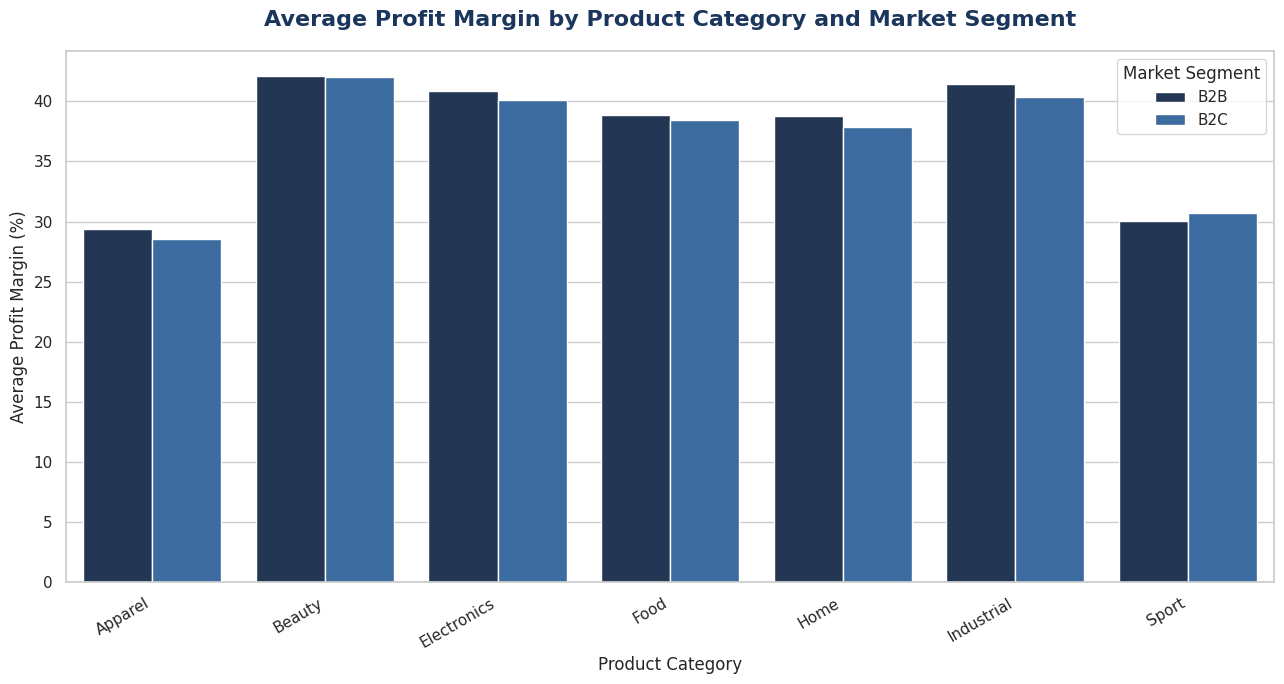

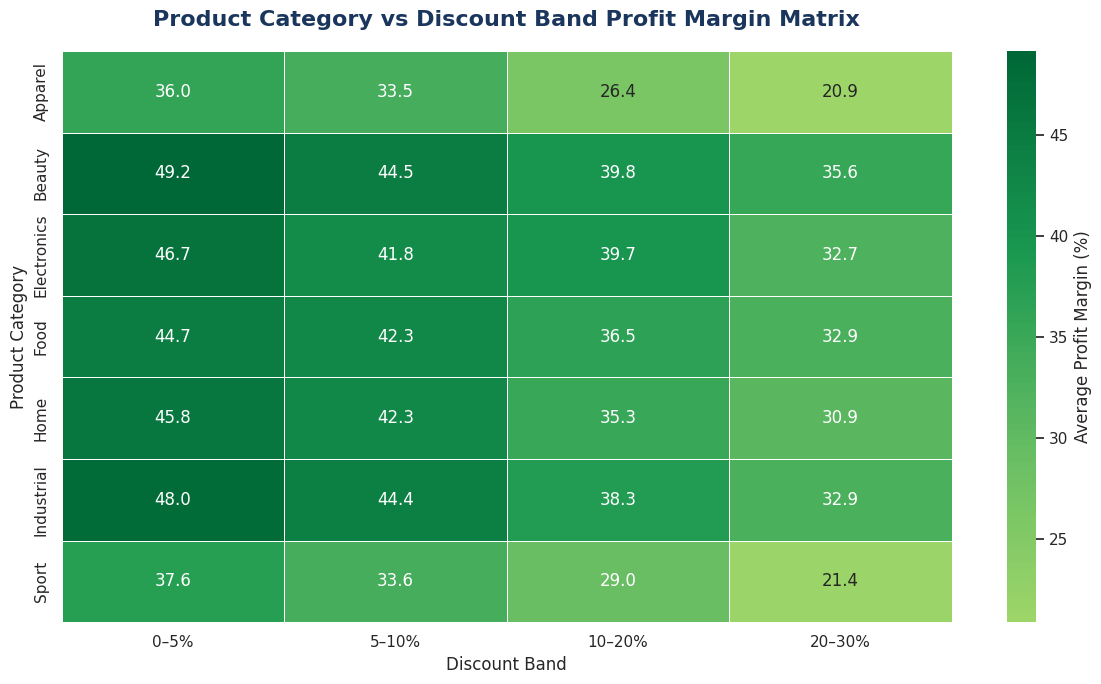

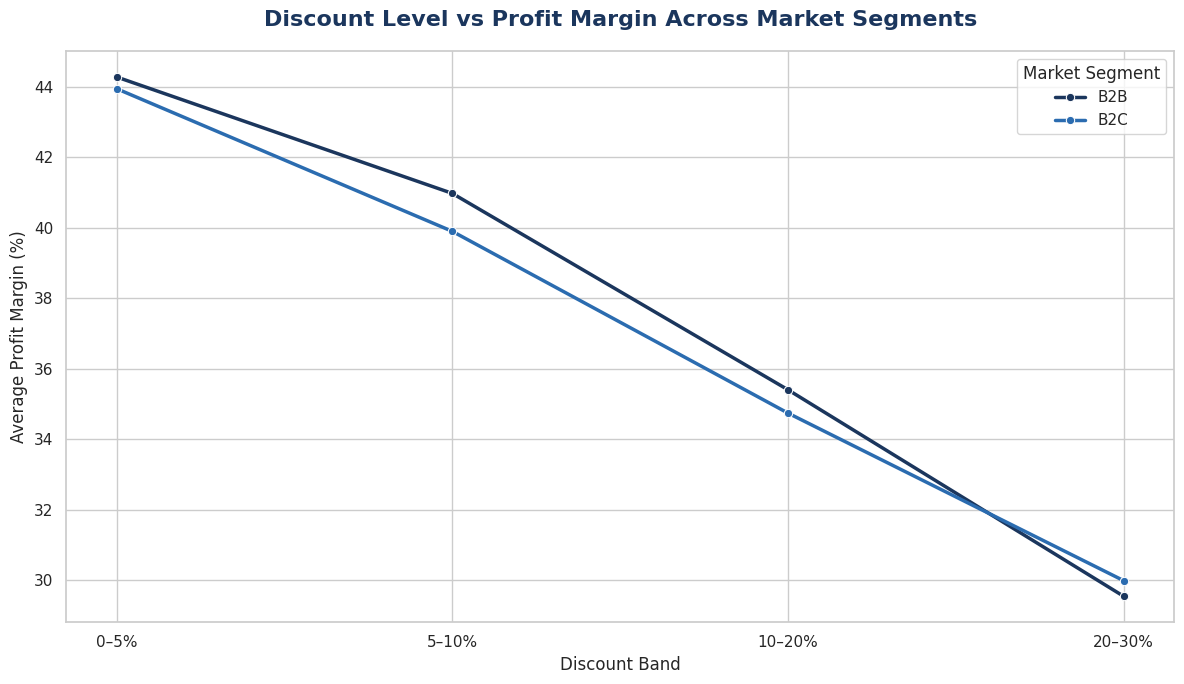

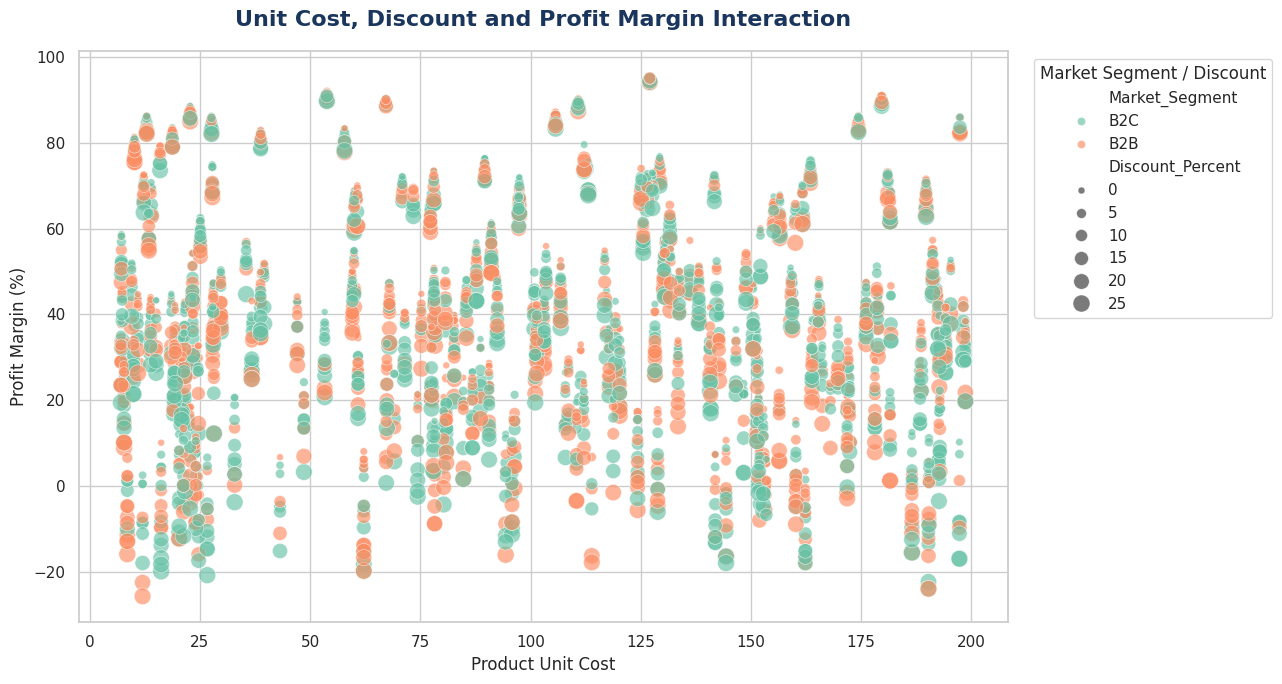


CATEGORY AND MARKET SEGMENT PROFITABILITY


SL.NO,Category,Market_Segment,Total_Revenue,Total_Profit,Average_Profit,Average_Margin,Average_Unit_Cost,Average_Discount,Total_Orders
1,Beauty,B2B,"1,250,494.55","514,965.40",352.96,42.08%,110.69,12.54%,"1,459"
2,Beauty,B2C,"1,271,673.58","511,112.23",338.04,42.02%,107.83,12.42%,"1,512"
3,Food,B2C,"1,377,237.59","499,122.27",314.11,38.42%,113.48,12.84%,"1,589"
4,Food,B2B,"1,225,140.81","456,166.47",314.38,38.87%,114.83,12.84%,"1,451"
5,Industrial,B2C,"811,088.04","326,621.78",322.75,40.35%,80.77,12.22%,"1,012"
6,Home,B2C,"892,001.51","318,091.74",271.18,37.84%,95.83,12.53%,"1,173"
7,Industrial,B2B,"743,867.64","301,120.44",325.89,41.45%,82.74,12.26%,924
8,Home,B2B,"822,919.85","297,956.04",278.99,38.77%,92.50,12.38%,"1,068"
9,Sport,B2C,"984,140.61","291,741.97",225.98,30.71%,89.28,12.31%,"1,291"
10,Electronics,B2C,"730,720.36","276,181.81",257.63,40.12%,109.78,12.61%,"1,072"



DISCOUNT AND MARKET SEGMENT SUMMARY


SL.NO,Market_Segment,Discount_Band,Average_Profit,Average_Margin,Total_Profit,Total_Orders
1,B2B,0–5%,373.02,44.28%,"666,958.46","1,788"
2,B2B,5–10%,315.88,40.98%,"524,671.83","1,661"
3,B2B,10–20%,257.85,35.41%,"833,632.69","3,233"
4,B2B,20–30%,193.32,29.55%,"284,368.44","1,471"
5,B2C,0–5%,364.13,43.95%,"708,954.09","1,947"
6,B2C,5–10%,315.57,39.90%,"557,303.30","1,766"
7,B2C,10–20%,249.68,34.75%,"876,868.35","3,512"
8,B2C,20–30%,200.67,29.99%,"321,468.66","1,602"


In [295]:
# ============================================================
# PRODUCT MARGIN AND DISCOUNT MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')

# ------------------------------------------------------------
# A. Filter Completed Orders & Enrich Missing Columns
# ------------------------------------------------------------

margin_data = sales_multi[
    sales_multi['Order_Status']
    .astype(str)
    .str.strip()
    .str.lower()
    .eq('completed')
].copy()

if 'product_df' in globals() and 'Product_ID' in margin_data.columns and 'Product_ID' in product_df.columns:
    prod_cols = [
        c for c in ['Category', 'Unit_Cost']
        if c not in margin_data.columns and c in product_df.columns
    ]
    if prod_cols:
        margin_data = margin_data.merge(
            product_df[['Product_ID'] + prod_cols].drop_duplicates(subset=['Product_ID']),
            on='Product_ID',
            how='left'
        )

if 'Market_Segment' not in margin_data.columns and 'customer_df' in globals():
    if (
        'Customer_ID' in margin_data.columns
        and 'Customer_ID' in customer_df.columns
        and 'Market_Segment' in customer_df.columns
    ):
        margin_data = margin_data.merge(
            customer_df[['Customer_ID', 'Market_Segment']].drop_duplicates(subset=['Customer_ID']),
            on='Customer_ID',
            how='left'
        )

if 'Discount_Percent' not in margin_data.columns and 'Discount' in margin_data.columns:
    margin_data['Discount_Percent'] = margin_data['Discount'] * 100

required_cols = [
    c for c in [
        'Category',
        'Market_Segment',
        'Discount_Percent',
        'Unit_Cost',
        'Profit_Per_Order',
        'Order_Total'
    ]
    if c in margin_data.columns
]

margin_data = margin_data.dropna(subset=required_cols)

margin_data['Profit_Margin_Percent'] = np.where(
    margin_data['Order_Total'] > 0,
    (
        margin_data['Profit_Per_Order'] /
        margin_data['Order_Total']
    ) * 100,
    np.nan
)


# ------------------------------------------------------------
# B. Create Discount Groups
# ------------------------------------------------------------

discount_bins = [-0.001, 5, 10, 20, 30, 100]
discount_labels = ['0–5%', '5–10%', '10–20%', '20–30%', 'Above 30%']

margin_data['Discount_Band'] = pd.cut(
    margin_data['Discount_Percent'],
    bins=discount_bins,
    labels=discount_labels,
    include_lowest=True
)


# ------------------------------------------------------------
# C. Category and Market Segment Profitability
# ------------------------------------------------------------

category_segment = (
    margin_data
    .groupby(
        ['Category', 'Market_Segment'],
        observed=True,
        as_index=False
    )
    .agg(
        Total_Revenue=('Order_Total', 'sum'),
        Total_Profit=('Profit_Per_Order', 'sum'),
        Average_Profit=('Profit_Per_Order', 'mean'),
        Average_Margin=('Profit_Margin_Percent', 'mean'),
        Average_Unit_Cost=('Unit_Cost', 'mean'),
        Average_Discount=('Discount_Percent', 'mean'),
        Total_Orders=('Order_ID', 'nunique')
    )
)

n_segments = category_segment['Market_Segment'].nunique()
seg_palette = (
    [COLORS['primary'], COLORS['secondary']]
    if n_segments <= 2
    else sns.color_palette('Set2', n_colors=n_segments)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=category_segment,
    x='Category',
    y='Average_Margin',
    hue='Market_Segment',
    palette=seg_palette
)

plt.title(
    'Average Profit Margin by Product Category and Market Segment',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Product Category')
plt.ylabel('Average Profit Margin (%)')

plt.xticks(rotation=30, ha='right')
plt.legend(title='Market Segment')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# D. Category vs Discount Band Profit Margin Heatmap
# ------------------------------------------------------------

discount_margin_matrix = margin_data.pivot_table(
    index='Category',
    columns='Discount_Band',
    values='Profit_Margin_Percent',
    aggfunc='mean',
    observed=True
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    discount_margin_matrix,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Average Profit Margin (%)'}
)

plt.title(
    'Product Category vs Discount Band Profit Margin Matrix',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Discount Band')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# E. Discount and Profit Margin Across Market Segments
# ------------------------------------------------------------

segment_discount = (
    margin_data
    .groupby(
        ['Market_Segment', 'Discount_Band'],
        observed=True,
        as_index=False
    )
    .agg(
        Average_Profit=('Profit_Per_Order', 'mean'),
        Average_Margin=('Profit_Margin_Percent', 'mean'),
        Total_Profit=('Profit_Per_Order', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
)

plt.figure(figsize=(12, 7))

sns.lineplot(
    data=segment_discount,
    x='Discount_Band',
    y='Average_Margin',
    hue='Market_Segment',
    marker='o',
    linewidth=2.5,
    palette=seg_palette
)

plt.title(
    'Discount Level vs Profit Margin Across Market Segments',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Discount Band')
plt.ylabel('Average Profit Margin (%)')

plt.legend(title='Market Segment')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# F. Unit Cost, Discount and Profit Interaction
# ------------------------------------------------------------

sample_margin = margin_data.sample(
    n=min(2500, len(margin_data)),
    random_state=42
)

plt.figure(figsize=(13, 7))

sns.scatterplot(
    data=sample_margin,
    x='Unit_Cost',
    y='Profit_Margin_Percent',
    hue='Market_Segment',
    size='Discount_Percent',
    sizes=(25, 150),
    alpha=0.65,
    palette='Set2'
)

plt.title(
    'Unit Cost, Discount and Profit Margin Interaction',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Product Unit Cost')
plt.ylabel('Profit Margin (%)')

plt.legend(
    title='Market Segment / Discount',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# G. Category and Segment Summary
# ------------------------------------------------------------

def style_margin_table(df, caption_text, left_cols):
    df_display = df.copy()
    df_display.insert(0, 'SL.NO', range(1, len(df_display) + 1))

    format_map = {'SL.NO': '{:.0f}'}
    for col in df_display.columns:
        if col == 'SL.NO' or col in left_cols:
            continue
        if 'Margin' in col or 'Discount' in col:
            format_map[col] = '{:,.2f}%'
        elif pd.api.types.is_integer_dtype(df_display[col]):
            format_map[col] = '{:,}'
        elif pd.api.types.is_float_dtype(df_display[col]):
            format_map[col] = '{:,.2f}'

    return (
        df_display.style
        .hide(axis='index')
        .format(format_map, na_rep='N/A')
        .set_properties(**{
            'text-align': 'center',
            'padding': '12px 20px',
            'font-size': '14px',
            'border': '1px solid #D6D6D6'
        })
        .set_properties(
            subset=left_cols,
            **{'text-align': 'left', 'font-weight': 'bold'}
        )
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#1B365D'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '14px 20px'),
                    ('font-size', '14px'),
                    ('border', '1px solid white')
                ]
            },
            {
                'selector': 'caption',
                'props': [
                    ('caption-side', 'top'),
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#1B365D'),
                    ('padding', '12px')
                ]
            },
            {
                'selector': 'table',
                'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', 'auto')
                ]
            }
        ])
        .set_caption(caption_text)
    )


print("\nCATEGORY AND MARKET SEGMENT PROFITABILITY")
display(
    style_margin_table(
        category_segment.sort_values('Total_Profit', ascending=False),
        'Supply Chain Analytics - Category and Market Segment Profitability',
        ['Category', 'Market_Segment']
    )
)

print("\nDISCOUNT AND MARKET SEGMENT SUMMARY")
display(
    style_margin_table(
        segment_discount,
        'Supply Chain Analytics - Discount Band and Market Segment Summary',
        ['Market_Segment', 'Discount_Band']
    )
)

## 9.8. Procurement Fulfillment Bottlenecks

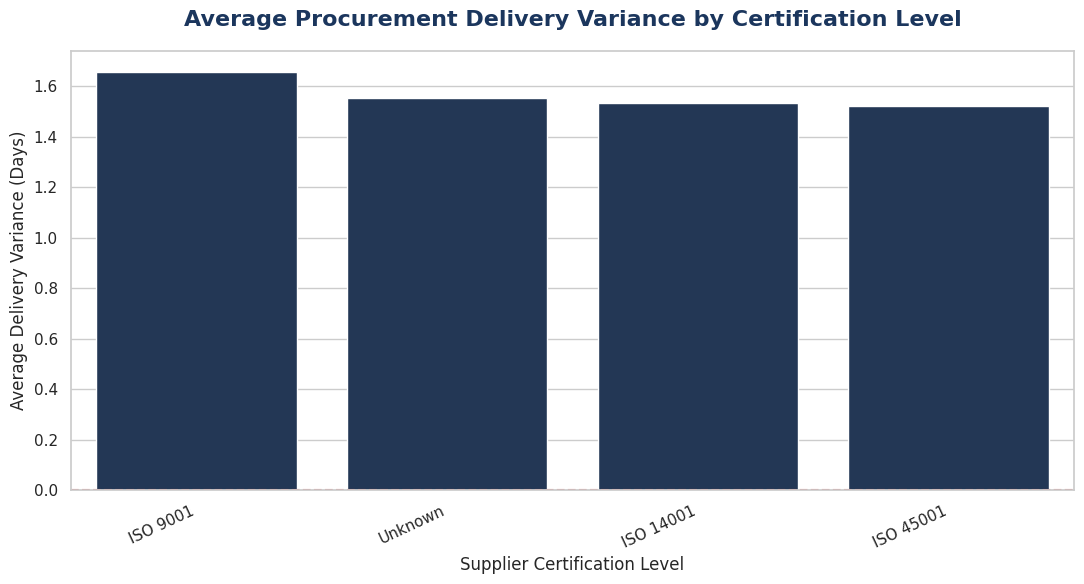

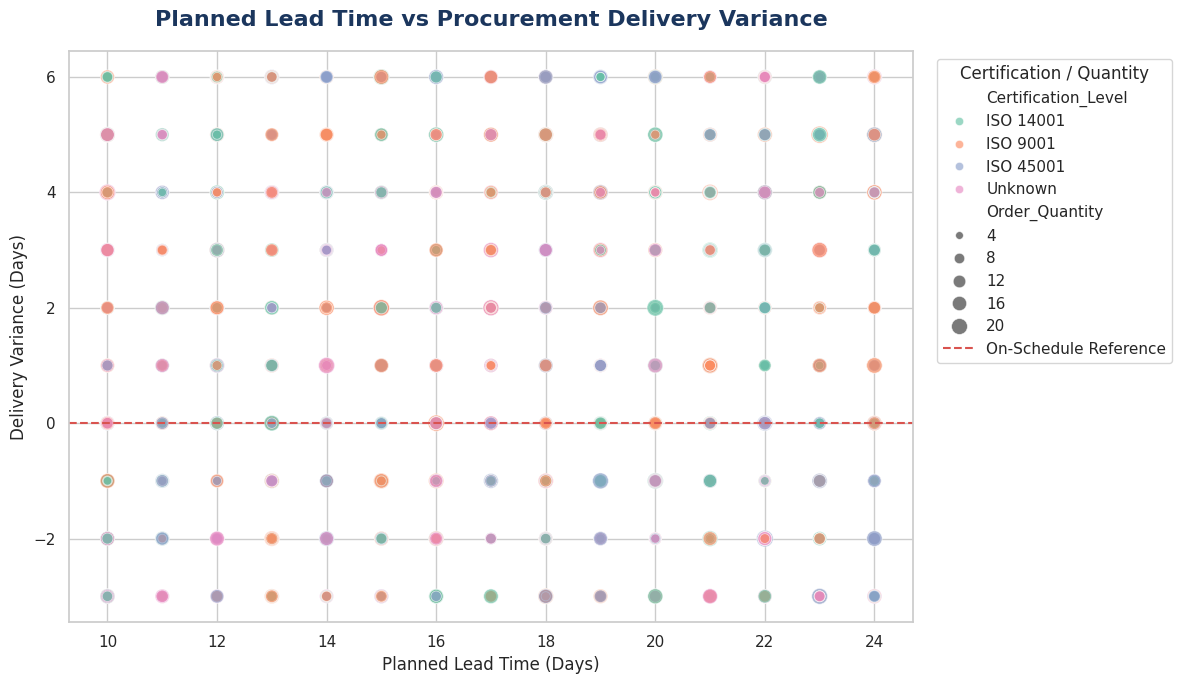

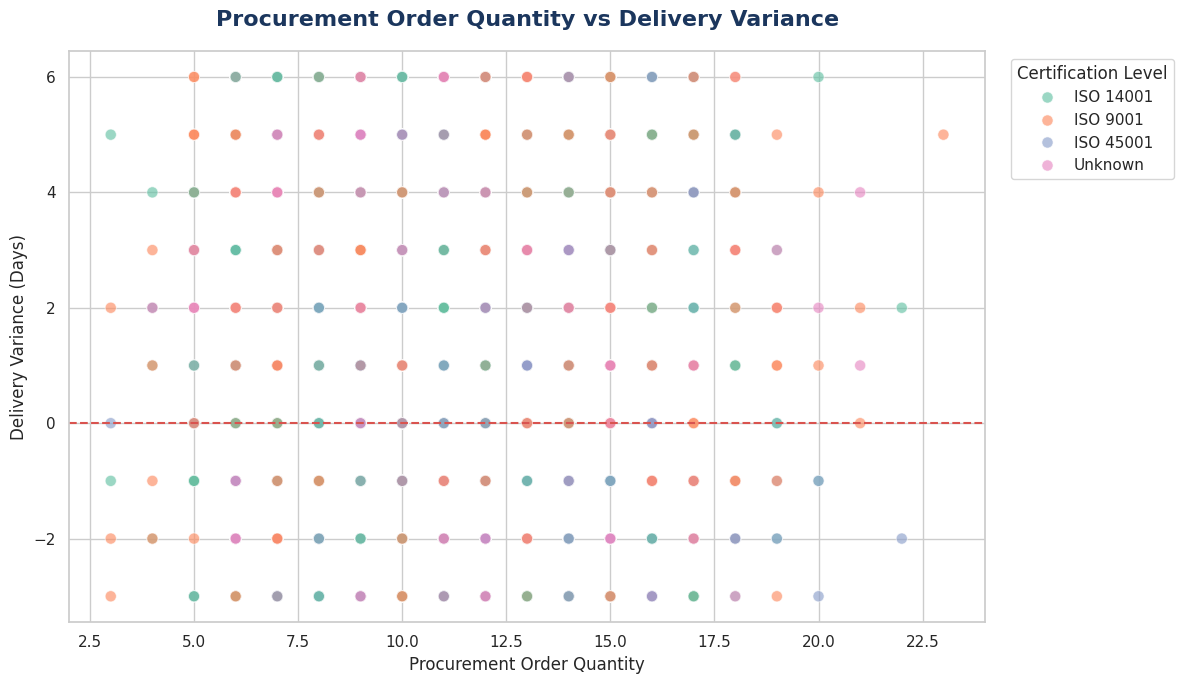

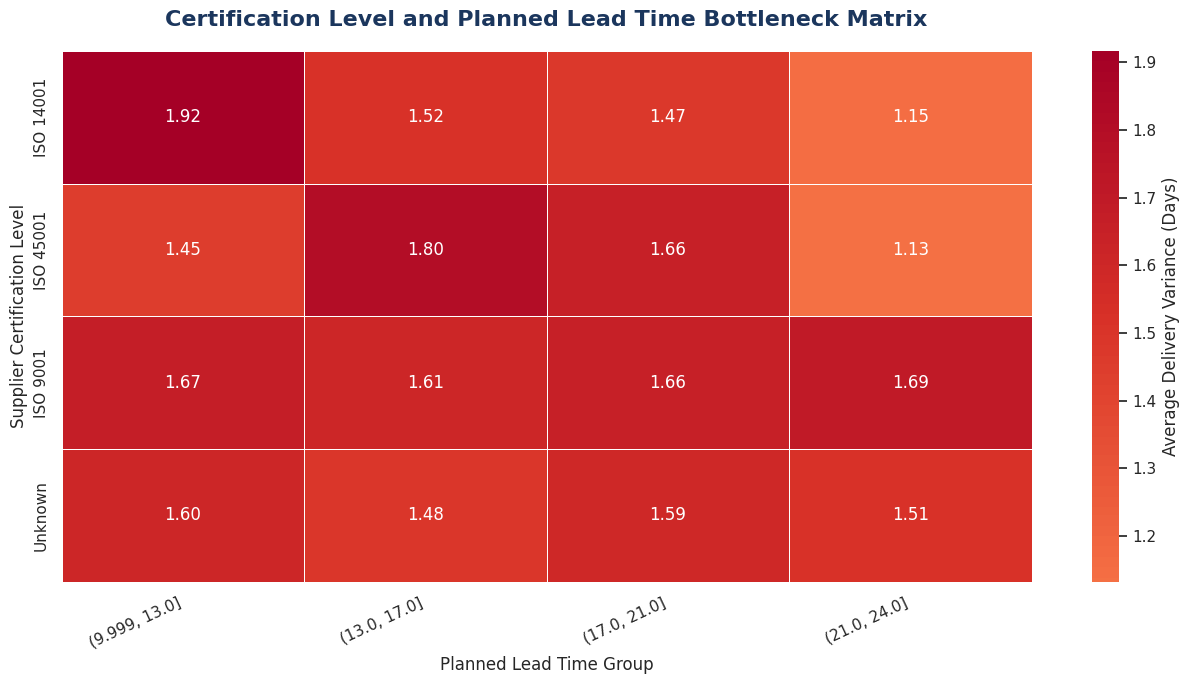

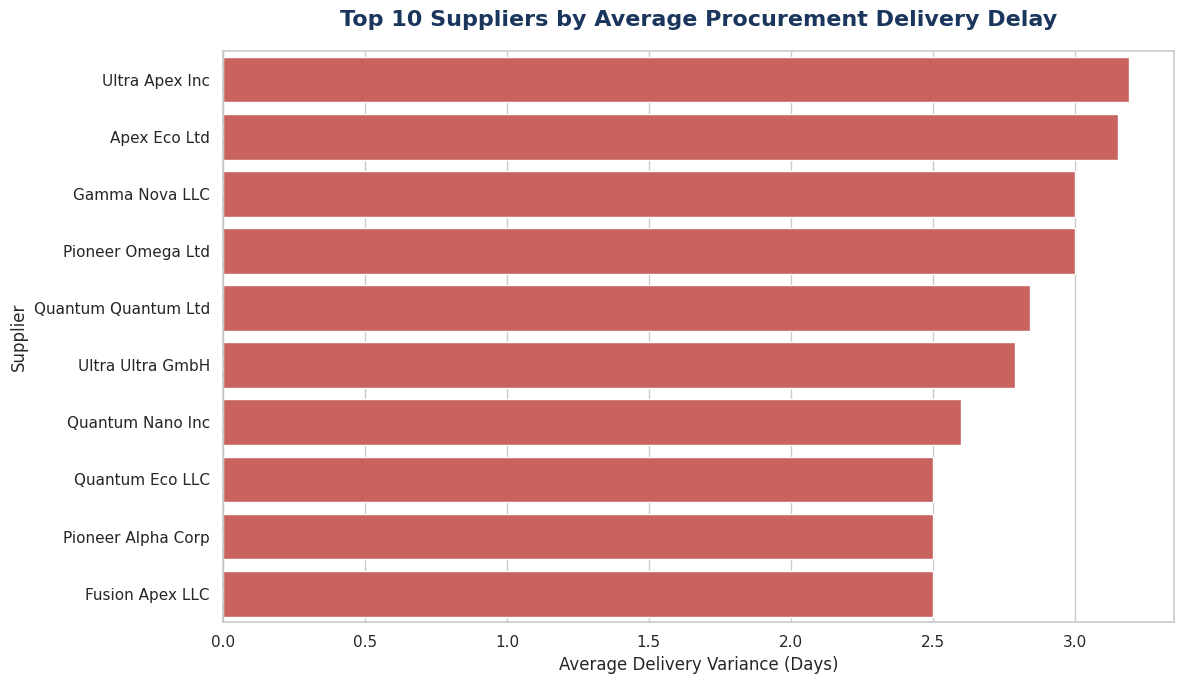


CERTIFICATION LEVEL PERFORMANCE


SL.NO,Certification_Level,Average_Delivery_Variance,Median_Delivery_Variance,Average_Quantity,Average_Lead_Time,Total_Orders
1,ISO 9001,1.66,2.00,11.00,17.38,695
2,Unknown,1.55,2.00,11.16,16.83,399
3,ISO 14001,1.53,2.00,10.87,17.15,497
4,ISO 45001,1.52,1.00,11.11,16.83,409



TOP SUPPLIER BOTTLENECKS


SL.NO,Supplier_Name,Certification_Level,Average_Delay_Days,Average_Lead_Time,Average_Quantity,Total_Orders
1,Ultra Apex Inc,ISO 9001,3.19,17.57,11.24,21
2,Apex Eco Ltd,ISO 45001,3.15,14.54,10.31,13
3,Gamma Nova LLC,ISO 14001,3.00,17.06,10.78,18
4,Pioneer Omega Ltd,Unknown,3.00,17.60,11.30,20
5,Quantum Quantum Ltd,ISO 14001,2.84,15.47,11.32,19
6,Ultra Ultra GmbH,ISO 14001,2.79,16.46,11.92,24
7,Quantum Nano Inc,ISO 9001,2.60,16.80,12.05,20
8,Quantum Eco LLC,ISO 9001,2.50,16.80,10.45,20
9,Pioneer Alpha Corp,Unknown,2.50,14.69,11.38,16
10,Fusion Apex LLC,ISO 14001,2.50,17.86,12.14,14


In [296]:
# ============================================================
# PROCUREMENT FULFILLMENT BOTTLENECKS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('danger', '#C00000')
COLORS.setdefault('grey', '#6C757D')

# ------------------------------------------------------------
# A. Prepare Valid Procurement Records
# ------------------------------------------------------------

bottleneck_data = procurement_multi.dropna(
    subset=[
        'Certification_Level',
        'Order_Quantity',
        'Planned_Lead_Time_Days',
        'Delivery_Variance_Days'
    ]
).copy()

# Remove invalid negative planned lead times
bottleneck_data = bottleneck_data[
    bottleneck_data['Planned_Lead_Time_Days'] >= 0
]


# ------------------------------------------------------------
# B. Certification Level vs Delivery Performance
# ------------------------------------------------------------

certification_summary = (
    bottleneck_data
    .groupby('Certification_Level', as_index=False)
    .agg(
        Average_Delivery_Variance=(
            'Delivery_Variance_Days', 'mean'
        ),
        Median_Delivery_Variance=(
            'Delivery_Variance_Days', 'median'
        ),
        Average_Quantity=('Order_Quantity', 'mean'),
        Average_Lead_Time=('Planned_Lead_Time_Days', 'mean'),
        Total_Orders=('PO_ID', 'nunique')
    )
    .sort_values(
        'Average_Delivery_Variance',
        ascending=False
    )
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=certification_summary,
    x='Certification_Level',
    y='Average_Delivery_Variance',
    color=COLORS['primary']
)

plt.axhline(
    0,
    color=COLORS['danger'],
    linestyle='--',
    linewidth=1.5
)

plt.title(
    'Average Procurement Delivery Variance by Certification Level',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Supplier Certification Level')
plt.ylabel('Average Delivery Variance (Days)')

plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# C. Planned Lead Time vs Delivery Variance
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=bottleneck_data,
    x='Planned_Lead_Time_Days',
    y='Delivery_Variance_Days',
    hue='Certification_Level',
    size='Order_Quantity',
    sizes=(25, 150),
    alpha=0.65,
    palette='Set2'
)

plt.axhline(
    0,
    color=COLORS['danger'],
    linestyle='--',
    linewidth=1.5,
    label='On-Schedule Reference'
)

plt.title(
    'Planned Lead Time vs Procurement Delivery Variance',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Planned Lead Time (Days)')
plt.ylabel('Delivery Variance (Days)')

plt.legend(
    title='Certification / Quantity',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# D. Procurement Quantity vs Delivery Variance
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=bottleneck_data,
    x='Order_Quantity',
    y='Delivery_Variance_Days',
    hue='Certification_Level',
    alpha=0.65,
    s=65,
    palette='Set2'
)

plt.axhline(
    0,
    color=COLORS['danger'],
    linestyle='--',
    linewidth=1.5
)

plt.title(
    'Procurement Order Quantity vs Delivery Variance',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Procurement Order Quantity')
plt.ylabel('Delivery Variance (Days)')

plt.legend(
    title='Certification Level',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# E. Certification and Planned Lead Time Interaction
# ------------------------------------------------------------

# Create lead-time groups using the dataset distribution
bottleneck_data['Lead_Time_Group'] = pd.qcut(
    bottleneck_data['Planned_Lead_Time_Days'],
    q=4,
    duplicates='drop'
)

lead_certification = (
    bottleneck_data
    .pivot_table(
        index='Certification_Level',
        columns='Lead_Time_Group',
        values='Delivery_Variance_Days',
        aggfunc='mean',
        observed=True
    )
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    lead_certification,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn_r',
    center=0,
    linewidths=0.5,
    cbar_kws={
        'label': 'Average Delivery Variance (Days)'
    }
)

plt.title(
    'Certification Level and Planned Lead Time Bottleneck Matrix',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Planned Lead Time Group')
plt.ylabel('Supplier Certification Level')

plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# F. Supplier-level Bottleneck Identification
# ------------------------------------------------------------

supplier_bottlenecks = (
    bottleneck_data
    .groupby(
        ['Supplier_Name', 'Certification_Level'],
        as_index=False
    )
    .agg(
        Average_Delay_Days=('Delivery_Variance_Days', 'mean'),
        Average_Lead_Time=('Planned_Lead_Time_Days', 'mean'),
        Average_Quantity=('Order_Quantity', 'mean'),
        Total_Orders=('PO_ID', 'nunique')
    )
)

# Consider suppliers with at least 5 procurement orders
supplier_bottlenecks = supplier_bottlenecks[
    supplier_bottlenecks['Total_Orders'] >= 5
]

top_bottlenecks = (
    supplier_bottlenecks
    .sort_values(
        'Average_Delay_Days',
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_bottlenecks,
    x='Average_Delay_Days',
    y='Supplier_Name',
    color=COLORS['danger']
)

plt.axvline(
    0,
    color=COLORS['grey'],
    linestyle='--'
)

plt.title(
    'Top 10 Suppliers by Average Procurement Delivery Delay',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Average Delivery Variance (Days)')
plt.ylabel('Supplier')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# G. Procurement Bottleneck Summary
# ------------------------------------------------------------

def style_bottleneck_table(df, caption_text, left_cols):
    df_display = df.copy()
    df_display.insert(0, 'SL.NO', range(1, len(df_display) + 1))

    format_map = {'SL.NO': '{:.0f}'}
    for col in df_display.columns:
        if col == 'SL.NO' or col in left_cols:
            continue
        if pd.api.types.is_integer_dtype(df_display[col]):
            format_map[col] = '{:,}'
        elif pd.api.types.is_float_dtype(df_display[col]):
            format_map[col] = '{:,.2f}'

    return (
        df_display.style
        .hide(axis='index')
        .format(format_map, na_rep='N/A')
        .set_properties(**{
            'text-align': 'center',
            'padding': '12px 20px',
            'font-size': '14px',
            'border': '1px solid #D6D6D6'
        })
        .set_properties(
            subset=left_cols,
            **{'text-align': 'left', 'font-weight': 'bold'}
        )
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#1B365D'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '14px 20px'),
                    ('font-size', '14px'),
                    ('border', '1px solid white')
                ]
            },
            {
                'selector': 'caption',
                'props': [
                    ('caption-side', 'top'),
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#1B365D'),
                    ('padding', '12px')
                ]
            },
            {
                'selector': 'table',
                'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', 'auto')
                ]
            }
        ])
        .set_caption(caption_text)
    )


print("\nCERTIFICATION LEVEL PERFORMANCE")
display(
    style_bottleneck_table(
        certification_summary,
        'Supply Chain Analytics - Certification Level Delivery Performance',
        ['Certification_Level']
    )
)

print("\nTOP SUPPLIER BOTTLENECKS")
display(
    style_bottleneck_table(
        top_bottlenecks,
        'Supply Chain Analytics - Top 10 Supplier Bottlenecks',
        ['Supplier_Name', 'Certification_Level']
    )
)

## 9.9. Multivariate Analysis — Final Summary

In [297]:
# ============================================================
# 9.9 MULTIVARIATE ANALYSIS - FINAL SUMMARY
# ============================================================

print("=" * 65)
print("MULTIVARIATE ANALYSIS - KEY FINDINGS")
print("=" * 65)


# ------------------------------------------------------------
# 1. Highest Procurement Expenditure Supplier
# ------------------------------------------------------------

top_supplier = supplier_cost.iloc[0]

print("\n1. SUPPLIER AND PROCUREMENT COST")
print(
    f"Highest expenditure supplier: "
    f"{top_supplier['Supplier_Name']}"
)
print(
    f"Total procurement expenditure: "
    f"{top_supplier['Total_Procurement_Cost']:,.2f}"
)


# ------------------------------------------------------------
# 2. Highest Procurement Expenditure Category
# ------------------------------------------------------------

top_category = category_cost.iloc[0]

print("\n2. PRODUCT CATEGORY AND PROCUREMENT COST")
print(
    f"Highest expenditure category: "
    f"{top_category['Category']}"
)
print(
    f"Total category expenditure: "
    f"{top_category['Total_Cost']:,.2f}"
)


# ------------------------------------------------------------
# 3. Highest Risk Country and Shipping Mode
# ------------------------------------------------------------

top_location_risk = (
    location_shipping
    .sort_values('Risk_Rate_Percent', ascending=False)
    .iloc[0]
)

print("\n3. CUSTOMER LOCATION AND SHIPPING RISK")
print(
    f"Highest-risk country: {top_location_risk['Country']}"
)
print(
    f"Shipping mode: {top_location_risk['Shipping_Mode']}"
)
print(
    f"Risk rate: {top_location_risk['Risk_Rate_Percent']:.2f}%"
)


# ------------------------------------------------------------
# 4. Highest Average Margin Category and Segment
# ------------------------------------------------------------

top_margin = (
    category_segment
    .sort_values('Average_Margin', ascending=False)
    .iloc[0]
)

print("\n4. PRODUCT MARGIN AND MARKET SEGMENT")
print(
    f"Highest average margin category: "
    f"{top_margin['Category']}"
)
print(
    f"Market segment: {top_margin['Market_Segment']}"
)
print(
    f"Average margin: {top_margin['Average_Margin']:.2f}%"
)


# ------------------------------------------------------------
# 5. Highest Average Procurement Delay Certification
# ------------------------------------------------------------

top_certification_delay = (
    certification_summary
    .sort_values(
        'Average_Delivery_Variance',
        ascending=False
    )
    .iloc[0]
)

print("\n5. PROCUREMENT FULFILLMENT BOTTLENECK")
print(
    f"Certification level: "
    f"{top_certification_delay['Certification_Level']}"
)
print(
    f"Average delivery variance: "
    f"{top_certification_delay['Average_Delivery_Variance']:.2f} days"
)


print("\n" + "=" * 65)
print("MULTIVARIATE ANALYSIS COMPLETED")
print("=" * 65)

MULTIVARIATE ANALYSIS - KEY FINDINGS

1. SUPPLIER AND PROCUREMENT COST
Highest expenditure supplier: Nova Eco LLC
Total procurement expenditure: 20,930.13

2. PRODUCT CATEGORY AND PROCUREMENT COST
Highest expenditure category: Food
Total category expenditure: 165,592.94

3. CUSTOMER LOCATION AND SHIPPING RISK
Highest-risk country: Italy
Shipping mode: Standard
Risk rate: 84.06%

4. PRODUCT MARGIN AND MARKET SEGMENT
Highest average margin category: Beauty
Market segment: B2B
Average margin: 42.08%

5. PROCUREMENT FULFILLMENT BOTTLENECK
Certification level: ISO 9001
Average delivery variance: 1.66 days

MULTIVARIATE ANALYSIS COMPLETED


# 10. Temporal Analysis

## 10.1. Analytical Questions

**Q1. Sales Revenue Seasonality:** How do Order_Total and total transaction volumes fluctuate month-over-month and quarter-over-quarter throughout the year ?

**Q2. Product Maturity & Sales Velocity:** How does sales volume change over time relative to a product's Launch_Date and potential Discontinuation_Date ? Do items experience a rapid decline post-launch ?

**Q3. Procurement Lead Time Trends:** How do supplier delivery lags (Delivery_Date_Actual - Order_Date) evolve over time across different global regions ?

**Q4. Fulfillment Latency Seasonality:** Do delivery delays (Shipping_Date_Actual - Shipping_Date_Schedule) surge during specific seasonal shopping windows or peak operational months ?


## 10.2. Data Preparation

In [298]:
# ============================================================
# TEMPORAL ANALYSIS - DATA PREPARATION
# ============================================================

# ------------------------------------------------------------
# A. Prepare Sales Dataset
# ------------------------------------------------------------

candidate_sales_vars = [
    'sales_temporal',
    'sales_multi',
    'sales_analysis',
    'shipping_analysis',
    'discount_bivariate',
    'completed_customer_analysis',
    'sales_df',
    'orders_df'
]

found_sales_var = next((v for v in candidate_sales_vars if v in globals()), None)

if found_sales_var is not None:
    sales_temporal = globals()[found_sales_var].copy()
else:
    raise NameError(
        "No sales DataFrame found in memory (checked: "
        + ", ".join(candidate_sales_vars)
        + "). Please run your data loading / preparation cell first."
    )

sales_date_columns = [
    'Order_Date',
    'Shipping_Date_Scheduled',
    'Shipping_Date_Actual'
]

for column in sales_date_columns:
    if column in sales_temporal.columns:
        sales_temporal[column] = pd.to_datetime(
            sales_temporal[column],
            errors='coerce'
        )

# Extract temporal features
if 'Order_Date' in sales_temporal.columns:
    sales_temporal['Year'] = sales_temporal['Order_Date'].dt.year
    sales_temporal['Month'] = sales_temporal['Order_Date'].dt.month
    sales_temporal['Month_Name'] = sales_temporal['Order_Date'].dt.strftime('%b')
    sales_temporal['Quarter'] = sales_temporal['Order_Date'].dt.to_period('Q').astype(str)

# Calculate shipping schedule variance
if {'Shipping_Date_Actual', 'Shipping_Date_Scheduled'}.issubset(sales_temporal.columns):
    sales_temporal['Shipping_Variance_Days'] = (
        sales_temporal['Shipping_Date_Actual'] -
        sales_temporal['Shipping_Date_Scheduled']
    ).dt.days


# ------------------------------------------------------------
# B. Prepare Procurement Dataset
# ------------------------------------------------------------

candidate_proc_vars = [
    'procurement_temporal',
    'procurement_analysis',
    'procurement_multi',
    'procurement_df'
]

found_proc_var = next((v for v in candidate_proc_vars if v in globals()), None)

if found_proc_var is not None:
    procurement_temporal = globals()[found_proc_var].copy()
else:
    raise NameError(
        "No procurement DataFrame found in memory (checked: "
        + ", ".join(candidate_proc_vars)
        + "). Please run your data loading / preparation cell first."
    )

if 'supplier_df' in globals() and 'Supplier_ID' in procurement_temporal.columns and 'Supplier_ID' in supplier_df.columns:
    extra_sup_cols = [c for c in supplier_df.columns if c != 'Supplier_ID' and c not in procurement_temporal.columns]
    if extra_sup_cols:
        procurement_temporal = procurement_temporal.merge(
            supplier_df[['Supplier_ID'] + extra_sup_cols].drop_duplicates(subset=['Supplier_ID']),
            on='Supplier_ID',
            how='left'
        )

procurement_date_columns = [
    'Order_Date',
    'Delivery_Date_Planned',
    'Delivery_Date_Actual'
]

for column in procurement_date_columns:
    if column in procurement_temporal.columns:
        procurement_temporal[column] = pd.to_datetime(
            procurement_temporal[column],
            errors='coerce'
        )

# Extract temporal features
if 'Order_Date' in procurement_temporal.columns:
    procurement_temporal['Year'] = procurement_temporal['Order_Date'].dt.year
    procurement_temporal['Month'] = procurement_temporal['Order_Date'].dt.month
    procurement_temporal['Quarter'] = procurement_temporal['Order_Date'].dt.to_period('Q').astype(str)

# Calculate planned lead time
if {'Delivery_Date_Planned', 'Order_Date'}.issubset(procurement_temporal.columns):
    procurement_temporal['Planned_Lead_Time_Days'] = (
        procurement_temporal['Delivery_Date_Planned'] -
        procurement_temporal['Order_Date']
    ).dt.days

# Calculate actual lead time
if {'Delivery_Date_Actual', 'Order_Date'}.issubset(procurement_temporal.columns):
    procurement_temporal['Actual_Lead_Time_Days'] = (
        procurement_temporal['Delivery_Date_Actual'] -
        procurement_temporal['Order_Date']
    ).dt.days

# Calculate delivery variance
if {'Delivery_Date_Actual', 'Delivery_Date_Planned'}.issubset(procurement_temporal.columns):
    procurement_temporal['Delivery_Variance_Days'] = (
        procurement_temporal['Delivery_Date_Actual'] -
        procurement_temporal['Delivery_Date_Planned']
    ).dt.days


print("Temporal datasets prepared successfully.")
print("Sales records:", len(sales_temporal))
print("Procurement records:", len(procurement_temporal))

Temporal datasets prepared successfully.
Sales records: 20000
Procurement records: 2000


## 10.3. Monthly Revenue Trend — Line Plot

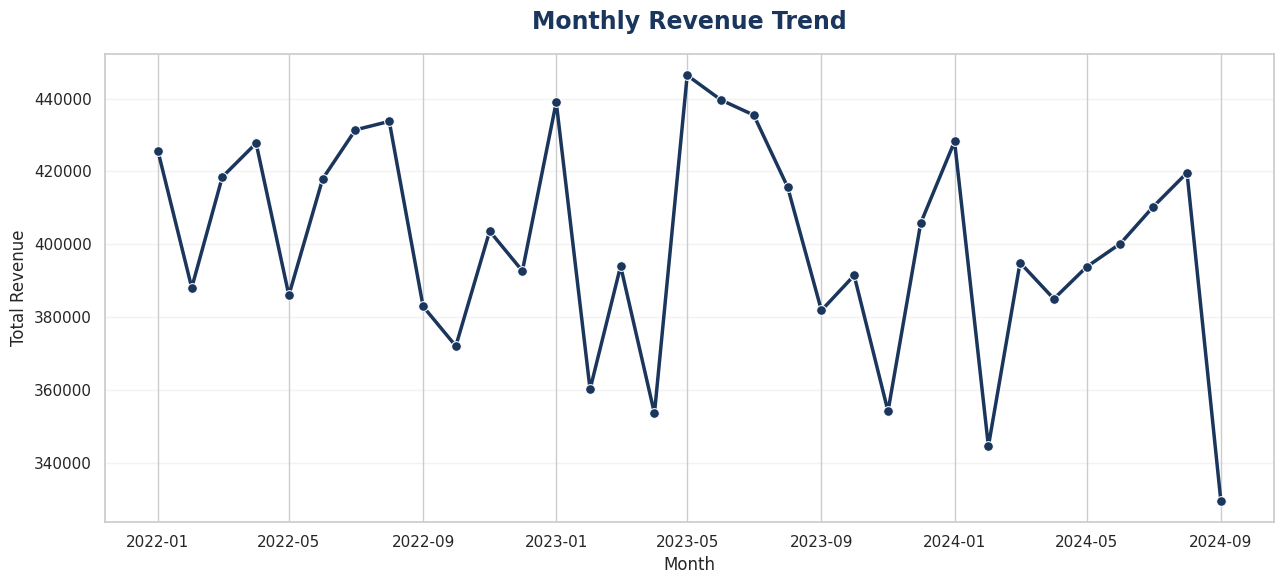

Highest Revenue Month: May 2023
Revenue: 446409.58


In [299]:
# ============================================================
# MONTHLY REVENUE TREND
# ============================================================

# Use completed sales orders
completed_sales = sales_temporal[
    sales_temporal['Order_Status']
    .astype(str)
    .str.strip()
    .str.lower()
    .eq('completed')
].copy()

# Monthly revenue
monthly_revenue = (
    completed_sales
    .dropna(subset=['Order_Date'])
    .groupby(
        completed_sales['Order_Date'].dt.to_period('M')
    )['Order_Total']
    .sum()
    .reset_index()
)

monthly_revenue.columns = [
    'Month',
    'Total_Revenue'
]

monthly_revenue['Month'] = (
    monthly_revenue['Month'].dt.to_timestamp()
)

# Plot
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_revenue,
    x='Month',
    y='Total_Revenue',
    marker='o',
    linewidth=2.5,
    color=COLORS['primary'],
    markersize=7
)

plt.title(
    'Monthly Revenue Trend',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Month')
plt.ylabel('Total Revenue')

plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()


# Display highest revenue month
if not monthly_revenue.empty:

    highest_revenue_month = monthly_revenue.loc[
        monthly_revenue['Total_Revenue'].idxmax()
    ]

    print(
        "Highest Revenue Month:",
        highest_revenue_month['Month'].strftime('%B %Y')
    )

    print(
        "Revenue:",
        round(highest_revenue_month['Total_Revenue'], 2)
    )

## 10.4. Monthly Order Volume — Line Plot

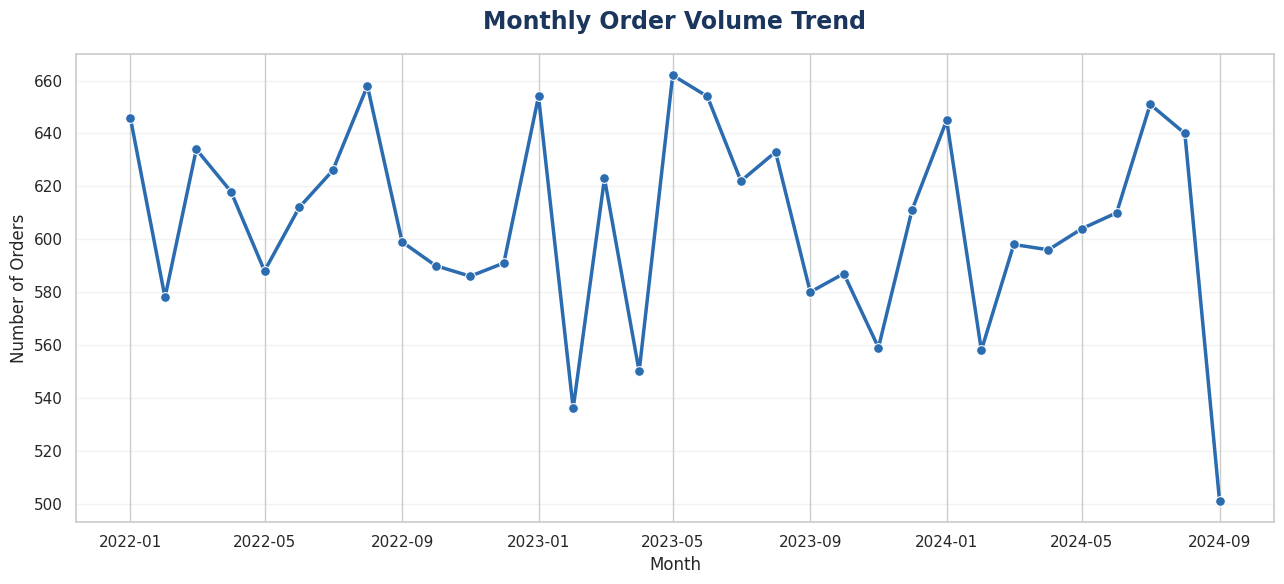

Highest Order Volume Month: May 2023
Number of Orders: 662


In [300]:
# ============================================================
# MONTHLY ORDER VOLUME
# ============================================================

monthly_orders = (
    sales_temporal
    .dropna(subset=['Order_Date'])
    .groupby(
        sales_temporal['Order_Date'].dt.to_period('M')
    )
    .agg(
        Number_of_Orders=('Order_ID', 'nunique'),
        Total_Quantity=('Order_Quantity', 'sum')
    )
    .reset_index()
)

monthly_orders.columns = [
    'Month',
    'Number_of_Orders',
    'Total_Quantity'
]

monthly_orders['Month'] = (
    monthly_orders['Month'].dt.to_timestamp()
)

# Plot monthly order volume
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_orders,
    x='Month',
    y='Number_of_Orders',
    marker='o',
    linewidth=2.5,
    color=COLORS['secondary'],
    markersize=7
)

plt.title(
    'Monthly Order Volume Trend',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Month')
plt.ylabel('Number of Orders')

plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()


# Display highest order volume month
if not monthly_orders.empty:

    highest_order_month = monthly_orders.loc[
        monthly_orders['Number_of_Orders'].idxmax()
    ]

    print(
        "Highest Order Volume Month:",
        highest_order_month['Month'].strftime('%B %Y')
    )

    print(
        "Number of Orders:",
        highest_order_month['Number_of_Orders']
    )

## 10.5. Quarterly Revenue and Order Volume Analysis

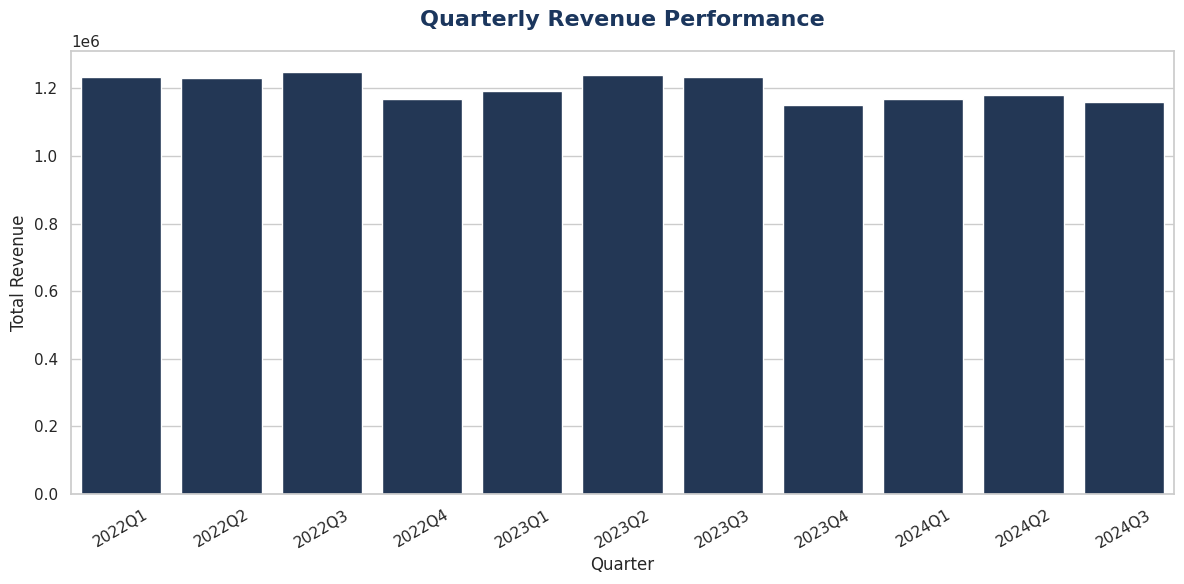

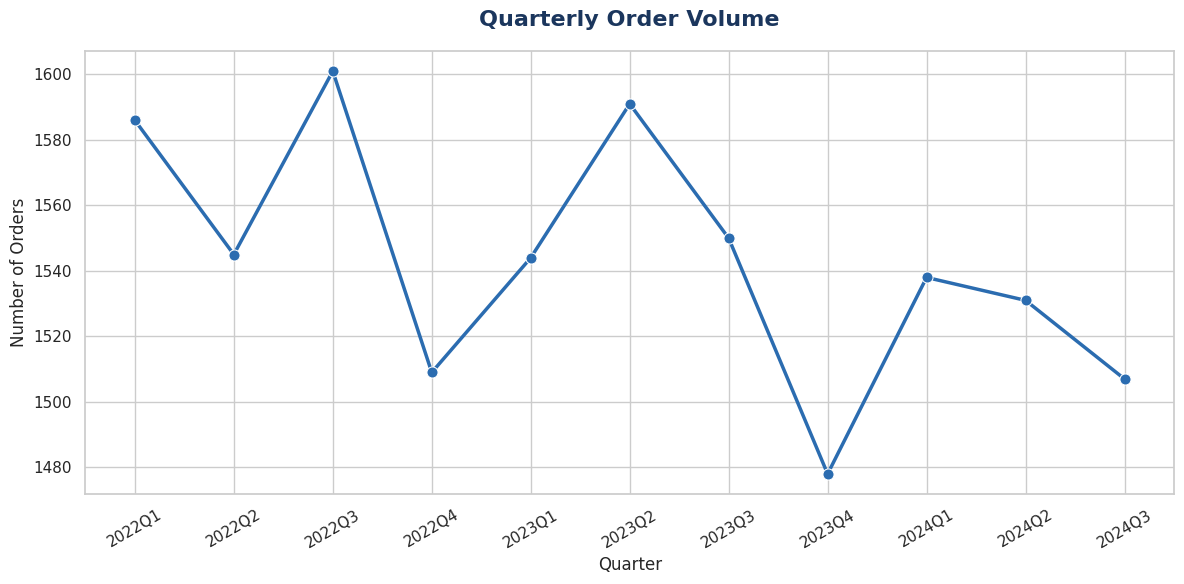


QUARTERLY SALES SUMMARY


SL.NO,Quarter,Total_Revenue,Total_Orders,Total_Quantity
1,2022Q1,"1,232,185.51","1,586","7,886"
2,2022Q2,"1,231,713.24","1,545","7,872"
3,2022Q3,"1,248,077.01","1,601","7,999"
4,2022Q4,"1,168,278.74","1,509","7,594"
5,2023Q1,"1,193,176.09","1,544","7,794"
6,2023Q2,"1,239,564.61","1,591","8,081"
7,2023Q3,"1,233,009.49","1,550","7,915"
8,2023Q4,"1,151,358.87","1,478","7,392"
9,2024Q1,"1,167,680.65","1,538","7,608"
10,2024Q2,"1,178,940.27","1,531","7,669"


In [301]:
# ============================================================
# QUARTERLY REVENUE AND ORDER VOLUME
# ============================================================

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')

quarterly_sales = (
    completed_sales
    .dropna(subset=['Order_Date'])
    .groupby(
        completed_sales['Order_Date'].dt.to_period('Q')
    )
    .agg(
        Total_Revenue=('Order_Total', 'sum'),
        Total_Orders=('Order_ID', 'nunique'),
        Total_Quantity=('Order_Quantity', 'sum')
    )
    .reset_index()
)

quarterly_sales.columns = [
    'Quarter',
    'Total_Revenue',
    'Total_Orders',
    'Total_Quantity'
]

quarterly_sales['Quarter'] = (
    quarterly_sales['Quarter'].astype(str)
)

# ------------------------------------------------------------
# A. Quarterly Revenue
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=quarterly_sales,
    x='Quarter',
    y='Total_Revenue',
    color=COLORS['primary']
)

plt.title(
    'Quarterly Revenue Performance',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Quarter')
plt.ylabel('Total Revenue')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# B. Quarterly Order Volume
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=quarterly_sales,
    x='Quarter',
    y='Total_Orders',
    marker='o',
    linewidth=2.5,
    color=COLORS['secondary'],
    markersize=8
)

plt.title(
    'Quarterly Order Volume',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Quarter')
plt.ylabel('Number of Orders')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


print("\nQUARTERLY SALES SUMMARY")

# Format quarterly sales summary table professionally
quarterly_sales_display = quarterly_sales.copy()
quarterly_sales_display.insert(0, 'SL.NO', range(1, len(quarterly_sales_display) + 1))

styled_quarterly_sales = (
    quarterly_sales_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total_Revenue': '{:,.2f}',
        'Total_Orders': '{:,}',
        'Total_Quantity': '{:,}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Quarter'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Quarterly Revenue and Order Volume Summary')
)

display(styled_quarterly_sales)

## 10.6. Monthly Procurement Cost Trend

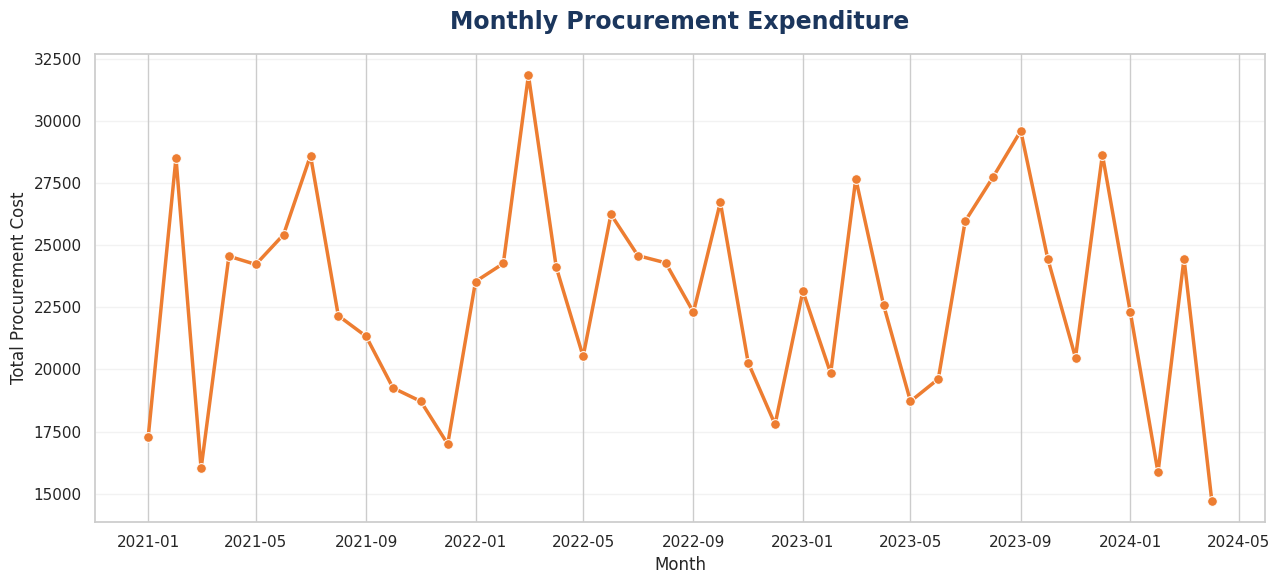


MONTHLY PROCUREMENT SUMMARY


SL.NO,Month,Total_Procurement_Cost,Number_of_Purchase_Orders,Total_Quantity
1,Jan 2021,"17,267.77",53,551
2,Feb 2021,"28,523.66",60,659
3,Mar 2021,"16,012.02",36,414
4,Apr 2021,"24,562.19",61,641
5,May 2021,"24,229.28",48,573
6,Jun 2021,"25,433.14",60,656
7,Jul 2021,"28,615.41",54,599
8,Aug 2021,"22,165.74",53,563
9,Sep 2021,"21,333.31",44,453
10,Oct 2021,"19,256.08",42,442


In [302]:
# ============================================================
# MONTHLY PROCUREMENT COST TREND
# ============================================================

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('warning', '#ED7D31')

monthly_procurement = (
    procurement_temporal
    .dropna(subset=['Order_Date'])
    .groupby(
        procurement_temporal['Order_Date'].dt.to_period('M')
    )
    .agg(
        Total_Procurement_Cost=('Total_Cost', 'sum'),
        Number_of_Purchase_Orders=('PO_ID', 'nunique'),
        Total_Quantity=('Order_Quantity', 'sum')
    )
    .reset_index()
)

monthly_procurement.columns = [
    'Month',
    'Total_Procurement_Cost',
    'Number_of_Purchase_Orders',
    'Total_Quantity'
]

monthly_procurement['Month'] = (
    monthly_procurement['Month'].dt.to_timestamp()
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_procurement,
    x='Month',
    y='Total_Procurement_Cost',
    marker='o',
    linewidth=2.5,
    color=COLORS['warning'],
    markersize=7
)

plt.title(
    'Monthly Procurement Expenditure',
    fontsize=17,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Month')
plt.ylabel('Total Procurement Cost')

plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()


print("\nMONTHLY PROCUREMENT SUMMARY")

# Format monthly procurement summary table professionally
monthly_procurement_display = monthly_procurement.copy()
monthly_procurement_display.insert(0, 'SL.NO', range(1, len(monthly_procurement_display) + 1))
monthly_procurement_display['Month'] = (
    pd.to_datetime(monthly_procurement_display['Month'], errors='coerce')
    .dt.strftime('%b %Y')
)

styled_monthly_procurement = (
    monthly_procurement_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total_Procurement_Cost': '{:,.2f}',
        'Number_of_Purchase_Orders': '{:,}',
        'Total_Quantity': '{:,}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Month'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Monthly Procurement Expenditure Summary')
)

display(styled_monthly_procurement)

## 10.7. Procurement Delivery Variance — Distribution

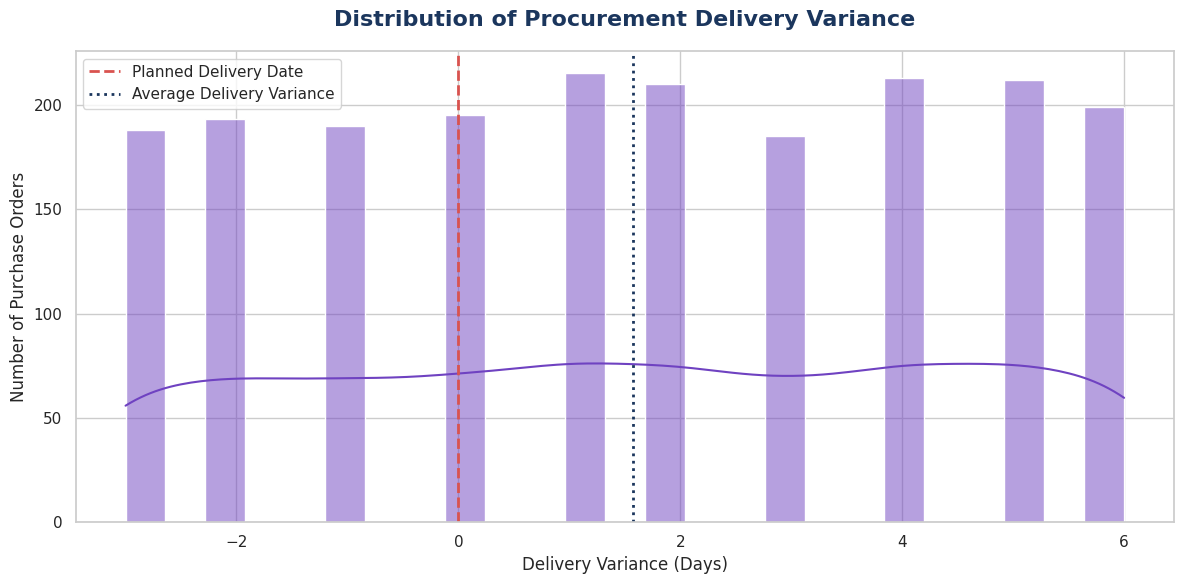

PROCUREMENT DELIVERY VARIANCE SUMMARY
Mean: 1.58 days
Median: 2.0 days
Standard Deviation: 2.85 days
Late Deliveries: 1234
Early Deliveries: 571
On-Time Deliveries: 195


In [303]:
# ============================================================
# PROCUREMENT DELIVERY VARIANCE DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('danger', '#C00000')
COLORS.setdefault('purple', '#6F42C1')

delivery_data = (
    procurement_temporal['Delivery_Variance_Days']
    .dropna()
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=delivery_data,
    bins=25,
    kde=True,
    color=COLORS['purple'],
    edgecolor='white'
)

plt.axvline(
    0,
    color=COLORS['danger'],
    linestyle='--',
    linewidth=2,
    label='Planned Delivery Date'
)

plt.axvline(
    delivery_data.mean(),
    color=COLORS['primary'],
    linestyle=':',
    linewidth=2,
    label='Average Delivery Variance'
)

plt.title(
    'Distribution of Procurement Delivery Variance',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Delivery Variance (Days)')
plt.ylabel('Number of Purchase Orders')

plt.legend()

plt.tight_layout()
plt.show()


# Summary statistics
print("PROCUREMENT DELIVERY VARIANCE SUMMARY")

print("Mean:", round(delivery_data.mean(), 2), "days")
print("Median:", round(delivery_data.median(), 2), "days")
print("Standard Deviation:", round(delivery_data.std(), 2), "days")

print(
    "Late Deliveries:",
    (delivery_data > 0).sum()
)

print(
    "Early Deliveries:",
    (delivery_data < 0).sum()
)

print(
    "On-Time Deliveries:",
    (delivery_data == 0).sum()
)

## 10.8. Product Maturity and Sales Velocity

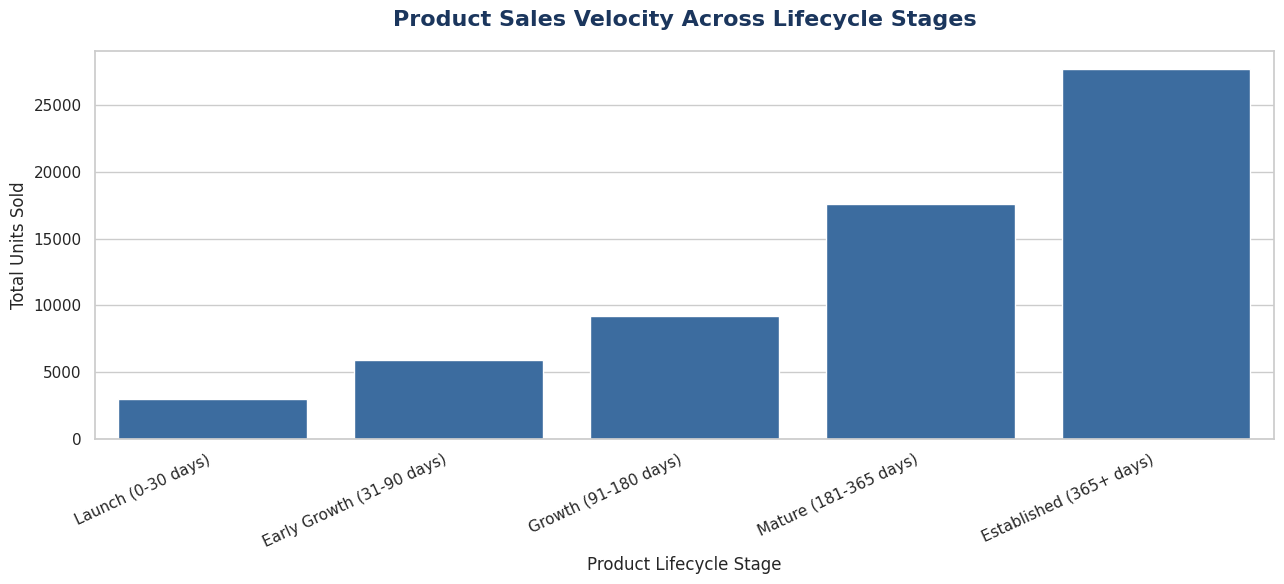

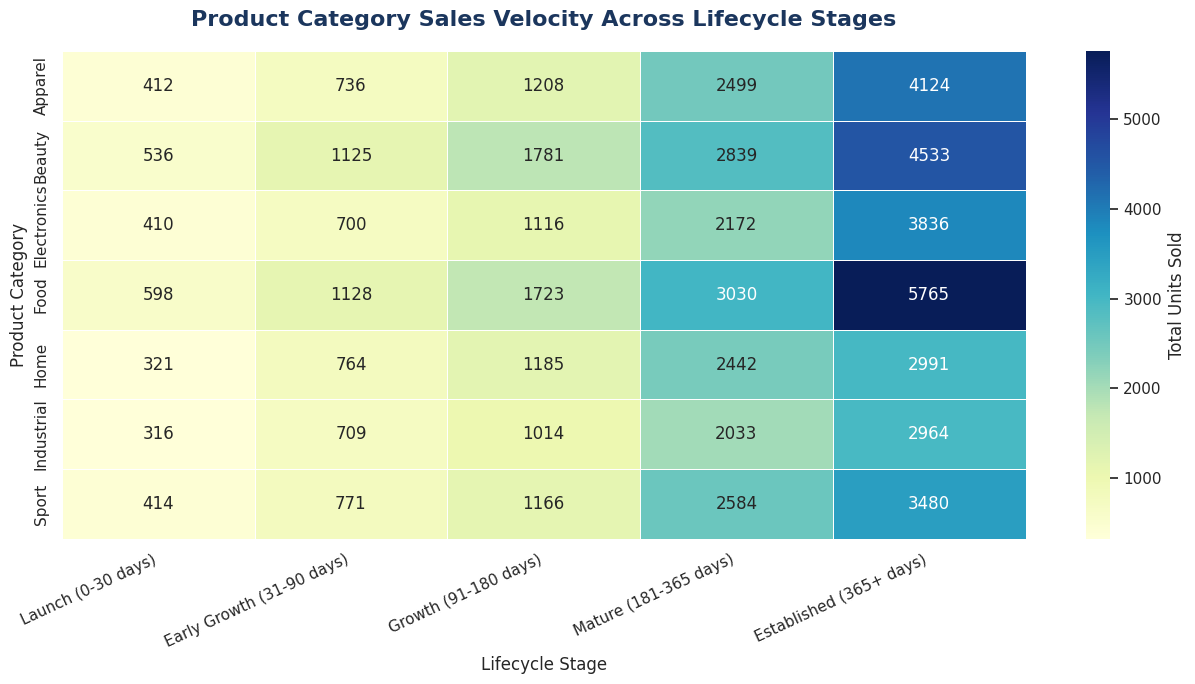

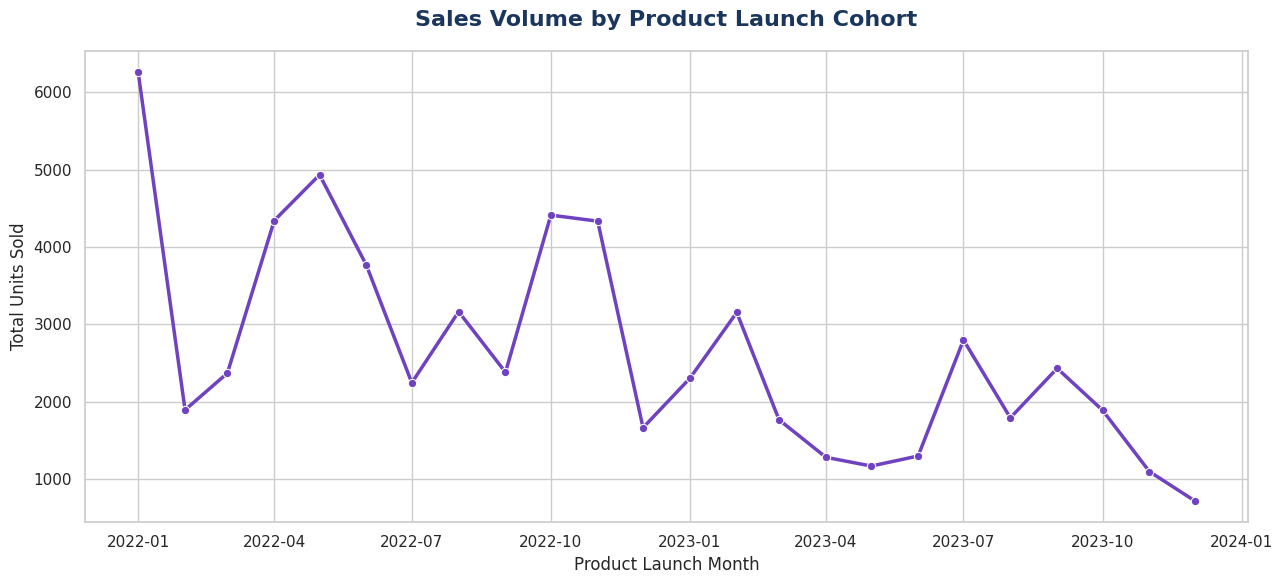


PRODUCT LIFECYCLE SUMMARY


SL.NO,Lifecycle_Stage,Total_Orders,Total_Quantity,Total_Revenue,Average_Quantity
1,Launch (0-30 days),591,"3,007","448,764.07",5.09
2,Early Growth (31-90 days),"1,167","5,933","925,451.88",5.08
3,Growth (91-180 days),"1,819","9,193","1,413,037.17",5.05
4,Mature (181-365 days),"3,530","17,599","2,710,339.58",4.99
5,Established (365+ days),"5,548","27,693","4,177,257.96",4.99


In [304]:
# ============================================================
# PRODUCT MATURITY AND SALES VELOCITY
# ============================================================

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('purple', '#6F42C1')

# ------------------------------------------------------------
# A. Prepare Product Launch Information
# ------------------------------------------------------------

product_cols_needed = [
    c for c in [
        'Product_ID',
        'SKU',
        'Product_Name',
        'Category',
        'Launch_Date',
        'Discontinuation_Date'
    ]
    if c in product_df.columns
]

lifecycle_data = sales_temporal.merge(
    product_df[product_cols_needed].drop_duplicates(subset=['Product_ID']),
    on='Product_ID',
    how='left',
    suffixes=('', '_Product')
)

# Prefer merged Category if sales_temporal didn't already have a non-null one
if 'Category_Product' in lifecycle_data.columns:
    if 'Category' in lifecycle_data.columns:
        lifecycle_data['Category'] = lifecycle_data['Category'].fillna(lifecycle_data['Category_Product'])
    else:
        lifecycle_data['Category'] = lifecycle_data['Category_Product']

lifecycle_data['Order_Date'] = pd.to_datetime(
    lifecycle_data['Order_Date'],
    errors='coerce'
)

lifecycle_data['Launch_Date'] = pd.to_datetime(
    lifecycle_data['Launch_Date'],
    errors='coerce'
)

if 'Discontinuation_Date' in lifecycle_data.columns:
    lifecycle_data['Discontinuation_Date'] = pd.to_datetime(
        lifecycle_data['Discontinuation_Date'],
        errors='coerce'
    )

# Calculate days since product launch
lifecycle_data['Days_Since_Launch'] = (
    lifecycle_data['Order_Date'] -
    lifecycle_data['Launch_Date']
).dt.days

# Keep orders placed on or after launch
lifecycle_data = lifecycle_data[
    lifecycle_data['Days_Since_Launch'] >= 0
].copy()


# ------------------------------------------------------------
# B. Create Product Lifecycle Stages
# ------------------------------------------------------------

lifecycle_bins = [
    -1,
    30,
    90,
    180,
    365,
    np.inf
]

lifecycle_labels = [
    'Launch (0-30 days)',
    'Early Growth (31-90 days)',
    'Growth (91-180 days)',
    'Mature (181-365 days)',
    'Established (365+ days)'
]

lifecycle_data['Lifecycle_Stage'] = pd.cut(
    lifecycle_data['Days_Since_Launch'],
    bins=lifecycle_bins,
    labels=lifecycle_labels
)


# ------------------------------------------------------------
# C. Sales Volume Across Lifecycle Stages
# ------------------------------------------------------------

lifecycle_summary = (
    lifecycle_data
    .groupby(
        'Lifecycle_Stage',
        observed=True,
        as_index=False
    )
    .agg(
        Total_Orders=('Order_ID', 'nunique'),
        Total_Quantity=('Order_Quantity', 'sum'),
        Total_Revenue=('Order_Total', 'sum'),
        Average_Quantity=('Order_Quantity', 'mean')
    )
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=lifecycle_summary,
    x='Lifecycle_Stage',
    y='Total_Quantity',
    color=COLORS['secondary']
)

plt.title(
    'Product Sales Velocity Across Lifecycle Stages',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Product Lifecycle Stage')
plt.ylabel('Total Units Sold')

plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# D. Sales Velocity by Product Category
# ------------------------------------------------------------

category_lifecycle = (
    lifecycle_data
    .groupby(
        ['Category', 'Lifecycle_Stage'],
        observed=True,
        as_index=False
    )
    .agg(
        Total_Quantity=('Order_Quantity', 'sum')
    )
)

lifecycle_heatmap = category_lifecycle.pivot(
    index='Category',
    columns='Lifecycle_Stage',
    values='Total_Quantity'
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    lifecycle_heatmap,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={
        'label': 'Total Units Sold'
    }
)

plt.title(
    'Product Category Sales Velocity Across Lifecycle Stages',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Lifecycle Stage')
plt.ylabel('Product Category')

plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# E. Product Launch Cohort Analysis
# ------------------------------------------------------------

# Group products according to their launch month
lifecycle_data['Launch_Month'] = (
    lifecycle_data['Launch_Date'].dt.to_period('M')
)

cohort_summary = (
    lifecycle_data
    .groupby(
        'Launch_Month',
        as_index=False
    )
    .agg(
        Total_Products=('Product_ID', 'nunique'),
        Total_Orders=('Order_ID', 'nunique'),
        Total_Quantity=('Order_Quantity', 'sum')
    )
)

cohort_summary['Launch_Month'] = (
    cohort_summary['Launch_Month'].dt.to_timestamp()
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=cohort_summary,
    x='Launch_Month',
    y='Total_Quantity',
    marker='o',
    linewidth=2.5,
    color=COLORS['purple']
)

plt.title(
    'Sales Volume by Product Launch Cohort',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Product Launch Month')
plt.ylabel('Total Units Sold')

plt.tight_layout()
plt.show()


print("\nPRODUCT LIFECYCLE SUMMARY")

# Format product lifecycle summary table professionally
lifecycle_summary_display = lifecycle_summary.copy()
lifecycle_summary_display['Lifecycle_Stage'] = lifecycle_summary_display['Lifecycle_Stage'].astype(str)
lifecycle_summary_display.insert(0, 'SL.NO', range(1, len(lifecycle_summary_display) + 1))

styled_lifecycle_summary = (
    lifecycle_summary_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Total_Orders': '{:,}',
        'Total_Quantity': '{:,}',
        'Total_Revenue': '{:,.2f}',
        'Average_Quantity': '{:,.2f}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Lifecycle_Stage'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Product Lifecycle Velocity Summary')
)

display(styled_lifecycle_summary)

## 10.9. Procurement Lead Time Trends Across Supplier Regions

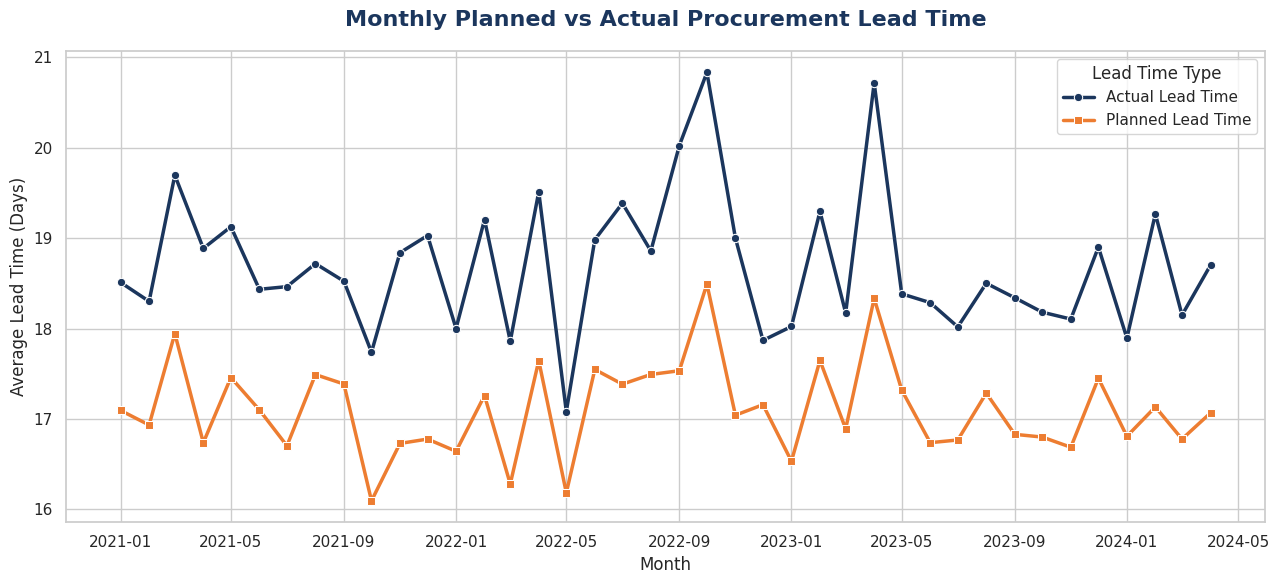

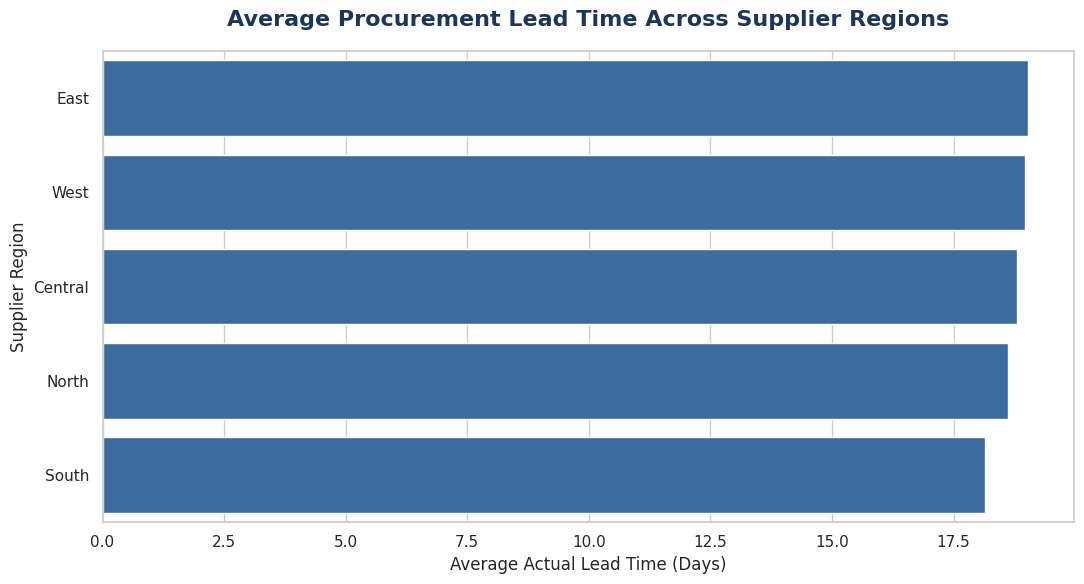

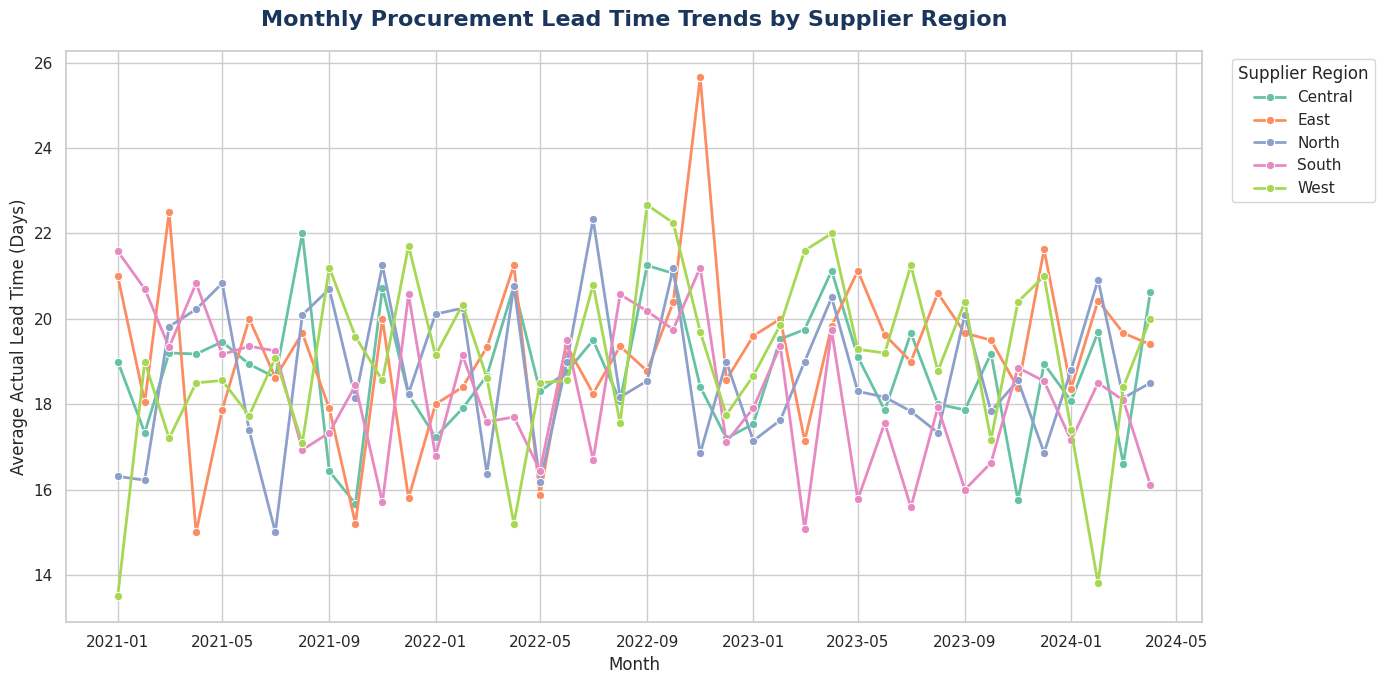


REGIONAL LEAD TIME SUMMARY


SL.NO,Region,Average_Actual_Lead_Time,Average_Planned_Lead_Time,Total_Orders
1,East,19.03,17.13,338
2,West,18.96,17.42,326
3,Central,18.80,17.12,493
4,North,18.63,17.16,379
5,South,18.14,16.80,464


In [305]:
# ============================================================
# PROCUREMENT LEAD TIME TRENDS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('warning', '#ED7D31')

# ------------------------------------------------------------
# A. Monthly Actual Procurement Lead Time
# ------------------------------------------------------------

lead_time_data = procurement_temporal.dropna(
    subset=[
        'Order_Date',
        'Actual_Lead_Time_Days',
        'Region'
    ]
).copy()

# Remove negative or invalid lead times
lead_time_data = lead_time_data[
    lead_time_data['Actual_Lead_Time_Days'] >= 0
]

monthly_lead_time = (
    lead_time_data
    .groupby(
        lead_time_data['Order_Date'].dt.to_period('M')
    )
    .agg(
        Average_Actual_Lead_Time=(
            'Actual_Lead_Time_Days',
            'mean'
        ),
        Average_Planned_Lead_Time=(
            'Planned_Lead_Time_Days',
            'mean'
        )
    )
    .reset_index()
)

monthly_lead_time.columns = [
    'Month',
    'Average_Actual_Lead_Time',
    'Average_Planned_Lead_Time'
]

monthly_lead_time['Month'] = (
    monthly_lead_time['Month'].dt.to_timestamp()
)


# ------------------------------------------------------------
# B. Planned vs Actual Lead Time
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_lead_time,
    x='Month',
    y='Average_Actual_Lead_Time',
    marker='o',
    linewidth=2.5,
    color=COLORS['primary'],
    label='Actual Lead Time'
)

sns.lineplot(
    data=monthly_lead_time,
    x='Month',
    y='Average_Planned_Lead_Time',
    marker='s',
    linewidth=2.5,
    color=COLORS['warning'],
    label='Planned Lead Time'
)

plt.title(
    'Monthly Planned vs Actual Procurement Lead Time',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Month')
plt.ylabel('Average Lead Time (Days)')

plt.legend(title='Lead Time Type')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# C. Regional Procurement Lead Time
# ------------------------------------------------------------

regional_lead_time = (
    lead_time_data
    .groupby('Region', as_index=False)
    .agg(
        Average_Actual_Lead_Time=(
            'Actual_Lead_Time_Days',
            'mean'
        ),
        Average_Planned_Lead_Time=(
            'Planned_Lead_Time_Days',
            'mean'
        ),
        Total_Orders=('PO_ID', 'nunique')
    )
    .sort_values(
        'Average_Actual_Lead_Time',
        ascending=False
    )
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=regional_lead_time,
    x='Average_Actual_Lead_Time',
    y='Region',
    color=COLORS['secondary']
)

plt.title(
    'Average Procurement Lead Time Across Supplier Regions',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Average Actual Lead Time (Days)')
plt.ylabel('Supplier Region')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# D. Monthly Lead Time Across Regions
# ------------------------------------------------------------

regional_monthly = (
    lead_time_data
    .groupby(
        [
            lead_time_data['Order_Date'].dt.to_period('M'),
            'Region'
        ]
    )['Actual_Lead_Time_Days']
    .mean()
    .reset_index()
)

regional_monthly.columns = [
    'Month',
    'Region',
    'Average_Lead_Time'
]

regional_monthly['Month'] = (
    regional_monthly['Month'].dt.to_timestamp()
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=regional_monthly,
    x='Month',
    y='Average_Lead_Time',
    hue='Region',
    marker='o',
    linewidth=2
)

plt.title(
    'Monthly Procurement Lead Time Trends by Supplier Region',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Month')
plt.ylabel('Average Actual Lead Time (Days)')

plt.legend(
    title='Supplier Region',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


print("\nREGIONAL LEAD TIME SUMMARY")

# Format regional lead time summary table professionally
regional_lead_time_display = regional_lead_time.copy()
regional_lead_time_display.insert(0, 'SL.NO', range(1, len(regional_lead_time_display) + 1))

styled_regional_lead_time = (
    regional_lead_time_display.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Average_Actual_Lead_Time': '{:,.2f}',
        'Average_Planned_Lead_Time': '{:,.2f}',
        'Total_Orders': '{:,}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Region'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Regional Procurement Lead Time Summary')
)

display(styled_regional_lead_time)

## 10.10. Fulfillment Latency Seasonality

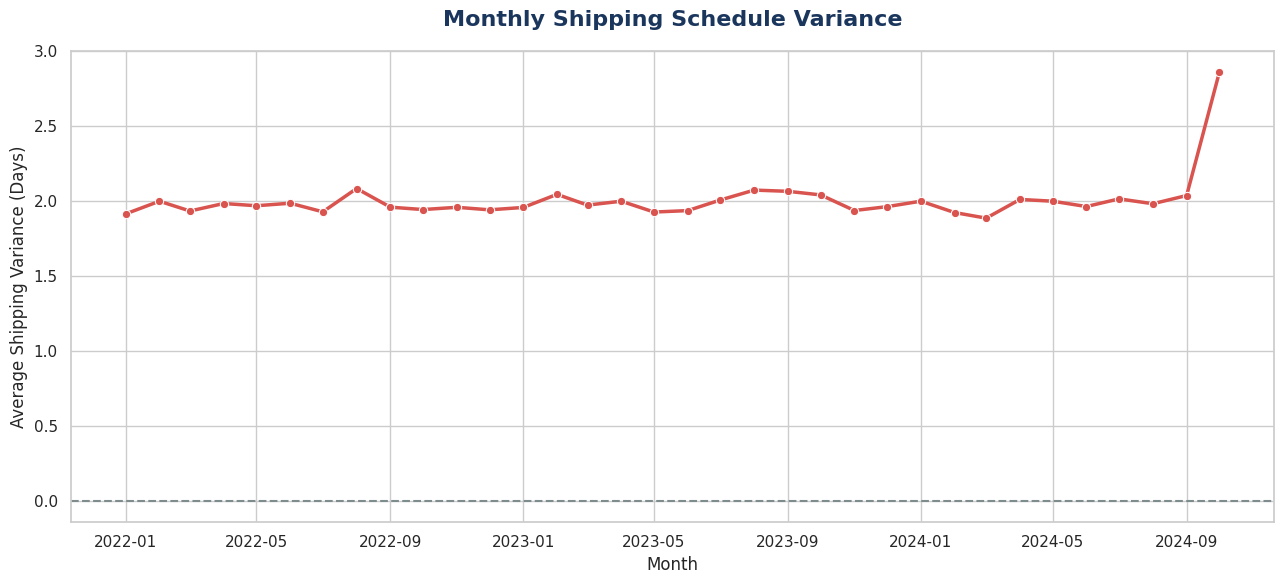

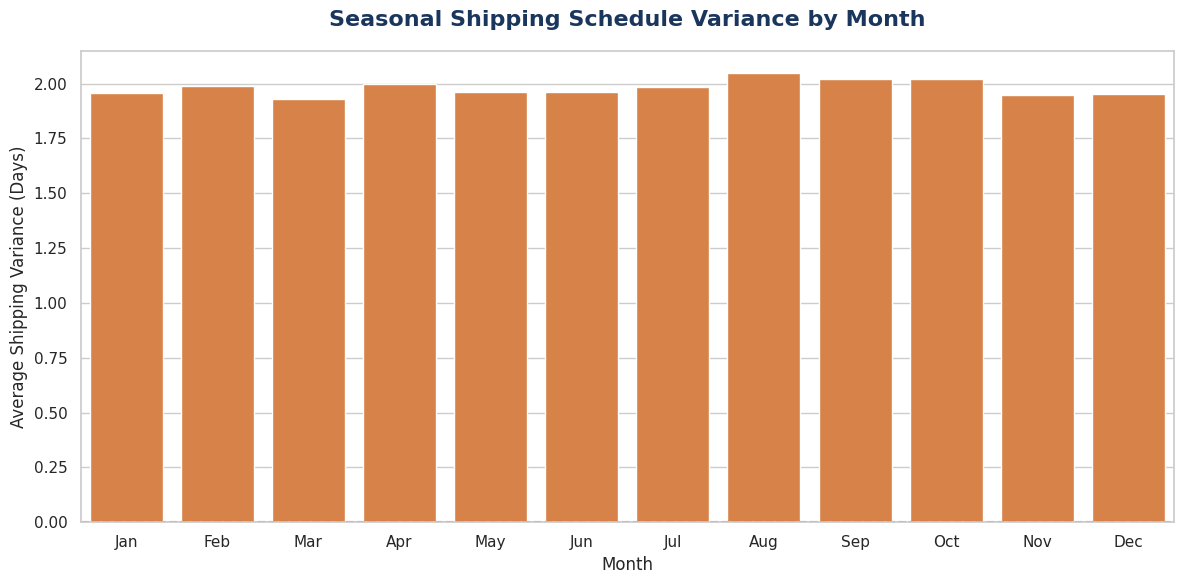

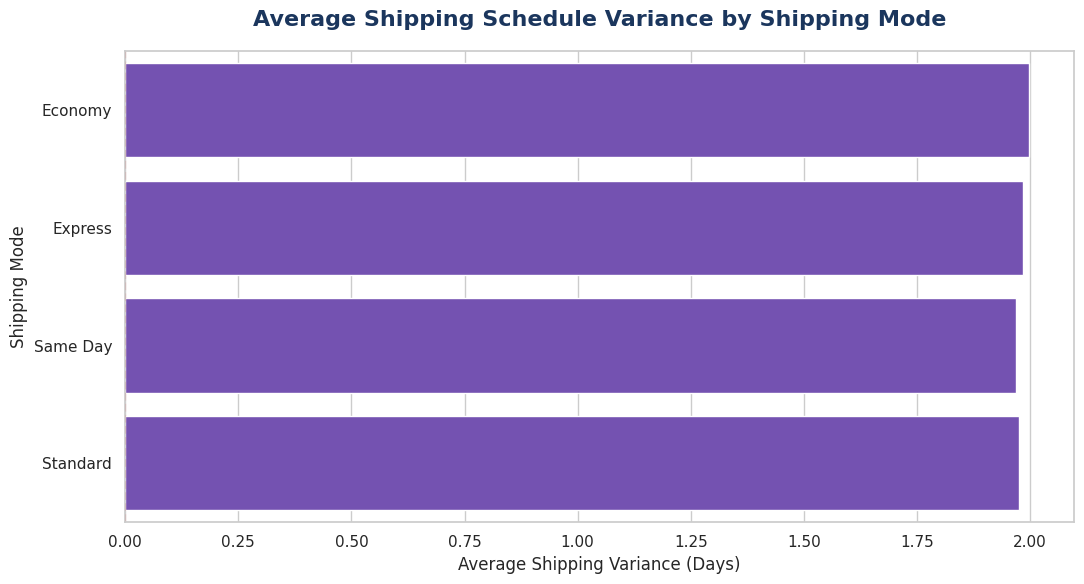

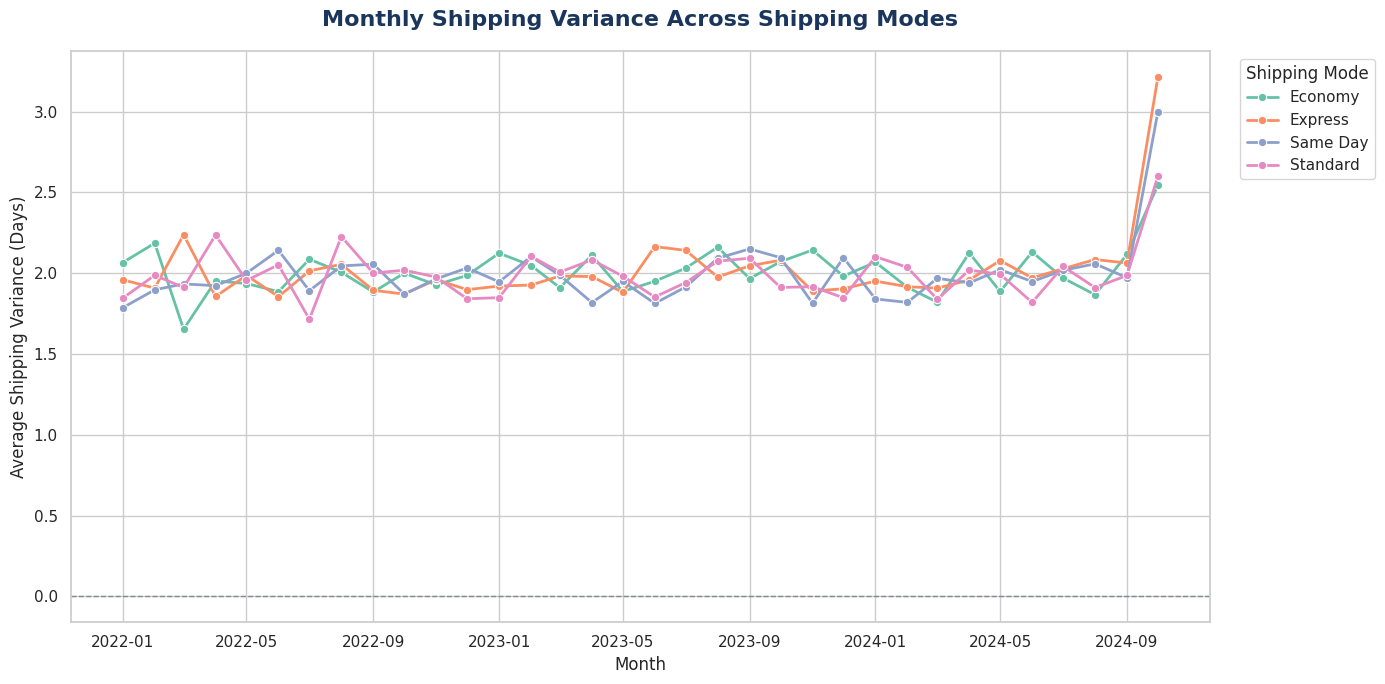


SEASONAL SHIPPING SUMMARY


SL.NO,Shipping_Month_Name,Average_Variance,Total_Shipments
1,Jan,1.96,"1,797"
2,Feb,1.99,"1,707"
3,Mar,1.93,"1,822"
4,Apr,2.00,"1,817"
5,May,1.96,"1,822"
6,Jun,1.96,"1,860"
7,Jul,1.98,"1,871"
8,Aug,2.05,"1,949"
9,Sep,2.02,"1,775"
10,Oct,2.02,"1,231"



SHIPPING MODE VARIANCE SUMMARY


SL.NO,Shipping_Mode,Average_Variance,Median_Variance,Total_Shipments
1,Economy,2.00,2.00,"4,972"
2,Express,1.98,2.00,"4,979"
3,Same Day,1.97,2.00,"5,033"
4,Standard,1.98,2.00,"5,016"


In [306]:
# ============================================================
# FULFILLMENT LATENCY SEASONALITY
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('warning', '#ED7D31')
COLORS.setdefault('danger', '#C00000')
COLORS.setdefault('grey', '#6C757D')
COLORS.setdefault('purple', '#6F42C1')

# ------------------------------------------------------------
# A. Prepare Valid Shipping Records
# ------------------------------------------------------------

shipping_data = sales_temporal.dropna(
    subset=[
        'Shipping_Date_Actual',
        'Shipping_Date_Scheduled',
        'Order_Date'
    ]
).copy()

shipping_data['Shipping_Variance_Days'] = (
    shipping_data['Shipping_Date_Actual'] -
    shipping_data['Shipping_Date_Scheduled']
).dt.days

# Extract shipping month
shipping_data['Shipping_Month'] = (
    shipping_data['Shipping_Date_Actual'].dt.month
)

shipping_data['Shipping_Month_Name'] = (
    shipping_data['Shipping_Date_Actual'].dt.strftime('%b')
)


# ------------------------------------------------------------
# B. Monthly Average Shipping Variance
# ------------------------------------------------------------

monthly_shipping_variance = (
    shipping_data
    .groupby(
        shipping_data['Shipping_Date_Actual'].dt.to_period('M')
    )
    .agg(
        Average_Variance=(
            'Shipping_Variance_Days',
            'mean'
        ),
        Median_Variance=(
            'Shipping_Variance_Days',
            'median'
        ),
        Total_Shipments=('Order_ID', 'nunique')
    )
    .reset_index()
)

monthly_shipping_variance.columns = [
    'Month',
    'Average_Variance',
    'Median_Variance',
    'Total_Shipments'
]

monthly_shipping_variance['Month'] = (
    monthly_shipping_variance['Month'].dt.to_timestamp()
)


plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_shipping_variance,
    x='Month',
    y='Average_Variance',
    marker='o',
    linewidth=2.5,
    color=COLORS['danger']
)

plt.axhline(
    0,
    color=COLORS['grey'],
    linestyle='--',
    linewidth=1.5
)

plt.title(
    'Monthly Shipping Schedule Variance',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Month')
plt.ylabel('Average Shipping Variance (Days)')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# C. Month-wise Shipping Variance
# ------------------------------------------------------------

month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

seasonal_shipping = (
    shipping_data
    .groupby('Shipping_Month_Name', as_index=False)
    .agg(
        Average_Variance=(
            'Shipping_Variance_Days',
            'mean'
        ),
        Total_Shipments=('Order_ID', 'nunique')
    )
)

seasonal_shipping['Shipping_Month_Name'] = pd.Categorical(
    seasonal_shipping['Shipping_Month_Name'],
    categories=month_order,
    ordered=True
)

seasonal_shipping = seasonal_shipping.sort_values(
    'Shipping_Month_Name'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=seasonal_shipping,
    x='Shipping_Month_Name',
    y='Average_Variance',
    color=COLORS['warning']
)

plt.axhline(
    0,
    color=COLORS['danger'],
    linestyle='--',
    linewidth=1.5
)

plt.title(
    'Seasonal Shipping Schedule Variance by Month',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Month')
plt.ylabel('Average Shipping Variance (Days)')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# D. Shipping Variance by Shipping Mode
# ------------------------------------------------------------

mode_shipping_variance = (
    shipping_data
    .groupby('Shipping_Mode', as_index=False)
    .agg(
        Average_Variance=(
            'Shipping_Variance_Days',
            'mean'
        ),
        Median_Variance=(
            'Shipping_Variance_Days',
            'median'
        ),
        Total_Shipments=('Order_ID', 'nunique')
    )
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=mode_shipping_variance,
    x='Average_Variance',
    y='Shipping_Mode',
    color=COLORS['purple']
)

plt.axvline(
    0,
    color=COLORS['danger'],
    linestyle='--',
    linewidth=1.5
)

plt.title(
    'Average Shipping Schedule Variance by Shipping Mode',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Average Shipping Variance (Days)')
plt.ylabel('Shipping Mode')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# E. Monthly Shipping Variance by Shipping Mode
# ------------------------------------------------------------

mode_monthly_variance = (
    shipping_data
    .groupby(
        [
            shipping_data['Shipping_Date_Actual'].dt.to_period('M'),
            'Shipping_Mode'
        ]
    )['Shipping_Variance_Days']
    .mean()
    .reset_index()
)

mode_monthly_variance.columns = [
    'Month',
    'Shipping_Mode',
    'Average_Variance'
]

mode_monthly_variance['Month'] = (
    mode_monthly_variance['Month'].dt.to_timestamp()
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=mode_monthly_variance,
    x='Month',
    y='Average_Variance',
    hue='Shipping_Mode',
    marker='o',
    linewidth=2
)

plt.axhline(
    0,
    color=COLORS['grey'],
    linestyle='--',
    linewidth=1
)

plt.title(
    'Monthly Shipping Variance Across Shipping Modes',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Month')
plt.ylabel('Average Shipping Variance (Days)')

plt.legend(
    title='Shipping Mode',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


def style_shipping_variance_table(df, caption_text, left_cols):
    df_display = df.copy()
    for col in left_cols:
        if col in df_display.columns and pd.api.types.is_categorical_dtype(df_display[col]):
            df_display[col] = df_display[col].astype(str)
    df_display.insert(0, 'SL.NO', range(1, len(df_display) + 1))

    format_map = {'SL.NO': '{:.0f}'}
    for col in df_display.columns:
        if col == 'SL.NO' or col in left_cols:
            continue
        if pd.api.types.is_integer_dtype(df_display[col]):
            format_map[col] = '{:,}'
        elif pd.api.types.is_float_dtype(df_display[col]):
            format_map[col] = '{:,.2f}'

    return (
        df_display.style
        .hide(axis='index')
        .format(format_map, na_rep='N/A')
        .set_properties(**{
            'text-align': 'center',
            'padding': '12px 20px',
            'font-size': '14px',
            'border': '1px solid #D6D6D6'
        })
        .set_properties(
            subset=left_cols,
            **{'text-align': 'left', 'font-weight': 'bold'}
        )
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#1B365D'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '14px 20px'),
                    ('font-size', '14px'),
                    ('border', '1px solid white')
                ]
            },
            {
                'selector': 'caption',
                'props': [
                    ('caption-side', 'top'),
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#1B365D'),
                    ('padding', '12px')
                ]
            },
            {
                'selector': 'table',
                'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', 'auto')
                ]
            }
        ])
        .set_caption(caption_text)
    )


print("\nSEASONAL SHIPPING SUMMARY")
display(
    style_shipping_variance_table(
        seasonal_shipping,
        'Supply Chain Analytics - Seasonal Shipping Schedule Variance Summary',
        ['Shipping_Month_Name']
    )
)

print("\nSHIPPING MODE VARIANCE SUMMARY")
display(
    style_shipping_variance_table(
        mode_shipping_variance,
        'Supply Chain Analytics - Shipping Schedule Variance by Shipping Mode',
        ['Shipping_Mode']
    )
)

## 10.11. Temporal Analysis — Final Summary

In [307]:
# ============================================================
# TEMPORAL ANALYSIS - FINAL SUMMARY
# ============================================================

print("=" * 65)
print("TEMPORAL ANALYSIS - KEY FINDINGS")
print("=" * 65)


# ------------------------------------------------------------
# 1. Highest Revenue Month
# ------------------------------------------------------------

if not monthly_revenue.empty:

    highest_revenue = monthly_revenue.loc[
        monthly_revenue['Total_Revenue'].idxmax()
    ]

    print("\n1. SALES REVENUE SEASONALITY")

    print(
        "Highest Revenue Month:",
        highest_revenue['Month'].strftime('%B %Y')
    )

    print(
        "Revenue:",
        round(highest_revenue['Total_Revenue'], 2)
    )


# ------------------------------------------------------------
# 2. Highest Order Volume Month
# ------------------------------------------------------------

if not monthly_orders.empty:

    highest_volume = monthly_orders.loc[
        monthly_orders['Number_of_Orders'].idxmax()
    ]

    print("\n2. ORDER VOLUME")

    print(
        "Highest Order Volume Month:",
        highest_volume['Month'].strftime('%B %Y')
    )

    print(
        "Orders:",
        highest_volume['Number_of_Orders']
    )


# ------------------------------------------------------------
# 3. Procurement Delivery Variance
# ------------------------------------------------------------

if not delivery_data.empty:

    print("\n3. PROCUREMENT DELIVERY PERFORMANCE")

    print(
        "Average Delivery Variance:",
        round(delivery_data.mean(), 2),
        "days"
    )

    print(
        "Late Purchase Orders:",
        (delivery_data > 0).sum()
    )


# ------------------------------------------------------------
# 4. Highest Procurement Cost Month
# ------------------------------------------------------------

if not monthly_procurement.empty:

    highest_procurement = monthly_procurement.loc[
        monthly_procurement['Total_Procurement_Cost'].idxmax()
    ]

    print("\n4. PROCUREMENT EXPENDITURE")

    print(
        "Highest Procurement Month:",
        highest_procurement['Month'].strftime('%B %Y')
    )

    print(
        "Procurement Cost:",
        round(highest_procurement['Total_Procurement_Cost'], 2)
    )


# ------------------------------------------------------------
# 5. Product Lifecycle
# ------------------------------------------------------------

if not lifecycle_summary.empty:

    highest_lifecycle = lifecycle_summary.loc[
        lifecycle_summary['Total_Quantity'].idxmax()
    ]

    print("\n5. PRODUCT MATURITY AND SALES VELOCITY")

    print(
        "Highest Sales Lifecycle Stage:",
        highest_lifecycle['Lifecycle_Stage']
    )

    print(
        "Total Units Sold:",
        highest_lifecycle['Total_Quantity']
    )


# ------------------------------------------------------------
# 6. Procurement Lead Time
# ------------------------------------------------------------

if not regional_lead_time.empty:

    slowest_region = regional_lead_time.loc[
        regional_lead_time['Average_Actual_Lead_Time'].idxmax()
    ]

    print("\n6. PROCUREMENT LEAD TIME")

    print(
        "Highest Average Lead Time Region:",
        slowest_region['Region']
    )

    print(
        "Average Lead Time:",
        round(
            slowest_region['Average_Actual_Lead_Time'],
            2
        ),
        "days"
    )


# ------------------------------------------------------------
# 7. Shipping Schedule Variance
# ------------------------------------------------------------

if not seasonal_shipping.empty:

    highest_shipping_variance = seasonal_shipping.loc[
        seasonal_shipping['Average_Variance'].idxmax()
    ]

    print("\n7. FULFILLMENT LATENCY SEASONALITY")

    print(
        "Month with Highest Average Shipping Variance:",
        highest_shipping_variance['Shipping_Month_Name']
    )

    print(
        "Average Variance:",
        round(
            highest_shipping_variance['Average_Variance'],
            2
        ),
        "days"
    )


print("\n" + "=" * 65)
print("TEMPORAL ANALYSIS COMPLETED")
print("=" * 65)

TEMPORAL ANALYSIS - KEY FINDINGS

1. SALES REVENUE SEASONALITY
Highest Revenue Month: May 2023
Revenue: 446409.58

2. ORDER VOLUME
Highest Order Volume Month: May 2023
Orders: 662

3. PROCUREMENT DELIVERY PERFORMANCE
Average Delivery Variance: 1.58 days
Late Purchase Orders: 1234

4. PROCUREMENT EXPENDITURE
Highest Procurement Month: March 2022
Procurement Cost: 31848.48

5. PRODUCT MATURITY AND SALES VELOCITY
Highest Sales Lifecycle Stage: Established (365+ days)
Total Units Sold: 27693

6. PROCUREMENT LEAD TIME
Highest Average Lead Time Region: East
Average Lead Time: 19.03 days

7. FULFILLMENT LATENCY SEASONALITY
Month with Highest Average Shipping Variance: Aug
Average Variance: 2.05 days

TEMPORAL ANALYSIS COMPLETED


# 11. Outlier Analysis

SL.NO,Category,Variable,Outlier_Percentage
1,Sales,Order Quantity,2.13%
2,Sales,Order Value,1.98%
3,Sales,Profit,1.39%
4,Sales,Unit Price,0.00%
5,Product,Unit Cost,0.00%
6,Product,Standard Price,0.00%
7,Procurement,Order Quantity,0.70%
8,Procurement,Unit Cost,0.00%
9,Procurement,Total Cost,0.40%
10,Delivery,Shipping Variance,0.00%


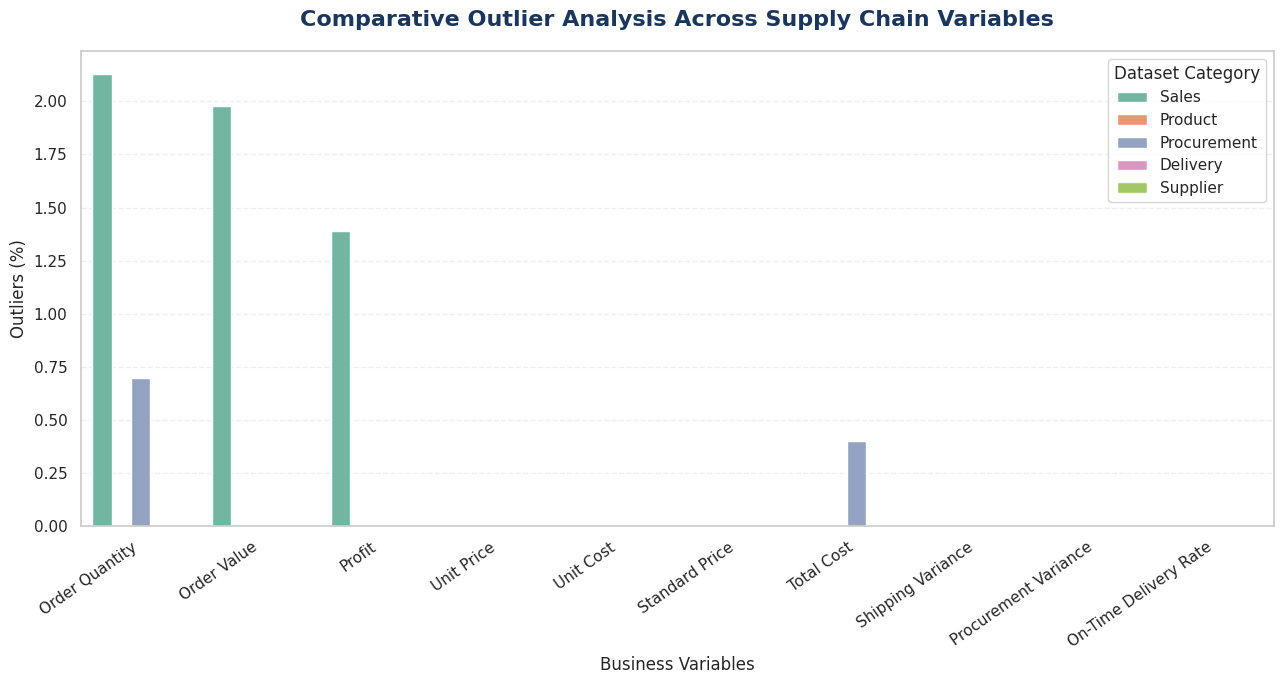

CATEGORY-WISE AVERAGE OUTLIER PERCENTAGE


SL.NO,Category,Outlier_Percentage
1,Sales,1.38%
2,Procurement,0.37%
3,Delivery,0.00%
4,Product,0.00%
5,Supplier,0.00%


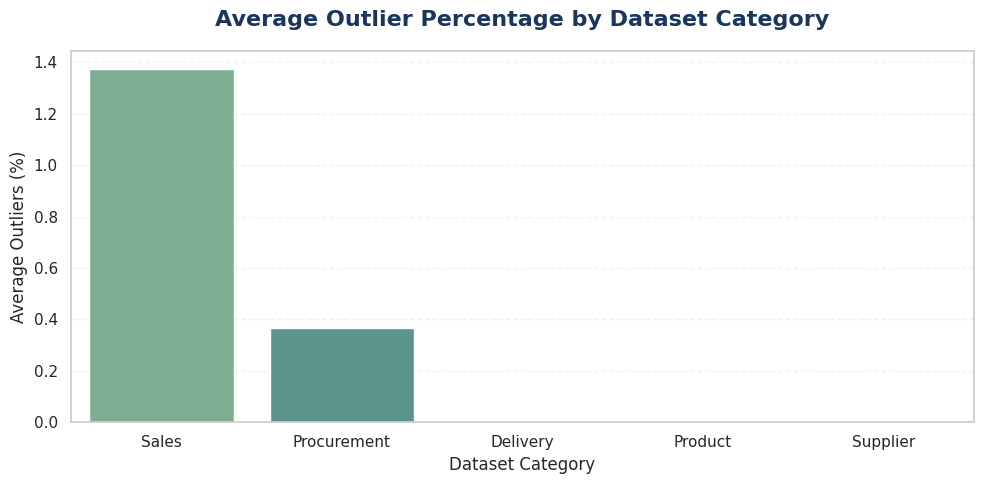


             FINAL OUTLIER ANALYSIS CONCLUSION

1. Highest average outlier percentage: Sales (1.38%).

2. Variable with the highest outlier percentage: Order Quantity (Sales: 2.13%).

3. Average outlier percentage across all analysed variables: 0.55%.

4. Business Interpretation:
   - High sales outliers may indicate unusually large orders or profits.
   - Procurement outliers may indicate unusually high purchasing quantities or costs.
   - Delivery outliers may indicate exceptional early or delayed shipments.
   - Supplier outliers may indicate unusually high or low delivery performance.



In [308]:
# ============================================================
# SUMMARIZED OUTLIER ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')


def resolve_df(candidates):
    for name in candidates:
        if name in globals() and isinstance(globals()[name], pd.DataFrame):
            return globals()[name]
    return pd.DataFrame()


sales_ref = resolve_df([
    'sales_temporal',
    'sales_multi',
    'sales_analysis',
    'shipping_analysis',
    'sales_df',
    'orders_df'
])

product_ref = resolve_df(['product_df'])

procurement_ref = resolve_df([
    'procurement_temporal',
    'procurement_multi',
    'procurement_analysis',
    'procurement_df'
])

supplier_ref = resolve_df(['supplier_df'])

# Ensure Shipping_Variance_Days exists on sales_ref if date columns are available
if (
    not sales_ref.empty
    and 'Shipping_Variance_Days' not in sales_ref.columns
    and {'Shipping_Date_Actual', 'Shipping_Date_Scheduled'}.issubset(sales_ref.columns)
):
    sales_ref = sales_ref.copy()
    sales_ref['Shipping_Variance_Days'] = (
        pd.to_datetime(sales_ref['Shipping_Date_Actual'], errors='coerce') -
        pd.to_datetime(sales_ref['Shipping_Date_Scheduled'], errors='coerce')
    ).dt.days

# Ensure Delivery_Variance_Days exists on procurement_ref if date columns are available
if (
    not procurement_ref.empty
    and 'Delivery_Variance_Days' not in procurement_ref.columns
    and {'Delivery_Date_Actual', 'Delivery_Date_Planned'}.issubset(procurement_ref.columns)
):
    procurement_ref = procurement_ref.copy()
    procurement_ref['Delivery_Variance_Days'] = (
        pd.to_datetime(procurement_ref['Delivery_Date_Actual'], errors='coerce') -
        pd.to_datetime(procurement_ref['Delivery_Date_Planned'], errors='coerce')
    ).dt.days


# IQR Method for Outlier Detection
def calculate_outlier_percentage(df, column):
    if df is None or df.empty or column not in df.columns:
        return 0.0

    data = pd.to_numeric(df[column], errors='coerce').dropna()

    if len(data) == 0:
        return 0.0

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[(data < lower_limit) | (data > upper_limit)]

    return round((len(outliers) / len(data)) * 100, 2)


# ------------------------------------------------------------
# SELECT IMPORTANT NUMERICAL VARIABLES
# ------------------------------------------------------------

outlier_variables = {
    'Sales': {
        'Order Quantity': (sales_ref, 'Order_Quantity'),
        'Order Value': (sales_ref, 'Order_Total'),
        'Profit': (sales_ref, 'Profit_Per_Order'),
        'Unit Price': (sales_ref, 'Unit_Price')
    },
    'Product': {
        'Unit Cost': (product_ref, 'Unit_Cost'),
        'Standard Price': (product_ref, 'Standard_Price')
    },
    'Procurement': {
        'Order Quantity': (procurement_ref, 'Order_Quantity'),
        'Unit Cost': (procurement_ref, 'Unit_Cost'),
        'Total Cost': (procurement_ref, 'Total_Cost')
    },
    'Delivery': {
        'Shipping Variance': (sales_ref, 'Shipping_Variance_Days'),
        'Procurement Variance': (procurement_ref, 'Delivery_Variance_Days')
    },
    'Supplier': {
        'On-Time Delivery Rate': (supplier_ref, 'On_Time_Delivery_Rate')
    }
}


# ------------------------------------------------------------
# CALCULATE OUTLIER PERCENTAGES
# ------------------------------------------------------------

outlier_results = []

for category, variables in outlier_variables.items():
    for variable, (df, column) in variables.items():
        percentage = calculate_outlier_percentage(df, column)
        outlier_results.append({
            'Category': category,
            'Variable': variable,
            'Outlier_Percentage': percentage
        })

outlier_summary = pd.DataFrame(outlier_results)

styled_outlier_summary = (
    outlier_summary.copy()
    .assign(**{'SL.NO': range(1, len(outlier_summary) + 1)})
    [['SL.NO', 'Category', 'Variable', 'Outlier_Percentage']]
    .style
    .hide(axis='index')
    .format({
        'SL.NO': '{:.0f}',
        'Outlier_Percentage': '{:,.2f}%'
    }, na_rep='N/A')
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Category', 'Variable'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])
    .set_caption('Supply Chain Analytics - Variable Outlier Summary (IQR Method)')
)

display(styled_outlier_summary)


# ------------------------------------------------------------
# COMPARE ALL OUTLIERS IN ONE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(13, 7))

sns.barplot(
    data=outlier_summary,
    x='Variable',
    y='Outlier_Percentage',
    hue='Category',
    palette='Set2'
)

plt.title(
    'Comparative Outlier Analysis Across Supply Chain Variables',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)

plt.xlabel('Business Variables')
plt.ylabel('Outliers (%)')

plt.xticks(rotation=35, ha='right')
plt.legend(title='Dataset Category')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CATEGORY-WISE OUTLIER SUMMARY
# ------------------------------------------------------------

category_summary = (
    outlier_summary
    .groupby('Category')['Outlier_Percentage']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("CATEGORY-WISE AVERAGE OUTLIER PERCENTAGE")

styled_category_summary = (
    category_summary.copy()
    .assign(**{'SL.NO': range(1, len(category_summary) + 1)})
    [['SL.NO', 'Category', 'Outlier_Percentage']]
    .style
    .hide(axis='index')
    .format({
        'SL.NO': '{:.0f}',
        'Outlier_Percentage': '{:,.2f}%'
    }, na_rep='N/A')
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Category'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])
    .set_caption('Supply Chain Analytics - Category-Wise Average Outlier Percentage')
)

display(styled_category_summary)


# ------------------------------------------------------------
# FINAL SUMMARY GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_summary,
    x='Category',
    y='Outlier_Percentage',
    hue='Category',
    palette='crest',
    legend=False
)

plt.title(
    'Average Outlier Percentage by Dataset Category',
    fontsize=16,
    fontweight='bold',
    color=COLORS['primary'],
    pad=18
)
plt.xlabel('Dataset Category')
plt.ylabel('Average Outliers (%)')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# AUTOMATIC FINAL CONCLUSION
# ------------------------------------------------------------

highest_category = category_summary.iloc[0]

highest_variable = outlier_summary.loc[
    outlier_summary['Outlier_Percentage'].idxmax()
]

overall_outlier_percentage = outlier_summary[
    'Outlier_Percentage'
].mean()

print("\n" + "=" * 100)
print("             FINAL OUTLIER ANALYSIS CONCLUSION")
print("=" * 100)

print(
    f"\n1. Highest average outlier percentage: "
    f"{highest_category['Category']} "
    f"({highest_category['Outlier_Percentage']:.2f}%)."
)

print(
    f"\n2. Variable with the highest outlier percentage: "
    f"{highest_variable['Variable']} "
    f"({highest_variable['Category']}: "
    f"{highest_variable['Outlier_Percentage']:.2f}%)."
)

print(
    f"\n3. Average outlier percentage across all analysed "
    f"variables: {overall_outlier_percentage:.2f}%."
)

print(
    "\n4. Business Interpretation:"
    "\n   - High sales outliers may indicate unusually large "
    "orders or profits."
    "\n   - Procurement outliers may indicate unusually high "
    "purchasing quantities or costs."
    "\n   - Delivery outliers may indicate exceptional early "
    "or delayed shipments."
    "\n   - Supplier outliers may indicate unusually high or "
    "low delivery performance."
)

print("\n" + "=" * 100)

# 12. Statistical Analysis


COMPARATIVE STATISTICAL ANALYSIS



SL.NO,Statistical Relationship,Correlation,Direction,Strength
1,Discount vs Profit,-0.254,Negative,Weak
2,Planned Lead Time vs Delivery Variance,-0.024,Negative,Negligible
3,Unit Cost vs Standard Price,-0.018,Negative,Negligible
4,Supplier Reliability vs Delivery Variance,+0.012,Positive,Negligible
5,Procurement Quantity vs Delivery Variance,+0.012,Positive,Negligible


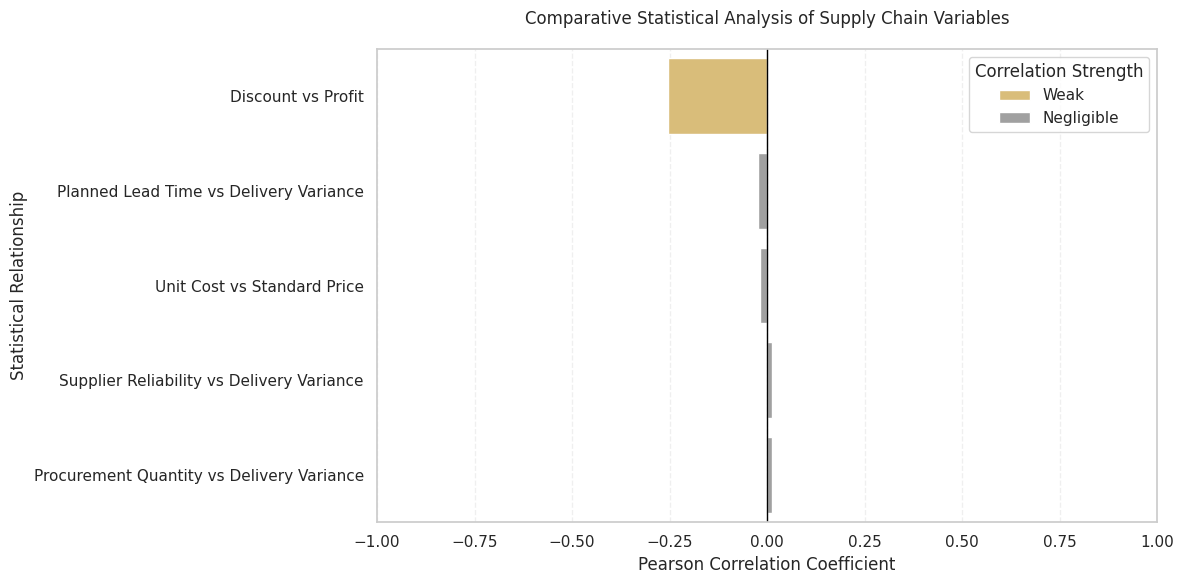


       FINAL STATISTICAL ANALYSIS CONCLUSION

1. STRONGEST OBSERVED RELATIONSHIP
   Discount vs Profit
   Pearson Correlation: -0.254
   Direction: Negative
   Actual Strength: Weak

2. WEAKEST OBSERVED RELATIONSHIP
   Supplier Reliability vs Delivery Variance
   Pearson Correlation: +0.012
   Actual Strength: Negligible

3. OVERALL FINDINGS
   Negligible relationships: 4
   Weak relationships: 1
   Moderate relationships: 0
   Strong or very strong relationships: 0

4. FINAL CONCLUSION
   Most analysed variables show weak or negligible linear relationships.
   Discount vs Profit has the highest absolute correlation, but its relationship is still weak.
   No strong linear relationship was identified among the tested variables.



In [309]:
# ============================================================
# SUMMARISED STATISTICAL ANALYSIS
# ============================================================

# CREATE SUMMARY TABLE

stats_summary = pd.DataFrame(
    statistical_results.items(),
    columns=['Statistical Relationship', 'Correlation']
)


# CLASSIFY CORRELATION STRENGTH

def classify_correlation(r):

    if pd.isna(r):
        return 'Not Available'

    r = abs(r)

    if r < 0.10:
        return 'Negligible'
    elif r < 0.30:
        return 'Weak'
    elif r < 0.50:
        return 'Moderate'
    elif r < 0.70:
        return 'Strong'
    else:
        return 'Very Strong'


def correlation_direction(r):

    if pd.isna(r):
        return 'Not Available'
    elif r > 0:
        return 'Positive'
    elif r < 0:
        return 'Negative'
    else:
        return 'No Direction'


stats_summary['Strength'] = (
    stats_summary['Correlation'].apply(classify_correlation)
)

stats_summary['Direction'] = (
    stats_summary['Correlation'].apply(correlation_direction)
)

stats_summary['Correlation'] = (
    stats_summary['Correlation'].round(3)
)

# Rank by absolute correlation
stats_summary['Absolute_Correlation'] = (
    stats_summary['Correlation'].abs()
)

stats_summary = stats_summary.sort_values(
    'Absolute_Correlation',
    ascending=False
).reset_index(drop=True)

stats_summary.insert(
    0, 'SL.NO', range(1, len(stats_summary) + 1)
)


# DISPLAY FINAL STATISTICAL TABLE

print("\nCOMPARATIVE STATISTICAL ANALYSIS\n")

final_stats_table = stats_summary[
    [
        'SL.NO',
        'Statistical Relationship',
        'Correlation',
        'Direction',
        'Strength'
    ]
].copy()

styled_final_stats_table = (
    final_stats_table.style

    # Hide default Pandas index
    .hide(axis='index')

    # Format values
    .format({
        'SL.NO': '{:.0f}',
        'Correlation': '{:+.3f}'
    }, na_rep='N/A')

    # Cell alignment and spacing
    .set_properties(**{
        'text-align': 'center',
        'padding': '12px 20px',
        'font-size': '14px',
        'border': '1px solid #D6D6D6'
    })
    .set_properties(
        subset=['Statistical Relationship'],
        **{'text-align': 'left', 'font-weight': 'bold'}
    )

    # Table and header styling
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1B365D'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '14px 20px'),
                ('font-size', '14px'),
                ('border', '1px solid white')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#1B365D'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('margin', 'auto')
            ]
        }
    ])

    # Add table caption
    .set_caption('Supply Chain Analytics - Comparative Statistical Correlation Summary')
)

display(styled_final_stats_table)


# COMPARATIVE CORRELATION GRAPH

plt.figure(figsize=(12, 6))

sns.barplot(
    data=stats_summary,
    x='Correlation',
    y='Statistical Relationship',
    hue='Strength',
    dodge=False,
    palette={
        'Negligible': '#A0A0A0',
        'Weak': '#E9C46A',
        'Moderate': '#F4A261',
        'Strong': '#2A9D8F',
        'Very Strong': '#1F4E78',
        'Not Available': '#808080'
    }
)

plt.axvline(0, color='black', linewidth=1)

plt.title(
    'Comparative Statistical Analysis of Supply Chain Variables',
    pad=18
)

plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Statistical Relationship')

plt.xlim(-1, 1)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.legend(title='Correlation Strength')
plt.tight_layout()
plt.show()


# FINAL STATISTICAL CONCLUSION

valid_stats = stats_summary.dropna(
    subset=['Correlation']
)

print("\n" + "=" * 100)
print("       FINAL STATISTICAL ANALYSIS CONCLUSION")
print("=" * 100)

if not valid_stats.empty:

    strongest = valid_stats.iloc[0]

    weakest = valid_stats.iloc[
        valid_stats['Correlation'].abs().argmin()
    ]

    print("\n1. STRONGEST OBSERVED RELATIONSHIP")

    print(
        f"   {strongest['Statistical Relationship']}"
    )

    print(
        f"   Pearson Correlation: "
        f"{strongest['Correlation']:+.3f}"
    )

    print(
        f"   Direction: {strongest['Direction']}"
    )

    print(
        f"   Actual Strength: {strongest['Strength']}"
    )

    print("\n2. WEAKEST OBSERVED RELATIONSHIP")

    print(
        f"   {weakest['Statistical Relationship']}"
    )

    print(
        f"   Pearson Correlation: "
        f"{weakest['Correlation']:+.3f}"
    )

    print(
        f"   Actual Strength: {weakest['Strength']}"
    )

    print("\n3. OVERALL FINDINGS")

    print(
        f"   Negligible relationships: "
        f"{(valid_stats['Strength'] == 'Negligible').sum()}"
    )

    print(
        f"   Weak relationships: "
        f"{(valid_stats['Strength'] == 'Weak').sum()}"
    )

    print(
        f"   Moderate relationships: "
        f"{(valid_stats['Strength'] == 'Moderate').sum()}"
    )

    print(
        f"   Strong or very strong relationships: "
        f"{valid_stats['Strength'].isin(['Strong', 'Very Strong']).sum()}"
    )

    print("\n4. FINAL CONCLUSION")

    print(
        "   Most analysed variables show weak or negligible "
        "linear relationships."
    )

    print(
        f"   {strongest['Statistical Relationship']} has the "
        "highest absolute correlation, but its relationship "
        f"is still {strongest['Strength'].lower()}."
    )

    print(
        "   No strong linear relationship was identified "
        "among the tested variables."
    )

print("\n" + "=" * 100)

# 13. Derived Features

                      DERIVED FEATURES


1. GROSS PROFIT MARGIN
-------------------------------------------------------------------------------------
QUESTION: What is the gross profitability of completed transactions?

Average Gross Profit Margin : 37.18%
Median Gross Profit Margin  : 36.43%
Minimum Margin              : -27.36%
Maximum Margin              : 95.56%

Positive Margin Transactions: 15634
Negative Margin Transactions: 1346
Zero Margin Transactions    : 0

BUSINESS INTERPRETATION:
Completed transactions generate a positive average gross margin.
Some completed transactions have negative gross margins and require investigation.


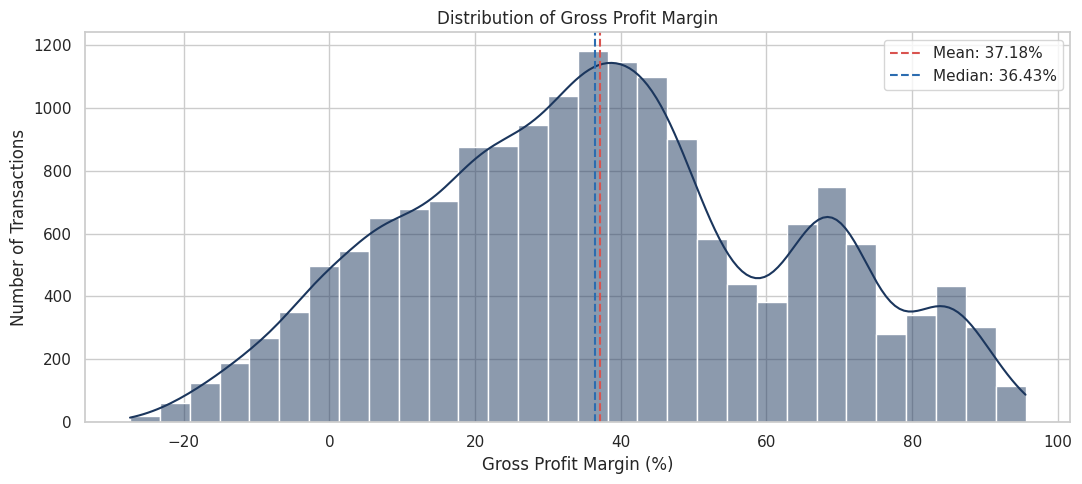



2. FULFILLMENT LATENCY
-------------------------------------------------------------------------------------
QUESTION: How much delay occurs in shipping and procurement?

Sales Shipping Schedule Variance
Average Variance : 1.98 days
Median Variance  : 2.00 days
Maximum Delay    : 4.00 days
Early            : 0
On Time          : 4085
Late             : 15915
Late Percentage  : 79.57%

Interpretation:
The process experiences an average schedule delay.


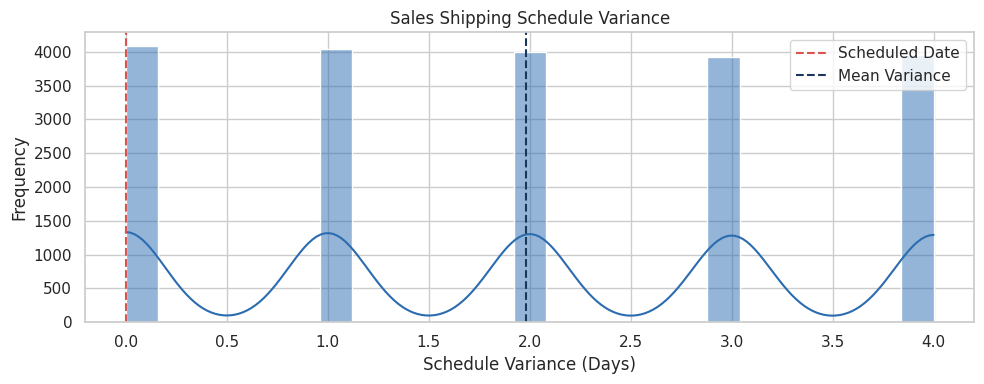


Procurement Delivery Schedule Variance
Average Variance : 1.58 days
Median Variance  : 2.00 days
Maximum Delay    : 6.00 days
Early            : 571
On Time          : 195
Late             : 1234
Late Percentage  : 61.70%

Interpretation:
The process experiences an average schedule delay.


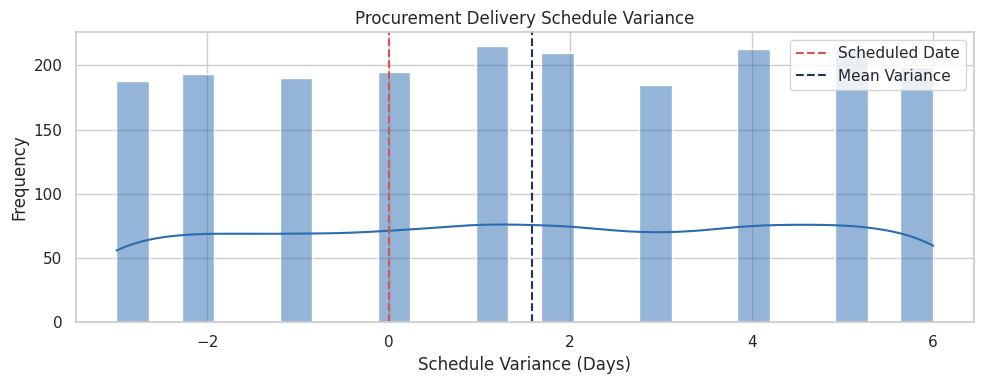



3. PRODUCT LIFESPAN STAGE
-------------------------------------------------------------------------------------
QUESTION: Which product lifecycle stage generates the highest sales?


SL.NO,Product_Lifecycle_Stage,Total_Orders,Total_Units_Sold,Total_Revenue,Average_Order_Quantity,Average_Product_Age
1,Introduction,"1,503","7,662","1,179,452.06",5.10,44.93
2,Growth,"4,568","22,938","3,529,323.98",5.02,224.45
3,Maturity,"3,866","19,248","2,910,126.31",4.98,525.42
4,Established,803,"4,047","596,919.83",5.04,823.03



Highest Sales Volume Stage: Growth

BUSINESS INTERPRETATION:
Total units sold identify the lifecycle stage with the largest observed sales volume.
Average order quantity compares the typical order size across stages.
These are lifecycle sales comparisons, not time-normalized sales velocity.


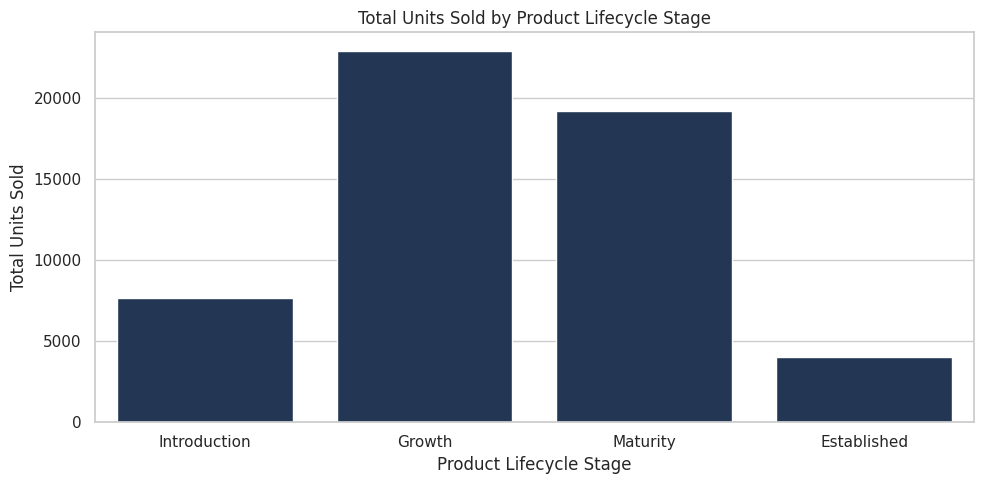

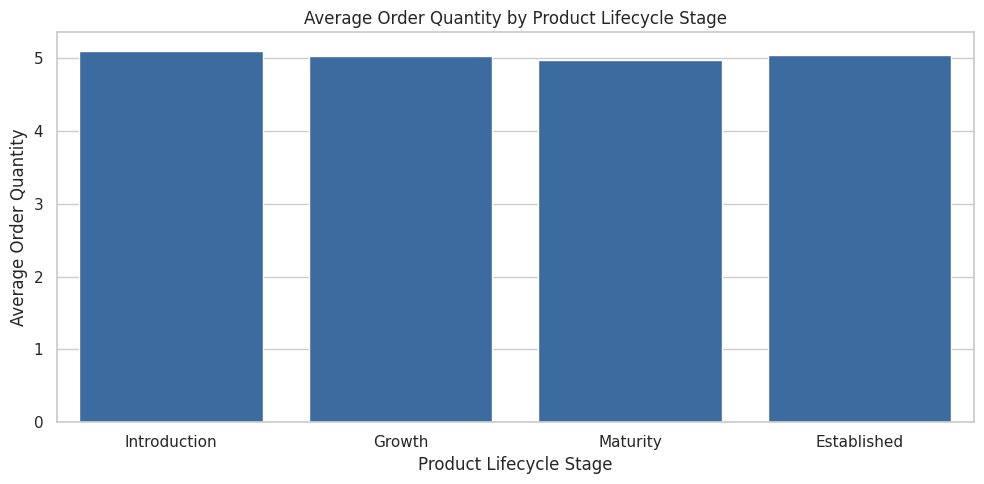


              4. GEOSPATIAL DISTANCE ANALYSIS

QUESTION: What is the estimated distance between customers
and their possible supplying suppliers?

Total Customer-Supplier Pairs: 48458
Unique Customers: 500
Unique Suppliers: 100

Estimated Distance Statistics:


SL.NO,Statistic,Estimated_Distance_KM
1,count,"48,458.00"
2,mean,"9,960.11"
3,std,"4,533.67"
4,min,164.41
5,25%,"6,152.42"
6,50%,"10,023.65"
7,75%,"13,671.70"
8,max,"19,889.94"



TOP 10 LONGEST ESTIMATED CUSTOMER-SUPPLIER DISTANCES


SL.NO,Customer_ID,Customer_Name,Supplier_ID,Supplier_Name,Estimated_Distance_KM
1,CUST00212,Jordan Brown,SUP00024,Quantum Fusion Corp,"19,889.94"
2,CUST00212,Jordan Brown,SUP00092,Alpha Nova Ltd,"19,889.94"
3,CUST00212,Jordan Brown,SUP00011,Alpha Prime Ltd,"19,889.94"
4,CUST00212,Jordan Brown,SUP00068,Prime Prime Inc,"19,889.94"
5,CUST00212,Jordan Brown,SUP00018,Omega Alpha Corp,"19,889.94"
6,CUST00212,Jordan Brown,SUP00087,Beta Nano Corp,"19,889.94"
7,CUST00212,Jordan Brown,SUP00067,Alpha Beta Ltd,"19,889.94"
8,CUST00212,Jordan Brown,SUP00051,Apex Omega LLC,"19,889.94"
9,CUST00212,Jordan Brown,SUP00060,Ultra Delta LLC,"19,889.94"
10,CUST00212,Jordan Brown,SUP00047,Eco Vertex Ltd,"19,889.94"



SUPPLIER-WISE ESTIMATED DISTANCE SUMMARY


SL.NO,Supplier_ID,Supplier_Name,Customer_Count,Average_Distance_KM,Maximum_Distance_KM
1,SUP00096,Apex Prime Ltd,484,"10,137.93","19,337.30"
2,SUP00061,Vertex Delta LLC,495,"10,136.66","19,337.30"
3,SUP00017,Nova Alpha Ltd,492,"10,118.24","19,337.30"
4,SUP00077,Ultra Apex Inc,491,"10,114.18","19,337.30"
5,SUP00059,Vertex Beta GmbH,498,"10,112.72","19,337.30"
6,SUP00043,Vertex Fusion Inc,466,"10,105.80","19,337.30"
7,SUP00072,Beta Apex Corp,476,"10,097.43","19,337.30"
8,SUP00042,Omega Nova Corp,493,"10,097.23","19,118.45"
9,SUP00053,Apex Quantum Inc,490,"10,096.64","19,337.30"
10,SUP00003,Ultra Ultra GmbH,496,"10,095.21","19,337.30"


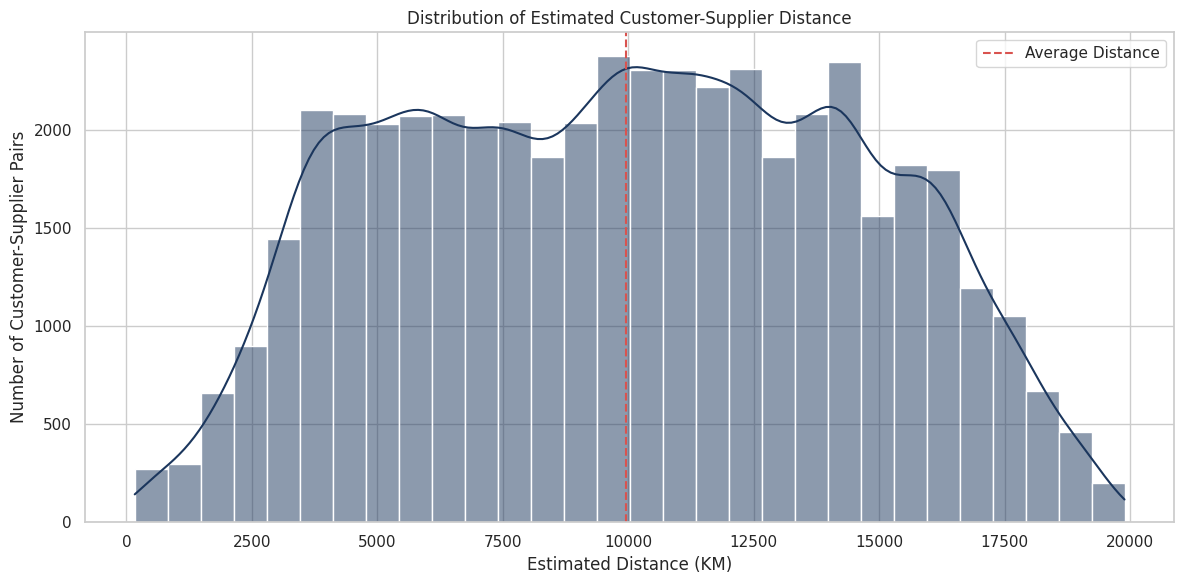

-----------------------------------------------------------------
Average Estimated Distance : 9960.11 KM
Median Estimated Distance  : 10023.65 KM
The average estimated distance is at or below the median.


In [310]:
if 'COLORS' not in globals():
    COLORS = {}

COLORS.setdefault('primary', '#1B365D')
COLORS.setdefault('secondary', '#2B6CB0')
COLORS.setdefault('warning', '#ED7D31')
COLORS.setdefault('danger', '#C00000')
COLORS.setdefault('grey', '#6C757D')
COLORS.setdefault('purple', '#6F42C1')


def style_derived_table(df, caption_text, left_cols, fmt_overrides=None):
    df_display = df.copy()
    for col in left_cols:
        if col in df_display.columns and pd.api.types.is_categorical_dtype(df_display[col]):
            df_display[col] = df_display[col].astype(str)
    df_display.insert(0, 'SL.NO', range(1, len(df_display) + 1))

    format_map = {'SL.NO': '{:.0f}'}
    for col in df_display.columns:
        if col == 'SL.NO' or col in left_cols:
            continue
        if fmt_overrides and col in fmt_overrides:
            format_map[col] = fmt_overrides[col]
        elif pd.api.types.is_integer_dtype(df_display[col]):
            format_map[col] = '{:,}'
        elif pd.api.types.is_float_dtype(df_display[col]):
            format_map[col] = '{:,.2f}'

    return (
        df_display.style
        .hide(axis='index')
        .format(format_map, na_rep='N/A')
        .set_properties(**{
            'text-align': 'center',
            'padding': '12px 20px',
            'font-size': '14px',
            'border': '1px solid #D6D6D6'
        })
        .set_properties(
            subset=left_cols,
            **{'text-align': 'left', 'font-weight': 'bold'}
        )
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#1B365D'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '14px 20px'),
                    ('font-size', '14px'),
                    ('border', '1px solid white')
                ]
            },
            {
                'selector': 'caption',
                'props': [
                    ('caption-side', 'top'),
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#1B365D'),
                    ('padding', '12px')
                ]
            },
            {
                'selector': 'table',
                'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', 'auto')
                ]
            }
        ])
        .set_caption(caption_text)
    )


print("=" * 85)
print("                      DERIVED FEATURES")
print("=" * 85)


derived_df = (
    sales_df
    .merge(customer_df, on='Customer_ID', how='left')
    .merge(
        product_df[['Product_ID', 'Launch_Date']],
        on='Product_ID',
        how='left'
    )
)

date_columns = [
    'Order_Date',
    'Launch_Date',
    'Shipping_Date_Actual',
    'Shipping_Date_Scheduled'
]

for col in date_columns:
    derived_df[col] = pd.to_datetime(
        derived_df[col], errors='coerce'
    )

procurement_derived = procurement_df.copy()

for col in [
    'Order_Date',
    'Delivery_Date_Planned',
    'Delivery_Date_Actual'
]:
    procurement_derived[col] = pd.to_datetime(
        procurement_derived[col], errors='coerce'
    )


print("\n\n1. GROSS PROFIT MARGIN")
print("-" * 85)

derived_df['Gross_Profit'] = (
    derived_df['Order_Total'] - derived_df['COGS']
)

derived_df['Gross_Profit_Margin_Percent'] = np.where(
    derived_df['Order_Total'] > 0,
    (
        derived_df['Gross_Profit'] /
        derived_df['Order_Total']
    ) * 100,
    np.nan
)

completed_df = derived_df[
    derived_df['Order_Status'].astype(str).str.strip().str.lower()
    == 'completed'
].copy()

margin = completed_df[
    'Gross_Profit_Margin_Percent'
].dropna()

if not margin.empty:

    print("QUESTION: What is the gross profitability of completed transactions?")

    print(f"\nAverage Gross Profit Margin : {margin.mean():.2f}%")
    print(f"Median Gross Profit Margin  : {margin.median():.2f}%")
    print(f"Minimum Margin              : {margin.min():.2f}%")
    print(f"Maximum Margin              : {margin.max():.2f}%")

    positive = (margin > 0).sum()
    negative = (margin < 0).sum()
    zero = (margin == 0).sum()

    print(f"\nPositive Margin Transactions: {positive}")
    print(f"Negative Margin Transactions: {negative}")
    print(f"Zero Margin Transactions    : {zero}")

    print("\nBUSINESS INTERPRETATION:")

    if margin.mean() > 0:
        print("Completed transactions generate a positive average gross margin.")
    elif margin.mean() < 0:
        print("Completed transactions generate a negative average gross margin.")
    else:
        print("The average gross profit margin is zero.")

    if negative > 0:
        print("Some completed transactions have negative gross margins and require investigation.")

    plt.figure(figsize=(11, 5))

    sns.histplot(
        margin,
        bins=30,
        kde=True,
        color=COLORS['primary']
    )

    plt.axvline(
        margin.mean(),
        color=COLORS['danger'],
        linestyle='--',
        label=f'Mean: {margin.mean():.2f}%'
    )

    plt.axvline(
        margin.median(),
        color=COLORS['secondary'],
        linestyle='--',
        label=f'Median: {margin.median():.2f}%'
    )

    plt.title('Distribution of Gross Profit Margin')
    plt.xlabel('Gross Profit Margin (%)')
    plt.ylabel('Number of Transactions')
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print("Insufficient completed transactions for margin analysis.")


print("\n\n2. FULFILLMENT LATENCY")
print("-" * 85)

derived_df['Shipping_Latency_Days'] = (
    derived_df['Shipping_Date_Actual'] -
    derived_df['Shipping_Date_Scheduled']
).dt.days

procurement_derived['Procurement_Latency_Days'] = (
    procurement_derived['Delivery_Date_Actual'] -
    procurement_derived['Delivery_Date_Planned']
).dt.days


def analyze_latency(data, column, title):

    values = data[column].dropna()

    print(f"\n{title}")

    if values.empty:
        print("No valid date comparisons available.")
        return

    early = (values < 0).sum()
    on_time = (values == 0).sum()
    late = (values > 0).sum()

    print(f"Average Variance : {values.mean():.2f} days")
    print(f"Median Variance  : {values.median():.2f} days")
    print(f"Maximum Delay    : {values.max():.2f} days")
    print(f"Early            : {early}")
    print(f"On Time          : {on_time}")
    print(f"Late             : {late}")
    print(f"Late Percentage  : {late / len(values) * 100:.2f}%")

    print("\nInterpretation:")

    if values.mean() > 0:
        print("The process experiences an average schedule delay.")
    elif values.mean() < 0:
        print("The process generally completes ahead of schedule.")
    else:
        print("The average schedule variance is zero.")

    plt.figure(figsize=(10, 4))

    sns.histplot(
        values,
        bins=25,
        kde=True,
        color=COLORS['secondary']
    )

    plt.axvline(0, color=COLORS['danger'], linestyle='--',
                label='Scheduled Date')

    plt.axvline(values.mean(), color=COLORS['primary'],
                linestyle='--', label='Mean Variance')

    plt.title(title)
    plt.xlabel('Schedule Variance (Days)')
    plt.ylabel('Frequency')
    plt.legend()
    plt.tight_layout()
    plt.show()


print("QUESTION: How much delay occurs in shipping and procurement?")

analyze_latency(
    derived_df,
    'Shipping_Latency_Days',
    'Sales Shipping Schedule Variance'
)

analyze_latency(
    procurement_derived,
    'Procurement_Latency_Days',
    'Procurement Delivery Schedule Variance'
)


print("\n\n3. PRODUCT LIFESPAN STAGE")
print("-" * 85)

derived_df['Product_Age_Days'] = (
    derived_df['Order_Date'] -
    derived_df['Launch_Date']
).dt.days

lifecycle_df = derived_df[
    derived_df['Product_Age_Days'].notna() &
    (derived_df['Product_Age_Days'] >= 0)
].copy()

derived_df['Product_Lifecycle_Stage'] = pd.cut(
    derived_df['Product_Age_Days'],
    bins=[-1, 90, 365, 730, np.inf],
    labels=[
        'Introduction',
        'Growth',
        'Maturity',
        'Established'
    ]
)

lifecycle_df['Product_Lifecycle_Stage'] = pd.cut(
    lifecycle_df['Product_Age_Days'],
    bins=[-1, 90, 365, 730, np.inf],
    labels=[
        'Introduction',
        'Growth',
        'Maturity',
        'Established'
    ]
)

lifecycle_completed = lifecycle_df[
    lifecycle_df['Order_Status'].astype(str).str.strip().str.lower()
    == 'completed'
].copy()

print("QUESTION: Which product lifecycle stage generates the highest sales?")

lifecycle_summary = lifecycle_completed.groupby(
    'Product_Lifecycle_Stage',
    observed=False
).agg(
    Total_Orders=('Order_ID', 'count'),
    Total_Units_Sold=('Order_Quantity', 'sum'),
    Total_Revenue=('Order_Total', 'sum'),
    Average_Order_Quantity=('Order_Quantity', 'mean'),
    Average_Product_Age=('Product_Age_Days', 'mean')
).reset_index()

display(
    style_derived_table(
        lifecycle_summary.round(2),
        'Supply Chain Analytics - Product Lifecycle Performance Summary',
        ['Product_Lifecycle_Stage']
    )
)

if not lifecycle_summary.empty:

    best_stage = lifecycle_summary.loc[
        lifecycle_summary['Total_Units_Sold'].idxmax(),
        'Product_Lifecycle_Stage'
    ]

    print(f"\nHighest Sales Volume Stage: {best_stage}")

    print("\nBUSINESS INTERPRETATION:")
    print("Total units sold identify the lifecycle stage with the largest observed sales volume.")
    print("Average order quantity compares the typical order size across stages.")
    print("These are lifecycle sales comparisons, not time-normalized sales velocity.")

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=lifecycle_summary,
        x='Product_Lifecycle_Stage',
        y='Total_Units_Sold',
        color=COLORS['primary']
    )

    plt.title('Total Units Sold by Product Lifecycle Stage')
    plt.xlabel('Product Lifecycle Stage')
    plt.ylabel('Total Units Sold')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=lifecycle_summary,
        x='Product_Lifecycle_Stage',
        y='Average_Order_Quantity',
        color=COLORS['secondary']
    )

    plt.title('Average Order Quantity by Product Lifecycle Stage')
    plt.xlabel('Product Lifecycle Stage')
    plt.ylabel('Average Order Quantity')
    plt.tight_layout()
    plt.show()

else:
    print("No valid completed transactions with product launch dates.")


print("\n" + "=" * 85)
print("              4. GEOSPATIAL DISTANCE ANALYSIS")
print("=" * 85)


country_coordinates = {
    'USA': (39.8283, -98.5795),
    'China': (35.8617, 104.1954),
    'India': (20.5937, 78.9629),
    'Canada': (56.1304, -106.3468),
    'Denmark': (56.2639, 9.5018),
    'UK': (55.3781, -3.4360),
    'Germany': (51.1657, 10.4515),
    'Brazil': (-14.2350, -51.9253)
}

supplier_geo = supplier_df.copy()

supplier_geo['Supplier_Latitude'] = (
    supplier_geo['Country'].map(
        lambda x: country_coordinates.get(x, (np.nan, np.nan))[0]
    )
)

supplier_geo['Supplier_Longitude'] = (
    supplier_geo['Country'].map(
        lambda x: country_coordinates.get(x, (np.nan, np.nan))[1]
    )
)


customer_geo = customer_df.copy()

customer_geo['Latitude'] = pd.to_numeric(
    customer_geo['Latitude'], errors='coerce'
)

customer_geo['Longitude'] = pd.to_numeric(
    customer_geo['Longitude'], errors='coerce'
)

customer_geo = customer_geo[
    customer_geo['Latitude'].between(-90, 90) &
    customer_geo['Longitude'].between(-180, 180)
].copy()


sales_product_links = sales_df[
    ['Customer_ID', 'Product_ID']
].drop_duplicates()

procurement_product_links = procurement_df[
    ['Supplier_ID', 'Raw_Material_ID']
].rename(
    columns={'Raw_Material_ID': 'Product_ID'}
).drop_duplicates()

customer_supplier_links = sales_product_links.merge(
    procurement_product_links,
    on='Product_ID',
    how='inner'
).drop_duplicates(
    subset=['Customer_ID', 'Supplier_ID']
)

customer_supplier_geo = customer_supplier_links.merge(
    customer_geo[
        ['Customer_ID', 'Customer_Name', 'Latitude', 'Longitude',
         'Country', 'City']
    ],
    on='Customer_ID',
    how='inner'
)

customer_supplier_geo = customer_supplier_geo.merge(
    supplier_geo[
        ['Supplier_ID', 'Supplier_Name', 'Country',
         'Supplier_Latitude', 'Supplier_Longitude']
    ],
    on='Supplier_ID',
    how='inner',
    suffixes=('_Customer', '_Supplier')
)


def haversine_distance(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

    earth_radius = 6371

    return earth_radius * c


customer_supplier_geo['Estimated_Distance_KM'] = haversine_distance(
    customer_supplier_geo['Latitude'],
    customer_supplier_geo['Longitude'],
    customer_supplier_geo['Supplier_Latitude'],
    customer_supplier_geo['Supplier_Longitude']
)


print("\nQUESTION: What is the estimated distance between customers")
print("and their possible supplying suppliers?")

print("\nTotal Customer-Supplier Pairs:",
      len(customer_supplier_geo))

print("Unique Customers:",
      customer_supplier_geo['Customer_ID'].nunique())

print("Unique Suppliers:",
      customer_supplier_geo['Supplier_ID'].nunique())

print("\nEstimated Distance Statistics:")

dist_stats_df = (
    customer_supplier_geo['Estimated_Distance_KM']
    .describe()
    .round(2)
    .reset_index()
)
dist_stats_df.columns = ['Statistic', 'Estimated_Distance_KM']
if 'count' in dist_stats_df['Statistic'].values:
    dist_stats_df.loc[dist_stats_df['Statistic'] == 'count', 'Estimated_Distance_KM'] = (
        dist_stats_df.loc[dist_stats_df['Statistic'] == 'count', 'Estimated_Distance_KM'].astype(int)
    )

display(
    style_derived_table(
        dist_stats_df,
        'Supply Chain Analytics - Estimated Customer-Supplier Distance Statistics (KM)',
        ['Statistic']
    )
)


print("\nTOP 10 LONGEST ESTIMATED CUSTOMER-SUPPLIER DISTANCES")

top_distances = customer_supplier_geo.nlargest(
    10, 'Estimated_Distance_KM'
)[
    [
        'Customer_ID',
        'Customer_Name',
        'Supplier_ID',
        'Supplier_Name',
        'Estimated_Distance_KM'
    ]
].round(2)

display(
    style_derived_table(
        top_distances,
        'Supply Chain Analytics - Top 10 Longest Estimated Customer-Supplier Distances',
        ['Customer_ID', 'Customer_Name', 'Supplier_ID', 'Supplier_Name']
    )
)


supplier_distance_summary = customer_supplier_geo.groupby(
    ['Supplier_ID', 'Supplier_Name'],
    as_index=False
).agg(
    Customer_Count=('Customer_ID', 'nunique'),
    Average_Distance_KM=('Estimated_Distance_KM', 'mean'),
    Maximum_Distance_KM=('Estimated_Distance_KM', 'max')
)

supplier_distance_summary = supplier_distance_summary.sort_values(
    'Average_Distance_KM',
    ascending=False
).round(2)

print("\nSUPPLIER-WISE ESTIMATED DISTANCE SUMMARY")

display(
    style_derived_table(
        supplier_distance_summary.head(10),
        'Supply Chain Analytics - Supplier-Wise Estimated Distance Summary (Top 10)',
        ['Supplier_ID', 'Supplier_Name']
    )
)


plt.figure(figsize=(12, 6))

sns.histplot(
    customer_supplier_geo['Estimated_Distance_KM'],
    bins=30,
    kde=True,
    color=COLORS['primary']
)

plt.axvline(
    customer_supplier_geo['Estimated_Distance_KM'].mean(),
    color=COLORS['danger'],
    linestyle='--',
    label='Average Distance'
)

plt.title('Distribution of Estimated Customer-Supplier Distance')
plt.xlabel('Estimated Distance (KM)')
plt.ylabel('Number of Customer-Supplier Pairs')
plt.legend()
plt.tight_layout()
plt.show()


avg_distance = customer_supplier_geo[
    'Estimated_Distance_KM'
].mean()

median_distance = customer_supplier_geo[
    'Estimated_Distance_KM'
].median()

print("-" * 65)

print(f"Average Estimated Distance : {avg_distance:.2f} KM")
print(f"Median Estimated Distance  : {median_distance:.2f} KM")

if avg_distance > median_distance:
    print("The estimated distance distribution is influenced by longer-distance pairs.")
else:
    print("The average estimated distance is at or below the median.")

print("=" * 85)

# 14. Key Findings & Summary Report

In [311]:
# ============================================================
# KEY FINDINGS & SUMMARY REPORT
# ============================================================

print("\n" + "=" * 75)
print("             SUPPLY CHAIN ANALYTICS")
print("                KEY FINDINGS & SUMMARY REPORT")
print("=" * 75)


def resolve_df(candidates):
    for name in candidates:
        if name in globals() and isinstance(globals()[name], pd.DataFrame):
            return globals()[name]
    return pd.DataFrame()


def style_report_table(df, caption_text, left_cols, fmt_overrides=None):
    df_display = df.copy()
    df_display.insert(0, 'SL.NO', range(1, len(df_display) + 1))

    format_map = {'SL.NO': '{:.0f}'}
    for col in df_display.columns:
        if col == 'SL.NO' or col in left_cols:
            continue
        if fmt_overrides and col in fmt_overrides:
            format_map[col] = fmt_overrides[col]
        elif pd.api.types.is_integer_dtype(df_display[col]):
            format_map[col] = '{:,}'
        elif pd.api.types.is_float_dtype(df_display[col]):
            format_map[col] = '{:,.2f}'

    return (
        df_display.style
        .hide(axis='index')
        .format(format_map, na_rep='N/A')
        .set_properties(**{
            'text-align': 'center',
            'padding': '12px 20px',
            'font-size': '14px',
            'border': '1px solid #D6D6D6'
        })
        .set_properties(
            subset=left_cols,
            **{'text-align': 'left', 'font-weight': 'bold'}
        )
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', '#1B365D'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '14px 20px'),
                    ('font-size', '14px'),
                    ('border', '1px solid white')
                ]
            },
            {
                'selector': 'caption',
                'props': [
                    ('caption-side', 'top'),
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#1B365D'),
                    ('padding', '12px')
                ]
            },
            {
                'selector': 'table',
                'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', 'auto')
                ]
            }
        ])
        .set_caption(caption_text)
    )


procurement_ref = resolve_df([
    'procurement_temporal',
    'procurement_multi',
    'procurement_analysis',
    'procurement_df'
])

if (
    not procurement_ref.empty
    and 'Delivery_Variance_Days' not in procurement_ref.columns
    and {'Delivery_Date_Actual', 'Delivery_Date_Planned'}.issubset(procurement_ref.columns)
):
    procurement_ref = procurement_ref.copy()
    procurement_ref['Delivery_Variance_Days'] = (
        pd.to_datetime(procurement_ref['Delivery_Date_Actual'], errors='coerce') -
        pd.to_datetime(procurement_ref['Delivery_Date_Planned'], errors='coerce')
    ).dt.days

if 'classify_correlation' not in globals():
    def classify_correlation(r):
        if pd.isna(r):
            return 'Not Available'
        r = abs(r)
        if r < 0.10:
            return 'Negligible'
        elif r < 0.30:
            return 'Weak'
        elif r < 0.50:
            return 'Moderate'
        elif r < 0.70:
            return 'Strong'
        else:
            return 'Very Strong'


def safe_pearson(df, col_a, col_b):
    if df is None or df.empty or col_a not in df.columns or col_b not in df.columns:
        return np.nan
    pair = df[[col_a, col_b]].apply(pd.to_numeric, errors='coerce').dropna()
    if len(pair) < 2 or pair[col_a].nunique() < 2 or pair[col_b].nunique() < 2:
        return np.nan
    return pair[col_a].corr(pair[col_b], method='pearson')


# ------------------------------------------------------------
# DATASET OVERVIEW
# ------------------------------------------------------------

print("\n1. DATASET OVERVIEW")
print("-" * 75)

datasets = {
    'Customer Master': customer_df,
    'Product Master': product_df,
    'Supplier Master': supplier_df,
    'Sales Orders': sales_df,
    'Procurement Orders': procurement_df,
    'Data Dictionary': dictionary_df
}

total_records = sum(len(df) for df in datasets.values())
total_columns = sum(len(df.columns) for df in datasets.values())
total_missing = sum(df.isnull().sum().sum() for df in datasets.values())

print(f"Total Datasets       : {len(datasets)}")
print(f"Total Records        : {total_records:,}")
print(f"Total Columns        : {total_columns}")
print(f"Total Missing Values : {total_missing:,}")

for name, df in datasets.items():
    print(f"   {name:<22}: {len(df):,} records")


# ------------------------------------------------------------
# DATA QUALITY FINDINGS
# ------------------------------------------------------------

print("\n2. DATA QUALITY FINDINGS")
print("-" * 75)

total_cells = sum(df.size for df in datasets.values())

completeness = (
    (total_cells - total_missing) / total_cells * 100
    if total_cells else 0
)

print(f"Overall Data Completeness : {completeness:.2f}%")
print(f"Total Missing Values      : {total_missing:,}")

print("\nDatasets with Missing Values:")

for name, df in datasets.items():

    missing = df.isnull().sum().sum()

    if missing > 0:
        print(f"   {name}: {missing:,} missing values")

if total_missing == 0:
    print("   No missing values detected.")


# ------------------------------------------------------------
# SALES & PROFITABILITY FINDINGS
# ------------------------------------------------------------

print("\n3. SALES & PROFITABILITY FINDINGS")
print("-" * 75)

completed_sales = sales_df[
    sales_df['Order_Status'].astype(str).str.lower() == 'completed'
].copy()

total_orders = len(sales_df)
completed_orders = len(completed_sales)

total_revenue = completed_sales['Order_Total'].sum()
total_profit = completed_sales['Profit_Per_Order'].sum()

average_profit = completed_sales['Profit_Per_Order'].mean()
median_profit = completed_sales['Profit_Per_Order'].median()

completion_rate = (
    completed_orders / total_orders * 100
    if total_orders else 0
)

print(f"Total Sales Orders       : {total_orders:,}")
print(f"Completed Orders         : {completed_orders:,}")
print(f"Order Completion Rate    : {completion_rate:.2f}%")
print(f"Completed Order Revenue  : {total_revenue:,.2f}")
print(f"Total Realized Profit    : {total_profit:,.2f}")
print(f"Average Profit per Order : {average_profit:,.2f}")
print(f"Median Profit per Order  : {median_profit:,.2f}")


# ------------------------------------------------------------
# DISCOUNT FINDINGS
# ------------------------------------------------------------

print("\n4. DISCOUNT ANALYSIS")
print("-" * 75)

average_discount = sales_df['Discount'].mean() * 100
maximum_discount = sales_df['Discount'].max() * 100

discount_profit_corr = sales_df[
    ['Discount', 'Profit_Per_Order']
].corr().iloc[0, 1]

print(f"Average Discount : {average_discount:.2f}%")
print(f"Maximum Discount : {maximum_discount:.2f}%")

print(
    f"Discount vs Profit Correlation : "
    f"{discount_profit_corr:+.3f}"
)

if pd.notna(discount_profit_corr):

    if discount_profit_corr < 0:
        print(
            "Finding: Discounts have a negative linear association "
            "with order profit."
        )
    elif discount_profit_corr > 0:
        print(
            "Finding: Discounts have a positive linear association "
            "with order profit."
        )
    else:
        print("Finding: No linear association detected.")

print("Note: Correlation does not establish that discounts cause changes in profit.")


# ------------------------------------------------------------
# DELIVERY PERFORMANCE FINDINGS
# ------------------------------------------------------------

print("\n5. DELIVERY PERFORMANCE")
print("-" * 75)

delivery_status = (
    sales_df['Delivery_Status']
    .astype(str)
    .str.strip()
    .str.lower()
)

late_orders = delivery_status.str.contains(
    'late', na=False
).sum()

actual_late_rate = (
    late_orders / len(sales_df) * 100
    if len(sales_df) else 0
)

risk_flag = pd.to_numeric(
    sales_df['Late_Delivery_Risk_Flag'],
    errors='coerce'
)

risk_rate = (
    risk_flag.eq(1).mean() * 100
    if risk_flag.notna().any() else np.nan
)

print(f"Actual Late Orders       : {late_orders:,}")
print(f"Actual Late Order Rate   : {actual_late_rate:.2f}%")

if pd.notna(risk_rate):
    print(f"Late Delivery Risk Rate  : {risk_rate:.2f}%")

print(
    "Finding: Risk flags and actual late delivery statuses "
    "represent different operational measures."
)


# ------------------------------------------------------------
# PROCUREMENT & SUPPLIER FINDINGS
# ------------------------------------------------------------

print("\n6. PROCUREMENT & SUPPLIER PERFORMANCE")
print("-" * 75)

total_procurement_orders = len(procurement_df)
total_procurement_cost = procurement_df['Total_Cost'].sum()

average_procurement_cost = procurement_df['Total_Cost'].mean()

print(f"Total Procurement Orders : {total_procurement_orders:,}")
print(f"Total Procurement Spend  : {total_procurement_cost:,.2f}")
print(f"Average PO Cost          : {average_procurement_cost:,.2f}")

supplier_otd = supplier_df['On_Time_Delivery_Rate'].mean()

print(f"Average Supplier OTD     : {supplier_otd:.3f}")

proc_variance = (
    procurement_ref['Delivery_Variance_Days'].dropna()
    if not procurement_ref.empty and 'Delivery_Variance_Days' in procurement_ref.columns
    else pd.Series(dtype=float)
)

if not proc_variance.empty:

    average_variance = proc_variance.mean()
    delayed_pos = (proc_variance > 0).sum()
    early_pos = (proc_variance < 0).sum()
    on_time_pos = (proc_variance == 0).sum()

    print(f"Average Delivery Variance: {average_variance:.2f} days")
    print(f"Late Procurement Orders  : {delayed_pos:,}")
    print(f"Early Procurement Orders : {early_pos:,}")
    print(f"On-Time Procurement      : {on_time_pos:,}")


# ------------------------------------------------------------
# STATISTICAL ANALYSIS FINDINGS
# ------------------------------------------------------------

print("\n7. STATISTICAL ANALYSIS")
print("-" * 75)

supplier_stats_ref = (
    supplier_stats
    if 'supplier_stats' in globals() and isinstance(supplier_stats, pd.DataFrame) and not supplier_stats.empty
    else procurement_ref
)
if (
    not supplier_stats_ref.empty
    and 'On_Time_Delivery_Rate' not in supplier_stats_ref.columns
    and {'Supplier_ID'}.issubset(supplier_stats_ref.columns)
    and {'Supplier_ID', 'On_Time_Delivery_Rate'}.issubset(supplier_df.columns)
):
    supplier_stats_ref = supplier_stats_ref.merge(
        supplier_df[['Supplier_ID', 'On_Time_Delivery_Rate']].drop_duplicates(subset=['Supplier_ID']),
        on='Supplier_ID',
        how='left'
    )

procurement_stats_ref = (
    procurement_stats
    if 'procurement_stats' in globals() and isinstance(procurement_stats, pd.DataFrame) and not procurement_stats.empty
    else procurement_ref.copy()
)
if (
    not procurement_stats_ref.empty
    and 'Planned_Lead_Time' not in procurement_stats_ref.columns
    and {'Delivery_Date_Planned', 'Order_Date'}.issubset(procurement_stats_ref.columns)
):
    procurement_stats_ref = procurement_stats_ref.copy()
    procurement_stats_ref['Planned_Lead_Time'] = (
        pd.to_datetime(procurement_stats_ref['Delivery_Date_Planned'], errors='coerce') -
        pd.to_datetime(procurement_stats_ref['Order_Date'], errors='coerce')
    ).dt.days

# Recalculate correlations to avoid dependence on old column names

statistical_results = {
    'Supplier Reliability vs Delivery Variance':
        safe_pearson(supplier_stats_ref, 'On_Time_Delivery_Rate', 'Delivery_Variance_Days'),

    'Discount vs Profit':
        safe_pearson(sales_df, 'Discount', 'Profit_Per_Order'),

    'Unit Cost vs Standard Price':
        safe_pearson(product_df, 'Unit_Cost', 'Standard_Price'),

    'Procurement Quantity vs Delivery Variance':
        safe_pearson(procurement_ref, 'Order_Quantity', 'Delivery_Variance_Days'),

    'Planned Lead Time vs Delivery Variance':
        safe_pearson(procurement_stats_ref, 'Planned_Lead_Time', 'Delivery_Variance_Days')
}

correlation_report = pd.DataFrame(
    statistical_results.items(),
    columns=['Relationship', 'Pearson Correlation']
).dropna()

correlation_report['Strength'] = (
    correlation_report['Pearson Correlation'].abs().apply(
        classify_correlation
    )
)

correlation_report['Pearson Correlation'] = (
    correlation_report['Pearson Correlation'].round(3)
)

display(
    style_report_table(
        correlation_report,
        'Supply Chain Analytics - Statistical Correlation Summary',
        ['Relationship'],
        {'Pearson Correlation': '{:+.3f}'}
    )
)

if not correlation_report.empty:

    strongest = correlation_report.loc[
        correlation_report['Pearson Correlation'].abs().idxmax()
    ]

    print(
        f"Strongest Observed Relationship : "
        f"{strongest['Relationship']}"
    )

    print(
        f"Pearson Correlation             : "
        f"{strongest['Pearson Correlation']:+.3f}"
    )

    print(
        f"Actual Relationship Strength   : "
        f"{strongest['Strength']}"
    )


# ------------------------------------------------------------
# TEMPORAL ANALYSIS FINDINGS
# ------------------------------------------------------------

print("\n8. TEMPORAL ANALYSIS")
print("-" * 75)

temporal_sales = sales_df.copy()

temporal_sales['Order_Date'] = pd.to_datetime(
    temporal_sales['Order_Date'],
    errors='coerce'
)

temporal_sales = temporal_sales[
    temporal_sales['Order_Status'].astype(str).str.lower()
    == 'completed'
]

temporal_sales = temporal_sales.dropna(
    subset=['Order_Date']
)

if not temporal_sales.empty:

    monthly_revenue = (
        temporal_sales
        .set_index('Order_Date')['Order_Total']
        .resample('MS')
        .sum()
    )

    if len(monthly_revenue) > 0:

        highest_month = monthly_revenue.idxmax()
        lowest_month = monthly_revenue.idxmin()

        print(
            f"Highest Revenue Month : "
            f"{highest_month.strftime('%B %Y')}"
        )

        print(
            f"Lowest Revenue Month  : "
            f"{lowest_month.strftime('%B %Y')}"
        )

        print(
            f"Highest Monthly Revenue: "
            f"{monthly_revenue.max():,.2f}"
        )

        print(
            f"Lowest Monthly Revenue : "
            f"{monthly_revenue.min():,.2f}"
        )

else:
    print("Insufficient valid dates for temporal analysis.")


# ------------------------------------------------------------
# OUTLIER ANALYSIS FINDINGS
# ------------------------------------------------------------

print("\n9. OUTLIER ANALYSIS")
print("-" * 75)

if 'outlier_summary' in globals() and not outlier_summary.empty:

    display(
        style_report_table(
            outlier_summary,
            'Supply Chain Analytics - Outlier Percentage Summary',
            ['Category', 'Variable'],
            {'Outlier_Percentage': '{:,.2f}%'}
        )
    )

    highest_outlier = outlier_summary.loc[
        outlier_summary['Outlier_Percentage'].idxmax()
    ]

    print(
        f"Highest Outlier Variable : "
        f"{highest_outlier['Variable']}"
    )

    print(
        f"Dataset Category         : "
        f"{highest_outlier['Category']}"
    )

    print(
        f"Outlier Percentage       : "
        f"{highest_outlier['Outlier_Percentage']:.2f}%"
    )

else:
    print(
        "Outlier summary not available. "
        "Run Section 9 before this report."
    )

print(
    "Note: Statistical outliers are not automatically "
    "data errors and should be investigated before removal."
)

# ------------------------------------------------------------
# DERIVED FEATURES SUMMARY
# ------------------------------------------------------------

print("\n10. DERIVED FEATURES SUMMARY")
print("-" * 75)

# 1. Shipping Variance
if 'Shipping_Variance_Days' in sales_analysis.columns:

    shipping_variance = sales_analysis[
        'Shipping_Variance_Days'
    ].dropna()

    if not shipping_variance.empty:
        print("\nShipping Schedule Variance:")
        print(f"   Average Variance : {shipping_variance.mean():.2f} days")
        print(f"   Maximum Variance : {shipping_variance.max():.2f} days")
        print(f"   Minimum Variance : {shipping_variance.min():.2f} days")


# 2. Procurement Delivery Variance
if 'Delivery_Variance_Days' in procurement_ref.columns:

    delivery_variance = procurement_ref[
        'Delivery_Variance_Days'
    ].dropna()

    if not delivery_variance.empty:
        print("\nProcurement Delivery Variance:")
        print(f"   Average Variance : {delivery_variance.mean():.2f} days")
        print(f"   Late Deliveries  : {(delivery_variance > 0).sum():,}")
        print(f"   Early Deliveries : {(delivery_variance < 0).sum():,}")
        print(f"   On-Time Delivery : {(delivery_variance == 0).sum():,}")


# 3. Profit Margin
if 'Profit_Margin_Percent' in sales_analysis.columns:

    profit_margin = sales_analysis[
        'Profit_Margin_Percent'
    ].replace([np.inf, -np.inf], np.nan).dropna()

    if not profit_margin.empty:
        print("\nDerived Profit Margin:")
        print(f"   Average Margin : {profit_margin.mean():.2f}%")
        print(f"   Median Margin  : {profit_margin.median():.2f}%")


# 4. Planned Procurement Lead Time
if {'Order_Date', 'Delivery_Date_Planned'}.issubset(procurement_ref.columns):

    planned_lead_time = (
        pd.to_datetime(procurement_ref['Delivery_Date_Planned'], errors='coerce')
        - pd.to_datetime(procurement_ref['Order_Date'], errors='coerce')
    ).dt.days.dropna()

    if not planned_lead_time.empty:
        print("\nProcurement Lead Time:")
        print(f"   Average Planned Lead Time : {planned_lead_time.mean():.2f} days")
        print(f"   Maximum Planned Lead Time : {planned_lead_time.max():.0f} days")


# 5. Geospatial Distance
if (
    'customer_supplier_geo' in globals()
    and isinstance(customer_supplier_geo, pd.DataFrame)
    and not customer_supplier_geo.empty
    and 'Estimated_Distance_KM' in customer_supplier_geo.columns
):

    geo_distance = customer_supplier_geo[
        'Estimated_Distance_KM'
    ].replace([np.inf, -np.inf], np.nan).dropna()

    if not geo_distance.empty:

        print("\nEstimated Customer-Supplier Geographic Distance:")

        print(f"   Customer-Supplier Pairs : {len(geo_distance):,}")
        print(f"   Unique Customers        : {customer_supplier_geo['Customer_ID'].nunique():,}")
        print(f"   Unique Suppliers        : {customer_supplier_geo['Supplier_ID'].nunique():,}")
        print(f"   Average Distance        : {geo_distance.mean():,.2f} KM")
        print(f"   Median Distance         : {geo_distance.median():,.2f} KM")
        print(f"   Maximum Distance        : {geo_distance.max():,.2f} KM")
        print(f"   Minimum Distance        : {geo_distance.min():,.2f} KM")

        print(
            "\n   Note: Distances are exploratory straight-line estimates "
            "based on customer coordinates and supplier country-centre "
            "coordinates, not verified logistics distances."
        )

else:
    print("\nGeospatial Distance: Not available. Run the geospatial analysis first.")

# ------------------------------------------------------------
# FINAL KEY FINDINGS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("                  FINAL KEY FINDINGS")
print("=" * 75)

findings = [
    f"The analysis covers {total_records:,} records across "
    f"{len(datasets)} datasets.",

    f"Overall data completeness is {completeness:.2f}%.",

    f"Completed sales generated revenue of "
    f"{total_revenue:,.2f} and profit of {total_profit:,.2f}.",

    f"The actual late delivery rate is {actual_late_rate:.2f}%.",

    f"Total procurement expenditure is "
    f"{total_procurement_cost:,.2f}.",

    "Statistical correlations should be interpreted as "
    "associations, not causal relationships."
]

for i, finding in enumerate(findings, 1):
    print(f"\n{i}. {finding}")

print("=" * 75)
print("             END OF KEY FINDINGS & SUMMARY REPORT")
print("=" * 75)


             SUPPLY CHAIN ANALYTICS
                KEY FINDINGS & SUMMARY REPORT

1. DATASET OVERVIEW
---------------------------------------------------------------------------
Total Datasets       : 6
Total Records        : 22,854
Total Columns        : 58
Total Missing Values : 200
   Customer Master       : 500 records
   Product Master        : 200 records
   Supplier Master       : 100 records
   Sales Orders          : 20,000 records
   Procurement Orders    : 2,000 records
   Data Dictionary       : 54 records

2. DATA QUALITY FINDINGS
---------------------------------------------------------------------------
Overall Data Completeness : 99.95%
Total Missing Values      : 200

Datasets with Missing Values:
   Product Master: 200 missing values

3. SALES & PROFITABILITY FINDINGS
---------------------------------------------------------------------------
Total Sales Orders       : 20,000
Completed Orders         : 16,980
Order Completion Rate    : 84.90%
Completed Order Revenue

SL.NO,Relationship,Pearson Correlation,Strength
1,Supplier Reliability vs Delivery Variance,+0.012,Negligible
2,Discount vs Profit,-0.254,Weak
3,Unit Cost vs Standard Price,-0.018,Negligible
4,Procurement Quantity vs Delivery Variance,+0.012,Negligible
5,Planned Lead Time vs Delivery Variance,-0.024,Negligible


Strongest Observed Relationship : Discount vs Profit
Pearson Correlation             : -0.254
Actual Relationship Strength   : Weak

8. TEMPORAL ANALYSIS
---------------------------------------------------------------------------
Highest Revenue Month : May 2023
Lowest Revenue Month  : September 2024
Highest Monthly Revenue: 446,409.58
Lowest Monthly Revenue : 329,467.35

9. OUTLIER ANALYSIS
---------------------------------------------------------------------------


SL.NO,Category,Variable,Outlier_Percentage
1,Sales,Order Quantity,2.13%
2,Sales,Order Value,1.98%
3,Sales,Profit,1.39%
4,Sales,Unit Price,0.00%
5,Product,Unit Cost,0.00%
6,Product,Standard Price,0.00%
7,Procurement,Order Quantity,0.70%
8,Procurement,Unit Cost,0.00%
9,Procurement,Total Cost,0.40%
10,Delivery,Shipping Variance,0.00%


Highest Outlier Variable : Order Quantity
Dataset Category         : Sales
Outlier Percentage       : 2.13%
Note: Statistical outliers are not automatically data errors and should be investigated before removal.

10. DERIVED FEATURES SUMMARY
---------------------------------------------------------------------------

Shipping Schedule Variance:
   Average Variance : 1.98 days
   Maximum Variance : 4.00 days
   Minimum Variance : 0.00 days

Procurement Delivery Variance:
   Average Variance : 1.58 days
   Late Deliveries  : 1,234
   Early Deliveries : 571
   On-Time Delivery : 195

Derived Profit Margin:
   Average Margin : 37.13%
   Median Margin  : 36.44%

Procurement Lead Time:
   Average Planned Lead Time : 17.10 days
   Maximum Planned Lead Time : 24 days

Estimated Customer-Supplier Geographic Distance:
   Customer-Supplier Pairs : 48,458
   Unique Customers        : 500
   Unique Suppliers        : 100
   Average Distance        : 9,960.11 KM
   Median Distance         : 10,023.6

# 15. Business Interpretation & Recommendations

---


## 15.1. Business Health Snapshot

| Metric                          |                  Result                  |      Assessment       |
|:--------------------------------|:----------------------------------------:|:---------------------:|
| Completed Order Revenue         |                13,203,375                |     Healthy base      |
| Realized Profit                 |      4,774,226 (about 36% margin)        |      Profitable       |
| Order Completion Rate           | 84.90% (3,020 orders not completed)      |   Revenue leakage     |
| Late Customer Deliveries        |                **79.57%**                |       Critical        |
| Late Supplier Deliveries        |                **61.70%**                |       Critical        |
| Average Discount                |            12.52% (max 25%)              |      Margin leak      |
| Top 10 SKU Profit Share         |                  11.49%                  | Low dependency (strength) |

**Interpretation:** The business is profitable and does not depend on a few products. But it loses value in three controllable areas: **discounting, customer delivery, and supplier planning**.

---


## 15.2. Problem 1: Discounts Reduce Profit Without Creating Value

### 15.2.1. Data Evidence

| Discount Band | Orders | Avg Profit per Order | Avg Order Value | Cancellation Rate |
|:-------------:|:------:|:--------------------:|:---------------:|:-----------------:|
|     0–5%      | 4,386  |        366.89        |     862.12      |       5.11%       |
|     5–10%     | 3,998  |        317.21        |     804.73      |       4.88%       |
|    10–20%     | 8,001  |        252.06        |     750.21      |       5.31%       |
|    20–30%     | 3,615  |        197.08        |     694.94      |       4.92%       |

- Discount vs Profit correlation: **-0.254** (strongest relationship in the study)
- Orders where discount exceeds standard margin: **6,616 (33.08%)**
- Completed orders with negative margin: **1,346 (7.93%)**
- Average quantity per order stays near 5 in every band

### 15.2.2. What It Means

Deeper discounts cut profit per order by up to **46%** (366.89 to 197.08). But they do **not** lower cancellations (flat at about 5%) and do **not** increase order size. The company gives away margin and gets nothing measurable back. 40% of all orders sit in the 10–20% band, which suggests discounting is a habit, not a strategy.

### 15.2.3. Recommended Solution

1. Cap discounts at **20%**. Require manager approval above 15%.
2. Set a **minimum margin floor** (for example 15%) so no order can be sold at a loss.
3. Make discounts **conditional** on larger quantity, advance payment or a contract.

### 15.2.4. Expected Outcome

| Item                                       |                 Estimate                 | Assumption                                          |
|:-------------------------------------------|:----------------------------------------:|:----------------------------------------------------|
| Move 20–30% orders to the 10–20% band      | about +199K at full volume retention     | Profit gap of about 55 per order x 3,615 orders     |
| **Realistic gain**                         |      **+100K (about +2% profit)**        | Half of the volume benefit is realized              |
| Upside if 10–20% orders are also tightened |      up to +350K (about +7%)             | Needs strict approval discipline                    |
| Negative-margin orders                     |           **70–90% fewer**               | Margin floor enforced in the order system           |

---


## 15.3. Problem 2: Late Customer Deliveries Are Systemic

### 15.3.1. Data Evidence

**Late Rate by Shipping Mode**

| Shipping Mode | Late Rate |
|:--------------|:---------:|
| Economy       |  79.99%   |
| Express       |  79.63%   |
| Same Day      |  79.36%   |
| Standard      |  79.33%   |

**Late Rate by Carrier**

| Carrier  | Late Rate |
|:---------|:---------:|
| CarrierE |  80.65%   |
| CarrierD |  80.29%   |
| CarrierA |  79.82%   |
| CarrierC |  78.78%   |
| CarrierB |  78.32%   |

- Late orders: **15,915 of 20,000 (79.57%)**. On-time: 4,085. Early: 0.
- Average delay **1.98 days**, median 2, maximum 4.
- Country and city differences are small (about 80–87%).

### 15.3.2. What It Means

**Same Day delivery is as late as Economy, and every carrier is equally late.** So the cause is **not** the carrier, shipping mode or destination. It is systemic: either the **promised delivery dates are unrealistic**, or **internal processing and dispatch** (picking, packing, handover) is slow before the parcel reaches the carrier. Customers who pay for faster modes get no speed benefit. Changing carriers would not fix this.

### 15.3.3. Recommended Solution

1. **Immediate:** reset promised delivery dates using actual performance (add a 2 to 3 day buffer).
2. **Root cause:** measure "order confirmed to carrier handover" time separately from transit time, and fix the slowest step.
3. **Contracts:** add SLA penalties for carriers. Stop selling Same Day and Express as premium until they perform better than Standard.

### 15.3.4. Expected Outcome

| Action                                        |                   Late Rate                    | Note                                |
|:----------------------------------------------|:----------------------------------------------:|:------------------------------------|
| Current                                       |                     79.6%                      | n/a                                 |
| +2 day promise buffer                         |                   about 40%                    | Fixes customer expectations quickly |
| +3 day promise buffer                         |                   about 20%                    | Fixes customer expectations quickly |
| **Realistic 6-month target with process fix** | **35–45% late, average delay about 1.2 days**  | About 40% shorter real delay        |

*Assumption: delay is spread roughly evenly across 0 to 4 days (inferred from 20.4% on-time, mean 1.98, median 2, max 4). Verify with a distribution check. A promise buffer improves expectations, while the process fix reduces the real delay.*

---


## 15.4. Problem 3: Unreliable and Unpredictable Supplier Delivery

### 15.4.1. Data Evidence

**Procurement Delivery Status**

| Status  | Purchase Orders | Share  |
|:--------|:---------------:|:------:|
| Late    |      1,234      | 61.70% |
| Early   |       571       | 28.55% |
| On-time |       195       |  9.75% |

**Average Delay by Certification Level**

| Certification Level | Avg Delivery Variance (days) |
|:--------------------|:----------------------------:|
| ISO 9001            |       **1.66** (worst)       |
| Unknown             |             1.55             |
| ISO 14001           |             1.53             |
| ISO 45001           |             1.52             |

- Average variance **1.58 days**, standard deviation **2.85 days**.
- Planned lead time 17.1 days vs actual about 18.7 days. Slowest region is **East** (19.03 actual vs 17.13 planned).
- Supplier on-time rating (average 0.80) vs actual delay: correlation **0.05** (negligible).
- Worst suppliers (3.19 to 2.50 days late): Ultra Apex Inc, Apex Eco Ltd, Gamma Nova LLC, Pioneer Omega Ltd.

### 15.4.2. What It Means

- The supplier rating in the master file **does not predict real behaviour**, so supplier choice rests on a weak signal.
- Certification does not guarantee delivery performance.
- Both late **and** early deliveries are high. This points to **poor lead-time planning**, not only slow suppliers. Late stock stops production, and early stock ties up cash.

### 15.4.3. Recommended Solution

1. Rebuild the supplier scorecard from **actual PO history** (actual vs promised date, last 12 months).
2. Set planned lead times per supplier and region from real averages (about +2 days for East and West).
3. Put the bottom 10 suppliers on a corrective plan. Replace them if there is no improvement in two quarters.
4. Make certification a mandatory field (399 POs currently have "Unknown").

### 15.4.4. Expected Outcome

| Metric                       |   Current    | Realistic Target |               Improvement                |
|:-----------------------------|:------------:|:----------------:|:----------------------------------------:|
| Late POs                     |    61.7%     |     45–50%       |                 20–25%                   |
| Average delay                |  1.58 days   |  1.1–1.3 days    |                 20–30%                   |
| Early/late swing (std. dev.) |  2.85 days   |      Lower       | Better cash and production planning      |

*Assumption: the worst 10 suppliers cover about 9% of POs, so most of the gain comes from realistic lead-time planning.*

---


## 15.5. Problem 4: Fragmented Procurement Spend

### 15.5.1. Data Evidence

**Highest Spend Categories**

| Category | Total Procurement Cost |
|:---------|:----------------------:|
| Food     |        165,593         |
| Beauty   |        162,799         |

- 100 suppliers serve 2,000 POs (about 20 POs each). Total spend is **915,533**.
- Top 10 suppliers are about **17%** of spend. Top 10 raw materials are about **10.3%**.

### 15.5.2. What It Means

Purchasing power is spread thin, so no supplier gets enough volume to offer discounts or priority service. The benefit is low dependency risk.

### 15.5.3. Recommended Solution

Consolidate to **2–3 qualified suppliers per category** plus one backup. Choose them using the new performance scorecard from Problem 3, then negotiate volume pricing.

### 15.5.4. Expected Outcome

A 3–5% volume saving (industry assumption, not from this dataset) gives about **27K–46K**. Procurement is only about 7% of revenue here, so this is a **secondary priority**.

---


## 15.6. Problem 5: Weak Category Margin and Unreliable Pricing Data

### 15.6.1. Data Evidence

**Margin Comparison**

| Comparison                   | Result                                            |
|:-----------------------------|:--------------------------------------------------|
| Category average margin      | Beauty **42%**, Industrial **40–41%**, Sport **29–31%** (lowest) |
| Cost vs standard price       | Correlation **-0.018**                            |
| Product master margin        | **0.35%** average, against 37% realized in sales  |
| B2B vs B2C margin            | 37.43% vs 36.95%                                  |
| Industry margin range        | 36.08% (IT) to 38.59% (Manufacturing)             |

### 15.6.2. What It Means

- Selling prices are **not linked to cost**, so there is no cost-plus pricing rule.
- The price and cost fields in the product master cannot be trusted for decisions until they are validated.
- Segment and industry are **weak profit levers** (differences of 1–2 points), so effort there returns little.

### 15.6.3. Recommended Solution

1. Set **minimum margin targets by category** (for example 35% for Sport).
2. Reprice Sport items or renegotiate their unit cost.
3. Validate and clean the price and cost fields in the product master.

### 15.6.4. Expected Outcome

Raising Sport margin from about 29% to 35% on 1.87M revenue gives about +109K at full effect. A **realistic gain is +55K (about +1%)** if half is achieved.

---


## 15.7. Problem 6: Orders Not Reaching Completion

### 15.7.1. Data Evidence

| Metric                          |  Result  |
|:--------------------------------|:--------:|
| Non-completed orders            |  3,020 (15.1%)  |
| Confirmed cancellations         |  1,022 (about 5.1%)  |
| Average completed order revenue |  about 778  |

### 15.7.2. What It Means

About **2.3M of order value** was not realized. Roughly 2,000 orders have a status that has not been analysed, so the cause is unknown. Late delivery may be one contributor.

### 15.7.3. Recommended Solution

Break down the order status types and reasons. Then test whether late delivery drives non-completion. Fixing Problem 2 should help directly.

### 15.7.4. Expected Outcome

Recovering 5–10% of these orders gives about 115K–235K revenue, or **about +40K to +85K profit** at the 36% realized margin.

---


## 15.8. Combined Impact Summary

| KPI                    |   Current   | Realistic Target  |  Improvement   |
|:-----------------------|:-----------:|:-----------------:|:--------------:|
| Late customer orders   |    79.6%    |      35–45%       | About 45–55%   |
| Average customer delay |  1.98 days  |   About 1.2 days  |    About 40%   |
| Late supplier POs      |    61.7%    |      45–50%       |     20–25%     |
| Average supplier delay |  1.58 days  |   1.1–1.3 days    |     20–30%     |
| Negative-margin orders |    7.93%    |   About 1–2%      |     70–90%     |
| **Realized profit**    |  **4.77M**  | **+0.2M to +0.35M** | **About 4–8%** |

---


## 15.9. Implementation Roadmap

| Phase                 |  Timeline   | Actions                                                                          | Why This Order                                    |
|:----------------------|:-----------:|:---------------------------------------------------------------------------------|:--------------------------------------------------|
| **1. Quick wins**     |   Month 1   | Discount cap and margin floor. Reset delivery promise dates.                     | Fast, low cost, biggest profit and service impact |
| **2. Process fixes**  | Months 2–3  | Dispatch audit. Carrier SLAs. Supplier scorecard from actual data. Lead-time reset. | Fixes root causes                              |
| **3. Optimization**   | Months 4–6  | Supplier consolidation. Sport repricing. Product master cleanup. Order-status analysis. | Needs the data and scorecard from Phase 2  |

---


## 15.10. Final Conclusion

The business is profitable but loses value in three controllable areas: **over-discounting, systemic late delivery, and unreliable supplier planning**. Because delay is the same across all carriers, shipping modes and regions, the fix lies in **internal process and planning**, not in changing carriers. Executing the roadmap can realistically improve profit by about **4–8%** and cut late customer deliveries by roughly **half**.
